# How Small a Planet Can TESS Really See?



I am using real TESS light curves, hiding synthetic transits inside them, and asking a simple question:

> How small can a planet get before my frozen search pipeline stops recovering it reliably?

I keep the work in the order I actually built it:

1. real TESS data
2. preprocessing
3. blind BLS search
4. known-planet validation
5. frozen baseline
6. realistic transit injection
6.5. development control stars
7. recovery pilot
7.5. frozen RECOVERY_V2 and held-out split
8. 1,000-case completeness benchmark

I keep failed ideas in the record. I do not change the rules after seeing the answer.

# 0. Setup

In [4]:
import sys
print(sys.version)
print(sys.executable)

3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\.venv311\Scripts\python.exe


In [5]:
import numpy
import pandas
import scipy
import astropy
import lightkurve
import batman

print("numpy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("scipy:", scipy.__version__)
print("astropy:", astropy.__version__)
print("lightkurve:", lightkurve.__version__)
print("batman:", batman.__version__)

print("All core packages imported successfully.")

numpy: 2.4.6
pandas: 2.3.3
scipy: 1.17.1
astropy: 7.2.2
lightkurve: 2.6.0
batman: 2.5.1
All core packages imported successfully.


In [6]:
%pip install numpy pandas matplotlib scipy astropy lightkurve astroquery batman-package joblib jupyterlab ipykernel pyyaml pytest transitleastsquares

Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
from datetime import datetime, timezone
import json, os, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lightkurve as lk
import batman

from scipy.signal import savgol_filter
from astropy.timeseries import BoxLeastSquares
import astropy.units as u
import astropy.constants as const
from astroquery.mast import Catalogs

warnings.filterwarnings("ignore", category=RuntimeWarning)

PROJECT_ROOT = Path.cwd() / "tess_small_planet_project"
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
CONFIG_DIR = PROJECT_ROOT / "configs"
LOG_DIR = PROJECT_ROOT / "logs"

for d in [DATA_DIR, FIGURES_DIR, RESULTS_DIR, CONFIG_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CPU_COUNT = os.cpu_count() or 2
N_JOBS = max(1, CPU_COUNT - 2)

RUN_OBJECTIVE_7_PILOT = True
RUN_OBJECTIVE_8_BENCHMARK = True

print("Project:", PROJECT_ROOT.resolve())
print("CPU cores:", CPU_COUNT)
print("Week 11 workers:", N_JOBS)

Project: C:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project
CPU cores: 16
Week 11 workers: 14


# 1. Real TESS data

I start with WASP-18 because it gives me a strong known transit to validate the basic machinery.

I inspect one SPOC sector rather than blindly stitching everything together.

In [8]:
def normalize_flux(flux):
    flux = np.asarray(flux, float)
    med = np.nanmedian(flux)
    if not np.isfinite(med) or med == 0:
        raise ValueError("Invalid median flux")
    return flux / med

def download_spoc_sector(target, sector=None):
    search = lk.search_lightcurve(target, mission="TESS", author="SPOC")
    if len(search) == 0:
        raise RuntimeError(f"No SPOC TESS light curve for {target}")

    table = search.table.to_pandas().reset_index(drop=True)
    sector_col = "sequence_number" if "sequence_number" in table.columns else "sector"
    sector_values = pd.to_numeric(table[sector_col], errors="coerce")

    if sector is None:
        sector = int(np.nanmin(sector_values))
    idxs = np.where(np.asarray(sector_values == sector))[0]
    if len(idxs) == 0:
        raise RuntimeError(f"Sector {sector} unavailable for {target}")

    chosen = search[int(idxs[0]):int(idxs[0])+1]

    try:
        lc = chosen.download(flux_column="pdcsap_flux", quality_bitmask="none")
        flux_product = "PDCSAP_FLUX"
    except Exception:
        lc = chosen.download(flux_column="sap_flux", quality_bitmask="none")
        flux_product = "SAP_FLUX"

    t = np.asarray(lc.time.value, float)
    f = np.asarray(lc.flux.value, float)
    q = np.asarray(lc.quality).astype(np.int64)

    good = np.isfinite(t) & np.isfinite(f) & (q == 0)
    t, f = t[good], normalize_flux(f[good])

    return {
        "target": target,
        "sector": sector,
        "flux_product": flux_product,
        "time": t,
        "flux": f,
    }

wasp18 = download_spoc_sector("WASP-18")
time_input = wasp18["time"]
flux_input = wasp18["flux"]

print("Sector:", wasp18["sector"])
print("Product:", wasp18["flux_product"])
print("Points:", len(time_input))
print("Cadence [min]:", np.nanmedian(np.diff(time_input)) * 1440)

Sector: 2
Product: PDCSAP_FLUX
Points: 18299
Cadence [min]: 2.0000324045395246


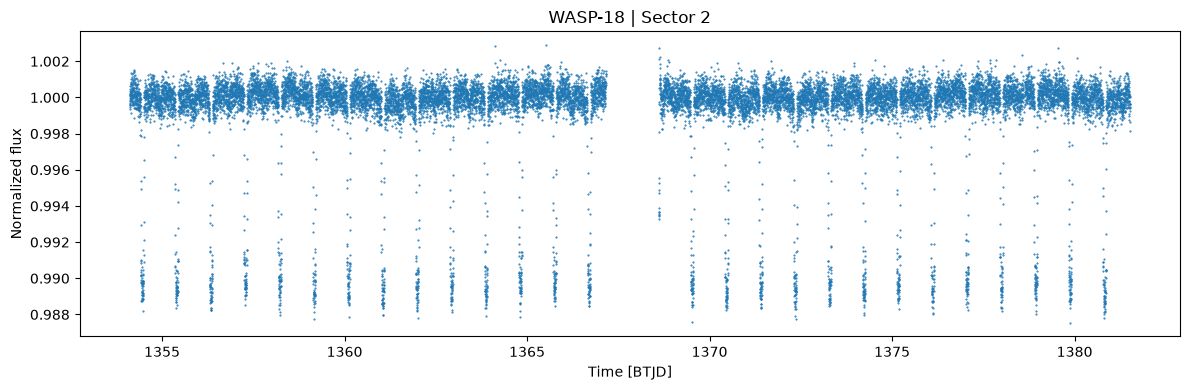

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_input, flux_input, ".", ms=1)
ax.set(xlabel="Time [BTJD]", ylabel="Normalized flux",
       title=f"WASP-18 | Sector {wasp18['sector']}")
fig.tight_layout()
plt.show()

# 2. Preprocessing

I keep the baseline deliberately simple. I also keep a Savitzky-Golay option because the early WASP-18 experiment showed that smoothing can change transit depth.

In [10]:
def robust_sigma(x):
    x = np.asarray(x, float)
    med = np.nanmedian(x)
    return float(1.4826 * np.nanmedian(np.abs(x - med)))

def preprocess(time_values, flux_values, detrend=False, window=101, polyorder=2):
    t = np.asarray(time_values, float)
    f = normalize_flux(flux_values)

    if not detrend:
        return {"time": t, "flux": f}

    w = min(int(window), len(f) - 1)
    if w % 2 == 0:
        w -= 1
    w = max(w, polyorder + 3)
    if w % 2 == 0:
        w += 1

    trend = savgol_filter(f, window_length=w, polyorder=polyorder)
    return {"time": t, "flux": f / trend, "trend": trend}

baseline_preprocessed = preprocess(time_input, flux_input, detrend=False)
savgol_preprocessed = preprocess(time_input, flux_input, detrend=True, window=101)

# 3. Blind BLS search

In [11]:
BLS_CONFIG = {
    "minimum_period_days": 0.5,
    "maximum_period_days": 15.0,
    "durations_hours": [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0],
    "minimum_n_transit": 2,
    "oversample": 10,
}

def build_period_grid(t, f, config=BLS_CONFIG):
    durations = np.asarray(config["durations_hours"]) / 24.0
    bls = BoxLeastSquares(np.asarray(t, float), np.asarray(f, float))
    return np.asarray(
        bls.autoperiod(
            durations,
            minimum_period=config["minimum_period_days"],
            maximum_period=config["maximum_period_days"],
            minimum_n_transit=config["minimum_n_transit"],
        ),
        float,
    )

def blind_bls_search(t, f, period_grid=None, config=BLS_CONFIG):
    t, f = np.asarray(t, float), np.asarray(f, float)
    durations = np.asarray(config["durations_hours"]) / 24.0
    if period_grid is None:
        period_grid = build_period_grid(t, f, config)

    start = time.perf_counter()
    bls = BoxLeastSquares(t, f)
    out = bls.power(period_grid, durations, oversample=config["oversample"])
    power = np.asarray(out.power, float)
    best = int(np.nanargmax(power))

    s = robust_sigma(power)
    sde = np.nan if (not np.isfinite(s) or s <= 0) else (power[best] - np.nanmedian(power)) / s

    return {
        "found_period_days": float(out.period[best]),
        "found_duration_days": float(out.duration[best]),
        "found_epoch_btjd": float(out.transit_time[best]),
        "found_depth": float(out.depth[best]),
        "bls_power": float(power[best]),
        "detection_sde": float(sde),
        "runtime_seconds": time.perf_counter() - start,
    }

candidate = blind_bls_search(
    savgol_preprocessed["time"],
    savgol_preprocessed["flux"],
)
candidate

{'found_period_days': 0.9414989801168709,
 'found_duration_days': 0.08333333333333333,
 'found_epoch_btjd': 1354.4573405950525,
 'found_depth': 0.0013798996694363804,
 'bls_power': 0.0015128258011310972,
 'detection_sde': 232.58495554367917,
 'runtime_seconds': 5.325872499961406}

# 4. Known-planet validation and preprocessing diagnostic

This is where I first saw the important failure mode: the period stayed stable while aggressive smoothing could suppress the depth and make the planet look much smaller.

In [12]:
def folded_depth(t, f, period, epoch, duration):
    phase_time = ((t - epoch + 0.5 * period) % period) - 0.5 * period
    inside = np.abs(phase_time) <= duration / 2
    if inside.sum() < 3:
        return np.nan
    return float(np.nanmedian(f[~inside]) - np.nanmedian(f[inside]))

WASP18_PERIOD = 0.94145223
WASP18_RADIUS_REARTH = 13.89913607
WASP18_STAR_RADIUS_RSUN = 1.319

rows = []
for label, detrend, window in [
    ("no_detrending", False, 101),
    ("savgol_101", True, 101),
    ("savgol_301", True, 301),
    ("savgol_501", True, 501),
]:
    x = preprocess(time_input, flux_input, detrend=detrend, window=window)
    c = blind_bls_search(x["time"], x["flux"])
    depth = folded_depth(
        x["time"], x["flux"],
        c["found_period_days"], c["found_epoch_btjd"], c["found_duration_days"]
    )
    rprs = np.sqrt(depth) if np.isfinite(depth) and depth > 0 else np.nan
    radius = rprs * WASP18_STAR_RADIUS_RSUN * (const.R_sun / const.R_earth).decompose().value

    rows.append({
        "preprocessing": label,
        "period_days": c["found_period_days"],
        "period_error_percent": abs(c["found_period_days"] - WASP18_PERIOD) / WASP18_PERIOD * 100,
        "depth": depth,
        "estimated_radius_rearth": radius,
        "radius_error_percent": abs(radius - WASP18_RADIUS_REARTH) / WASP18_RADIUS_REARTH * 100,
    })

objective4_diagnostics = pd.DataFrame(rows)
display(objective4_diagnostics)

,preprocessing,period_days,period_error_percent,depth,estimated_radius_rearth,radius_error_percent
0,no_detrending,0.941499,0.004966,0.010333,14.624610,5.219558
1,savgol_101,0.941499,0.004966,0.001214,5.012408,63.937270
2,savgol_301,0.941499,0.004966,0.006132,11.265784,18.946157
3,savgol_501,0.941499,0.004966,0.008234,13.055368,6.070651


# 5. Freeze baseline_v1 and validate five known planets

I now stop changing the baseline. Every target gets the same preprocessing and search settings.

In [13]:
VALIDATION_TARGETS = [
    ("VAL-001", "WASP-18", 0.94145223),
    ("VAL-002", "WASP-19", 0.788839),
    ("VAL-003", "WASP-43", 0.813475),
    ("VAL-004", "WASP-121", 1.274925),
    ("VAL-005", "WASP-4", 1.338231),
]

validation_rows = []
for validation_id, target, reference_period in VALIDATION_TARGETS:
    print("Validating:", target)
    host = download_spoc_sector(target)
    c = blind_bls_search(host["time"], host["flux"])
    err = abs(c["found_period_days"] - reference_period) / reference_period

    validation_rows.append({
        "validation_id": validation_id,
        "target": target,
        "sector": host["sector"],
        "found_period_days": c["found_period_days"],
        "reference_period_days": reference_period,
        "period_error_percent": err * 100,
        "period_class": "EXACT" if err <= 0.01 else "MISS",
    })

baseline_v1_validation = pd.DataFrame(validation_rows)
display(baseline_v1_validation)

with open(CONFIG_DIR / "baseline_v1.json", "w") as f:
    json.dump({"version": "baseline_v1", "bls": BLS_CONFIG, "detrend": False}, f, indent=2)

Validating: WASP-18
Validating: WASP-19
Validating: WASP-43
Validating: WASP-121
Validating: WASP-4


,validation_id,target,sector,found_period_days,reference_period_days,period_error_percent,period_class
0,VAL-001,WASP-18,2,0.941499,0.941452,0.004966,EXACT
1,VAL-002,WASP-19,9,0.788770,0.788839,0.008749,EXACT
2,VAL-003,WASP-43,9,0.813505,0.813475,0.003698,EXACT
3,VAL-004,WASP-121,7,1.274923,1.274925,0.000184,EXACT
4,VAL-005,WASP-4,2,1.338249,1.338231,0.001369,EXACT


# 6. Realistic transit injection

I keep the real TESS noise, timestamps and gaps. I only multiply in a physical BATMAN transit.

In [14]:
def a_over_rstar(period_days, mass_msun, radius_rsun):
    P = (period_days * u.day).to(u.s)
    a = (const.G * mass_msun * const.M_sun * P**2 / (4 * np.pi**2)) ** (1/3)
    return float((a / (radius_rsun * const.R_sun)).decompose().value)

def inject_transit(t, f, period, t0, rprs, mass_msun, radius_rsun, impact_b, supersample=7):
    t, f = np.asarray(t, float), np.asarray(f, float)
    a_rs = a_over_rstar(period, mass_msun, radius_rsun)
    inc = float(np.degrees(np.arccos(np.clip(impact_b / a_rs, -1, 1))))
    cadence = float(np.nanmedian(np.diff(t)))

    p = batman.TransitParams()
    p.t0, p.per, p.rp, p.a, p.inc = float(t0), float(period), float(rprs), a_rs, inc
    p.ecc, p.w, p.u, p.limb_dark = 0.0, 90.0, [0.3, 0.2], "quadratic"

    model = batman.TransitModel(
        p, t, exp_time=cadence, supersample_factor=int(supersample)
    ).light_curve(p)

    return f * model, {
        "period_days": float(period),
        "t0": float(t0),
        "rp_over_rstar": float(rprs),
        "impact_parameter": float(impact_b),
        "a_over_rstar": a_rs,
        "inclination_deg": inc,
        "model_depth": float(1 - np.nanmin(model)),
        "cadence_days": cadence,
    }

test_flux, test_truth = inject_transit(
    time_input, flux_input,
    period=2.5,
    t0=time_input.min() + 0.7,
    rprs=0.10,
    mass_msun=1.294,
    radius_rsun=1.319,
    impact_b=0.2,
)

assert len(test_flux) == len(flux_input)
assert np.isfinite(test_flux).all()
print(test_truth)

{'period_days': 2.5, 't0': 1354.8115072617193, 'rp_over_rstar': 0.1, 'impact_parameter': 0.2, 'a_over_rstar': 6.404193218915362, 'inclination_deg': 88.21038825903628, 'model_depth': 0.011457938303827464, 'cadence_days': 0.0013889113920413365}


# 6.5. Frozen development control stars

These five stars are development data. They span very quiet to very variable light curves.

I never promote one of them into the final held-out set after seeing its performance.

In [15]:
FROZEN_DEVELOPMENT_HOSTS = [
    ("CONTROL-001", "18 Sco",     135656809, 91),
    ("CONTROL-002", "HD 102365", 454082369, 10),
    ("CONTROL-003", "HD 76151",   62569281,   8),
    ("CONTROL-004", "HD 30495",  117979951,  5),
    ("CONTROL-005", "HD 20630",  343813545,  4),
]

development_host_data = {}
host_rows = []

for control_id, name, tic_id, sector in FROZEN_DEVELOPMENT_HOSTS:
    print("Loading:", control_id, name)
    host = download_spoc_sector(name, sector=sector)

    tic = Catalogs.query_criteria(catalog="TIC", ID=int(tic_id))
    r = tic[0]

    host.update({
        "control_id": control_id,
        "candidate_name": name,
        "tic_id": tic_id,
        "stellar_mass_msun": float(r["mass"]),
        "stellar_radius_rsun": float(r["rad"]),
        "teff_kelvin": float(r["Teff"]),
        "robust_rms": robust_sigma(host["flux"] - np.nanmedian(host["flux"])),
        "cadence_minutes": np.nanmedian(np.diff(host["time"])) * 1440,
    })

    development_host_data[control_id] = host
    host_rows.append({k: v for k, v in host.items() if k not in {"time", "flux"}})

development_hosts_df = pd.DataFrame(host_rows)
display(development_hosts_df)

host_bls_grids = {
    cid: build_period_grid(h["time"], h["flux"])
    for cid, h in development_host_data.items()
}

Loading: CONTROL-001 18 Sco
Loading: CONTROL-002 HD 102365
Loading: CONTROL-003 HD 76151
Loading: CONTROL-004 HD 30495
Loading: CONTROL-005 HD 20630


,target,sector,flux_product,control_id,candidate_name,tic_id,stellar_mass_msun,stellar_radius_rsun,teff_kelvin,robust_rms,cadence_minutes
0,18 Sco,91,PDCSAP_FLUX,CONTROL-001,18 Sco,135656809,1.04,1.039140,5791.00,0.000194,0.333351
1,HD 102365,10,PDCSAP_FLUX,CONTROL-002,HD 102365,454082369,1.01,0.951380,5672.00,0.000101,1.999990
2,HD 76151,8,PDCSAP_FLUX,CONTROL-003,HD 76151,62569281,1.04,0.983906,5776.65,0.000239,1.999979
3,HD 30495,5,PDCSAP_FLUX,CONTROL-004,HD 30495,117979951,1.05,0.962191,5834.00,0.001261,2.000003
4,HD 20630,4,PDCSAP_FLUX,CONTROL-005,HD 20630,343813545,1.02,0.945495,5711.88,0.009572,2.000026


# 7. RECOVERY_V2

The 300-case pilot rejected the original universal `SDE >= 6` rule because all five no-injection controls crossed it.

So I keep SDE as a diagnostic and define recovery by the period match.

In [16]:
RECOVERY_V2 = {
    "version": "RECOVERY_V2",
    "exact_tolerance": 0.01,
    "alias_tolerance": 0.01,
    "near_tolerance": 0.02,
}

def evaluate_recovery_v2(true_period, found_period):
    if not np.isfinite(true_period) or not np.isfinite(found_period):
        return {"category": "FAILED", "primary_recovered": False, "alias_aware_recovered": False}

    fd = lambda x, y: abs(x - y) / abs(y)
    exact = fd(found_period, true_period)
    half = fd(found_period, true_period / 2)
    double = fd(found_period, true_period * 2)

    if exact <= 0.01:
        category = "EXACT"
    elif half <= 0.01:
        category = "HALF_ALIAS"
    elif double <= 0.01:
        category = "DOUBLE_ALIAS"
    elif exact <= 0.02:
        category = "NEAR_MATCH"
    else:
        category = "MISS"

    return {
        "category": category,
        "primary_recovered": category == "EXACT",
        "alias_aware_recovered": category in {"EXACT", "HALF_ALIAS", "DOUBLE_ALIAS"},
        "exact_fractional_error": exact,
        "half_alias_fractional_error": half,
        "double_alias_fractional_error": double,
    }

assert evaluate_recovery_v2(4, 4)["category"] == "EXACT"
assert evaluate_recovery_v2(4, 2)["category"] == "HALF_ALIAS"
assert evaluate_recovery_v2(4, 8)["category"] == "DOUBLE_ALIAS"
assert evaluate_recovery_v2(4, 4.06)["category"] == "NEAR_MATCH"
assert evaluate_recovery_v2(4, 7)["category"] == "MISS"

with open(CONFIG_DIR / "RECOVERY_V2.json", "w") as f:
    json.dump(RECOVERY_V2, f, indent=2)

print("RECOVERY_V2 frozen.")

RECOVERY_V2 frozen.


# 7.5. Frozen held-out identities

These three stars are my final test set. They are not used in the 1,000-case Week 11 benchmark.

In [17]:
heldout_hosts_df = pd.DataFrame([
    {"heldout_id": "HELDOUT-001", "candidate_name": "HD 190406", "tic_id": 275240386, "sector": 54},
    {"heldout_id": "HELDOUT-002", "candidate_name": "HD 38858",  "tic_id": 176521059, "sector": 6},
    {"heldout_id": "HELDOUT-003", "candidate_name": "HD 10307",  "tic_id": 327507922, "sector": 18},
])

heldout_hosts_df["bls_run"] = False
heldout_hosts_df["injection_run"] = False
heldout_hosts_df["used_for_tuning"] = False

display(heldout_hosts_df)

,heldout_id,candidate_name,tic_id,sector,bls_run,injection_run,used_for_tuning
0,HELDOUT-001,HD 190406,275240386,54,False,False,False
1,HELDOUT-002,HD 38858,176521059,6,False,False,False
2,HELDOUT-003,HD 10307,327507922,18,False,False,False


# 8. Week 11: 1,000 planet completeness benchmark

The grid is frozen before I run it:

- 5 development stars
- 5 radius-ratio levels
- 4 orbital periods
- 10 random phases/geometries

Total: **1,000 injected planets**.

This PC version uses Joblib CPU workers and a checkpoint CSV.

In [18]:
from joblib import Parallel, delayed

W11_PERIODS = [1.0, 3.0, 6.0, 10.0]
W11_RPRS = [0.015, 0.025, 0.040, 0.060, 0.090]
W11_REPEATS = 10

obj8_dir = RESULTS_DIR / "objective_08_week11"
obj8_dir.mkdir(parents=True, exist_ok=True)

design = []
case_no, seed = 0, 800000

for control_id in development_host_data:
    for period in W11_PERIODS:
        for rprs in W11_RPRS:
            for rep in range(1, W11_REPEATS + 1):
                case_no += 1
                seed += 1
                design.append({
                    "case_id": f"W11-{case_no:05d}",
                    "control_id": control_id,
                    "true_period_days": period,
                    "rp_over_rstar": rprs,
                    "repetition": rep,
                    "seed": seed,
                })

week11_design_df = pd.DataFrame(design)
assert len(week11_design_df) == 1000
week11_design_df.to_csv(obj8_dir / "W11_injection_design.csv", index=False)

display(week11_design_df.head())

,case_id,control_id,true_period_days,rp_over_rstar,repetition,seed
0,W11-00001,CONTROL-001,1.0,0.015,1,800001
1,W11-00002,CONTROL-001,1.0,0.015,2,800002
2,W11-00003,CONTROL-001,1.0,0.015,3,800003
3,W11-00004,CONTROL-001,1.0,0.015,4,800004
4,W11-00005,CONTROL-001,1.0,0.015,5,800005


In [19]:
def run_week11_case(case):
    start = time.perf_counter()

    case_id = str(case["case_id"])
    control_id = str(case["control_id"])
    period = float(case["true_period_days"])
    rprs = float(case["rp_over_rstar"])
    seed = int(case["seed"])

    try:
        host = development_host_data[control_id]
        rng = np.random.default_rng(seed)

        b = float(rng.uniform(0, 0.7))
        t0 = float(host["time"].min() + rng.uniform(0, period))

        injected, truth = inject_transit(
            host["time"], host["flux"],
            period=period,
            t0=t0,
            rprs=rprs,
            mass_msun=host["stellar_mass_msun"],
            radius_rsun=host["stellar_radius_rsun"],
            impact_b=b,
        )

        candidate = blind_bls_search(
            host["time"], injected,
            period_grid=host_bls_grids[control_id],
        )

        evaluation = evaluate_recovery_v2(
            period,
            candidate["found_period_days"],
        )

        return {
            "case_id": case_id,
            "control_id": control_id,
            "seed": seed,
            "true_period_days": period,
            "rp_over_rstar": rprs,
            "true_epoch_btjd": t0,
            "impact_parameter": b,
            "model_depth": truth["model_depth"],
            **candidate,
            **evaluation,
            "runtime_seconds_total": time.perf_counter() - start,
            "status": "SUCCESS",
        }

    except Exception as exc:
        return {
            "case_id": case_id,
            "control_id": control_id,
            "seed": seed,
            "true_period_days": period,
            "rp_over_rstar": rprs,
            "category": "FAILED",
            "primary_recovered": False,
            "alias_aware_recovered": False,
            "runtime_seconds_total": time.perf_counter() - start,
            "status": "FAILED",
            "error": repr(exc),
        }

## Run or resume

I save after every small chunk. If this stops at 620/1000, the next run starts from the remaining 380.

In [20]:
checkpoint_path = obj8_dir / "W11_COMPLETENESS_V1_checkpoint.csv"
final_path = obj8_dir / "W11_COMPLETENESS_V1_results.csv"

if checkpoint_path.exists():
    existing = pd.read_csv(checkpoint_path).drop_duplicates("case_id", keep="last")
else:
    existing = pd.DataFrame()

done_ids = set(existing["case_id"].astype(str)) if len(existing) else set()
pending = week11_design_df[~week11_design_df["case_id"].isin(done_ids)].copy()

print("Completed:", len(done_ids))
print("Pending:", len(pending))
print("Workers:", N_JOBS)

if RUN_OBJECTIVE_8_BENCHMARK and len(pending):
    results = existing.copy()
    chunk_size = max(10, N_JOBS * 2)
    session_start = time.perf_counter()

    for start_i in range(0, len(pending), chunk_size):
        chunk = pending.iloc[start_i:start_i + chunk_size].to_dict("records")

        chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
            delayed(run_week11_case)(case) for case in chunk
        )

        results = pd.concat([results, pd.DataFrame(chunk_results)], ignore_index=True)
        results = results.drop_duplicates("case_id", keep="last")

        tmp = checkpoint_path.with_suffix(".tmp.csv")
        results.to_csv(tmp, index=False)
        tmp.replace(checkpoint_path)

        print(
            f"Checkpoint: {len(results)}/1000 "
            f"| session {(time.perf_counter()-session_start)/60:.1f} min"
        )

    week11_results_df = results.sort_values("case_id").reset_index(drop=True)
    week11_results_df.to_csv(final_path, index=False)

else:
    source = final_path if final_path.exists() else checkpoint_path
    if not source.exists():
        raise RuntimeError("No Week 11 result file exists yet.")
    week11_results_df = pd.read_csv(source)

print("Rows available:", len(week11_results_df))

Completed: 0
Pending: 1000
Workers: 14
Checkpoint: 28/1000 | session 1.0 min
Checkpoint: 56/1000 | session 2.0 min
Checkpoint: 84/1000 | session 2.8 min
Checkpoint: 112/1000 | session 3.3 min
Checkpoint: 140/1000 | session 3.9 min
Checkpoint: 168/1000 | session 4.5 min
Checkpoint: 196/1000 | session 5.0 min
Checkpoint: 224/1000 | session 5.2 min
Checkpoint: 252/1000 | session 5.4 min
Checkpoint: 280/1000 | session 5.5 min
Checkpoint: 308/1000 | session 5.7 min
Checkpoint: 336/1000 | session 5.8 min
Checkpoint: 364/1000 | session 5.9 min
Checkpoint: 392/1000 | session 6.0 min
Checkpoint: 420/1000 | session 6.2 min
Checkpoint: 448/1000 | session 6.3 min
Checkpoint: 476/1000 | session 6.4 min
Checkpoint: 504/1000 | session 6.5 min
Checkpoint: 532/1000 | session 6.6 min
Checkpoint: 560/1000 | session 6.7 min
Checkpoint: 588/1000 | session 6.8 min
Checkpoint: 616/1000 | session 6.9 min
Checkpoint: 644/1000 | session 7.1 min
Checkpoint: 672/1000 | session 7.2 min
Checkpoint: 700/1000 | sessi

# Completeness and uncertainty

I only freeze the final Week 11 result when all 1,000 rows are present.

Every main period × size cell contains 50 attempts, and failed runs stay in the denominator.

In [21]:
def wilson_interval(k, n, z=1.959963984540054):
    if n <= 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z*z/n
    center = (p + z*z/(2*n)) / d
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d
    return max(0, center-half), min(1, center+half)

if len(week11_results_df) == 1000:
    rows = []

    for (period, rprs), g in week11_results_df.groupby(
        ["true_period_days", "rp_over_rstar"], sort=True
    ):
        n = len(g)
        k = int(g["primary_recovered"].sum())
        low, high = wilson_interval(k, n)

        rows.append({
            "true_period_days": period,
            "rp_over_rstar": rprs,
            "attempted": n,
            "exact_recovered": k,
            "exact_completeness": k/n,
            "exact_ci95_low": low,
            "exact_ci95_high": high,
        })

    week11_completeness_df = pd.DataFrame(rows)
    assert (week11_completeness_df["attempted"] == 50).all()
    display(week11_completeness_df)
else:
    print("Benchmark is not complete yet. Rerun the previous cell to resume.")

,true_period_days,rp_over_rstar,attempted,exact_recovered,exact_completeness,exact_ci95_low,exact_ci95_high
0,1.0,0.015,50,20,0.40,0.276084,0.538186
1,1.0,0.025,50,30,0.60,0.461814,0.723916
2,1.0,0.040,50,40,0.80,0.669629,0.887562
3,1.0,0.060,50,40,0.80,0.669629,0.887562
4,1.0,0.090,50,40,0.80,0.669629,0.887562
5,3.0,0.015,50,20,0.40,0.276084,0.538186
6,3.0,0.025,50,29,0.58,0.442334,0.706250
7,3.0,0.040,50,33,0.66,0.521538,0.775631
8,3.0,0.060,50,40,0.80,0.669629,0.887562
9,3.0,0.090,50,40,0.80,0.669629,0.887562


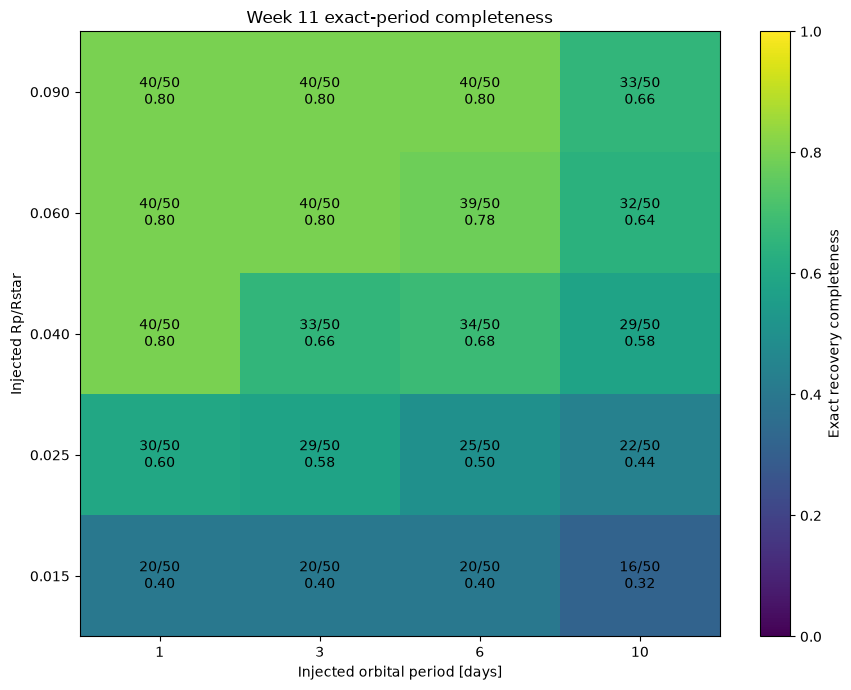

In [22]:
if len(week11_results_df) == 1000:
    pivot = week11_completeness_df.pivot(
        index="rp_over_rstar",
        columns="true_period_days",
        values="exact_completeness",
    ).sort_index()

    counts = week11_completeness_df.pivot(
        index="rp_over_rstar",
        columns="true_period_days",
        values="exact_recovered",
    ).sort_index()

    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(pivot.to_numpy(), origin="lower", aspect="auto", vmin=0, vmax=1)

    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([f"{x:g}" for x in pivot.columns])
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([f"{x:.3f}" for x in pivot.index])

    ax.set_xlabel("Injected orbital period [days]")
    ax.set_ylabel("Injected Rp/Rstar")
    ax.set_title("Week 11 exact-period completeness")

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            ax.text(
                j, i,
                f"{int(counts.iloc[i,j])}/50\n{pivot.iloc[i,j]:.2f}",
                ha="center", va="center"
            )

    fig.colorbar(im, ax=ax, label="Exact recovery completeness")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "W11_exact_completeness_heatmap.png", dpi=220)
    plt.show()

In [23]:
if len(week11_results_df) == 1000:
    host_summary = (
        week11_results_df.groupby("control_id")
        .agg(
            attempted=("case_id", "count"),
            exact_recovered=("primary_recovered", "sum"),
            exact_completeness=("primary_recovered", "mean"),
        )
        .reset_index()
        .merge(
            development_hosts_df[
                ["control_id", "candidate_name", "robust_rms", "cadence_minutes"]
            ],
            on="control_id",
            how="left",
        )
        .sort_values("robust_rms")
    )

    size_summary = (
        week11_results_df.groupby("rp_over_rstar")
        .agg(
            attempted=("case_id", "count"),
            exact_recovered=("primary_recovered", "sum"),
            exact_completeness=("primary_recovered", "mean"),
        )
        .reset_index()
    )

    period_summary = (
        week11_results_df.groupby("true_period_days")
        .agg(
            attempted=("case_id", "count"),
            exact_recovered=("primary_recovered", "sum"),
            exact_completeness=("primary_recovered", "mean"),
        )
        .reset_index()
    )

    boundary_cells = week11_completeness_df[
        week11_completeness_df["exact_completeness"].between(0.20, 0.80)
    ].copy()

    print("By planet size")
    display(size_summary)
    print("By period")
    display(period_summary)
    print("By host")
    display(host_summary)
    print("Detection-boundary cells")
    display(boundary_cells)

By planet size


,rp_over_rstar,attempted,exact_recovered,exact_completeness
0,0.015,200,76,0.380
1,0.025,200,106,0.530
2,0.040,200,136,0.680
3,0.060,200,151,0.755
4,0.090,200,153,0.765


By period


,true_period_days,attempted,exact_recovered,exact_completeness
0,1.0,250,170,0.680
1,3.0,250,162,0.648
2,6.0,250,158,0.632
3,10.0,250,132,0.528


By host


,control_id,attempted,exact_recovered,exact_completeness,candidate_name,robust_rms,cadence_minutes
1,CONTROL-002,200,200,1.000,HD 102365,0.000101,1.999990
0,CONTROL-001,200,183,0.915,18 Sco,0.000194,0.333351
2,CONTROL-003,200,137,0.685,HD 76151,0.000239,1.999979
3,CONTROL-004,200,102,0.510,HD 30495,0.001261,2.000003
4,CONTROL-005,200,0,0.000,HD 20630,0.009572,2.000026


Detection-boundary cells


,true_period_days,rp_over_rstar,attempted,exact_recovered,exact_completeness,exact_ci95_low,exact_ci95_high
0,1.0,0.015,50,20,0.40,0.276084,0.538186
1,1.0,0.025,50,30,0.60,0.461814,0.723916
2,1.0,0.040,50,40,0.80,0.669629,0.887562
3,1.0,0.060,50,40,0.80,0.669629,0.887562
4,1.0,0.090,50,40,0.80,0.669629,0.887562
5,3.0,0.015,50,20,0.40,0.276084,0.538186
6,3.0,0.025,50,29,0.58,0.442334,0.706250
7,3.0,0.040,50,33,0.66,0.521538,0.775631
8,3.0,0.060,50,40,0.80,0.669629,0.887562
9,3.0,0.090,50,40,0.80,0.669629,0.887562


# Freeze Week 11

Once all 1,000 cases are present, I save a manifest and treat this benchmark as fixed. Later preprocessing experiments create new result tables instead of rewriting this one.

In [24]:
if len(week11_results_df) == 1000:
    exact_count = int(week11_results_df["primary_recovered"].sum())
    completeness = exact_count / 1000
    ci = wilson_interval(exact_count, 1000)

    freeze = {
        "version": "W11_COMPLETENESS_V1",
        "frozen_utc": datetime.now(timezone.utc).isoformat(),
        "recovery_protocol": "RECOVERY_V2",
        "expected_cases": 1000,
        "observed_cases": 1000,
        "exact_recovered": exact_count,
        "exact_completeness": completeness,
        "exact_ci95_low": ci[0],
        "exact_ci95_high": ci[1],
        "development_hosts": list(development_host_data.keys()),
        "heldout_hosts_used": False,
        "result_file": str(final_path),
    }

    with open(CONFIG_DIR / "W11_COMPLETENESS_V1_FREEZE_MANIFEST.json", "w") as f:
        json.dump(freeze, f, indent=2)

    print("Exact recovered:", f"{exact_count}/1000")
    print("Exact completeness:", f"{completeness:.4f}")
    print("95% CI:", f"[{ci[0]:.4f}, {ci[1]:.4f}]")
    print("Held-out hosts touched: NO")
    print("W11_COMPLETENESS_V1 frozen.")

Exact recovered: 622/1000
Exact completeness: 0.6220
95% CI: [0.5915, 0.6515]
Held-out hosts touched: NO
W11_COMPLETENESS_V1 frozen.


✅ Frozen Week 11 benchmark found.
✅ 1000 Week 11 cases found.
✅ Held-out firewall intact.
CPU cores: 16
Week 12 workers: 4
Checkpoint chunk size: 8
✅ Week 12 protocol frozen.
✅ Preprocessing function ready.

PAIRING SANITY CHECK


,case_id,epoch_original,epoch_regenerated,b_original,b_regenerated,depth_original,depth_regenerated
0,W11-00001,3775.840794,3775.840794,0.471457,0.471457,0.000250,0.000250
1,W11-00200,3777.458002,3777.458002,0.545806,0.545806,0.008831,0.008831
2,W11-00400,1577.537915,1577.537915,0.019077,0.019077,0.009340,0.009340
3,W11-00600,1524.712740,1524.712740,0.326059,0.326059,0.009180,0.009180
4,W11-00800,1438.027935,1438.027935,0.274447,0.274447,0.009229,0.009229
5,W11-01000,1414.902396,1414.902396,0.455988,0.455988,0.009006,0.009006


✅ Week 11 injections reproduce correctly.
✅ Frozen Week 11 baseline imported.
✅ Week 12 design: 3000 new searches
Already completed: 0
Still pending: 3000
Checkpoint: 8/3000 | elapsed this session: 0.4 min
Checkpoint: 16/3000 | elapsed this session: 0.7 min
Checkpoint: 24/3000 | elapsed this session: 0.9 min
Checkpoint: 32/3000 | elapsed this session: 1.3 min
Checkpoint: 40/3000 | elapsed this session: 1.6 min
Checkpoint: 48/3000 | elapsed this session: 1.9 min
Checkpoint: 56/3000 | elapsed this session: 2.2 min
Checkpoint: 64/3000 | elapsed this session: 2.5 min
Checkpoint: 72/3000 | elapsed this session: 2.8 min
Checkpoint: 80/3000 | elapsed this session: 3.0 min
Checkpoint: 88/3000 | elapsed this session: 3.3 min
Checkpoint: 96/3000 | elapsed this session: 3.6 min
Checkpoint: 104/3000 | elapsed this session: 3.9 min
Checkpoint: 112/3000 | elapsed this session: 4.3 min
Checkpoint: 120/3000 | elapsed this session: 4.7 min
Checkpoint: 128/3000 | elapsed this session: 5.0 min
Checkpoint

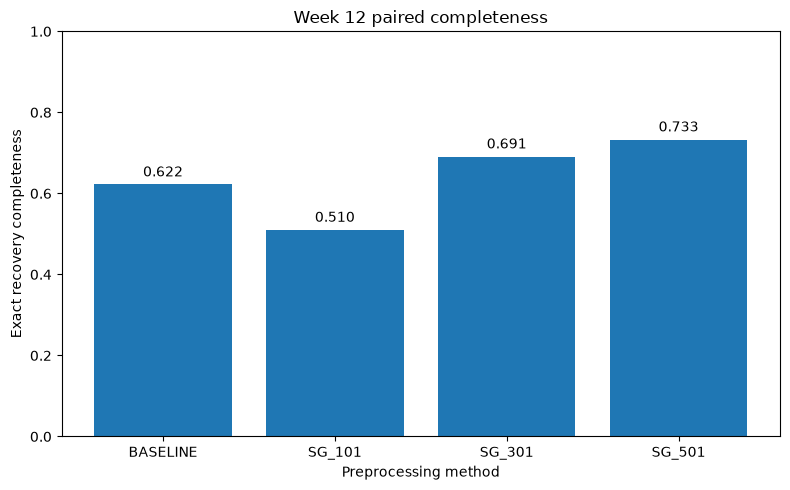

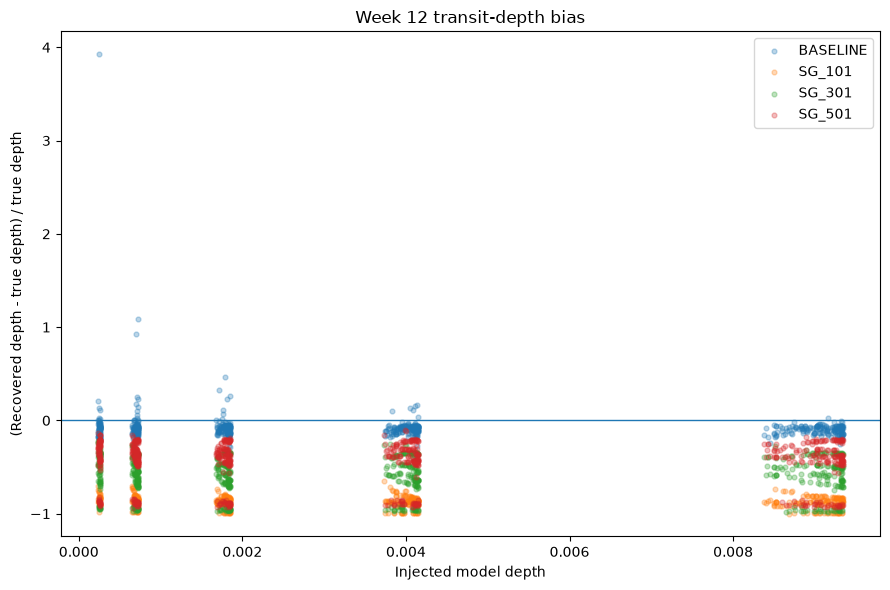

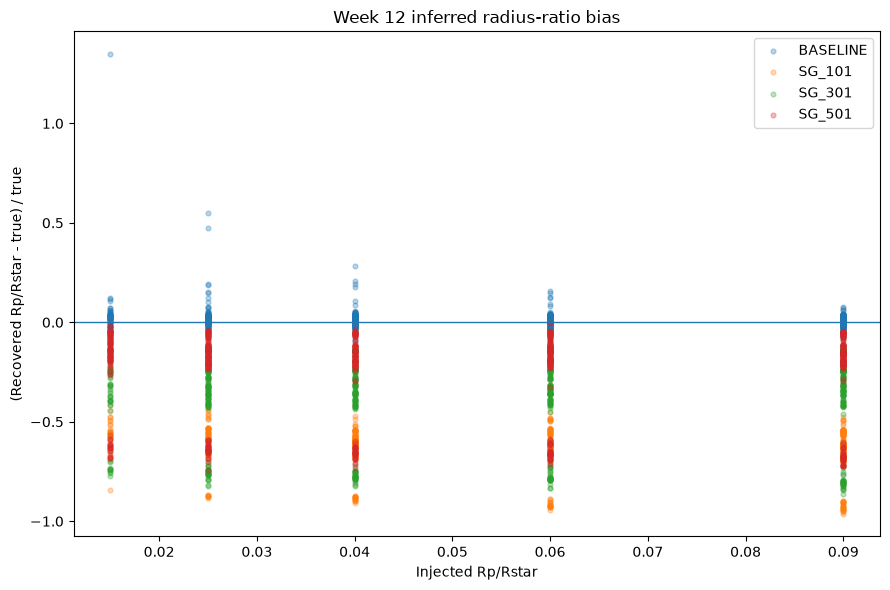


WEEK 12 PREPROCESSING-BIAS RESULTS

METHOD SUMMARY


,method,attempted,exact_recovered,exact_completeness,exact_ci95_low,exact_ci95_high,alias_aware_recovered,alias_aware_completeness,median_depth_fractional_error_exact,median_radius_fractional_error_exact,median_runtime_seconds
0,BASELINE,1000,622,0.622,0.591534,0.651532,634,0.634,-0.084080,0.010708,3.489401
1,SG_101,1000,510,0.510,0.479037,0.540886,516,0.516,-0.865378,-0.609969,2.581775
2,SG_301,1000,691,0.691,0.661675,0.718863,691,0.691,-0.564120,-0.308928,2.400974
3,SG_501,1000,733,0.733,0.704727,0.759490,735,0.735,-0.385444,-0.175715,2.373277



PAIRED RECOVERY SWITCHES


,method,baseline_miss_to_method_recovery,baseline_recovery_to_method_miss,both_recovered,both_missed,net_recovery_change
0,SG_101,44,156,466,334,-112
1,SG_301,128,59,563,250,69
2,SG_501,143,32,590,235,111



PAIRED DEPTH / RADIUS BIAS VS BASELINE


...


COMPLETENESS BY PERIOD


,method,true_period_days,attempted,exact_recovered,exact_completeness
0,BASELINE,1.0,250,170,0.680
1,BASELINE,3.0,250,162,0.648
2,BASELINE,6.0,250,158,0.632
3,BASELINE,10.0,250,132,0.528
4,SG_101,1.0,250,174,0.696
5,SG_101,3.0,250,139,0.556
6,SG_101,6.0,250,116,0.464
7,SG_101,10.0,250,81,0.324
8,SG_301,1.0,250,218,0.872
9,SG_301,3.0,250,177,0.708



COMPLETENESS BY HOST


,method,control_id,attempted,exact_recovered,exact_completeness,candidate_name,robust_rms,cadence_minutes
0,BASELINE,CONTROL-001,200,183,0.915,18 Sco,0.000194,0.333351
1,BASELINE,CONTROL-002,200,200,1.000,HD 102365,0.000101,1.999990
2,BASELINE,CONTROL-003,200,137,0.685,HD 76151,0.000239,1.999979
3,BASELINE,CONTROL-004,200,102,0.510,HD 30495,0.001261,2.000003
4,BASELINE,CONTROL-005,200,0,0.000,HD 20630,0.009572,2.000026
5,SG_101,CONTROL-001,200,63,0.315,18 Sco,0.000194,0.333351
6,SG_101,CONTROL-002,200,182,0.910,HD 102365,0.000101,1.999990
7,SG_101,CONTROL-003,200,128,0.640,HD 76151,0.000239,1.999979
8,SG_101,CONTROL-004,200,124,0.620,HD 30495,0.001261,2.000003
9,SG_101,CONTROL-005,200,13,0.065,HD 20630,0.009572,2.000026



✅ WEEK 12 COMPLETE
✅ 1000 IDENTICAL INJECTIONS
✅ 4 PREPROCESSING METHODS
✅ 4000 PAIRED METHOD/CASE ROWS
✅ COMPLETENESS MEASURED
✅ DEPTH BIAS MEASURED
✅ RADIUS-RATIO BIAS MEASURED
✅ NO-INJECTION CONTROLS COMPARED
✅ HELD-OUT HOSTS REMAIN UNTOUCHED
✅ W12_PREPROCESSING_V1 FROZEN


In [25]:
# ============================================================
# WEEK 12
# PAIRED PREPROCESSING-BIAS BENCHMARK
# CONSOLIDATED + COMPATIBILITY-SAFE VERSION
#
# Uses frozen Week 11:
#   - 1000 identical injections
#   - same hosts
#   - same seeds
#   - same BLS grids
#   - same RECOVERY_V2
#
# Methods:
#   BASELINE = frozen Week 11 results
#   SG_101
#   SG_301
#   SG_501
#
# Only 3000 NEW BLS searches are required.
# Held-out stars remain untouched.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter
from joblib import Parallel, delayed


# ============================================================
# 1. CHECK THAT WEEK 11 EXISTS
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CONFIG_DIR",
    "development_host_data",
    "development_hosts_df",
    "heldout_hosts_df",
    "week11_design_df",
    "week11_results_df",
    "host_bls_grids",
    "inject_transit",
    "blind_bls_search",
    "evaluate_recovery_v2",
    "BLS_CONFIG",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Week 11 state is missing.\n"
        f"Missing: {missing}\n\n"
        "Run the notebook through Week 11 first."
    )


assert len(week11_design_df) == 1000
assert len(week11_results_df) == 1000

assert (
    heldout_hosts_df["bls_run"] == False
).all()

assert (
    heldout_hosts_df["injection_run"] == False
).all()

assert (
    heldout_hosts_df["used_for_tuning"] == False
).all()


print("✅ Frozen Week 11 benchmark found.")
print("✅ 1000 Week 11 cases found.")
print("✅ Held-out firewall intact.")


# ============================================================
# 2. CPU SETTINGS
# ============================================================

CPU_COUNT_W12 = os.cpu_count() or 2

# Keep this moderate because CONTROL-001 is large.
N_JOBS_W12 = max(
    1,
    min(CPU_COUNT_W12 - 1, 4)
)

CHUNK_SIZE_W12 = max(
    8,
    N_JOBS_W12 * 2
)

print("CPU cores:", CPU_COUNT_W12)
print("Week 12 workers:", N_JOBS_W12)
print("Checkpoint chunk size:", CHUNK_SIZE_W12)


# ============================================================
# 3. OUTPUT DIRECTORIES
# ============================================================

W12_RESULTS_DIR = (
    RESULTS_DIR
    / "week12_preprocessing_bias"
)

W12_FIGURES_DIR = (
    FIGURES_DIR
    / "week12_preprocessing_bias"
)

W12_CONFIG_DIR = (
    CONFIG_DIR
    / "week12_preprocessing_bias"
)

for folder in [
    W12_RESULTS_DIR,
    W12_FIGURES_DIR,
    W12_CONFIG_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. FREEZE WEEK 12 PREPROCESSING METHODS
# ============================================================

PREPROCESSING_METHODS = {

    "BASELINE": {
        "kind": "none",
        "window": None,
        "polyorder": None,
    },

    "SG_101": {
        "kind": "savgol",
        "window": 101,
        "polyorder": 2,
    },

    "SG_301": {
        "kind": "savgol",
        "window": 301,
        "polyorder": 2,
    },

    "SG_501": {
        "kind": "savgol",
        "window": 501,
        "polyorder": 2,
    },
}


WEEK12_PROTOCOL = {

    "version":
        "W12_PREPROCESSING_V1",

    "source_benchmark":
        "W11_COMPLETENESS_V1",

    "unique_injections":
        1000,

    "methods":
        PREPROCESSING_METHODS,

    "paired_design":
        True,

    "same_injections_across_methods":
        True,

    "recovery_protocol":
        "RECOVERY_V2",

    "primary_recovery":
        "EXACT period within 1%",

    "heldout_hosts_used":
        False,

    "depth_metric":
        "BLS recovered box depth",

    "radius_ratio_estimator":
        "sqrt(BLS depth)",

    "control_analysis":
        (
            "Continuous BLS candidate statistics only; "
            "no post-hoc binary SDE threshold."
        ),
}


with open(
    W12_CONFIG_DIR
    / "W12_PREPROCESSING_V1.json",
    "w",
) as f:

    json.dump(
        WEEK12_PROTOCOL,
        f,
        indent=2,
    )


print("✅ Week 12 protocol frozen.")


# ============================================================
# 5. PREPROCESSING FUNCTION
# ============================================================

def apply_week12_preprocessing(
    time_values,
    flux_values,
    method_name,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    if method_name == "BASELINE":

        good = (
            np.isfinite(t)
            &
            np.isfinite(f)
        )

        return (
            t[good],
            f[good],
        )


    if method_name not in PREPROCESSING_METHODS:

        raise ValueError(
            f"Unknown preprocessing method: {method_name}"
        )


    settings = PREPROCESSING_METHODS[
        method_name
    ]


    window = int(
        settings["window"]
    )

    polyorder = int(
        settings["polyorder"]
    )


    # ---------------------------------------------
    # Make sure the window is legal
    # ---------------------------------------------

    window = min(
        window,
        len(f) - 1,
    )


    if window % 2 == 0:
        window -= 1


    minimum_window = (
        polyorder + 3
    )


    if minimum_window % 2 == 0:
        minimum_window += 1


    window = max(
        window,
        minimum_window,
    )


    if window >= len(f):

        window = len(f) - 1

        if window % 2 == 0:
            window -= 1


    if window <= polyorder:

        raise ValueError(
            "Savitzky-Golay window is too small."
        )


    trend = savgol_filter(
        f,
        window_length=window,
        polyorder=polyorder,
    )


    good_trend = (
        np.isfinite(trend)
        &
        (trend != 0)
    )


    detrended = np.full(
        len(f),
        np.nan,
        dtype=float,
    )


    detrended[good_trend] = (
        f[good_trend]
        /
        trend[good_trend]
    )


    good = (
        np.isfinite(t)
        &
        np.isfinite(detrended)
    )


    return (
        t[good],
        detrended[good],
    )


print("✅ Preprocessing function ready.")


# ============================================================
# 6. DEPTH -> RADIUS RATIO
# ============================================================

def depth_to_rprs(depth):

    try:
        depth = float(depth)

    except Exception:
        return np.nan


    if (
        not np.isfinite(depth)
        or depth <= 0
    ):
        return np.nan


    return float(
        np.sqrt(depth)
    )


# ============================================================
# 7. COMPATIBILITY-SAFE INJECTION CALL
#
# IMPORTANT FIX:
#
# We deliberately call inject_transit() POSITIONALLY.
#
# This works whether your notebook defines it as:
#
#   period_days / rp_over_rstar / ...
#
# or:
#
#   period / rprs / ...
#
# because the argument ORDER is the same.
# ============================================================

def call_inject_transit_compat(
    host,
    period_days,
    true_epoch,
    rp_rs,
    impact_parameter,
):

    return inject_transit(

        host["time"],
        host["flux"],

        float(period_days),
        float(true_epoch),
        float(rp_rs),

        float(
            host[
                "stellar_mass_msun"
            ]
        ),

        float(
            host[
                "stellar_radius_rsun"
            ]
        ),

        float(
            impact_parameter
        ),

        7,
    )


# ============================================================
# 8. REGENERATE EXACT WEEK 11 INJECTION
# ============================================================

def regenerate_week11_injection(case):

    control_id = str(
        case["control_id"]
    )

    period_days = float(
        case["true_period_days"]
    )

    rp_rs = float(
        case["rp_over_rstar"]
    )

    seed = int(
        case["seed"]
    )


    host = development_host_data[
        control_id
    ]


    rng = np.random.default_rng(
        seed
    )


    # Same RNG order as frozen Week 11.
    impact_parameter = float(
        rng.uniform(
            0.0,
            0.7,
        )
    )


    true_epoch = float(
        host["time"].min()
        +
        rng.uniform(
            0.0,
            period_days,
        )
    )


    injected_flux, truth = (
        call_inject_transit_compat(

            host=host,

            period_days=period_days,

            true_epoch=true_epoch,

            rp_rs=rp_rs,

            impact_parameter=impact_parameter,
        )
    )


    return {

        "time":
            np.asarray(
                host["time"],
                dtype=float,
            ),

        "flux":
            np.asarray(
                injected_flux,
                dtype=float,
            ),

        "truth":
            {
                **truth,

                "case_id":
                    str(
                        case["case_id"]
                    ),

                "control_id":
                    control_id,

                "seed":
                    seed,

                # Add canonical Week 12 names even if
                # the original injection function used
                # different dictionary keys.
                "true_period_days":
                    period_days,

                "true_rp_over_rstar":
                    rp_rs,

                "true_epoch_btjd":
                    true_epoch,

                "impact_parameter":
                    impact_parameter,
            },
    }


# ============================================================
# 9. VERIFY THAT WE REGENERATE WEEK 11 EXACTLY
# ============================================================

verification_rows = []


verification_indices = [
    0,
    199,
    399,
    599,
    799,
    999,
]


for check_index in verification_indices:

    case = (
        week11_design_df
        .iloc[
            check_index
        ]
        .to_dict()
    )


    regenerated = (
        regenerate_week11_injection(
            case
        )
    )


    original_match = (
        week11_results_df[
            week11_results_df[
                "case_id"
            ].astype(str)
            ==
            str(
                case["case_id"]
            )
        ]
    )


    if len(original_match) != 1:

        raise RuntimeError(
            f"Could not uniquely find "
            f"{case['case_id']} "
            f"in Week 11 results."
        )


    original = (
        original_match
        .iloc[0]
    )


    truth = regenerated[
        "truth"
    ]


    regenerated_epoch = (
        truth.get(
            "t0",
            truth.get(
                "true_epoch_btjd",
                np.nan,
            ),
        )
    )


    regenerated_b = (
        truth.get(
            "impact_parameter",
            truth.get(
                "impact_b",
                np.nan,
            ),
        )
    )


    regenerated_depth = (
        truth.get(
            "model_depth",
            np.nan,
        )
    )


    verification_rows.append({

        "case_id":
            case["case_id"],

        "epoch_original":
            original.get(
                "true_epoch_btjd",
                np.nan,
            ),

        "epoch_regenerated":
            regenerated_epoch,

        "b_original":
            original.get(
                "impact_parameter",
                np.nan,
            ),

        "b_regenerated":
            regenerated_b,

        "depth_original":
            original.get(
                "model_depth",
                np.nan,
            ),

        "depth_regenerated":
            regenerated_depth,
    })


verification_df = pd.DataFrame(
    verification_rows
)


print("\nPAIRING SANITY CHECK")

display(
    verification_df
)


# ---------------------------------------------
# Compare values where frozen table contains them
# ---------------------------------------------

for _, row in verification_df.iterrows():

    if (
        np.isfinite(
            row["epoch_original"]
        )
        and
        np.isfinite(
            row["epoch_regenerated"]
        )
    ):

        assert np.isclose(
            row["epoch_original"],
            row["epoch_regenerated"],
            rtol=0,
            atol=1e-8,
        )


    if (
        np.isfinite(
            row["b_original"]
        )
        and
        np.isfinite(
            row["b_regenerated"]
        )
    ):

        assert np.isclose(
            row["b_original"],
            row["b_regenerated"],
            rtol=0,
            atol=1e-8,
        )


    if (
        np.isfinite(
            row["depth_original"]
        )
        and
        np.isfinite(
            row["depth_regenerated"]
        )
    ):

        assert np.isclose(
            row["depth_original"],
            row["depth_regenerated"],
            rtol=1e-8,
            atol=1e-10,
        )


print("✅ Week 11 injections reproduce correctly.")


# ============================================================
# 10. IMPORT FROZEN WEEK 11 AS BASELINE
#
# No need to waste another 1000 BLS runs.
# ============================================================

baseline_rows = []


for _, row in week11_results_df.iterrows():

    found_depth = row.get(
        "found_depth",
        np.nan,
    )


    true_depth = row.get(
        "model_depth",
        np.nan,
    )


    true_rprs = float(
        row[
            "rp_over_rstar"
        ]
    )


    recovered_rprs = (
        depth_to_rprs(
            found_depth
        )
    )


    if (
        np.isfinite(found_depth)
        and
        np.isfinite(true_depth)
        and
        true_depth > 0
    ):

        depth_fractional_error = (

            (
                found_depth
                -
                true_depth
            )

            /

            true_depth
        )

    else:

        depth_fractional_error = np.nan


    if (
        np.isfinite(recovered_rprs)
        and
        true_rprs > 0
    ):

        radius_fractional_error = (

            (
                recovered_rprs
                -
                true_rprs
            )

            /

            true_rprs
        )

    else:

        radius_fractional_error = np.nan


    baseline_rows.append({

        "case_id":
            str(
                row["case_id"]
            ),

        "method":
            "BASELINE",

        "control_id":
            str(
                row["control_id"]
            ),

        "seed":
            int(
                row["seed"]
            ),

        "true_period_days":
            float(
                row[
                    "true_period_days"
                ]
            ),

        "true_rp_over_rstar":
            true_rprs,

        "true_model_depth":
            true_depth,

        "true_epoch_btjd":
            row.get(
                "true_epoch_btjd",
                np.nan,
            ),

        "impact_parameter":
            row.get(
                "impact_parameter",
                np.nan,
            ),

        "found_period_days":
            row.get(
                "found_period_days",
                np.nan,
            ),

        "found_duration_days":
            row.get(
                "found_duration_days",
                np.nan,
            ),

        "found_duration_hours":
            row.get(
                "found_duration_hours",
                (
                    row.get(
                        "found_duration_days",
                        np.nan,
                    )
                    * 24
                    if np.isfinite(
                        row.get(
                            "found_duration_days",
                            np.nan,
                        )
                    )
                    else np.nan
                ),
            ),

        "found_depth":
            found_depth,

        "recovered_rp_over_rstar":
            recovered_rprs,

        "depth_fractional_error":
            depth_fractional_error,

        "radius_fractional_error":
            radius_fractional_error,

        "bls_power":
            row.get(
                "bls_power",
                np.nan,
            ),

        "detection_sde":
            row.get(
                "detection_sde",
                np.nan,
            ),

        "recovery_category":
            row.get(
                "recovery_category",
                row.get(
                    "category",
                    np.nan,
                ),
            ),

        "primary_recovered":
            bool(
                row[
                    "primary_recovered"
                ]
            ),

        "alias_aware_recovered":
            bool(
                row[
                    "alias_aware_recovered"
                ]
            ),

        "runtime_seconds":
            row.get(
                "runtime_seconds_total",
                row.get(
                    "runtime_seconds",
                    np.nan,
                ),
            ),

        "status":
            row.get(
                "status",
                "SUCCESS",
            ),
    })


baseline_week12_df = pd.DataFrame(
    baseline_rows
)


assert len(
    baseline_week12_df
) == 1000


print(
    "✅ Frozen Week 11 baseline imported."
)


# ============================================================
# 11. SINGLE WEEK 12 WORKER
# ============================================================

def run_week12_case(
    case,
    method_name,
):

    start = time.perf_counter()


    case_id = str(
        case["case_id"]
    )

    control_id = str(
        case["control_id"]
    )

    true_period = float(
        case["true_period_days"]
    )

    true_rprs = float(
        case["rp_over_rstar"]
    )

    seed = int(
        case["seed"]
    )


    try:

        # ---------------------------------------------
        # Identical Week 11 injection
        # ---------------------------------------------

        injected = (
            regenerate_week11_injection(
                case
            )
        )


        truth = injected[
            "truth"
        ]


        true_epoch = truth.get(

            "t0",

            truth.get(
                "true_epoch_btjd",
                np.nan,
            ),
        )


        impact_parameter = truth.get(

            "impact_parameter",

            truth.get(
                "impact_b",
                np.nan,
            ),
        )


        true_depth = truth.get(
            "model_depth",
            np.nan,
        )


        # ---------------------------------------------
        # Preprocessing
        # ---------------------------------------------

        processed_time, processed_flux = (
            apply_week12_preprocessing(

                injected[
                    "time"
                ],

                injected[
                    "flux"
                ],

                method_name,
            )
        )


        # ---------------------------------------------
        # Same frozen blind BLS
        # ---------------------------------------------

        candidate = blind_bls_search(

            processed_time,

            processed_flux,

            period_grid=host_bls_grids[
                control_id
            ],

            config=BLS_CONFIG,
        )


        # ---------------------------------------------
        # Evaluate only after BLS result exists
        # ---------------------------------------------

        evaluation = evaluate_recovery_v2(

            true_period=true_period,

            found_period=candidate[
                "found_period_days"
            ],
        )


        found_depth = candidate.get(
            "found_depth",
            np.nan,
        )


        recovered_rprs = (
            depth_to_rprs(
                found_depth
            )
        )


        if (
            np.isfinite(found_depth)
            and
            np.isfinite(true_depth)
            and
            true_depth > 0
        ):

            depth_fractional_error = (

                (
                    found_depth
                    -
                    true_depth
                )

                /

                true_depth
            )

        else:

            depth_fractional_error = np.nan


        if (
            np.isfinite(recovered_rprs)
            and
            true_rprs > 0
        ):

            radius_fractional_error = (

                (
                    recovered_rprs
                    -
                    true_rprs
                )

                /

                true_rprs
            )

        else:

            radius_fractional_error = np.nan


        found_duration_days = candidate.get(
            "found_duration_days",
            np.nan,
        )


        return {

            "case_id":
                case_id,

            "method":
                method_name,

            "control_id":
                control_id,

            "seed":
                seed,

            "true_period_days":
                true_period,

            "true_rp_over_rstar":
                true_rprs,

            "true_model_depth":
                true_depth,

            "true_epoch_btjd":
                true_epoch,

            "impact_parameter":
                impact_parameter,

            "found_period_days":
                candidate.get(
                    "found_period_days",
                    np.nan,
                ),

            "found_duration_days":
                found_duration_days,

            "found_duration_hours":
                (
                    found_duration_days * 24
                    if np.isfinite(
                        found_duration_days
                    )
                    else candidate.get(
                        "found_duration_hours",
                        np.nan,
                    )
                ),

            "found_depth":
                found_depth,

            "recovered_rp_over_rstar":
                recovered_rprs,

            "depth_fractional_error":
                depth_fractional_error,

            "radius_fractional_error":
                radius_fractional_error,

            "bls_power":
                candidate.get(
                    "bls_power",
                    np.nan,
                ),

            "detection_sde":
                candidate.get(
                    "detection_sde",
                    np.nan,
                ),

            "recovery_category":
                evaluation[
                    "category"
                ],

            "primary_recovered":
                evaluation[
                    "primary_recovered"
                ],

            "alias_aware_recovered":
                evaluation[
                    "alias_aware_recovered"
                ],

            "runtime_seconds":
                (
                    time.perf_counter()
                    -
                    start
                ),

            "status":
                "SUCCESS",
        }


    except Exception as error:

        return {

            "case_id":
                case_id,

            "method":
                method_name,

            "control_id":
                control_id,

            "seed":
                seed,

            "true_period_days":
                true_period,

            "true_rp_over_rstar":
                true_rprs,

            "recovery_category":
                "FAILED",

            "primary_recovered":
                False,

            "alias_aware_recovered":
                False,

            "runtime_seconds":
                (
                    time.perf_counter()
                    -
                    start
                ),

            "status":
                "FAILED",

            "error":
                repr(
                    error
                ),
        }


# ============================================================
# 12. CREATE THE 3000 NEW SEARCHES
# ============================================================

NEW_METHODS = [
    "SG_101",
    "SG_301",
    "SG_501",
]


week12_design_rows = []


for _, case in week11_design_df.iterrows():

    for method_name in NEW_METHODS:

        week12_design_rows.append({

            "experiment_id":
                (
                    f"{case['case_id']}"
                    f"__{method_name}"
                ),

            "case_id":
                str(
                    case["case_id"]
                ),

            "method":
                method_name,

            "control_id":
                str(
                    case["control_id"]
                ),

            "true_period_days":
                float(
                    case[
                        "true_period_days"
                    ]
                ),

            "rp_over_rstar":
                float(
                    case[
                        "rp_over_rstar"
                    ]
                ),

            "seed":
                int(
                    case["seed"]
                ),
        })


week12_design_df = pd.DataFrame(
    week12_design_rows
)


assert len(
    week12_design_df
) == 3000


assert (
    week12_design_df[
        "experiment_id"
    ].nunique()
    == 3000
)


week12_design_df.to_csv(

    W12_RESULTS_DIR
    / "W12_search_design.csv",

    index=False,
)


print(
    "✅ Week 12 design:",
    len(
        week12_design_df
    ),
    "new searches"
)


# ============================================================
# 13. CHECKPOINT / RESUME
# ============================================================

W12_CHECKPOINT_PATH = (

    W12_RESULTS_DIR
    /
    "W12_detrending_checkpoint.csv"
)


W12_NEW_RESULTS_PATH = (

    W12_RESULTS_DIR
    /
    "W12_new_detrending_results.csv"
)


if W12_CHECKPOINT_PATH.exists():

    existing_w12 = (

        pd.read_csv(
            W12_CHECKPOINT_PATH
        )

        .drop_duplicates(
            [
                "case_id",
                "method",
            ],

            keep="last",
        )
    )

else:

    existing_w12 = pd.DataFrame()


if len(
    existing_w12
):

    completed_pairs = set(

        zip(

            existing_w12[
                "case_id"
            ].astype(str),

            existing_w12[
                "method"
            ].astype(str),
        )
    )

else:

    completed_pairs = set()


pending_rows = []


for _, row in week12_design_df.iterrows():

    key = (

        str(
            row["case_id"]
        ),

        str(
            row["method"]
        ),
    )


    if key not in completed_pairs:

        pending_rows.append(
            row.to_dict()
        )


pending_w12_df = pd.DataFrame(
    pending_rows
)


print(
    "Already completed:",
    len(
        existing_w12
    ),
)


print(
    "Still pending:",
    len(
        pending_w12_df
    ),
)


# ============================================================
# 14. RUN / RESUME THE 3000 NEW SEARCHES
# ============================================================

current_w12 = (
    existing_w12.copy()
)


session_start = time.perf_counter()


for start_index in range(
    0,
    len(
        pending_w12_df
    ),
    CHUNK_SIZE_W12,
):

    chunk = pending_w12_df.iloc[

        start_index:
        start_index
        +
        CHUNK_SIZE_W12
    ]


    jobs = []


    for record in chunk.to_dict(
        "records"
    ):

        case = {

            "case_id":
                record[
                    "case_id"
                ],

            "control_id":
                record[
                    "control_id"
                ],

            "true_period_days":
                record[
                    "true_period_days"
                ],

            "rp_over_rstar":
                record[
                    "rp_over_rstar"
                ],

            "seed":
                record[
                    "seed"
                ],
        }


        jobs.append(
            (
                case,
                record[
                    "method"
                ],
            )
        )


    chunk_results = Parallel(

        n_jobs=N_JOBS_W12,

        backend="loky",

        verbose=0,

    )(

        delayed(
            run_week12_case
        )(
            case,
            method_name,
        )

        for (
            case,
            method_name
        )
        in jobs
    )


    current_w12 = pd.concat(

        [
            current_w12,
            pd.DataFrame(
                chunk_results
            ),
        ],

        ignore_index=True,
    )


    current_w12 = (

        current_w12

        .drop_duplicates(

            [
                "case_id",
                "method",
            ],

            keep="last",
        )
    )


    # ---------------------------------------------
    # Atomic-ish checkpoint
    # ---------------------------------------------

    temp_path = (
        W12_CHECKPOINT_PATH
        .with_suffix(
            ".tmp.csv"
        )
    )


    current_w12.to_csv(
        temp_path,
        index=False,
    )


    temp_path.replace(
        W12_CHECKPOINT_PATH
    )


    elapsed_minutes = (

        time.perf_counter()
        -
        session_start

    ) / 60


    print(

        f"Checkpoint: "
        f"{len(current_w12)}/3000 "
        f"| elapsed this session: "
        f"{elapsed_minutes:.1f} min"
    )


current_w12 = (

    current_w12

    .sort_values(
        [
            "case_id",
            "method",
        ]
    )

    .reset_index(
        drop=True
    )
)


current_w12.to_csv(

    W12_NEW_RESULTS_PATH,

    index=False,
)


assert len(
    current_w12
) == 3000


failed_searches = int(

    (
        current_w12[
            "status"
        ]
        !=
        "SUCCESS"
    ).sum()
)


print()
print("New searches:", len(current_w12))
print("Failures:", failed_searches)
print("✅ New preprocessing searches finished.")


# ============================================================
# 15. COMBINE BASELINE + THREE NEW METHODS
# ============================================================

week12_results_df = pd.concat(

    [
        baseline_week12_df,
        current_w12,
    ],

    ignore_index=True,
)


week12_results_df = (

    week12_results_df

    .sort_values(
        [
            "case_id",
            "method",
        ]
    )

    .reset_index(
        drop=True
    )
)


assert len(
    week12_results_df
) == 4000


pair_counts = (

    week12_results_df

    .groupby(
        "case_id"
    )[
        "method"
    ]

    .nunique()
)


assert (
    pair_counts == 4
).all()


W12_MASTER_RESULTS_PATH = (

    W12_RESULTS_DIR
    /
    "DET_detrending_results.csv"
)


week12_results_df.to_csv(

    W12_MASTER_RESULTS_PATH,

    index=False,
)


print(
    "✅ Perfect pairing confirmed:"
)

print(
    "1000 cases × 4 methods =",
    len(
        week12_results_df
    )
)


# ============================================================
# 16. NO-INJECTION CONTROL COMPARISON
# ============================================================

control_rows = []


for (
    control_id,
    host
) in development_host_data.items():

    for method_name in (
        PREPROCESSING_METHODS.keys()
    ):

        try:

            control_time, control_flux = (
                apply_week12_preprocessing(

                    host[
                        "time"
                    ],

                    host[
                        "flux"
                    ],

                    method_name,
                )
            )


            start = (
                time.perf_counter()
            )


            candidate = blind_bls_search(

                control_time,

                control_flux,

                period_grid=host_bls_grids[
                    control_id
                ],

                config=BLS_CONFIG,
            )


            control_rows.append({

                "control_id":
                    control_id,

                "candidate_name":
                    host.get(
                        "candidate_name",
                        control_id,
                    ),

                "method":
                    method_name,

                "found_period_days":
                    candidate.get(
                        "found_period_days",
                        np.nan,
                    ),

                "found_depth":
                    candidate.get(
                        "found_depth",
                        np.nan,
                    ),

                "detection_sde":
                    candidate.get(
                        "detection_sde",
                        np.nan,
                    ),

                "bls_power":
                    candidate.get(
                        "bls_power",
                        np.nan,
                    ),

                "runtime_seconds":
                    (
                        time.perf_counter()
                        -
                        start
                    ),

                "status":
                    "SUCCESS",
            })


        except Exception as error:

            control_rows.append({

                "control_id":
                    control_id,

                "candidate_name":
                    host.get(
                        "candidate_name",
                        control_id,
                    ),

                "method":
                    method_name,

                "status":
                    "FAILED",

                "error":
                    repr(
                        error
                    ),
            })


week12_controls_df = pd.DataFrame(
    control_rows
)


W12_CONTROL_PATH = (

    W12_RESULTS_DIR
    /
    "W12_no_injection_controls.csv"
)


week12_controls_df.to_csv(
    W12_CONTROL_PATH,
    index=False,
)


print(
    "\n✅ No-injection controls complete."
)


# ============================================================
# 17. WILSON INTERVAL FALLBACK
# ============================================================

if "wilson_interval" not in globals():

    def wilson_interval(
        successes,
        attempts,
        z=1.959963984540054,
    ):

        if attempts <= 0:
            return (
                np.nan,
                np.nan,
            )


        p = successes / attempts


        denominator = (
            1
            +
            z**2
            /
            attempts
        )


        center = (

            p

            +

            z**2
            /
            (
                2
                *
                attempts
            )

        ) / denominator


        half_width = (

            z

            *

            np.sqrt(

                p
                *
                (
                    1
                    -
                    p
                )
                /
                attempts

                +

                z**2
                /
                (
                    4
                    *
                    attempts**2
                )
            )

            /

            denominator
        )


        return (

            max(
                0,
                center
                -
                half_width,
            ),

            min(
                1,
                center
                +
                half_width,
            ),
        )


# ============================================================
# 18. METHOD SUMMARY
# ============================================================

method_summary_rows = []


for (
    method_name,
    group
) in week12_results_df.groupby(
    "method"
):

    attempted = len(
        group
    )


    exact_count = int(
        group[
            "primary_recovered"
        ].sum()
    )


    alias_count = int(
        group[
            "alias_aware_recovered"
        ].sum()
    )


    exact_low, exact_high = (
        wilson_interval(
            exact_count,
            attempted,
        )
    )


    exact_group = group[
        group[
            "primary_recovered"
        ]
        ==
        True
    ]


    method_summary_rows.append({

        "method":
            method_name,

        "attempted":
            attempted,

        "exact_recovered":
            exact_count,

        "exact_completeness":
            exact_count
            /
            attempted,

        "exact_ci95_low":
            exact_low,

        "exact_ci95_high":
            exact_high,

        "alias_aware_recovered":
            alias_count,

        "alias_aware_completeness":
            alias_count
            /
            attempted,

        "median_depth_fractional_error_exact":
            exact_group[
                "depth_fractional_error"
            ].median(),

        "median_radius_fractional_error_exact":
            exact_group[
                "radius_fractional_error"
            ].median(),

        "median_runtime_seconds":
            group[
                "runtime_seconds"
            ].median(),
    })


method_summary_df = pd.DataFrame(
    method_summary_rows
)


METHOD_ORDER = [
    "BASELINE",
    "SG_101",
    "SG_301",
    "SG_501",
]


method_summary_df[
    "_order"
] = (
    method_summary_df[
        "method"
    ].map(
        {
            method: index
            for index, method
            in enumerate(
                METHOD_ORDER
            )
        }
    )
)


method_summary_df = (

    method_summary_df

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

    .reset_index(
        drop=True
    )
)


method_summary_df.to_csv(

    W12_RESULTS_DIR
    / "W12_method_summary.csv",

    index=False,
)


# ============================================================
# 19. PAIRED RECOVERY SWITCHES
# ============================================================

baseline_status = (

    week12_results_df[

        week12_results_df[
            "method"
        ]
        ==
        "BASELINE"

    ][
        [
            "case_id",
            "primary_recovered",
        ]
    ]

    .rename(
        columns={
            "primary_recovered":
                "baseline_recovered"
        }
    )
)


switch_rows = []


for method_name in [
    "SG_101",
    "SG_301",
    "SG_501",
]:

    method_status = (

        week12_results_df[

            week12_results_df[
                "method"
            ]
            ==
            method_name

        ][
            [
                "case_id",
                "primary_recovered",
            ]
        ]

        .rename(
            columns={
                "primary_recovered":
                    "method_recovered"
            }
        )
    )


    paired = (
        baseline_status
        .merge(
            method_status,
            on="case_id",
            how="inner",
        )
    )


    gained = int(
        (
            (~paired[
                "baseline_recovered"
            ])
            &
            (
                paired[
                    "method_recovered"
                ]
            )
        ).sum()
    )


    lost = int(
        (
            (
                paired[
                    "baseline_recovered"
                ]
            )
            &
            (~paired[
                "method_recovered"
            ])
        ).sum()
    )


    both_recovered = int(
        (
            (
                paired[
                    "baseline_recovered"
                ]
            )
            &
            (
                paired[
                    "method_recovered"
                ]
            )
        ).sum()
    )


    both_missed = int(
        (
            (~paired[
                "baseline_recovered"
            ])
            &
            (~paired[
                "method_recovered"
            ])
        ).sum()
    )


    switch_rows.append({

        "method":
            method_name,

        "baseline_miss_to_method_recovery":
            gained,

        "baseline_recovery_to_method_miss":
            lost,

        "both_recovered":
            both_recovered,

        "both_missed":
            both_missed,

        "net_recovery_change":
            gained
            -
            lost,
    })


switch_summary_df = pd.DataFrame(
    switch_rows
)


switch_summary_df.to_csv(

    W12_RESULTS_DIR
    / "W12_recovery_switches.csv",

    index=False,
)


# ============================================================
# 20. PAIRED DEPTH / RADIUS BIAS VS BASELINE
#
# Only compare cases recovered EXACTLY by both methods.
# ============================================================

baseline_exact = (

    week12_results_df[

        (
            week12_results_df[
                "method"
            ]
            ==
            "BASELINE"
        )

        &

        (
            week12_results_df[
                "primary_recovered"
            ]
            ==
            True
        )

    ][
        [
            "case_id",
            "depth_fractional_error",
            "radius_fractional_error",
        ]
    ]

    .rename(
        columns={

            "depth_fractional_error":
                "baseline_depth_error",

            "radius_fractional_error":
                "baseline_radius_error",
        }
    )
)


paired_bias_rows = []


for method_name in [
    "SG_101",
    "SG_301",
    "SG_501",
]:

    method_exact = (

        week12_results_df[

            (
                week12_results_df[
                    "method"
                ]
                ==
                method_name
            )

            &

            (
                week12_results_df[
                    "primary_recovered"
                ]
                ==
                True
            )

        ][
            [
                "case_id",
                "depth_fractional_error",
                "radius_fractional_error",
            ]
        ]

        .rename(
            columns={

                "depth_fractional_error":
                    "method_depth_error",

                "radius_fractional_error":
                    "method_radius_error",
            }
        )
    )


    paired = baseline_exact.merge(

        method_exact,

        on="case_id",

        how="inner",
    )


    paired[
        "delta_depth_error_vs_baseline"
    ] = (

        paired[
            "method_depth_error"
        ]

        -

        paired[
            "baseline_depth_error"
        ]
    )


    paired[
        "delta_radius_error_vs_baseline"
    ] = (

        paired[
            "method_radius_error"
        ]

        -

        paired[
            "baseline_radius_error"
        ]
    )


    paired_bias_rows.append({

        "method":
            method_name,

        "n_common_exact_recoveries":
            len(
                paired
            ),

        "median_delta_depth_error_vs_baseline":
            paired[
                "delta_depth_error_vs_baseline"
            ].median(),

        "median_delta_radius_error_vs_baseline":
            paired[
                "delta_radius_error_vs_baseline"
            ].median(),

        "fraction_more_depth_suppression_than_baseline":
            (
                paired[
                    "delta_depth_error_vs_baseline"
                ]
                <
                0
            ).mean(),

        "fraction_more_radius_suppression_than_baseline":
            (
                paired[
                    "delta_radius_error_vs_baseline"
                ]
                <
                0
            ).mean(),
    })


paired_method_summary_df = (
    pd.DataFrame(
        paired_bias_rows
    )
)


paired_method_summary_df.to_csv(

    W12_RESULTS_DIR
    / "W12_paired_bias_vs_baseline.csv",

    index=False,
)


# ============================================================
# 21. CONTROL SUMMARY
#
# We deliberately DO NOT invent a new SDE threshold.
# ============================================================

control_summary = (

    week12_controls_df

    .groupby(
        "method"
    )

    .agg(

        n_controls=(
            "control_id",
            "count",
        ),

        median_control_sde=(
            "detection_sde",
            "median",
        ),

        max_control_sde=(
            "detection_sde",
            "max",
        ),

        median_control_depth=(
            "found_depth",
            "median",
        ),

        max_control_depth=(
            "found_depth",
            "max",
        ),
    )

    .reset_index()
)


control_summary[
    "_order"
] = (
    control_summary[
        "method"
    ].map(
        {
            method: index
            for index, method
            in enumerate(
                METHOD_ORDER
            )
        }
    )
)


control_summary = (

    control_summary

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

    .reset_index(
        drop=True
    )
)


control_summary.to_csv(

    W12_RESULTS_DIR
    / "W12_control_summary.csv",

    index=False,
)


# ============================================================
# 22. COMPLETENESS BY PLANET SIZE
# ============================================================

size_method_summary = (

    week12_results_df

    .groupby(
        [
            "method",
            "true_rp_over_rstar",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


size_method_summary.to_csv(

    W12_RESULTS_DIR
    / "W12_completeness_by_size.csv",

    index=False,
)


# ============================================================
# 23. COMPLETENESS BY PERIOD
# ============================================================

period_method_summary = (

    week12_results_df

    .groupby(
        [
            "method",
            "true_period_days",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


period_method_summary.to_csv(

    W12_RESULTS_DIR
    / "W12_completeness_by_period.csv",

    index=False,
)


# ============================================================
# 24. COMPLETENESS BY HOST
# ============================================================

host_method_summary = (

    week12_results_df

    .groupby(
        [
            "method",
            "control_id",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


if "development_hosts_df" in globals():

    merge_columns = [
        column
        for column in [
            "control_id",
            "candidate_name",
            "robust_rms",
            "cadence_minutes",
        ]
        if column in development_hosts_df.columns
    ]


    if "control_id" in merge_columns:

        host_method_summary = (
            host_method_summary
            .merge(
                development_hosts_df[
                    merge_columns
                ],
                on="control_id",
                how="left",
            )
        )


host_method_summary.to_csv(

    W12_RESULTS_DIR
    / "W12_completeness_by_host.csv",

    index=False,
)


# ============================================================
# 25. FIGURE 1 — COMPLETENESS
# ============================================================

plot_summary = (

    method_summary_df

    .set_index(
        "method"
    )

    .loc[
        METHOD_ORDER
    ]

    .reset_index()
)


fig, ax = plt.subplots(
    figsize=(8, 5)
)


bars = ax.bar(

    plot_summary[
        "method"
    ],

    plot_summary[
        "exact_completeness"
    ],
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Exact recovery completeness"
)


ax.set_xlabel(
    "Preprocessing method"
)


ax.set_title(
    "Week 12 paired completeness"
)


for index, row in (
    plot_summary.iterrows()
):

    ax.text(

        index,

        row[
            "exact_completeness"
        ]
        +
        0.02,

        f"{row['exact_completeness']:.3f}",

        ha="center",
    )


fig.tight_layout()


fig.savefig(

    W12_FIGURES_DIR
    / "detrending_completeness.png",

    dpi=220,
)


plt.show()


# ============================================================
# 26. FIGURE 2 — DEPTH BIAS
# ============================================================

exact_recoveries_df = (

    week12_results_df[

        week12_results_df[
            "primary_recovered"
        ]
        ==
        True

    ]

    .copy()
)


fig, ax = plt.subplots(
    figsize=(9, 6)
)


for method_name in METHOD_ORDER:

    subset = exact_recoveries_df[

        exact_recoveries_df[
            "method"
        ]
        ==
        method_name
    ]


    ax.scatter(

        subset[
            "true_model_depth"
        ],

        subset[
            "depth_fractional_error"
        ],

        s=12,

        alpha=0.30,

        label=method_name,
    )


ax.axhline(
    0,
    linewidth=1,
)


ax.set_xlabel(
    "Injected model depth"
)


ax.set_ylabel(
    "(Recovered depth - true depth) / true depth"
)


ax.set_title(
    "Week 12 transit-depth bias"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W12_FIGURES_DIR
    / "depth_bias.png",

    dpi=220,
)


plt.show()


# ============================================================
# 27. FIGURE 3 — RADIUS-RATIO BIAS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)


for method_name in METHOD_ORDER:

    subset = exact_recoveries_df[

        exact_recoveries_df[
            "method"
        ]
        ==
        method_name
    ]


    ax.scatter(

        subset[
            "true_rp_over_rstar"
        ],

        subset[
            "radius_fractional_error"
        ],

        s=12,

        alpha=0.30,

        label=method_name,
    )


ax.axhline(
    0,
    linewidth=1,
)


ax.set_xlabel(
    "Injected Rp/Rstar"
)


ax.set_ylabel(
    "(Recovered Rp/Rstar - true) / true"
)


ax.set_title(
    "Week 12 inferred radius-ratio bias"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W12_FIGURES_DIR
    / "radius_bias.png",

    dpi=220,
)


plt.show()


# ============================================================
# 28. SAVE SIMPLE METHOD-COMPARISON MEMO
# ============================================================

memo_path = (

    W12_RESULTS_DIR
    /
    "W12_method_comparison_memo.txt"
)


with open(
    memo_path,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        """
WEEK 12 PREPROCESSING-BIAS BENCHMARK
====================================

Protocol:
W12_PREPROCESSING_V1

Design:
1000 identical injected cases evaluated under four
preprocessing methods.

Methods:
BASELINE
SG_101
SG_301
SG_501

Recovery:
RECOVERY_V2.
Primary recovery = exact top BLS period within 1%.

Depth and radius:
Bias estimates are interpreted for exact recoveries.
Direct paired method-vs-baseline depth/radius comparisons
use cases recovered exactly by both methods.

Controls:
All four preprocessing methods were also applied to the
five development no-injection controls.

Important control limitation:
RECOVERY_V2 intentionally has no universal binary SDE
threshold. Control BLS statistics are therefore reported
continuously rather than converted into a post-hoc
false-positive rate.

Held-out stars:
Not used.
"""
    )


# ============================================================
# 29. FREEZE WEEK 12
# ============================================================

freeze_manifest = {

    "version":
        "W12_PREPROCESSING_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "unique_injection_cases":
        1000,

    "methods":
        METHOD_ORDER,

    "total_method_case_rows":
        int(
            len(
                week12_results_df
            )
        ),

    "new_bls_searches":
        3000,

    "baseline_source":
        "W11_COMPLETENESS_V1",

    "recovery_protocol":
        "RECOVERY_V2",

    "heldout_hosts_used":
        False,

    "master_result_table":
        str(
            W12_MASTER_RESULTS_PATH
        ),

    "control_result_table":
        str(
            W12_CONTROL_PATH
        ),
}


with open(

    W12_CONFIG_DIR
    / "W12_PREPROCESSING_V1_FREEZE_MANIFEST.json",

    "w",

) as f:

    json.dump(
        freeze_manifest,
        f,
        indent=2,
    )


# ============================================================
# 30. FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("WEEK 12 PREPROCESSING-BIAS RESULTS")
print("=" * 70)


print("\nMETHOD SUMMARY")
display(
    method_summary_df
)


print("\nPAIRED RECOVERY SWITCHES")
display(
    switch_summary_df
)


print("\nPAIRED DEPTH / RADIUS BIAS VS BASELINE")
display(
    paired_method_summary_df
)


print("\nNO-INJECTION CONTROL STATISTICS")
display(
    control_summary
)


print("\nCOMPLETENESS BY PLANET SIZE")
display(
    size_method_summary
)


print("\nCOMPLETENESS BY PERIOD")
display(
    period_method_summary
)


print("\nCOMPLETENESS BY HOST")
display(
    host_method_summary
)


print()
print("=" * 70)
print("✅ WEEK 12 COMPLETE")
print("✅ 1000 IDENTICAL INJECTIONS")
print("✅ 4 PREPROCESSING METHODS")
print("✅ 4000 PAIRED METHOD/CASE ROWS")
print("✅ COMPLETENESS MEASURED")
print("✅ DEPTH BIAS MEASURED")
print("✅ RADIUS-RATIO BIAS MEASURED")
print("✅ NO-INJECTION CONTROLS COMPARED")
print("✅ HELD-OUT HOSTS REMAIN UNTOUCHED")
print("✅ W12_PREPROCESSING_V1 FROZEN")
print("=" * 70)


CORRECTED METHOD SUMMARY


,method,attempted,exact_recovered,exact_completeness,median_depth_fractional_error_exact,median_apparent_radius_fractional_error_exact
0,BASELINE,1000,622,0.622,-0.084080,-0.042963
1,SG_101,1000,510,0.510,-0.865378,-0.633091
2,SG_301,1000,691,0.691,-0.564120,-0.339788
3,SG_501,1000,733,0.733,-0.385444,-0.216064



CORRECTED PAIRED APPARENT-RADIUS BIAS


,method,n_common_exact_recoveries,median_delta_apparent_radius_error_vs_baseline,fraction_more_radius_suppression_than_baseline
0,SG_101,466,-0.590016,1.0
1,SG_301,563,-0.309354,1.0
2,SG_501,590,-0.178225,1.0


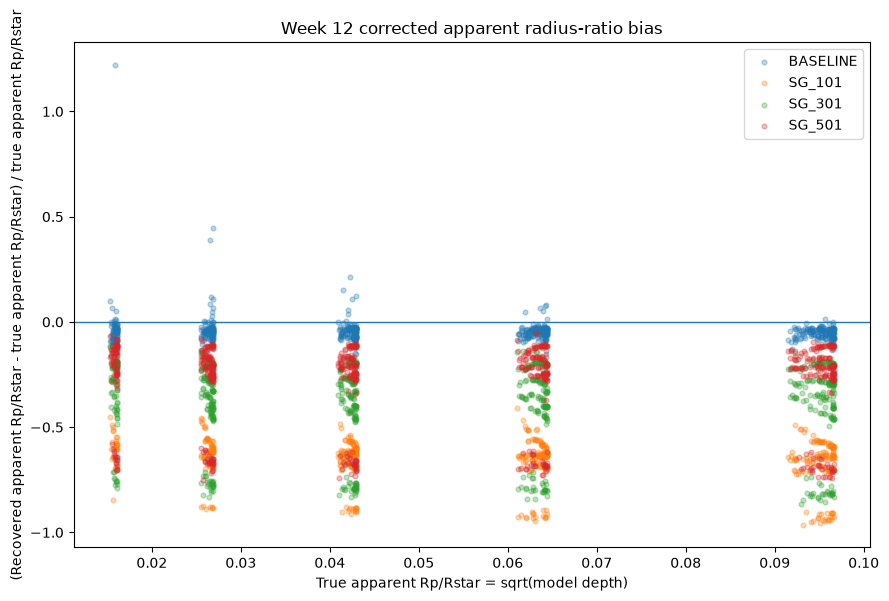


✅ WEEK 12 RADIUS-BIAS CORRECTION COMPLETE
✅ NO SEARCHES RERUN
✅ NO INJECTIONS RERUN
✅ COMPLETENESS UNCHANGED
✅ DEPTH BIAS UNCHANGED
✅ APPARENT RADIUS BIAS NOW PHYSICALLY CONSISTENT
✅ HELD-OUT HOSTS STILL UNTOUCHED


In [26]:
# ============================================================
# WEEK 12.1
# CORRECT DEPTH-DERIVED RADIUS-RATIO BIAS
#
# No new searches.
# No new injections.
# No held-out data.
#
# We compare:
#   true apparent Rp/R*     = sqrt(true model depth)
#   recovered apparent Rp/R* = sqrt(found BLS depth)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import json


# ------------------------------------------------------------
# 1. START FROM THE FROZEN WEEK 12 TABLE
# ------------------------------------------------------------

corrected_w12_df = week12_results_df.copy()


# ------------------------------------------------------------
# 2. DEFINE APPARENT RADIUS RATIOS CONSISTENTLY FROM DEPTH
# ------------------------------------------------------------

corrected_w12_df[
    "true_apparent_rp_over_rstar"
] = np.where(
    corrected_w12_df[
        "true_model_depth"
    ] > 0,
    np.sqrt(
        corrected_w12_df[
            "true_model_depth"
        ]
    ),
    np.nan,
)


corrected_w12_df[
    "recovered_apparent_rp_over_rstar"
] = np.where(
    corrected_w12_df[
        "found_depth"
    ] > 0,
    np.sqrt(
        corrected_w12_df[
            "found_depth"
        ]
    ),
    np.nan,
)


corrected_w12_df[
    "apparent_radius_fractional_error"
] = (
    corrected_w12_df[
        "recovered_apparent_rp_over_rstar"
    ]
    -
    corrected_w12_df[
        "true_apparent_rp_over_rstar"
    ]
) / corrected_w12_df[
    "true_apparent_rp_over_rstar"
]


# ------------------------------------------------------------
# 3. ONLY INTERPRET RADIUS BIAS ON EXACT RECOVERIES
# ------------------------------------------------------------

exact_corrected = corrected_w12_df[
    corrected_w12_df[
        "primary_recovered"
    ] == True
].copy()


# ------------------------------------------------------------
# 4. CORRECTED METHOD SUMMARY
# ------------------------------------------------------------

corrected_method_rows = []


for method_name, group in corrected_w12_df.groupby(
    "method"
):

    exact_group = group[
        group[
            "primary_recovered"
        ] == True
    ]


    corrected_method_rows.append({

        "method":
            method_name,

        "attempted":
            len(group),

        "exact_recovered":
            int(
                group[
                    "primary_recovered"
                ].sum()
            ),

        "exact_completeness":
            group[
                "primary_recovered"
            ].mean(),

        "median_depth_fractional_error_exact":
            exact_group[
                "depth_fractional_error"
            ].median(),

        "median_apparent_radius_fractional_error_exact":
            exact_group[
                "apparent_radius_fractional_error"
            ].median(),
    })


corrected_method_summary_df = pd.DataFrame(
    corrected_method_rows
)


METHOD_ORDER = [
    "BASELINE",
    "SG_101",
    "SG_301",
    "SG_501",
]


corrected_method_summary_df[
    "_order"
] = corrected_method_summary_df[
    "method"
].map(
    {
        method: i
        for i, method
        in enumerate(
            METHOD_ORDER
        )
    }
)


corrected_method_summary_df = (
    corrected_method_summary_df
    .sort_values(
        "_order"
    )
    .drop(
        columns="_order"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nCORRECTED METHOD SUMMARY"
)

display(
    corrected_method_summary_df
)


# ------------------------------------------------------------
# 5. CORRECTED PAIRED RADIUS-BIAS VS BASELINE
#
# Only cases recovered exactly by BOTH methods.
# ------------------------------------------------------------

baseline_exact = (

    corrected_w12_df[

        (
            corrected_w12_df[
                "method"
            ] == "BASELINE"
        )

        &

        (
            corrected_w12_df[
                "primary_recovered"
            ] == True
        )

    ][
        [
            "case_id",
            "apparent_radius_fractional_error",
        ]
    ]

    .rename(
        columns={
            "apparent_radius_fractional_error":
                "baseline_apparent_radius_error"
        }
    )
)


paired_radius_rows = []


for method_name in [
    "SG_101",
    "SG_301",
    "SG_501",
]:

    method_exact = (

        corrected_w12_df[

            (
                corrected_w12_df[
                    "method"
                ] == method_name
            )

            &

            (
                corrected_w12_df[
                    "primary_recovered"
                ] == True
            )

        ][
            [
                "case_id",
                "apparent_radius_fractional_error",
            ]
        ]

        .rename(
            columns={
                "apparent_radius_fractional_error":
                    "method_apparent_radius_error"
            }
        )
    )


    paired = baseline_exact.merge(
        method_exact,
        on="case_id",
        how="inner",
    )


    paired[
        "delta_apparent_radius_error_vs_baseline"
    ] = (
        paired[
            "method_apparent_radius_error"
        ]
        -
        paired[
            "baseline_apparent_radius_error"
        ]
    )


    paired_radius_rows.append({

        "method":
            method_name,

        "n_common_exact_recoveries":
            len(
                paired
            ),

        "median_delta_apparent_radius_error_vs_baseline":
            paired[
                "delta_apparent_radius_error_vs_baseline"
            ].median(),

        "fraction_more_radius_suppression_than_baseline":
            (
                paired[
                    "delta_apparent_radius_error_vs_baseline"
                ] < 0
            ).mean(),
    })


corrected_paired_radius_df = pd.DataFrame(
    paired_radius_rows
)


print(
    "\nCORRECTED PAIRED APPARENT-RADIUS BIAS"
)

display(
    corrected_paired_radius_df
)


# ------------------------------------------------------------
# 6. CORRECTED RADIUS-BIAS FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 6)
)


for method_name in METHOD_ORDER:

    subset = exact_corrected[
        exact_corrected[
            "method"
        ] == method_name
    ]


    ax.scatter(

        subset[
            "true_apparent_rp_over_rstar"
        ],

        subset[
            "apparent_radius_fractional_error"
        ],

        s=12,

        alpha=0.30,

        label=method_name,
    )


ax.axhline(
    0,
    linewidth=1,
)


ax.set_xlabel(
    "True apparent Rp/Rstar = sqrt(model depth)"
)


ax.set_ylabel(
    (
        "(Recovered apparent Rp/Rstar - "
        "true apparent Rp/Rstar) / true apparent Rp/Rstar"
    )
)


ax.set_title(
    "Week 12 corrected apparent radius-ratio bias"
)


ax.legend()


fig.tight_layout()


corrected_radius_fig_path = (

    W12_FIGURES_DIR
    / "radius_bias_corrected.png"
)


fig.savefig(
    corrected_radius_fig_path,
    dpi=220,
)


plt.show()


# ------------------------------------------------------------
# 7. SAVE CORRECTED TABLES
# ------------------------------------------------------------

corrected_results_path = (

    W12_RESULTS_DIR
    / "DET_detrending_results_corrected_radius.csv"
)


corrected_summary_path = (

    W12_RESULTS_DIR
    / "W12_method_summary_corrected_radius.csv"
)


corrected_paired_path = (

    W12_RESULTS_DIR
    / "W12_paired_radius_bias_corrected.csv"
)


corrected_w12_df.to_csv(
    corrected_results_path,
    index=False,
)


corrected_method_summary_df.to_csv(
    corrected_summary_path,
    index=False,
)


corrected_paired_radius_df.to_csv(
    corrected_paired_path,
    index=False,
)


# ------------------------------------------------------------
# 8. SAVE CORRECTION NOTE
# ------------------------------------------------------------

correction_note = {

    "version":
        "W12_RADIUS_CORRECTION_V1",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "reason":
        (
            "Original radius bias compared sqrt(found BLS depth) "
            "against injected geometric Rp/Rstar. "
            "Because model transit depth depends on geometry and "
            "limb darkening, the corrected comparison uses "
            "sqrt(model depth) on the truth side as well."
        ),

    "new_searches_run":
        0,

    "new_injections_run":
        0,

    "heldout_hosts_used":
        False,

    "week12_recovery_results_changed":
        False,

    "week12_completeness_changed":
        False,
}


with open(

    W12_CONFIG_DIR
    / "W12_RADIUS_CORRECTION_V1.json",

    "w",

) as f:

    json.dump(
        correction_note,
        f,
        indent=2,
    )


print()
print("=" * 70)
print("✅ WEEK 12 RADIUS-BIAS CORRECTION COMPLETE")
print("✅ NO SEARCHES RERUN")
print("✅ NO INJECTIONS RERUN")
print("✅ COMPLETENESS UNCHANGED")
print("✅ DEPTH BIAS UNCHANGED")
print("✅ APPARENT RADIUS BIAS NOW PHYSICALLY CONSISTENT")
print("✅ HELD-OUT HOSTS STILL UNTOUCHED")
print("=" * 70)

✅ Frozen project state found.
✅ Held-out firewall intact.
CPU cores: 16
Outer Week 13 workers: 2
✅ Frozen Week 13 subset: 200 cases
✅ Week 13 protocol frozen.
TLS validation: WASP-18
Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 38 durations
Searching 18299 data points, 2502 periods from 0.602 to 13.703 days
Using 1 of 16 CPU threads
Searching for best T0 for period 0.94152 days
TLS validation: WASP-43
Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 37 durations
Searching 15274 data points, 2120 periods from 0.601 to 11.916 days
Using 1 of 16 CPU threads
Searching for best T0 for period 0.81333 days

TLS KNOWN-PLANET VALIDATION


,target,reference_period_days,found_period_days,found_epoch_btjd,found_depth,detection_statistic,runtime_seconds,recovery_category
0,WASP-18,0.941452,0.941515,1354.457188,0.011507,42.447869,35.565984,EXACT
1,WASP-43,0.813475,0.813332,1545.232668,0.024673,34.635054,27.012599,EXACT



TLS already completed: 0
TLS pending: 200
TLS checkpoint: 2/200 | elapsed 2.9 min
TLS checkpoint: 4/200 | elapsed 5.5 min
TLS checkpoint: 6/200 | elapsed 8.7 min
TLS checkpoint: 8/200 | elapsed 10.9 min
TLS checkpoint: 10/200 | elapsed 12.9 min
TLS checkpoint: 12/200 | elapsed 14.5 min
TLS checkpoint: 14/200 | elapsed 16.1 min
TLS checkpoint: 16/200 | elapsed 17.7 min
TLS checkpoint: 18/200 | elapsed 19.4 min
TLS checkpoint: 20/200 | elapsed 21.0 min
TLS checkpoint: 22/200 | elapsed 22.6 min
TLS checkpoint: 24/200 | elapsed 23.9 min
TLS checkpoint: 26/200 | elapsed 25.6 min
TLS checkpoint: 28/200 | elapsed 27.0 min
TLS checkpoint: 30/200 | elapsed 28.9 min
TLS checkpoint: 32/200 | elapsed 30.5 min
TLS checkpoint: 34/200 | elapsed 31.8 min
TLS checkpoint: 36/200 | elapsed 33.2 min
TLS checkpoint: 38/200 | elapsed 34.7 min
TLS checkpoint: 40/200 | elapsed 36.1 min
TLS checkpoint: 42/200 | elapsed 36.4 min
TLS checkpoint: 44/200 | elapsed 36.7 min
TLS checkpoint: 46/200 | elapsed 37.0 mi

,method,attempted,exact_recovered,exact_completeness,alias_aware_recovered,alias_aware_completeness,median_search_runtime_seconds,median_total_runtime_seconds
0,BLS,200,128,0.64,128,0.64,3.502513,NaN
1,TLS,200,126,0.63,128,0.64,26.170264,26.182685



ALIAS TABLE


...

,BLS_miss_TLS_recovery,BLS_recovery_TLS_miss,both_recovered,both_missed
0,2,4,124,70



VETTING SUMMARY


,method,median_odd_even_fractional_difference,median_secondary_to_primary_ratio,median_individual_transit_relative_scatter,median_n_measured_transits
0,BLS,0.19880,-0.088899,0.129048,4.0
1,TLS,0.35629,-0.086164,0.137648,3.0


Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 37 durations
Searching 75238 data points, 2174 periods from 0.601 to 12.17 days
Using 1 of 16 CPU threads
Searching for best T0 for period 4.75749 days
Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 37 durations
Searching 15468 data points, 2201 periods from 0.601 to 12.299 days
Using 1 of 16 CPU threads
Searching for best T0 for period 5.74819 days
Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 37 durations
Searching 12988 data points, 2148 periods from 0.601 to 12.049 days
Using 1 of 16 CPU threads
Searching for best T0 for period 6.53545 days
Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 38 durations
Searching 17304 data points, 2322 periods from 0.601 to 12.863 days
Using 1 of 16 CPU threads
Searching for best T0 for period 11.59519 days
Transit Least Squares TLS 1.32 (5 Apr 2024)
Creating model cache for 38 durations
Searching 14835 data points, 2

,control_id,method,found_period_days,detection_statistic,runtime_seconds
0,CONTROL-001,BLS,14.418719,17.852602,8.324957
1,CONTROL-001,TLS,4.757489,6.720887,61.332887
2,CONTROL-002,BLS,5.990483,10.801339,1.701873
3,CONTROL-002,TLS,5.748194,5.972400,15.668061
4,CONTROL-003,BLS,6.467648,34.695018,1.624279
5,CONTROL-003,TLS,6.535449,8.018820,13.872227
6,CONTROL-004,BLS,6.269156,144.107001,1.408037
7,CONTROL-004,TLS,11.595189,3.961981,16.695314
8,CONTROL-005,BLS,9.072500,120.352242,1.138812
9,CONTROL-005,TLS,9.117798,7.751063,21.583678


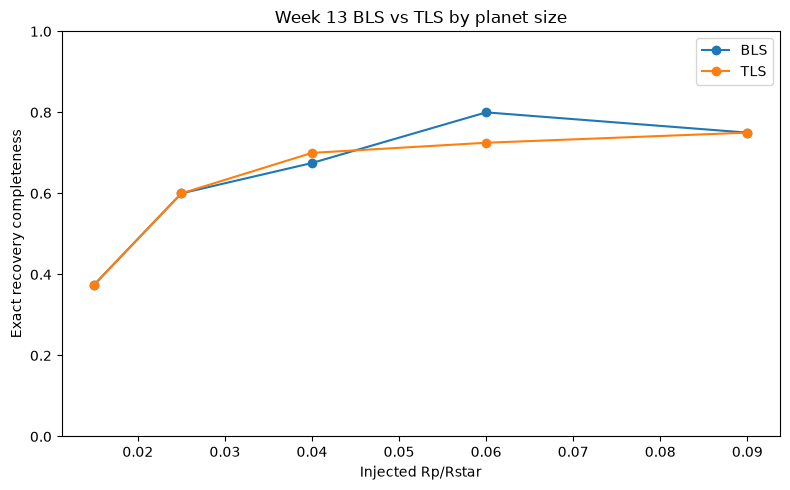

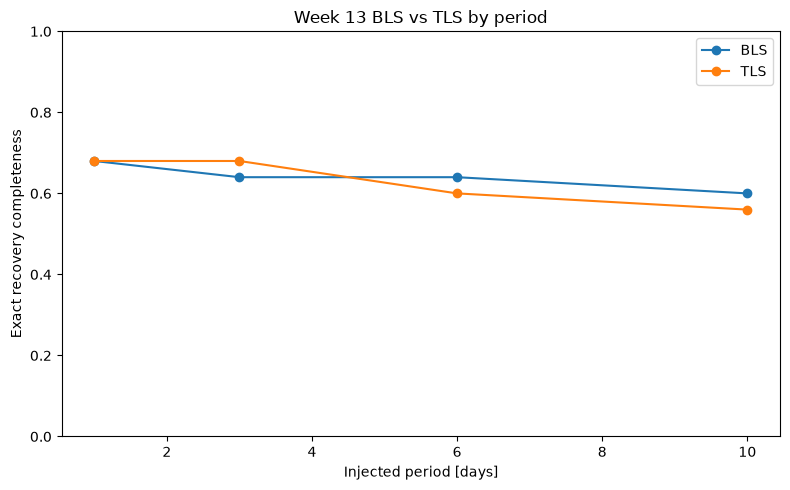


WEEK 13 BLS vs TLS + VETTING RESULTS

METHOD SUMMARY


,method,attempted,exact_recovered,exact_completeness,alias_aware_recovered,alias_aware_completeness,median_search_runtime_seconds,median_total_runtime_seconds
0,BLS,200,128,0.64,128,0.64,3.502513,NaN
1,TLS,200,126,0.63,128,0.64,26.170264,26.182685



ALIAS TABLE


,method,recovery_category,count,fraction
0,BLS,MISS,200,1.00
1,TLS,EXACT,126,0.63
2,TLS,HALF_ALIAS,2,0.01
3,TLS,MISS,72,0.36



PAIRED RECOVERY SWITCHES


...


VETTING SUMMARY


,method,median_odd_even_fractional_difference,median_secondary_to_primary_ratio,median_individual_transit_relative_scatter,median_n_measured_transits
0,BLS,0.19880,-0.088899,0.129048,4.0
1,TLS,0.35629,-0.086164,0.137648,3.0



NO-INJECTION CONTROL BEHAVIOR


,control_id,method,found_period_days,detection_statistic,runtime_seconds
0,CONTROL-001,BLS,14.418719,17.852602,8.324957
1,CONTROL-001,TLS,4.757489,6.720887,61.332887
2,CONTROL-002,BLS,5.990483,10.801339,1.701873
3,CONTROL-002,TLS,5.748194,5.972400,15.668061
4,CONTROL-003,BLS,6.467648,34.695018,1.624279
5,CONTROL-003,TLS,6.535449,8.018820,13.872227
6,CONTROL-004,BLS,6.269156,144.107001,1.408037
7,CONTROL-004,TLS,11.595189,3.961981,16.695314
8,CONTROL-005,BLS,9.072500,120.352242,1.138812
9,CONTROL-005,TLS,9.117798,7.751063,21.583678



 WEEK 13 CORE BENCHMARK COMPLETE
 TLS VALIDATED ON KNOWN PLANETS
 200 IDENTICAL CASES COMPARED
 BLS AND TLS USE SAME PERIOD RANGE
 ALIAS CLASSES REPORTED
 ODD-EVEN CHECK IMPLEMENTED
 SECONDARY-ECLIPSE CHECK IMPLEMENTED
 TRANSIT CONSISTENCY CHECK IMPLEMENTED
 RUNTIME RECORDED
 DEVELOPMENT CONTROLS COMPARED
 HELD-OUT HOSTS REMAIN UNTOUCHED
 W13_BLS_TLS_V1 FROZEN


In [27]:
# ============================================================
# WEEK 13
# BLS vs TLS + BASIC CANDIDATE VETTING
#
# DESIGN:
#   200 frozen injection cases
#   5 hosts
#   4 periods
#   5 Rp/Rstar levels
#   2 repetitions per cell
#
# SAME:
#   injection
#   host
#   preprocessing = BASELINE
#   period range = 0.5 to 15 d
#   RECOVERY_V2
#
# COMPARE:
#   BLS
#   TLS
#
# VETTING:
#   1. odd-even depth comparison
#   2. secondary eclipse-like depth near phase 0.5
#   3. individual-transit depth consistency
#
# HELD-OUT HOSTS REMAIN UNTOUCHED
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from joblib import Parallel, delayed

from transitleastsquares import transitleastsquares


# ============================================================
# 1. REQUIRE FROZEN PROJECT STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CONFIG_DIR",

    "development_host_data",
    "development_hosts_df",
    "heldout_hosts_df",

    "week11_design_df",
    "week11_results_df",

    "host_bls_grids",

    "inject_transit",
    "blind_bls_search",
    "evaluate_recovery_v2",
    "BLS_CONFIG",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required frozen project state is missing.\n"
        f"Missing: {missing}"
    )


assert len(
    week11_design_df
) == 1000


assert len(
    week11_results_df
) == 1000


assert (
    heldout_hosts_df[
        "bls_run"
    ] == False
).all()


assert (
    heldout_hosts_df[
        "injection_run"
    ] == False
).all()


assert (
    heldout_hosts_df[
        "used_for_tuning"
    ] == False
).all()


print(
    "✅ Frozen project state found."
)

print(
    "✅ Held-out firewall intact."
)


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

W13_RESULTS_DIR = (
    RESULTS_DIR
    / "week13_bls_tls_vetting"
)

W13_FIGURES_DIR = (
    FIGURES_DIR
    / "week13_bls_tls_vetting"
)

W13_CONFIG_DIR = (
    CONFIG_DIR
    / "week13_bls_tls_vetting"
)


for folder in [
    W13_RESULTS_DIR,
    W13_FIGURES_DIR,
    W13_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. CPU SETTINGS
#
# TLS already uses substantial CPU.
# Keep outer parallelism low.
# ============================================================

CPU_COUNT_W13 = (
    os.cpu_count()
    or 2
)


N_JOBS_W13 = max(
    1,
    min(
        CPU_COUNT_W13 - 1,
        2,
    )
)


print(
    "CPU cores:",
    CPU_COUNT_W13,
)

print(
    "Outer Week 13 workers:",
    N_JOBS_W13,
)


# ============================================================
# 4. FREEZE 200-CASE COMPARISON SUBSET
#
# 5 hosts
# × 4 periods
# × 5 sizes
# × first 2 repetitions
# = 200 cases
# ============================================================

week13_subset_df = (

    week11_design_df[

        week11_design_df[
            "repetition"
        ].isin(
            [
                1,
                2,
            ]
        )

    ]

    .copy()

    .sort_values(
        [
            "control_id",
            "true_period_days",
            "rp_over_rstar",
            "repetition",
        ]
    )

    .reset_index(
        drop=True
    )
)


assert len(
    week13_subset_df
) == 200


assert (
    week13_subset_df[
        "case_id"
    ].nunique()
    == 200
)


print(
    "✅ Frozen Week 13 subset:",
    len(
        week13_subset_df
    ),
    "cases"
)


# ============================================================
# 5. FREEZE WEEK 13 PROTOCOL
# ============================================================

WEEK13_PROTOCOL = {

    "version":
        "W13_BLS_TLS_V1",

    "source_injections":
        "W11_COMPLETENESS_V1",

    "n_cases":
        200,

    "selection_rule":
        (
            "All development hosts, all four periods, "
            "all five Rp/Rstar levels, repetitions 1 and 2."
        ),

    "preprocessing":
        "BASELINE",

    "methods":
        [
            "BLS",
            "TLS",
        ],

    "period_min_days":
        0.5,

    "period_max_days":
        15.0,

    "recovery_protocol":
        "RECOVERY_V2",

    "primary_recovery":
        "EXACT within 1%",

    "aliases":
        [
            "EXACT",
            "HALF_ALIAS",
            "DOUBLE_ALIAS",
            "NEAR_MATCH",
            "MISS",
        ],

    "vetting_checks":
        [
            "odd_even_depth_difference",
            "secondary_phase_0p5_depth",
            "individual_transit_depth_consistency",
        ],

    "heldout_hosts_used":
        False,
}


with open(

    W13_CONFIG_DIR
    / "W13_BLS_TLS_V1.json",

    "w",

) as f:

    json.dump(
        WEEK13_PROTOCOL,
        f,
        indent=2,
    )


week13_subset_df.to_csv(

    W13_RESULTS_DIR
    / "W13_case_subset.csv",

    index=False,
)


print(
    "✅ Week 13 protocol frozen."
)


# ============================================================
# 6. COMPATIBILITY-SAFE INJECTION WRAPPER
# ============================================================

def w13_call_inject_transit(
    host,
    period_days,
    epoch,
    rp_rs,
    impact_parameter,
):

    return inject_transit(

        host[
            "time"
        ],

        host[
            "flux"
        ],

        float(
            period_days
        ),

        float(
            epoch
        ),

        float(
            rp_rs
        ),

        float(
            host[
                "stellar_mass_msun"
            ]
        ),

        float(
            host[
                "stellar_radius_rsun"
            ]
        ),

        float(
            impact_parameter
        ),

        7,
    )


# ============================================================
# 7. REGENERATE IDENTICAL WEEK 11 INJECTION
# ============================================================

def w13_regenerate_injection(
    case,
):

    control_id = str(
        case[
            "control_id"
        ]
    )

    period = float(
        case[
            "true_period_days"
        ]
    )

    rp_rs = float(
        case[
            "rp_over_rstar"
        ]
    )

    seed = int(
        case[
            "seed"
        ]
    )


    host = development_host_data[
        control_id
    ]


    rng = np.random.default_rng(
        seed
    )


    impact_parameter = float(
        rng.uniform(
            0,
            0.7,
        )
    )


    epoch = float(

        host[
            "time"
        ].min()

        +

        rng.uniform(
            0,
            period,
        )
    )


    injected_flux, truth = (
        w13_call_inject_transit(

            host,

            period,

            epoch,

            rp_rs,

            impact_parameter,
        )
    )


    return {

        "time":
            np.asarray(
                host[
                    "time"
                ],
                dtype=float,
            ),

        "flux":
            np.asarray(
                injected_flux,
                dtype=float,
            ),

        "truth": {

            **truth,

            "case_id":
                str(
                    case[
                        "case_id"
                    ]
                ),

            "control_id":
                control_id,

            "seed":
                seed,

            "period":
                period,

            "rp_over_rstar":
                rp_rs,

            "epoch":
                epoch,

            "impact_parameter":
                impact_parameter,
        },
    }


# ============================================================
# 8. TLS SEARCH WRAPPER
# ============================================================

def run_tls_search(
    time_values,
    flux_values,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    good = (
        np.isfinite(
            t
        )
        &
        np.isfinite(
            f
        )
    )


    t = t[
        good
    ]

    f = f[
        good
    ]


    start = (
        time.perf_counter()
    )


    model = (
        transitleastsquares(
            t,
            f,
        )
    )


    result = model.power(

        period_min=0.5,

        period_max=15.0,

        show_progress_bar=False,

        use_threads=1,
    )


    runtime = (
        time.perf_counter()
        -
        start
    )


    found_period = float(
        result.period
    )


    found_epoch = float(
        result.T0
    )


    tls_sde = float(
        result.SDE
    )


    try:

        found_depth = float(
            result.depth
        )

        # TLS depth is commonly returned as
        # relative flux level in transit.
        # Convert to fractional dip if necessary.
        if (
            np.isfinite(
                found_depth
            )
            and
            found_depth > 0.5
        ):

            fractional_depth = (
                1.0
                -
                found_depth
            )

        else:

            fractional_depth = (
                found_depth
            )

    except Exception:

        fractional_depth = np.nan


    return {

        "found_period_days":
            found_period,

        "found_epoch_btjd":
            found_epoch,

        "found_depth":
            fractional_depth,

        "detection_statistic":
            tls_sde,

        "runtime_seconds":
            runtime,
    }


# ============================================================
# 9. PHASE HELPER
# ============================================================

def signed_phase(
    time_values,
    period,
    epoch,
):

    return (

        (
            (
                np.asarray(
                    time_values
                )
                -
                epoch
                +
                0.5
                *
                period
            )
            %
            period
        )
        /
        period

        -
        0.5
    )


# ============================================================
# 10. ROBUST MEDIAN DEPTH
# ============================================================

def robust_depth(
    flux_values,
    mask,
):

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    mask = np.asarray(
        mask,
        dtype=bool,
    )


    if (
        mask.sum()
        <
        3
    ):

        return np.nan


    outside = (
        ~mask
    )


    if (
        outside.sum()
        <
        10
    ):

        return np.nan


    baseline = np.nanmedian(
        f[
            outside
        ]
    )


    inside = np.nanmedian(
        f[
            mask
        ]
    )


    return float(
        baseline
        -
        inside
    )


# ============================================================
# 11. ODD-EVEN DEPTH CHECK
# ============================================================

def odd_even_depth_check(
    time_values,
    flux_values,
    period,
    epoch,
    duration_fraction=0.04,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    transit_number = np.rint(

        (
            t
            -
            epoch
        )
        /
        period

    ).astype(
        int
    )


    centers = (
        epoch
        +
        transit_number
        *
        period
    )


    distance = np.abs(
        t
        -
        centers
    )


    half_width = (
        0.5
        *
        duration_fraction
        *
        period
    )


    in_transit = (
        distance
        <=
        half_width
    )


    odd_mask = (

        in_transit

        &

        (
            transit_number
            %
            2
            !=
            0
        )
    )


    even_mask = (

        in_transit

        &

        (
            transit_number
            %
            2
            ==
            0
        )
    )


    odd_depth = robust_depth(
        f,
        odd_mask,
    )


    even_depth = robust_depth(
        f,
        even_mask,
    )


    if (
        np.isfinite(
            odd_depth
        )
        and
        np.isfinite(
            even_depth
        )
    ):

        scale = max(

            abs(
                odd_depth
            ),

            abs(
                even_depth
            ),

            1e-12,
        )


        fractional_difference = (

            abs(
                odd_depth
                -
                even_depth
            )

            /
            scale
        )

    else:

        fractional_difference = np.nan


    return {

        "odd_depth":
            odd_depth,

        "even_depth":
            even_depth,

        "odd_even_fractional_difference":
            fractional_difference,
    }


# ============================================================
# 12. SECONDARY-ECLIPSE-LIKE CHECK
#
# Measures a dip near phase 0.5 relative to primary.
# Evidence only, not a binary classification.
# ============================================================

def secondary_eclipse_check(
    time_values,
    flux_values,
    period,
    epoch,
    duration_fraction=0.04,
):

    phase = signed_phase(
        time_values,
        period,
        epoch,
    )


    f = np.asarray(
        flux_values,
        dtype=float,
    )


    half_width = (
        duration_fraction
        /
        2
    )


    primary_mask = (
        np.abs(
            phase
        )
        <=
        half_width
    )


    distance_secondary = np.minimum(

        np.abs(
            phase
            -
            0.5
        ),

        np.abs(
            phase
            +
            0.5
        ),
    )


    secondary_mask = (
        distance_secondary
        <=
        half_width
    )


    primary_depth = robust_depth(
        f,
        primary_mask,
    )


    secondary_depth = robust_depth(
        f,
        secondary_mask,
    )


    if (
        np.isfinite(
            primary_depth
        )
        and
        primary_depth
        !=
        0
        and
        np.isfinite(
            secondary_depth
        )
    ):

        secondary_to_primary = (

            secondary_depth
            /
            primary_depth
        )

    else:

        secondary_to_primary = np.nan


    return {

        "vet_primary_depth":
            primary_depth,

        "secondary_depth":
            secondary_depth,

        "secondary_to_primary_ratio":
            secondary_to_primary,
    }


# ============================================================
# 13. INDIVIDUAL-TRANSIT CONSISTENCY
#
# Measures spread of per-transit depths.
# ============================================================

def transit_consistency_check(
    time_values,
    flux_values,
    period,
    epoch,
    duration_fraction=0.04,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    n_min = int(
        np.floor(
            (
                t.min()
                -
                epoch
            )
            /
            period
        )
    )


    n_max = int(
        np.ceil(
            (
                t.max()
                -
                epoch
            )
            /
            period
        )
    )


    depths = []


    half_width = (
        0.5
        *
        duration_fraction
        *
        period
    )


    local_window = (
        3
        *
        half_width
    )


    for n in range(
        n_min,
        n_max + 1,
    ):

        center = (
            epoch
            +
            n
            *
            period
        )


        local = (
            np.abs(
                t
                -
                center
            )
            <=
            local_window
        )


        transit = (
            np.abs(
                t
                -
                center
            )
            <=
            half_width
        )


        baseline_mask = (
            local
            &
            (~transit)
        )


        if (
            transit.sum()
            <
            3
            or
            baseline_mask.sum()
            <
            5
        ):

            continue


        baseline = np.nanmedian(
            f[
                baseline_mask
            ]
        )


        inside = np.nanmedian(
            f[
                transit
            ]
        )


        depth = (
            baseline
            -
            inside
        )


        if np.isfinite(
            depth
        ):

            depths.append(
                float(
                    depth
                )
            )


    depths = np.asarray(
        depths,
        dtype=float,
    )


    if (
        len(
            depths
        )
        >=
        2
    ):

        median_depth = np.nanmedian(
            depths
        )


        scatter = (
            1.4826
            *
            np.nanmedian(
                np.abs(
                    depths
                    -
                    median_depth
                )
            )
        )


        if (
            median_depth
            !=
            0
        ):

            relative_scatter = (

                scatter
                /
                abs(
                    median_depth
                )
            )

        else:

            relative_scatter = np.nan

    else:

        median_depth = np.nan
        scatter = np.nan
        relative_scatter = np.nan


    return {

        "n_measured_transits":
            int(
                len(
                    depths
                )
            ),

        "median_individual_transit_depth":
            median_depth,

        "individual_transit_depth_scatter":
            scatter,

        "individual_transit_relative_scatter":
            relative_scatter,
    }


# ============================================================
# 14. VALIDATE TLS ON KNOWN PLANETS FIRST
#
# Cookbook explicitly requires this before benchmark use.
# ============================================================

known_planets = [

    {
        "target":
            "WASP-18",

        "period":
            0.94145223,
    },

    {
        "target":
            "WASP-43",

        "period":
            0.813475,
    },
]


tls_validation_rows = []


for planet in known_planets:

    print(
        "TLS validation:",
        planet[
            "target"
        ]
    )


    known_lc = download_spoc_sector(
        planet[
            "target"
        ]
    )


    tls_result = run_tls_search(

        known_lc[
            "time"
        ],

        known_lc[
            "flux"
        ],
    )


    evaluation = evaluate_recovery_v2(

        true_period=planet[
            "period"
        ],

        found_period=tls_result[
            "found_period_days"
        ],
    )


    tls_validation_rows.append({

        "target":
            planet[
                "target"
            ],

        "reference_period_days":
            planet[
                "period"
            ],

        **tls_result,

        "recovery_category":
            evaluation[
                "category"
            ],
    })


tls_validation_df = pd.DataFrame(
    tls_validation_rows
)


print(
    "\nTLS KNOWN-PLANET VALIDATION"
)

display(
    tls_validation_df
)


tls_validation_df.to_csv(

    W13_RESULTS_DIR
    / "W13_TLS_known_planet_validation.csv",

    index=False,
)


# ============================================================
# 15. BLS RESULT FOR EACH SUBSET CASE
#
# We reuse frozen Week 11 BLS results.
# No reason to rerun them.
# ============================================================

bls_subset_df = (

    week11_results_df[
        week11_results_df[
            "case_id"
        ].isin(
            week13_subset_df[
                "case_id"
            ]
        )
    ]

    .copy()
)


assert len(
    bls_subset_df
) == 200


# ============================================================
# 16. TLS SINGLE-CASE WORKER
# ============================================================

def run_week13_tls_case(
    case,
):

    start_total = (
        time.perf_counter()
    )


    case_id = str(
        case[
            "case_id"
        ]
    )


    control_id = str(
        case[
            "control_id"
        ]
    )


    true_period = float(
        case[
            "true_period_days"
        ]
    )


    try:

        regenerated = (
            w13_regenerate_injection(
                case
            )
        )


        t = regenerated[
            "time"
        ]


        f = regenerated[
            "flux"
        ]


        tls_result = (
            run_tls_search(
                t,
                f,
            )
        )


        evaluation = (
            evaluate_recovery_v2(

                true_period=true_period,

                found_period=tls_result[
                    "found_period_days"
                ],
            )
        )


        found_period = (
            tls_result[
                "found_period_days"
            ]
        )


        found_epoch = (
            tls_result[
                "found_epoch_btjd"
            ]
        )


        odd_even = (
            odd_even_depth_check(

                t,
                f,
                found_period,
                found_epoch,
            )
        )


        secondary = (
            secondary_eclipse_check(

                t,
                f,
                found_period,
                found_epoch,
            )
        )


        consistency = (
            transit_consistency_check(

                t,
                f,
                found_period,
                found_epoch,
            )
        )


        return {

            "case_id":
                case_id,

            "control_id":
                control_id,

            "seed":
                int(
                    case[
                        "seed"
                    ]
                ),

            "true_period_days":
                true_period,

            "rp_over_rstar":
                float(
                    case[
                        "rp_over_rstar"
                    ]
                ),

            "method":
                "TLS",

            **tls_result,

            "recovery_category":
                evaluation[
                    "category"
                ],

            "primary_recovered":
                evaluation[
                    "primary_recovered"
                ],

            "alias_aware_recovered":
                evaluation[
                    "alias_aware_recovered"
                ],

            **odd_even,
            **secondary,
            **consistency,

            "runtime_total_seconds":
                (
                    time.perf_counter()
                    -
                    start_total
                ),

            "status":
                "SUCCESS",
        }


    except Exception as error:

        return {

            "case_id":
                case_id,

            "control_id":
                control_id,

            "true_period_days":
                true_period,

            "rp_over_rstar":
                float(
                    case[
                        "rp_over_rstar"
                    ]
                ),

            "method":
                "TLS",

            "recovery_category":
                "FAILED",

            "primary_recovered":
                False,

            "alias_aware_recovered":
                False,

            "runtime_total_seconds":
                (
                    time.perf_counter()
                    -
                    start_total
                ),

            "status":
                "FAILED",

            "error":
                repr(
                    error
                ),
        }


# ============================================================
# 17. TLS CHECKPOINT / RESUME
# ============================================================

TLS_CHECKPOINT_PATH = (

    W13_RESULTS_DIR
    / "W13_TLS_checkpoint.csv"
)


TLS_RESULTS_PATH = (

    W13_RESULTS_DIR
    / "W13_TLS_results.csv"
)


if TLS_CHECKPOINT_PATH.exists():

    tls_existing_df = (

        pd.read_csv(
            TLS_CHECKPOINT_PATH
        )

        .drop_duplicates(
            "case_id",
            keep="last",
        )
    )

else:

    tls_existing_df = pd.DataFrame()


completed_tls_ids = (

    set(
        tls_existing_df[
            "case_id"
        ].astype(
            str
        )
    )

    if len(
        tls_existing_df
    )

    else set()
)


tls_pending_df = (

    week13_subset_df[
        ~week13_subset_df[
            "case_id"
        ].astype(
            str
        ).isin(
            completed_tls_ids
        )
    ]

    .copy()
)


print()
print(
    "TLS already completed:",
    len(
        tls_existing_df
    ),
)

print(
    "TLS pending:",
    len(
        tls_pending_df
    ),
)


# ============================================================
# 18. RUN TLS BENCHMARK
# ============================================================

current_tls_df = (
    tls_existing_df.copy()
)


W13_CHUNK_SIZE = max(
    2,
    N_JOBS_W13
)


session_start = (
    time.perf_counter()
)


for start_index in range(

    0,

    len(
        tls_pending_df
    ),

    W13_CHUNK_SIZE,
):

    chunk = (
        tls_pending_df
        .iloc[
            start_index:
            start_index
            +
            W13_CHUNK_SIZE
        ]
    )


    chunk_results = Parallel(

        n_jobs=N_JOBS_W13,

        backend="loky",

        verbose=0,

    )(

        delayed(
            run_week13_tls_case
        )(
            record
        )

        for record
        in chunk.to_dict(
            "records"
        )
    )


    current_tls_df = pd.concat(

        [
            current_tls_df,
            pd.DataFrame(
                chunk_results
            ),
        ],

        ignore_index=True,
    )


    current_tls_df = (

        current_tls_df

        .drop_duplicates(
            "case_id",
            keep="last",
        )
    )


    temp_path = (
        TLS_CHECKPOINT_PATH
        .with_suffix(
            ".tmp.csv"
        )
    )


    current_tls_df.to_csv(
        temp_path,
        index=False,
    )


    temp_path.replace(
        TLS_CHECKPOINT_PATH
    )


    elapsed_min = (

        time.perf_counter()
        -
        session_start

    ) / 60


    print(

        f"TLS checkpoint: "
        f"{len(current_tls_df)}/200 "
        f"| elapsed {elapsed_min:.1f} min"
    )


current_tls_df = (

    current_tls_df

    .sort_values(
        "case_id"
    )

    .reset_index(
        drop=True
    )
)


current_tls_df.to_csv(

    TLS_RESULTS_PATH,

    index=False,
)


assert len(
    current_tls_df
) == 200


print(
    "✅ TLS benchmark complete."
)


# ============================================================
# 19. FORMAT BLS ROWS TO MATCH TLS
# ============================================================

bls_rows = []


for _, row in (
    bls_subset_df.iterrows()
):

    regenerated = (
        w13_regenerate_injection(
            row
        )
    )


    t = regenerated[
        "time"
    ]

    f = regenerated[
        "flux"
    ]


    found_period = float(
        row[
            "found_period_days"
        ]
    )


    found_epoch = row.get(
        "found_epoch_btjd",
        np.nan,
    )


    if not np.isfinite(
        found_epoch
    ):

        found_epoch = (
            regenerated[
                "truth"
            ][
                "epoch"
            ]
        )


    odd_even = (
        odd_even_depth_check(

            t,
            f,
            found_period,
            found_epoch,
        )
    )


    secondary = (
        secondary_eclipse_check(

            t,
            f,
            found_period,
            found_epoch,
        )
    )


    consistency = (
        transit_consistency_check(

            t,
            f,
            found_period,
            found_epoch,
        )
    )


    bls_rows.append({

        "case_id":
            str(
                row[
                    "case_id"
                ]
            ),

        "control_id":
            str(
                row[
                    "control_id"
                ]
            ),

        "seed":
            int(
                row[
                    "seed"
                ]
            ),

        "true_period_days":
            float(
                row[
                    "true_period_days"
                ]
            ),

        "rp_over_rstar":
            float(
                row[
                    "rp_over_rstar"
                ]
            ),

        "method":
            "BLS",

        "found_period_days":
            found_period,

        "found_epoch_btjd":
            found_epoch,

        "found_depth":
            row.get(
                "found_depth",
                np.nan,
            ),

        "detection_statistic":
            row.get(
                "detection_sde",
                np.nan,
            ),

        "runtime_seconds":
            row.get(
                "runtime_seconds_total",
                row.get(
                    "runtime_seconds",
                    np.nan,
                ),
            ),

        "recovery_category":
            row.get(
                "recovery_category",
                "MISS",
            ),

        "primary_recovered":
            bool(
                row[
                    "primary_recovered"
                ]
            ),

        "alias_aware_recovered":
            bool(
                row[
                    "alias_aware_recovered"
                ]
            ),

        **odd_even,
        **secondary,
        **consistency,

        "status":
            row.get(
                "status",
                "SUCCESS",
            ),
    })


bls_w13_df = pd.DataFrame(
    bls_rows
)


# ============================================================
# 20. COMBINE PAIRED BLS + TLS
# ============================================================

week13_results_df = pd.concat(

    [
        bls_w13_df,
        current_tls_df,
    ],

    ignore_index=True,
)


assert len(
    week13_results_df
) == 400


assert (

    week13_results_df

    .groupby(
        "case_id"
    )[
        "method"
    ]

    .nunique()

    ==
    2

).all()


W13_MASTER_RESULTS_PATH = (

    W13_RESULTS_DIR
    / "W13_BLS_TLS_results.csv"
)


week13_results_df.to_csv(

    W13_MASTER_RESULTS_PATH,

    index=False,
)


print(
    "✅ 200 perfectly paired BLS/TLS cases."
)


# ============================================================
# 21. METHOD SUMMARY
# ============================================================

summary_rows = []


for (
    method_name,
    group
) in week13_results_df.groupby(
    "method"
):

    summary_rows.append({

        "method":
            method_name,

        "attempted":
            len(
                group
            ),

        "exact_recovered":
            int(
                group[
                    "primary_recovered"
                ].sum()
            ),

        "exact_completeness":
            group[
                "primary_recovered"
            ].mean(),

        "alias_aware_recovered":
            int(
                group[
                    "alias_aware_recovered"
                ].sum()
            ),

        "alias_aware_completeness":
            group[
                "alias_aware_recovered"
            ].mean(),

        "median_search_runtime_seconds":
            group[
                "runtime_seconds"
            ].median(),

        "median_total_runtime_seconds":
            (
                group[
                    "runtime_total_seconds"
                ].median()

                if
                "runtime_total_seconds"
                in group.columns

                else np.nan
            ),
    })


method_summary_df = pd.DataFrame(
    summary_rows
)


print(
    "\nBLS vs TLS SUMMARY"
)

display(
    method_summary_df
)


# ============================================================
# 22. ALIAS TABLE
# ============================================================

alias_table = (

    week13_results_df

    .groupby(
        [
            "method",
            "recovery_category",
        ]
    )

    .size()

    .reset_index(
        name="count"
    )
)


alias_table[
    "fraction"
] = (

    alias_table[
        "count"
    ]

    /

    alias_table.groupby(
        "method"
    )[
        "count"
    ].transform(
        "sum"
    )
)


print(
    "\nALIAS TABLE"
)

display(
    alias_table
)


# ============================================================
# 23. COMPLETENESS BY PLANET SIZE
# ============================================================

size_summary = (

    week13_results_df

    .groupby(
        [
            "method",
            "rp_over_rstar",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


print(
    "\nCOMPLETENESS BY SIZE"
)

display(
    size_summary
)


# ============================================================
# 24. COMPLETENESS BY PERIOD
# ============================================================

period_summary = (

    week13_results_df

    .groupby(
        [
            "method",
            "true_period_days",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


print(
    "\nCOMPLETENESS BY PERIOD"
)

display(
    period_summary
)


# ============================================================
# 25. PAIRED RECOVERY SWITCHES
# ============================================================

paired_recovery = (

    week13_results_df

    .pivot(
        index="case_id",
        columns="method",
        values="primary_recovered",
    )

    .reset_index()
)


switch_summary = pd.DataFrame(
    [
        {

            "BLS_miss_TLS_recovery":
                int(
                    (
                        (~paired_recovery[
                            "BLS"
                        ])
                        &
                        (
                            paired_recovery[
                                "TLS"
                            ]
                        )
                    ).sum()
                ),

            "BLS_recovery_TLS_miss":
                int(
                    (
                        (
                            paired_recovery[
                                "BLS"
                            ]
                        )
                        &
                        (~paired_recovery[
                            "TLS"
                        ])
                    ).sum()
                ),

            "both_recovered":
                int(
                    (
                        paired_recovery[
                            "BLS"
                        ]
                        &
                        paired_recovery[
                            "TLS"
                        ]
                    ).sum()
                ),

            "both_missed":
                int(
                    (
                        (~paired_recovery[
                            "BLS"
                        ])
                        &
                        (~paired_recovery[
                            "TLS"
                        ])
                    ).sum()
                ),
        }
    ]
)


print(
    "\nPAIRED RECOVERY SWITCHES"
)

display(
    switch_summary
)


# ============================================================
# 26. VETTING SUMMARY
#
# Evidence distributions only.
# No "planet probability".
# ============================================================

vetting_summary = (

    week13_results_df

    .groupby(
        "method"
    )

    .agg(

        median_odd_even_fractional_difference=(
            "odd_even_fractional_difference",
            "median",
        ),

        median_secondary_to_primary_ratio=(
            "secondary_to_primary_ratio",
            "median",
        ),

        median_individual_transit_relative_scatter=(
            "individual_transit_relative_scatter",
            "median",
        ),

        median_n_measured_transits=(
            "n_measured_transits",
            "median",
        ),
    )

    .reset_index()
)


print(
    "\nVETTING SUMMARY"
)

display(
    vetting_summary
)


# ============================================================
# 27. NO-INJECTION CONTROL SEARCHES
#
# Same 5 development controls.
# ============================================================

control_rows = []


for (
    control_id,
    host
) in development_host_data.items():

    # --------------------------------------------------------
    # BLS
    # --------------------------------------------------------

    bls_control = (
        blind_bls_search(

            host[
                "time"
            ],

            host[
                "flux"
            ],

            period_grid=host_bls_grids[
                control_id
            ],

            config=BLS_CONFIG,
        )
    )


    control_rows.append({

        "control_id":
            control_id,

        "method":
            "BLS",

        "found_period_days":
            bls_control[
                "found_period_days"
            ],

        "detection_statistic":
            bls_control[
                "detection_sde"
            ],

        "runtime_seconds":
            bls_control[
                "runtime_seconds"
            ],
    })


    # --------------------------------------------------------
    # TLS
    # --------------------------------------------------------

    tls_control = (
        run_tls_search(

            host[
                "time"
            ],

            host[
                "flux"
            ],
        )
    )


    control_rows.append({

        "control_id":
            control_id,

        "method":
            "TLS",

        "found_period_days":
            tls_control[
                "found_period_days"
            ],

        "detection_statistic":
            tls_control[
                "detection_statistic"
            ],

        "runtime_seconds":
            tls_control[
                "runtime_seconds"
            ],
    })


control_results_df = pd.DataFrame(
    control_rows
)


print(
    "\nNO-INJECTION CONTROL BEHAVIOR"
)

display(
    control_results_df
)


# ============================================================
# 28. FIGURE — COMPLETENESS BY SIZE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


for method_name in [
    "BLS",
    "TLS",
]:

    subset = size_summary[
        size_summary[
            "method"
        ]
        ==
        method_name
    ]


    ax.plot(

        subset[
            "rp_over_rstar"
        ],

        subset[
            "exact_completeness"
        ],

        marker="o",

        label=method_name,
    )


ax.set_ylim(
    0,
    1,
)


ax.set_xlabel(
    "Injected Rp/Rstar"
)


ax.set_ylabel(
    "Exact recovery completeness"
)


ax.set_title(
    "Week 13 BLS vs TLS by planet size"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W13_FIGURES_DIR
    / "BLS_vs_TLS_by_size.png",

    dpi=220,
)


plt.show()


# ============================================================
# 29. FIGURE — COMPLETENESS BY PERIOD
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


for method_name in [
    "BLS",
    "TLS",
]:

    subset = period_summary[
        period_summary[
            "method"
        ]
        ==
        method_name
    ]


    ax.plot(

        subset[
            "true_period_days"
        ],

        subset[
            "exact_completeness"
        ],

        marker="o",

        label=method_name,
    )


ax.set_ylim(
    0,
    1,
)


ax.set_xlabel(
    "Injected period [days]"
)


ax.set_ylabel(
    "Exact recovery completeness"
)


ax.set_title(
    "Week 13 BLS vs TLS by period"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W13_FIGURES_DIR
    / "BLS_vs_TLS_by_period.png",

    dpi=220,
)


plt.show()


# ============================================================
# 30. SAVE TABLES
# ============================================================

method_summary_df.to_csv(

    W13_RESULTS_DIR
    / "W13_method_summary.csv",

    index=False,
)


alias_table.to_csv(

    W13_RESULTS_DIR
    / "W13_alias_table.csv",

    index=False,
)


size_summary.to_csv(

    W13_RESULTS_DIR
    / "W13_size_summary.csv",

    index=False,
)


period_summary.to_csv(

    W13_RESULTS_DIR
    / "W13_period_summary.csv",

    index=False,
)


switch_summary.to_csv(

    W13_RESULTS_DIR
    / "W13_paired_recovery_switches.csv",

    index=False,
)


vetting_summary.to_csv(

    W13_RESULTS_DIR
    / "W13_vetting_summary.csv",

    index=False,
)


control_results_df.to_csv(

    W13_RESULTS_DIR
    / "W13_control_results.csv",

    index=False,
)


# ============================================================
# 31. FREEZE MANIFEST
# ============================================================

freeze_manifest = {

    "version":
        "W13_BLS_TLS_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "n_cases":
        200,

    "methods":
        [
            "BLS",
            "TLS",
        ],

    "preprocessing":
        "BASELINE",

    "recovery_protocol":
        "RECOVERY_V2",

    "vetting_checks":
        WEEK13_PROTOCOL[
            "vetting_checks"
        ],

    "heldout_hosts_used":
        False,

    "master_result_table":
        str(
            W13_MASTER_RESULTS_PATH
        ),
}


with open(

    W13_CONFIG_DIR
    / "W13_BLS_TLS_V1_FREEZE_MANIFEST.json",

    "w",

) as f:

    json.dump(
        freeze_manifest,
        f,
        indent=2,
    )


# ============================================================
# 32. FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("WEEK 13 BLS vs TLS + VETTING RESULTS")
print("=" * 70)


print(
    "\nMETHOD SUMMARY"
)

display(
    method_summary_df
)


print(
    "\nALIAS TABLE"
)

display(
    alias_table
)


print(
    "\nPAIRED RECOVERY SWITCHES"
)

display(
    switch_summary
)


print(
    "\nVETTING SUMMARY"
)

display(
    vetting_summary
)


print(
    "\nNO-INJECTION CONTROL BEHAVIOR"
)

display(
    control_results_df
)


print()
print("=" * 70)
print(" WEEK 13 CORE BENCHMARK COMPLETE")
print(" TLS VALIDATED ON KNOWN PLANETS")
print(" 200 IDENTICAL CASES COMPARED")
print(" BLS AND TLS USE SAME PERIOD RANGE")
print(" ALIAS CLASSES REPORTED")
print(" ODD-EVEN CHECK IMPLEMENTED")
print(" SECONDARY-ECLIPSE CHECK IMPLEMENTED")
print(" TRANSIT CONSISTENCY CHECK IMPLEMENTED")
print(" RUNTIME RECORDED")
print(" DEVELOPMENT CONTROLS COMPARED")
print(" HELD-OUT HOSTS REMAIN UNTOUCHED")
print(" W13_BLS_TLS_V1 FROZEN")
print("=" * 70)

In [28]:
# ============================================================
# WEEK 13.1
# REPAIR ALIAS CLASSIFICATION TABLE
#
# NO SEARCHES RERUN
# NO INJECTIONS RERUN
# HELD-OUT DATA UNTOUCHED
# ============================================================

import pandas as pd
import numpy as np
import json
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. Recompute recovery class for EVERY Week 13 row directly
#    from true period and recovered period
# ------------------------------------------------------------

repaired_w13_df = week13_results_df.copy()


repaired_categories = []
repaired_primary = []
repaired_alias_aware = []


for _, row in repaired_w13_df.iterrows():

    evaluation = evaluate_recovery_v2(
        true_period=float(
            row["true_period_days"]
        ),
        found_period=float(
            row["found_period_days"]
        ),
    )


    repaired_categories.append(
        evaluation["category"]
    )

    repaired_primary.append(
        evaluation["primary_recovered"]
    )

    repaired_alias_aware.append(
        evaluation["alias_aware_recovered"]
    )


repaired_w13_df[
    "recovery_category"
] = repaired_categories


repaired_w13_df[
    "primary_recovered"
] = repaired_primary


repaired_w13_df[
    "alias_aware_recovered"
] = repaired_alias_aware


# ------------------------------------------------------------
# 2. Sanity check totals
# ------------------------------------------------------------

print("\nREPAIRED METHOD TOTALS")


repaired_method_summary = (

    repaired_w13_df

    .groupby(
        "method"
    )

    .agg(
        attempted=(
            "case_id",
            "count"
        ),

        exact_recovered=(
            "primary_recovered",
            "sum"
        ),

        exact_completeness=(
            "primary_recovered",
            "mean"
        ),

        alias_aware_recovered=(
            "alias_aware_recovered",
            "sum"
        ),

        alias_aware_completeness=(
            "alias_aware_recovered",
            "mean"
        ),
    )

    .reset_index()
)


display(
    repaired_method_summary
)


# ------------------------------------------------------------
# 3. Correct alias table
# ------------------------------------------------------------

alias_order = [
    "EXACT",
    "HALF_ALIAS",
    "DOUBLE_ALIAS",
    "NEAR_MATCH",
    "MISS",
    "FAILED",
]


repaired_alias_table = (

    repaired_w13_df

    .groupby(
        [
            "method",
            "recovery_category",
        ]
    )

    .size()

    .reset_index(
        name="count"
    )
)


repaired_alias_table[
    "fraction"
] = (

    repaired_alias_table[
        "count"
    ]

    /

    repaired_alias_table.groupby(
        "method"
    )[
        "count"
    ].transform(
        "sum"
    )
)


repaired_alias_table[
    "_category_order"
] = (

    repaired_alias_table[
        "recovery_category"
    ].map(
        {
            value: i
            for i, value
            in enumerate(
                alias_order
            )
        }
    )
)


repaired_alias_table = (

    repaired_alias_table

    .sort_values(
        [
            "method",
            "_category_order",
        ]
    )

    .drop(
        columns="_category_order"
    )

    .reset_index(
        drop=True
    )
)


print("\nCORRECTED ALIAS TABLE")

display(
    repaired_alias_table
)


# ------------------------------------------------------------
# 4. Recompute paired recovery switches too
# ------------------------------------------------------------

paired = (

    repaired_w13_df

    .pivot(
        index="case_id",
        columns="method",
        values="primary_recovered",
    )

    .reset_index()
)


corrected_switch_summary = pd.DataFrame(
    [
        {

            "BLS_miss_TLS_recovery":
                int(
                    (
                        (~paired["BLS"])
                        &
                        paired["TLS"]
                    ).sum()
                ),

            "BLS_recovery_TLS_miss":
                int(
                    (
                        paired["BLS"]
                        &
                        (~paired["TLS"])
                    ).sum()
                ),

            "both_recovered":
                int(
                    (
                        paired["BLS"]
                        &
                        paired["TLS"]
                    ).sum()
                ),

            "both_missed":
                int(
                    (
                        (~paired["BLS"])
                        &
                        (~paired["TLS"])
                    ).sum()
                ),
        }
    ]
)


print("\nCORRECTED PAIRED RECOVERY SWITCHES")

display(
    corrected_switch_summary
)


# ------------------------------------------------------------
# 5. Save corrected master result
# ------------------------------------------------------------

REPAIRED_W13_PATH = (

    W13_RESULTS_DIR
    /
    "W13_BLS_TLS_results_ALIAS_REPAIRED.csv"
)


repaired_w13_df.to_csv(
    REPAIRED_W13_PATH,
    index=False,
)


repaired_alias_table.to_csv(

    W13_RESULTS_DIR
    /
    "W13_alias_table_corrected.csv",

    index=False,
)


corrected_switch_summary.to_csv(

    W13_RESULTS_DIR
    /
    "W13_paired_recovery_switches_corrected.csv",

    index=False,
)


# ------------------------------------------------------------
# 6. Document the correction
# ------------------------------------------------------------

correction_note = {

    "version":
        "W13_ALIAS_REPAIR_V1",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "reason":
        (
            "Original Week 13 BLS alias table inherited an "
            "incorrect recovery_category field while the frozen "
            "primary_recovered values remained correct. "
            "All recovery categories were recomputed directly "
            "from true and recovered periods using RECOVERY_V2."
        ),

    "new_searches_run":
        0,

    "new_injections_run":
        0,

    "tls_results_changed":
        False,

    "bls_periods_changed":
        False,

    "heldout_hosts_used":
        False,
}


with open(

    W13_CONFIG_DIR
    /
    "W13_ALIAS_REPAIR_V1.json",

    "w",

) as f:

    json.dump(
        correction_note,
        f,
        indent=2,
    )


# Make repaired table canonical in memory
week13_results_df = (
    repaired_w13_df.copy()
)


print()
print("=" * 70)
print("✅ WEEK 13 ALIAS REPAIR COMPLETE")
print("✅ NO SEARCHES RERUN")
print("✅ NO INJECTIONS RERUN")
print("✅ RECOVERY CLASSES RECOMPUTED FROM PERIODS")
print("✅ HELD-OUT HOSTS STILL UNTOUCHED")
print("=" * 70)


REPAIRED METHOD TOTALS


,method,attempted,exact_recovered,exact_completeness,alias_aware_recovered,alias_aware_completeness
0,BLS,200,128,0.64,128,0.64
1,TLS,200,126,0.63,128,0.64



CORRECTED ALIAS TABLE


,method,recovery_category,count,fraction
0,BLS,EXACT,128,0.64
1,BLS,MISS,72,0.36
2,TLS,EXACT,126,0.63
3,TLS,HALF_ALIAS,2,0.01
4,TLS,MISS,72,0.36



CORRECTED PAIRED RECOVERY SWITCHES


,BLS_miss_TLS_recovery,BLS_recovery_TLS_miss,both_recovered,both_missed
0,2,4,124,70



✅ WEEK 13 ALIAS REPAIR COMPLETE
✅ NO SEARCHES RERUN
✅ NO INJECTIONS RERUN
✅ RECOVERY CLASSES RECOMPUTED FROM PERIODS
✅ HELD-OUT HOSTS STILL UNTOUCHED


✅ Week 12 development table found.
✅ 4000 paired method/case rows found.
✅ Held-out firewall intact.

DEVELOPMENT HOST VARIABILITY


,control_id,candidate_name,robust_rms
0,CONTROL-002,HD 102365,0.000101
1,CONTROL-001,18 Sco,0.000194
2,CONTROL-003,HD 76151,0.000239
3,CONTROL-004,HD 30495,0.001261
4,CONTROL-005,HD 20630,0.009572



ADAPT-v1 rule:
robust_rms <= 2.150e-04 → BASELINE
robust_rms > 2.150e-04 → SG_501

ADAPT-v1 DEVELOPMENT CHOICES


,control_id,candidate_name,robust_rms,adapt_v1_method
0,CONTROL-002,HD 102365,0.000101,BASELINE
1,CONTROL-001,18 Sco,0.000194,BASELINE
2,CONTROL-003,HD 76151,0.000239,SG_501
3,CONTROL-004,HD 30495,0.001261,SG_501
4,CONTROL-005,HD 20630,0.009572,SG_501


✅ ADAPT-v1 development table built: 1000

DEVELOPMENT ABLATION SUMMARY


...


ADAPT-v1 VS BASELINE SWITCHES


,baseline_miss_adapt_recovery,baseline_recovery_adapt_miss,both_recovered,both_missed
0,142,1,621,236



THRESHOLD ABLATION


,threshold,overall_exact_completeness,small_planet_exact_completeness,n_baseline_hosts,n_sg501_hosts
0,0.000000,0.733,0.5875,0,5
1,0.000140,0.733,0.5875,1,4
2,0.000215,0.763,0.6450,2,3
3,0.000549,0.733,0.5700,3,2
4,0.003475,0.666,0.4550,4,1
5,0.095723,0.622,0.4550,5,0


✅ ADAPT-v1 unit tests passed.


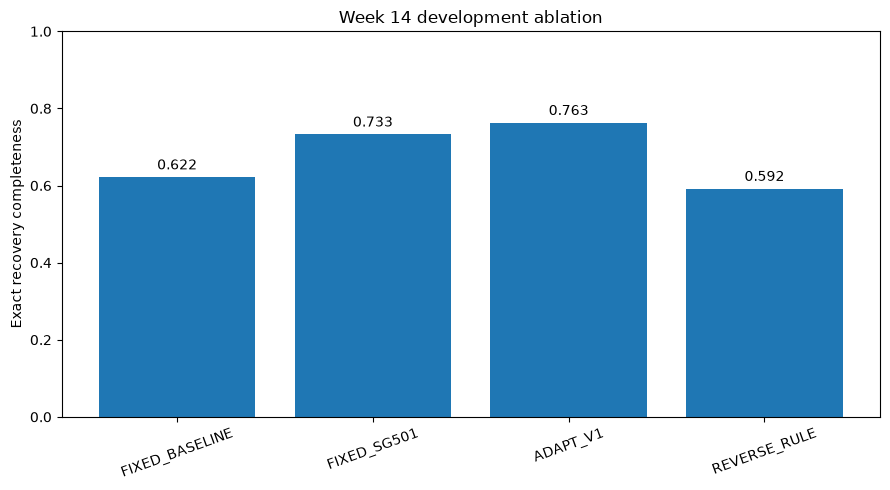

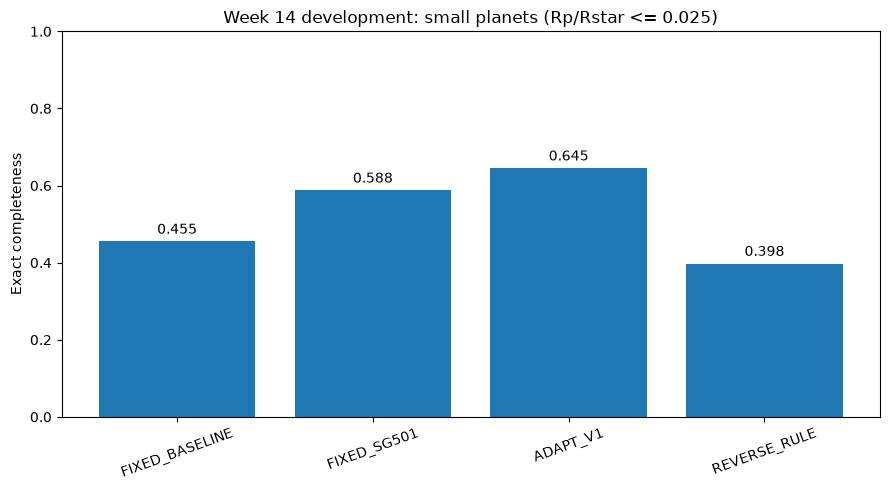


WEEK 14 / ADAPT-v1 DEVELOPMENT RESULTS

ADAPT-v1 HOST CHOICES


,control_id,candidate_name,robust_rms,adapt_v1_method
0,CONTROL-002,HD 102365,0.000101,BASELINE
1,CONTROL-001,18 Sco,0.000194,BASELINE
2,CONTROL-003,HD 76151,0.000239,SG_501
3,CONTROL-004,HD 30495,0.001261,SG_501
4,CONTROL-005,HD 20630,0.009572,SG_501



DEVELOPMENT ABLATION SUMMARY


,method,attempted,exact_recovered,exact_completeness,small_planet_attempted,small_planet_exact_recovered,small_planet_exact_completeness,median_depth_bias_exact,median_apparent_radius_bias_exact,median_small_planet_depth_bias_exact,median_small_planet_radius_bias_exact
0,FIXED_BASELINE,1000,622,0.622,400,182,0.4550,-0.084080,-0.042963,-0.083033,-0.042416
1,FIXED_SG501,1000,733,0.733,400,235,0.5875,-0.385444,-0.216064,-0.380215,-0.212736
2,ADAPT_V1,1000,763,0.763,400,258,0.6450,-0.181065,-0.095050,-0.155453,-0.081008
3,REVERSE_RULE,1000,592,0.592,400,159,0.3975,-0.308270,-0.168297,-0.402128,-0.226778



ADAPT-v1 VS BASELINE RECOVERY SWITCHES


...


CONTROL SUMMARY


,comparison_method,n_controls,median_control_sde,max_control_sde,median_control_depth
0,ADAPT_V1,5,13.891793,17.852602,0.000266
1,FIXED_BASELINE,5,34.695018,144.107001,0.000380
2,FIXED_SG501,5,13.891793,15.222251,0.000266



THRESHOLD ABLATION


,threshold,overall_exact_completeness,small_planet_exact_completeness,n_baseline_hosts,n_sg501_hosts
0,0.000000,0.733,0.5875,0,5
1,0.000140,0.733,0.5875,1,4
2,0.000215,0.763,0.6450,2,3
3,0.000549,0.733,0.5700,3,2
4,0.003475,0.666,0.4550,4,1
5,0.095723,0.622,0.4550,5,0



WEEK 15 PRIMARY DECLARATION
{
  "version": "W15_PRIMARY_V1",
  "primary_metric": "Exact-period recovery completeness for held-out injections with Rp/Rstar <= 0.025",
  "comparison": "ADAPT_V1 minus FIXED_BASELINE",
  "primary_effect": "difference in small-planet exact recovery completeness",
  "success_criterion": "ADAPT_V1 small-planet exact completeness is greater than FIXED_BASELINE on the frozen held-out test.",
  "secondary_metrics": [
    "overall exact completeness",
    "alias-aware completeness",
    "depth bias",
    "apparent radius-ratio bias",
    "no-injection control BLS SDE",
    "runtime"
  ],
  "control_guardrail": "Report paired control BLS SDE. Do not invent a post-hoc binary false-positive threshold.",
  "uncertainty": "Wilson intervals for completeness; host-aware resampling if bootstrap is used.",
  "retuning_after_heldout": false
}

✅ ADAPT-v1 DEFINED
✅ RULE USES ONLY ROBUST RMS
✅ NO INJECTION TRUTH USED
✅ DEVELOPMENT BENCHMARK COMPLETE
✅ FIXED BASELINE ABLATIO

In [29]:
# ============================================================
# WEEK 14
# ADAPT-v1
#
# Goal:
# Build and freeze one simple adaptive preprocessing rule
# using DEVELOPMENT DATA ONLY.
#
# Failure pattern targeted:
# preprocessing performance depends strongly on stellar
# variability.
#
# ADAPT-v1 rule:
#
#   if robust_rms <= 2.15e-4:
#       BASELINE
#   else:
#       SG_501
#
# IMPORTANT:
# - no injected truth is used to choose preprocessing
# - held-out hosts remain untouched
# - all tuning happens only on development hosts
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import os
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. REQUIRE FROZEN WEEK 12/13 STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CONFIG_DIR",

    "development_host_data",
    "development_hosts_df",
    "heldout_hosts_df",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:
    raise RuntimeError(
        "Required project state missing:\n"
        f"{missing}"
    )


# ------------------------------------------------------------
# Load corrected Week 12 table if not already in memory
# ------------------------------------------------------------

if "corrected_w12_df" in globals():

    W12_CANONICAL = (
        corrected_w12_df.copy()
    )

elif "week12_results_df" in globals():

    W12_CANONICAL = (
        week12_results_df.copy()
    )

else:

    candidate_paths = [

        RESULTS_DIR
        / "week12_preprocessing_bias"
        / "DET_detrending_results_corrected_radius.csv",

        RESULTS_DIR
        / "week12_preprocessing_bias"
        / "DET_detrending_results.csv",
    ]


    found_path = None

    for path in candidate_paths:

        if path.exists():
            found_path = path
            break


    if found_path is None:

        raise FileNotFoundError(
            "Could not find Week 12 results."
        )


    W12_CANONICAL = pd.read_csv(
        found_path
    )


assert len(
    W12_CANONICAL
) == 4000


# ------------------------------------------------------------
# Check held-out firewall
# ------------------------------------------------------------

assert (
    heldout_hosts_df[
        "bls_run"
    ] == False
).all()

assert (
    heldout_hosts_df[
        "injection_run"
    ] == False
).all()

assert (
    heldout_hosts_df[
        "used_for_tuning"
    ] == False
).all()


print("✅ Week 12 development table found.")
print("✅ 4000 paired method/case rows found.")
print("✅ Held-out firewall intact.")


# ============================================================
# 2. OUTPUT DIRECTORIES
# ============================================================

W14_RESULTS_DIR = (
    RESULTS_DIR
    / "week14_adapt_v1"
)

W14_FIGURES_DIR = (
    FIGURES_DIR
    / "week14_adapt_v1"
)

W14_CONFIG_DIR = (
    CONFIG_DIR
    / "week14_adapt_v1"
)

SRC_DIR = (
    PROJECT_ROOT
    / "src"
)


for folder in [
    W14_RESULTS_DIR,
    W14_FIGURES_DIR,
    W14_CONFIG_DIR,
    SRC_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. DEVELOPMENT HOST TABLE
# ============================================================

host_variability_df = (

    development_hosts_df[
        [
            "control_id",
            "candidate_name",
            "robust_rms",
        ]
    ]

    .copy()

    .sort_values(
        "robust_rms"
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nDEVELOPMENT HOST VARIABILITY"
)

display(
    host_variability_df
)


# ============================================================
# 4. ADAPT-v1 THRESHOLD
#
# Development-only threshold.
#
# This sits between:
#   18 Sco      ~1.94e-4
#   HD 76151    ~2.39e-4
#
# where the preferred preprocessing behavior changed.
# ============================================================

ADAPT_V1_RMS_THRESHOLD = (
    2.15e-4
)


def adapt_v1_choose_method(
    robust_rms,
):

    robust_rms = float(
        robust_rms
    )


    if (
        robust_rms
        <=
        ADAPT_V1_RMS_THRESHOLD
    ):

        return "BASELINE"

    else:

        return "SG_501"


print(
    "\nADAPT-v1 rule:"
)

print(
    f"robust_rms <= "
    f"{ADAPT_V1_RMS_THRESHOLD:.3e} "
    f"→ BASELINE"
)

print(
    f"robust_rms > "
    f"{ADAPT_V1_RMS_THRESHOLD:.3e} "
    f"→ SG_501"
)


# ============================================================
# 5. RECORD THE CHOICE FOR EACH DEVELOPMENT HOST
# ============================================================

host_choice_df = (
    host_variability_df.copy()
)


host_choice_df[
    "adapt_v1_method"
] = (

    host_choice_df[
        "robust_rms"
    ]

    .apply(
        adapt_v1_choose_method
    )
)


print(
    "\nADAPT-v1 DEVELOPMENT CHOICES"
)

display(
    host_choice_df
)


host_choice_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_development_host_choices.csv",

    index=False,
)


# ============================================================
# 6. BUILD ADAPT-v1 RESULT TABLE
#
# No searches need rerunning.
#
# We select the already-frozen BASELINE or SG_501 result
# based ONLY on the host's measured robust RMS.
# ============================================================

method_lookup = dict(

    zip(

        host_choice_df[
            "control_id"
        ],

        host_choice_df[
            "adapt_v1_method"
        ],
    )
)


adapt_rows = []


for _, row in W12_CANONICAL.iterrows():

    control_id = str(
        row[
            "control_id"
        ]
    )


    chosen_method = (
        method_lookup[
            control_id
        ]
    )


    if (
        row[
            "method"
        ]
        ==
        chosen_method
    ):

        new_row = (
            row.to_dict()
        )

        new_row[
            "source_method"
        ] = (
            chosen_method
        )

        new_row[
            "method"
        ] = (
            "ADAPT_V1"
        )

        adapt_rows.append(
            new_row
        )


adapt_v1_df = pd.DataFrame(
    adapt_rows
)


assert len(
    adapt_v1_df
) == 1000


assert (
    adapt_v1_df[
        "case_id"
    ].nunique()
    ==
    1000
)


print(
    "✅ ADAPT-v1 development table built:",
    len(
        adapt_v1_df
    ),
)


# ============================================================
# 7. FIXED METHOD TABLES
# ============================================================

baseline_df = (

    W12_CANONICAL[
        W12_CANONICAL[
            "method"
        ]
        ==
        "BASELINE"
    ]

    .copy()
)


sg501_df = (

    W12_CANONICAL[
        W12_CANONICAL[
            "method"
        ]
        ==
        "SG_501"
    ]

    .copy()
)


assert len(
    baseline_df
) == 1000

assert len(
    sg501_df
) == 1000


# ============================================================
# 8. REVERSE-RULE ABLATION
#
# Tests whether variability direction itself matters.
#
# Reverse rule:
# quiet -> SG_501
# noisy -> BASELINE
# ============================================================

def reverse_rule_choose_method(
    robust_rms,
):

    if (
        float(
            robust_rms
        )
        <=
        ADAPT_V1_RMS_THRESHOLD
    ):

        return "SG_501"

    else:

        return "BASELINE"


reverse_lookup = {

    row[
        "control_id"
    ]:
        reverse_rule_choose_method(
            row[
                "robust_rms"
            ]
        )

    for _, row
    in host_choice_df.iterrows()
}


reverse_rows = []


for _, row in W12_CANONICAL.iterrows():

    control_id = str(
        row[
            "control_id"
        ]
    )


    selected = (
        reverse_lookup[
            control_id
        ]
    )


    if (
        row[
            "method"
        ]
        ==
        selected
    ):

        new_row = (
            row.to_dict()
        )

        new_row[
            "source_method"
        ] = (
            selected
        )

        new_row[
            "method"
        ] = (
            "REVERSE_RULE"
        )

        reverse_rows.append(
            new_row
        )


reverse_rule_df = pd.DataFrame(
    reverse_rows
)


assert len(
    reverse_rule_df
) == 1000


# ============================================================
# 9. COMBINE ABLATION METHODS
#
# FIXED_BASELINE
# FIXED_SG501
# ADAPT_V1
# REVERSE_RULE
# ============================================================

baseline_ablation = (
    baseline_df.copy()
)

baseline_ablation[
    "method"
] = (
    "FIXED_BASELINE"
)


sg501_ablation = (
    sg501_df.copy()
)

sg501_ablation[
    "method"
] = (
    "FIXED_SG501"
)


ablation_df = pd.concat(

    [
        baseline_ablation,
        sg501_ablation,
        adapt_v1_df,
        reverse_rule_df,
    ],

    ignore_index=True,
)


assert len(
    ablation_df
) == 4000


# ============================================================
# 10. APPARENT-RADIUS COLUMN FALLBACK
# ============================================================

if (
    "apparent_radius_fractional_error"
    not in ablation_df.columns
):

    ablation_df[
        "true_apparent_rp_over_rstar"
    ] = np.sqrt(

        np.where(

            ablation_df[
                "true_model_depth"
            ]
            >
            0,

            ablation_df[
                "true_model_depth"
            ],

            np.nan,
        )
    )


    ablation_df[
        "recovered_apparent_rp_over_rstar"
    ] = np.sqrt(

        np.where(

            ablation_df[
                "found_depth"
            ]
            >
            0,

            ablation_df[
                "found_depth"
            ],

            np.nan,
        )
    )


    ablation_df[
        "apparent_radius_fractional_error"
    ] = (

        ablation_df[
            "recovered_apparent_rp_over_rstar"
        ]

        -

        ablation_df[
            "true_apparent_rp_over_rstar"
        ]

    ) / (

        ablation_df[
            "true_apparent_rp_over_rstar"
        ]
    )


# ============================================================
# 11. DEVELOPMENT ABLATION SUMMARY
# ============================================================

summary_rows = []


for (
    method_name,
    group
) in ablation_df.groupby(
    "method"
):

    exact = group[
        group[
            "primary_recovered"
        ]
        ==
        True
    ]


    small = group[
        group[
            "true_rp_over_rstar"
        ]
        <=
        0.025
    ]


    small_exact = small[
        small[
            "primary_recovered"
        ]
        ==
        True
    ]


    summary_rows.append({

        "method":
            method_name,

        "attempted":
            len(
                group
            ),

        "exact_recovered":
            int(
                group[
                    "primary_recovered"
                ].sum()
            ),

        "exact_completeness":
            group[
                "primary_recovered"
            ].mean(),

        "small_planet_attempted":
            len(
                small
            ),

        "small_planet_exact_recovered":
            int(
                small[
                    "primary_recovered"
                ].sum()
            ),

        "small_planet_exact_completeness":
            small[
                "primary_recovered"
            ].mean(),

        "median_depth_bias_exact":
            exact[
                "depth_fractional_error"
            ].median(),

        "median_apparent_radius_bias_exact":
            exact[
                "apparent_radius_fractional_error"
            ].median(),

        "median_small_planet_depth_bias_exact":
            small_exact[
                "depth_fractional_error"
            ].median(),

        "median_small_planet_radius_bias_exact":
            small_exact[
                "apparent_radius_fractional_error"
            ].median(),
    })


ablation_summary_df = pd.DataFrame(
    summary_rows
)


METHOD_ORDER_W14 = [
    "FIXED_BASELINE",
    "FIXED_SG501",
    "ADAPT_V1",
    "REVERSE_RULE",
]


ablation_summary_df[
    "_order"
] = (

    ablation_summary_df[
        "method"
    ]

    .map(
        {
            method: index

            for index, method
            in enumerate(
                METHOD_ORDER_W14
            )
        }
    )
)


ablation_summary_df = (

    ablation_summary_df

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nDEVELOPMENT ABLATION SUMMARY"
)

display(
    ablation_summary_df
)


# ============================================================
# 12. HOST-LEVEL ABLATION
# ============================================================

host_ablation_df = (

    ablation_df

    .groupby(
        [
            "method",
            "control_id",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count"
        ),

        exact_recovered=(
            "primary_recovered",
            "sum"
        ),

        exact_completeness=(
            "primary_recovered",
            "mean"
        ),
    )

    .reset_index()

    .merge(

        host_variability_df,

        on="control_id",

        how="left",
    )
)


print(
    "\nHOST-LEVEL ABLATION"
)

display(
    host_ablation_df
)


# ============================================================
# 13. LOAD WEEK 12 NO-INJECTION CONTROLS
# ============================================================

if (
    "week12_controls_df"
    in globals()
):

    w12_controls = (
        week12_controls_df.copy()
    )

else:

    control_path = (

        RESULTS_DIR
        / "week12_preprocessing_bias"
        / "W12_no_injection_controls.csv"
    )


    if not control_path.exists():

        raise FileNotFoundError(
            "Week 12 control table missing."
        )


    w12_controls = pd.read_csv(
        control_path
    )


# ============================================================
# 14. BUILD ADAPT-v1 CONTROL BEHAVIOR
#
# Same rule, same original robust RMS.
# ============================================================

adapt_control_rows = []


for _, row in w12_controls.iterrows():

    control_id = str(
        row[
            "control_id"
        ]
    )


    chosen_method = (
        method_lookup[
            control_id
        ]
    )


    if (
        row[
            "method"
        ]
        ==
        chosen_method
    ):

        new_row = (
            row.to_dict()
        )

        new_row[
            "source_method"
        ] = (
            chosen_method
        )

        new_row[
            "method"
        ] = (
            "ADAPT_V1"
        )

        adapt_control_rows.append(
            new_row
        )


adapt_controls_df = pd.DataFrame(
    adapt_control_rows
)


assert len(
    adapt_controls_df
) == 5


baseline_controls_df = (

    w12_controls[
        w12_controls[
            "method"
        ]
        ==
        "BASELINE"
    ]

    .copy()
)


sg501_controls_df = (

    w12_controls[
        w12_controls[
            "method"
        ]
        ==
        "SG_501"
    ]

    .copy()
)


# ============================================================
# 15. CONTROL SUMMARY
# ============================================================

control_compare_df = pd.concat(

    [
        baseline_controls_df.assign(
            comparison_method="FIXED_BASELINE"
        ),

        sg501_controls_df.assign(
            comparison_method="FIXED_SG501"
        ),

        adapt_controls_df.assign(
            comparison_method="ADAPT_V1"
        ),
    ],

    ignore_index=True,
)


control_summary_df = (

    control_compare_df

    .groupby(
        "comparison_method"
    )

    .agg(

        n_controls=(
            "control_id",
            "count"
        ),

        median_control_sde=(
            "detection_sde",
            "median"
        ),

        max_control_sde=(
            "detection_sde",
            "max"
        ),

        median_control_depth=(
            "found_depth",
            "median"
        ),
    )

    .reset_index()
)


print(
    "\nCONTROL BEHAVIOR"
)

display(
    control_summary_df
)


# ============================================================
# 16. DEVELOPMENT PAIRED SWITCHES
#
# ADAPT-v1 versus baseline.
# ============================================================

baseline_status = (

    baseline_ablation[
        [
            "case_id",
            "primary_recovered",
        ]
    ]

    .rename(
        columns={
            "primary_recovered":
                "baseline_recovered"
        }
    )
)


adapt_status = (

    adapt_v1_df[
        [
            "case_id",
            "primary_recovered",
        ]
    ]

    .rename(
        columns={
            "primary_recovered":
                "adapt_recovered"
        }
    )
)


paired_status = (
    baseline_status.merge(

        adapt_status,

        on="case_id",

        how="inner",
    )
)


adapt_switch_summary_df = pd.DataFrame(
    [
        {

            "baseline_miss_adapt_recovery":
                int(
                    (
                        (~paired_status[
                            "baseline_recovered"
                        ])
                        &
                        (
                            paired_status[
                                "adapt_recovered"
                            ]
                        )
                    ).sum()
                ),

            "baseline_recovery_adapt_miss":
                int(
                    (
                        (
                            paired_status[
                                "baseline_recovered"
                            ]
                        )
                        &
                        (~paired_status[
                            "adapt_recovered"
                        ])
                    ).sum()
                ),

            "both_recovered":
                int(
                    (
                        paired_status[
                            "baseline_recovered"
                        ]
                        &
                        paired_status[
                            "adapt_recovered"
                        ]
                    ).sum()
                ),

            "both_missed":
                int(
                    (
                        (~paired_status[
                            "baseline_recovered"
                        ])
                        &
                        (~paired_status[
                            "adapt_recovered"
                        ])
                    ).sum()
                ),
        }
    ]
)


print(
    "\nADAPT-v1 VS BASELINE SWITCHES"
)

display(
    adapt_switch_summary_df
)


# ============================================================
# 17. SIMPLE THRESHOLD ABLATION
#
# Show what would happen for every split between
# development hosts.
#
# This documents tuning rather than hiding it.
# ============================================================

sorted_rms = np.sort(
    host_variability_df[
        "robust_rms"
    ].to_numpy(
        dtype=float
    )
)


threshold_candidates = [
    0.0
]


for i in range(
    len(
        sorted_rms
    )
    -
    1
):

    threshold_candidates.append(

        float(
            np.sqrt(
                sorted_rms[
                    i
                ]
                *
                sorted_rms[
                    i + 1
                ]
            )
        )
    )


threshold_candidates.append(
    float(
        sorted_rms.max()
        *
        10
    )
)


threshold_rows = []


for threshold in threshold_candidates:

    choice_lookup = {

        row[
            "control_id"
        ]:
            (
                "BASELINE"

                if
                float(
                    row[
                        "robust_rms"
                    ]
                )
                <=
                threshold

                else
                "SG_501"
            )

        for _, row
        in host_variability_df.iterrows()
    }


    selected_rows = []


    for _, row in W12_CANONICAL.iterrows():

        cid = str(
            row[
                "control_id"
            ]
        )


        if (
            row[
                "method"
            ]
            ==
            choice_lookup[
                cid
            ]
        ):

            selected_rows.append(
                row
            )


    selected_df = pd.DataFrame(
        selected_rows
    )


    small_df = (

        selected_df[
            selected_df[
                "true_rp_over_rstar"
            ]
            <=
            0.025
        ]
    )


    threshold_rows.append({

        "threshold":
            threshold,

        "overall_exact_completeness":
            selected_df[
                "primary_recovered"
            ].mean(),

        "small_planet_exact_completeness":
            small_df[
                "primary_recovered"
            ].mean(),

        "n_baseline_hosts":
            sum(
                1

                for method
                in choice_lookup.values()

                if method
                ==
                "BASELINE"
            ),

        "n_sg501_hosts":
            sum(
                1

                for method
                in choice_lookup.values()

                if method
                ==
                "SG_501"
            ),
    })


threshold_ablation_df = pd.DataFrame(
    threshold_rows
)


print(
    "\nTHRESHOLD ABLATION"
)

display(
    threshold_ablation_df
)


# ============================================================
# 18. PREDECLARE WEEK 15 PRIMARY METRIC
#
# Small planets:
# Rp/Rstar <= 0.025
#
# Primary comparison:
# ADAPT-v1 vs frozen baseline exact recovery.
#
# Guardrails:
# control SDE and radius/depth bias remain secondary.
# ============================================================

WEEK15_PRIMARY_DECLARATION = {

    "version":
        "W15_PRIMARY_V1",

    "primary_metric":
        (
            "Exact-period recovery completeness "
            "for held-out injections with "
            "Rp/Rstar <= 0.025"
        ),

    "comparison":
        "ADAPT_V1 minus FIXED_BASELINE",

    "primary_effect":
        (
            "difference in small-planet exact "
            "recovery completeness"
        ),

    "success_criterion":
        (
            "ADAPT_V1 small-planet exact completeness "
            "is greater than FIXED_BASELINE on the "
            "frozen held-out test."
        ),

    "secondary_metrics": [

        "overall exact completeness",

        "alias-aware completeness",

        "depth bias",

        "apparent radius-ratio bias",

        "no-injection control BLS SDE",

        "runtime",
    ],

    "control_guardrail":
        (
            "Report paired control BLS SDE. "
            "Do not invent a post-hoc binary "
            "false-positive threshold."
        ),

    "uncertainty":
        (
            "Wilson intervals for completeness; "
            "host-aware resampling if bootstrap "
            "is used."
        ),

    "retuning_after_heldout":
        False,
}


# ============================================================
# 19. FREEZE WEEK 15 HELD-OUT DESIGN
#
# IMPORTANT:
# We define the plan now.
# We do NOT run it now.
#
# Proposed held-out grid:
#
# 3 held-out hosts
# × 4 periods
# × 5 radii
# × 10 repetitions
# = 600 unique injections
#
# Each case evaluated under:
#   BASELINE
#   ADAPT_V1
# ============================================================

WEEK15_HELDOUT_PLAN = {

    "version":
        "W15_HELDOUT_PLAN_V1",

    "heldout_hosts":
        heldout_hosts_df[
            "heldout_id"
        ].tolist(),

    "periods_days":
        [
            1.0,
            3.0,
            6.0,
            10.0,
        ],

    "rp_over_rstar":
        [
            0.015,
            0.025,
            0.040,
            0.060,
            0.090,
        ],

    "repetitions_per_cell_per_host":
        10,

    "unique_injections":
        600,

    "methods":
        [
            "FIXED_BASELINE",
            "ADAPT_V1",
        ],

    "recovery_protocol":
        "RECOVERY_V2",

    "primary_metric":
        WEEK15_PRIMARY_DECLARATION[
            "primary_metric"
        ],

    "success_criterion":
        WEEK15_PRIMARY_DECLARATION[
            "success_criterion"
        ],

    "retuning_allowed":
        False,
}


# ============================================================
# 20. WRITE ADAPT-v1 IMPLEMENTATION FILE
# ============================================================

preprocess_py = f'''
"""
ADAPT-v1
Frozen Week 14 adaptive preprocessing rule.

This function uses only measured host variability.
It does not use injected planet truth.
"""

ADAPT_V1_RMS_THRESHOLD = {ADAPT_V1_RMS_THRESHOLD!r}


def adapt_v1_choose_method(robust_rms):
    robust_rms = float(robust_rms)

    if robust_rms <= ADAPT_V1_RMS_THRESHOLD:
        return "BASELINE"

    return "SG_501"
'''


PREPROCESS_PATH = (
    SRC_DIR
    / "preprocess.py"
)


PREPROCESS_PATH.write_text(
    preprocess_py,
    encoding="utf-8",
)


# ============================================================
# 21. TEST ADAPT-v1 IMPLEMENTATION
# ============================================================

assert (
    adapt_v1_choose_method(
        1e-4
    )
    ==
    "BASELINE"
)

assert (
    adapt_v1_choose_method(
        2e-4
    )
    ==
    "BASELINE"
)

assert (
    adapt_v1_choose_method(
        3e-4
    )
    ==
    "SG_501"
)

assert (
    adapt_v1_choose_method(
        1e-2
    )
    ==
    "SG_501"
)


print(
    "✅ ADAPT-v1 unit tests passed."
)


# ============================================================
# 22. METHOD NOTE
# ============================================================

METHOD_NOTE = f"""
ADAPT-v1 METHOD NOTE
====================

Targeted failure pattern
------------------------
Weeks 11-12 showed strong host-dependent recovery.
Quiet hosts could perform very well without detrending,
while more variable hosts benefited substantially from
long-window Savitzky-Golay detrending.

Adaptive input
--------------
Robust RMS of the original development light curve.

No injected period, depth, radius, epoch, or recovery
outcome is available to the rule.

Frozen rule
-----------
If robust_rms <= {ADAPT_V1_RMS_THRESHOLD:.6g}:
    use BASELINE preprocessing
Else:
    use SG_501 preprocessing

Search method
-------------
Frozen BLS search and RECOVERY_V2.

Development tuning
------------------
The threshold was selected using development hosts only.
Held-out hosts were not opened or searched during tuning.

Ablations
---------
1. Fixed baseline
2. Fixed SG_501
3. ADAPT-v1
4. Reverse variability rule

Week 15 primary metric
----------------------
Exact-period recovery completeness for held-out
small-planet injections with Rp/Rstar <= 0.025.

Success criterion
-----------------
ADAPT-v1 must exceed fixed baseline on the frozen
held-out small-planet completeness metric.

No retuning is allowed after held-out results are opened.
"""


METHOD_NOTE_PATH = (

    W14_RESULTS_DIR
    / "ADAPT_V1_method_note.txt"
)


METHOD_NOTE_PATH.write_text(
    METHOD_NOTE,
    encoding="utf-8",
)


# ============================================================
# 23. SAVE ALL DEVELOPMENT TABLES
# ============================================================

adapt_v1_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_development_results.csv",

    index=False,
)


ablation_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_ablation_results.csv",

    index=False,
)


ablation_summary_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_ablation_summary.csv",

    index=False,
)


host_ablation_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_host_ablation.csv",

    index=False,
)


adapt_switch_summary_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_recovery_switches.csv",

    index=False,
)


control_summary_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_control_summary.csv",

    index=False,
)


threshold_ablation_df.to_csv(

    W14_RESULTS_DIR
    / "ADAPT_V1_threshold_ablation.csv",

    index=False,
)


# ============================================================
# 24. SAVE FROZEN CONFIGS
# ============================================================

ADAPT_V1_CONFIG = {

    "version":
        "ADAPT_V1",

    "adaptive_input":
        "robust_rms",

    "threshold":
        ADAPT_V1_RMS_THRESHOLD,

    "quiet_method":
        "BASELINE",

    "variable_method":
        "SG_501",

    "search_method":
        "BLS",

    "recovery_protocol":
        "RECOVERY_V2",

    "uses_injection_truth":
        False,

    "development_hosts_only":
        True,

    "heldout_hosts_used":
        False,
}


with open(

    W14_CONFIG_DIR
    / "ADAPT_V1_config.json",

    "w",

) as f:

    json.dump(
        ADAPT_V1_CONFIG,
        f,
        indent=2,
    )


with open(

    W14_CONFIG_DIR
    / "W15_PRIMARY_V1.json",

    "w",

) as f:

    json.dump(
        WEEK15_PRIMARY_DECLARATION,
        f,
        indent=2,
    )


with open(

    W14_CONFIG_DIR
    / "W15_HELDOUT_PLAN_V1.json",

    "w",

) as f:

    json.dump(
        WEEK15_HELDOUT_PLAN,
        f,
        indent=2,
    )


# ============================================================
# 25. CREATE FILE HASHES
#
# This gives us a lightweight freeze fingerprint.
# ============================================================

def sha256_file(
    path,
):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )

    return (
        h.hexdigest()
    )


PREPROCESS_HASH = (
    sha256_file(
        PREPROCESS_PATH
    )
)


CONFIG_HASH = (
    sha256_file(

        W14_CONFIG_DIR
        / "ADAPT_V1_config.json"
    )
)


# ============================================================
# 26. FREEZE MANIFEST
# ============================================================

FREEZE_MANIFEST = {

    "version":
        "ADAPT_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "threshold":
        ADAPT_V1_RMS_THRESHOLD,

    "input":
        "robust_rms",

    "quiet_method":
        "BASELINE",

    "variable_method":
        "SG_501",

    "search_method":
        "BLS",

    "recovery_protocol":
        "RECOVERY_V2",

    "preprocess_file":
        str(
            PREPROCESS_PATH
        ),

    "preprocess_sha256":
        PREPROCESS_HASH,

    "config_sha256":
        CONFIG_HASH,

    "primary_metric":
        WEEK15_PRIMARY_DECLARATION[
            "primary_metric"
        ],

    "success_criterion":
        WEEK15_PRIMARY_DECLARATION[
            "success_criterion"
        ],

    "heldout_plan":
        WEEK15_HELDOUT_PLAN,

    "heldout_hosts_used":
        False,

    "retuning_after_heldout":
        False,
}


with open(

    W14_CONFIG_DIR
    / "ADAPT_V1_FREEZE_MANIFEST.json",

    "w",

) as f:

    json.dump(
        FREEZE_MANIFEST,
        f,
        indent=2,
    )


# ============================================================
# 27. FIGURE — DEVELOPMENT COMPLETENESS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)


ax.bar(

    ablation_summary_df[
        "method"
    ],

    ablation_summary_df[
        "exact_completeness"
    ],
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Exact recovery completeness"
)


ax.set_title(
    "Week 14 development ablation"
)


for i, row in (
    ablation_summary_df.iterrows()
):

    ax.text(

        i,

        row[
            "exact_completeness"
        ]
        +
        0.02,

        f"{row['exact_completeness']:.3f}",

        ha="center",
    )


plt.xticks(
    rotation=20
)


fig.tight_layout()


fig.savefig(

    W14_FIGURES_DIR
    / "ADAPT_V1_ablation_completeness.png",

    dpi=220,
)


plt.show()


# ============================================================
# 28. FIGURE — SMALL PLANET COMPLETENESS
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)


ax.bar(

    ablation_summary_df[
        "method"
    ],

    ablation_summary_df[
        "small_planet_exact_completeness"
    ],
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Exact completeness"
)


ax.set_title(
    "Week 14 development: small planets (Rp/Rstar <= 0.025)"
)


for i, row in (
    ablation_summary_df.iterrows()
):

    ax.text(

        i,

        row[
            "small_planet_exact_completeness"
        ]
        +
        0.02,

        f"{row['small_planet_exact_completeness']:.3f}",

        ha="center",
    )


plt.xticks(
    rotation=20
)


fig.tight_layout()


fig.savefig(

    W14_FIGURES_DIR
    / "ADAPT_V1_small_planet_completeness.png",

    dpi=220,
)


plt.show()


# ============================================================
# 29. FINAL OUTPUT
# ============================================================

print()
print("=" * 72)
print("WEEK 14 / ADAPT-v1 DEVELOPMENT RESULTS")
print("=" * 72)


print(
    "\nADAPT-v1 HOST CHOICES"
)

display(
    host_choice_df
)


print(
    "\nDEVELOPMENT ABLATION SUMMARY"
)

display(
    ablation_summary_df
)


print(
    "\nADAPT-v1 VS BASELINE RECOVERY SWITCHES"
)

display(
    adapt_switch_summary_df
)


print(
    "\nCONTROL SUMMARY"
)

display(
    control_summary_df
)


print(
    "\nTHRESHOLD ABLATION"
)

display(
    threshold_ablation_df
)


print(
    "\nWEEK 15 PRIMARY DECLARATION"
)

print(
    json.dumps(
        WEEK15_PRIMARY_DECLARATION,
        indent=2,
    )
)


print()
print("=" * 72)
print("✅ ADAPT-v1 DEFINED")
print("✅ RULE USES ONLY ROBUST RMS")
print("✅ NO INJECTION TRUTH USED")
print("✅ DEVELOPMENT BENCHMARK COMPLETE")
print("✅ FIXED BASELINE ABLATION COMPLETE")
print("✅ FIXED SG_501 ABLATION COMPLETE")
print("✅ REVERSE-RULE ABLATION COMPLETE")
print("✅ CONTROL BEHAVIOR RECORDED")
print("✅ WEEK 15 PRIMARY METRIC PREDECLARED")
print("✅ WEEK 15 HELD-OUT PLAN PREDECLARED")
print("✅ src/preprocess.py WRITTEN")
print("✅ ADAPT-v1 CONFIG HASHED")
print("✅ HELD-OUT HOSTS REMAIN UNTOUCHED")
print("✅ ADAPT-v1 FROZEN")
print("=" * 72)

In [30]:
# ============================================================
# DIRECT MAST DOWNLOAD HELPER FOR HELD-OUT HOSTS
# Bypasses hanging Lightkurve download path
# ============================================================

from pathlib import Path
import requests
from astropy.io import fits
import numpy as np
import pandas as pd
from astroquery.mast import Observations

DIRECT_CACHE_DIR = (
    RESULTS_DIR
    / "week15_heldout"
    / "direct_mast_cache"
)

DIRECT_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def direct_spoc_download(
    target,
    sector,
    heldout_id,
):
    print(
        f"Searching MAST product for {target}, Sector {sector}..."
    )

    obs = Observations.query_criteria(
        target_name=target,
        obs_collection="TESS",
        sequence_number=int(sector),
        dataproduct_type="timeseries",
    )

    if len(obs) == 0:
        raise RuntimeError(
            f"No TESS observations found for {target}, Sector {sector}"
        )

    products = Observations.get_product_list(obs)

    products = products[
        np.char.find(
            products["productFilename"].astype(str),
            "-lc.fits"
        ) >= 0
    ]

    products = products[
        np.char.find(
            products["productFilename"].astype(str),
            "fast"
        ) >= 0
    ]

    if len(products) == 0:
        raise RuntimeError(
            f"No SPOC light-curve FITS product found for {target}, Sector {sector}"
        )

    # Prefer exact sector-matched LC product
    product = products[0]

    data_uri = str(
        product["dataURI"]
    )

    filename = str(
        product["productFilename"]
    )

    local_path = (
        DIRECT_CACHE_DIR
        / f"{heldout_id}_{filename}"
    )

    if not local_path.exists():

        url = (
            "https://mast.stsci.edu/api/v0.1/Download/file"
            f"?uri={data_uri}"
        )

        print(
            "Downloading directly from MAST..."
        )

        with requests.get(
            url,
            stream=True,
            timeout=(20, 120),
        ) as response:

            response.raise_for_status()

            total = int(
                response.headers.get(
                    "content-length",
                    0,
                )
            )

            downloaded = 0

            with open(
                local_path,
                "wb",
            ) as f:

                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):

                    if not chunk:
                        continue

                    f.write(
                        chunk
                    )

                    downloaded += len(
                        chunk
                    )

                    if total > 0:
                        pct = 100 * downloaded / total
                        print(
                            f"\rDownloaded {pct:5.1f}%",
                            end=""
                        )

        print()

        print(
            "✅ Direct MAST download complete:",
            local_path
        )

    else:

        print(
            "✅ Using locally cached direct MAST file:",
            local_path
        )

    # Validate FITS before using it
    with fits.open(
        local_path,
        memmap=False,
    ) as hdul:

        data = hdul[1].data

        time_values = np.asarray(
            data["TIME"],
            dtype=float,
        )

        # Prefer PDCSAP, same as earlier project logic
        if "PDCSAP_FLUX" in data.columns.names:

            flux_values = np.asarray(
                data["PDCSAP_FLUX"],
                dtype=float,
            )

        else:

            flux_values = np.asarray(
                data["SAP_FLUX"],
                dtype=float,
            )

        quality = np.asarray(
            data["QUALITY"],
            dtype=int,
        )

    good = (
        np.isfinite(time_values)
        &
        np.isfinite(flux_values)
        &
        (quality == 0)
    )

    time_values = time_values[
        good
    ]

    flux_values = flux_values[
        good
    ]

    flux_values = (
        flux_values
        /
        np.nanmedian(flux_values)
    )

    return {
        "time": time_values,
        "flux": flux_values,
    }


print("✅ Direct MAST helper ready.")

✅ Direct MAST helper ready.


✅ Network timeout: 120 seconds
✅ Network retry attempts: 5
✅ Required project state found.
✅ Frozen ADAPT-v1 config loaded.
✅ Frozen Week 15 metric loaded.
✅ Frozen held-out plan loaded.
✅ ADAPT-v1 source hash verified.
✅ ADAPT-v1 config hash verified.

FROZEN ADAPT-v1:
RMS <= 2.150e-04 → BASELINE
RMS >  2.150e-04 → SG_501
✅ Held-out opening event recorded.

Opening held-out host: HELDOUT-001 | HD 190406
   Searching MAST for TIC 275240386, Sector 54...
   MAST observation query TIC 275240386 [attempt 1/5]
   ⚠️ MAST observation query TIC 275240386 failed:
       ConnectionError(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')))
   Retrying in 5 seconds...
   MAST observation query TIC 275240386 [attempt 2/5]
   ✅ MAST observation query TIC 275240386 completed in 1.7 s
   MAST product list HD 190406 [attempt 1/5]
   ✅ MAST product list HD 190406 completed in 1.1 s
   Found 2 light-curve candidate(s).
       tess2022190063128-s0054

,heldout_id,candidate_name,tic_id,sector,stellar_mass_msun,stellar_radius_rsun,teff_kelvin,robust_rms,cadence_minutes,adapt_v1_method
0,HELDOUT-001,HD 190406,275240386,54,1.08,1.066600,5940.0,0.000226,2.000033,SG_501
1,HELDOUT-002,HD 38858,176521059,6,1.02,0.921079,5735.0,0.000125,1.999975,BASELINE
2,HELDOUT-003,HD 10307,327507922,18,1.06,1.184120,5870.0,0.000163,1.999964,BASELINE



ADAPT-v1 HELD-OUT CHOICES


,heldout_id,candidate_name,robust_rms,adapt_v1_method
0,HELDOUT-001,HD 190406,0.000226,SG_501
1,HELDOUT-002,HD 38858,0.000125,BASELINE
2,HELDOUT-003,HD 10307,0.000163,BASELINE



BUILDING HELD-OUT BLS GRIDS
HELDOUT-001 | points: 17887 | trial periods: 31923
HELDOUT-002 | points: 14677 | trial periods: 21995
HELDOUT-003 | points: 15154 | trial periods: 25953
✅ Held-out BLS grids ready.

✅ Frozen held-out design: 600 injections

CPU cores: 16
Week 15 workers: 4
Checkpoint chunk: 8

Already completed: 0 / 600
Pending: 600
Checkpoint: 8/600 cases | 16/1200 rows | elapsed 0.2 min
Checkpoint: 16/600 cases | 32/1200 rows | elapsed 0.4 min
Checkpoint: 24/600 cases | 48/1200 rows | elapsed 0.5 min
Checkpoint: 32/600 cases | 64/1200 rows | elapsed 0.6 min
Checkpoint: 40/600 cases | 80/1200 rows | elapsed 0.8 min
Checkpoint: 48/600 cases | 96/1200 rows | elapsed 0.9 min
Checkpoint: 56/600 cases | 112/1200 rows | elapsed 1.0 min
Checkpoint: 64/600 cases | 128/1200 rows | elapsed 1.2 min
Checkpoint: 72/600 cases | 144/1200 rows | elapsed 1.3 min
Checkpoint: 80/600 cases | 160/1200 rows | elapsed 1.4 min
Checkpoint: 88/600 cases | 176/1200 rows | elapsed 1.6 min
Checkpoint:

...

,method,recovery_category,count,fraction
0,ADAPT_V1,DOUBLE_ALIAS,2,0.003333
1,ADAPT_V1,EXACT,565,0.941667
2,ADAPT_V1,HALF_ALIAS,1,0.001667
3,ADAPT_V1,MISS,29,0.048333
4,ADAPT_V1,NEAR_MATCH,3,0.005000
5,FIXED_BASELINE,DOUBLE_ALIAS,3,0.005000
6,FIXED_BASELINE,EXACT,548,0.913333
7,FIXED_BASELINE,HALF_ALIAS,1,0.001667
8,FIXED_BASELINE,MISS,46,0.076667
9,FIXED_BASELINE,NEAR_MATCH,2,0.003333



HELD-OUT NO-INJECTION CONTROL BEHAVIOR


,heldout_id,method,source_preprocessing,found_period_days,detection_sde,found_depth
0,HELDOUT-001,FIXED_BASELINE,BASELINE,3.893129,23.666070,0.000167
1,HELDOUT-001,ADAPT_V1,SG_501,7.711316,12.611898,0.000122
2,HELDOUT-002,FIXED_BASELINE,BASELINE,6.916502,17.265519,0.000074
3,HELDOUT-002,ADAPT_V1,BASELINE,6.916502,17.265519,0.000074
4,HELDOUT-003,FIXED_BASELINE,BASELINE,11.429710,11.500354,0.000424
5,HELDOUT-003,ADAPT_V1,BASELINE,11.429710,11.500354,0.000424



HELD-OUT CONTROL SUMMARY


,method,n_hosts,median_control_sde,max_control_sde,median_control_depth
0,ADAPT_V1,3,12.611898,17.265519,0.000122
1,FIXED_BASELINE,3,17.265519,23.666070,0.000167


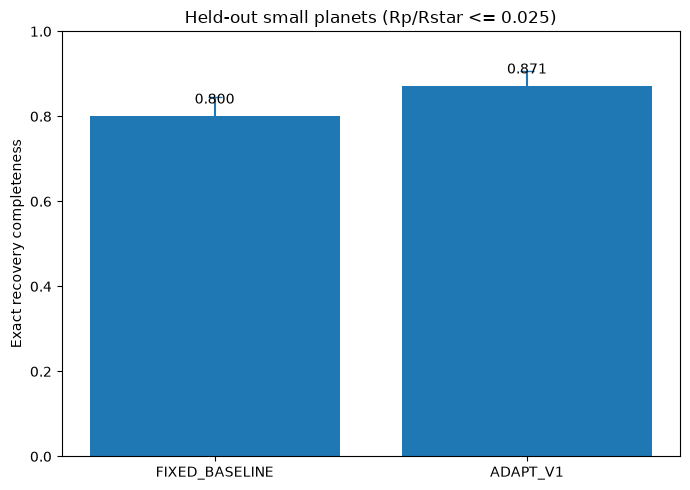

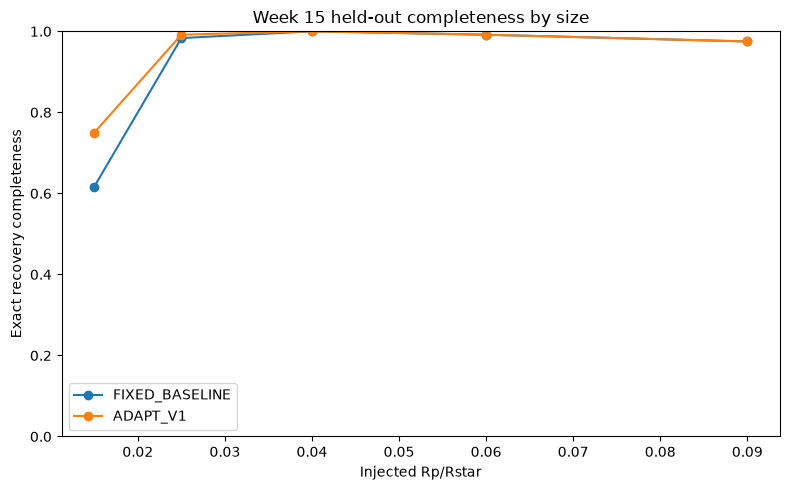


WEEK 15 FROZEN HELD-OUT RESULT

HELD-OUT HOST CHOICES


,heldout_id,candidate_name,robust_rms,adapt_v1_method
0,HELDOUT-001,HD 190406,0.000226,SG_501
1,HELDOUT-002,HD 38858,0.000125,BASELINE
2,HELDOUT-003,HD 10307,0.000163,BASELINE



PRIMARY METRIC


,method,attempted,exact_recovered,exact_completeness,ci95_low,ci95_high
0,ADAPT_V1,240,209,0.870833,0.822492,0.907490
1,FIXED_BASELINE,240,192,0.800000,0.744846,0.845702



PRIMARY PAIRED SWITCHES


...


ALIAS TABLE


,method,recovery_category,count,fraction
0,ADAPT_V1,DOUBLE_ALIAS,2,0.003333
1,ADAPT_V1,EXACT,565,0.941667
2,ADAPT_V1,HALF_ALIAS,1,0.001667
3,ADAPT_V1,MISS,29,0.048333
4,ADAPT_V1,NEAR_MATCH,3,0.005000
5,FIXED_BASELINE,DOUBLE_ALIAS,3,0.005000
6,FIXED_BASELINE,EXACT,548,0.913333
7,FIXED_BASELINE,HALF_ALIAS,1,0.001667
8,FIXED_BASELINE,MISS,46,0.076667
9,FIXED_BASELINE,NEAR_MATCH,2,0.003333



HELD-OUT CONTROL SUMMARY


,method,n_hosts,median_control_sde,max_control_sde,median_control_depth
0,ADAPT_V1,3,12.611898,17.265519,0.000122
1,FIXED_BASELINE,3,17.265519,23.666070,0.000167



✅ WEEK 15 HELD-OUT TEST COMPLETE
✅ ADAPT-v1 HASH VERIFIED
✅ PRIMARY METRIC PREDECLARED
✅ OLD + NEW SPOC LC FILENAMES SUPPORTED
✅ DIRECT MAST DOWNLOAD USED
✅ FITS FILES VALIDATED
✅ REMOTE DATA CACHED
✅ 600 HELD-OUT INJECTIONS
✅ 1200 PAIRED METHOD ROWS
✅ HOST-AWARE UNCERTAINTY REPORTED
✅ DEPTH / RADIUS BIAS REPORTED
✅ ALIAS BEHAVIOR REPORTED
✅ NO-INJECTION CONTROLS REPORTED
✅ FINAL RESULT FROZEN
✅ NO RETUNING ALLOWED


In [31]:
# ============================================================
# WEEK 15
# FINAL HELD-OUT EVALUATION
#
# DIRECT MAST DOWNLOAD
# ROBUST OLD/NEW SPOC FILE MATCHING
# LOCAL CACHE
# RETRY SUPPORT
# CHECKPOINT / RESUME
#
# FIXED_BASELINE vs FROZEN ADAPT_V1
#
# SCIENTIFIC PROTOCOL IS UNCHANGED
#
# 3 held-out hosts
# × 4 periods
# × 5 Rp/Rstar values
# × 10 repetitions
# = 600 unique injections
#
# Each injection evaluated with:
#   FIXED_BASELINE
#   ADAPT_V1
#
# Primary metric:
# exact-period recovery for Rp/Rstar <= 0.025
#
# NO RETUNING AFTER HELD-OUT OPENING.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json
import os
import socket
import time

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter
from joblib import Parallel, delayed

from astroquery.mast import Observations, Catalogs
from astropy.io import fits
from astropy.utils import data as astropy_data


# ============================================================
# 1. NETWORK SETTINGS
# ============================================================

NETWORK_TIMEOUT_SECONDS = 120
NETWORK_MAX_ATTEMPTS = 5


socket.setdefaulttimeout(
    NETWORK_TIMEOUT_SECONDS
)


try:
    astropy_data.conf.remote_timeout = (
        NETWORK_TIMEOUT_SECONDS
    )
except Exception:
    pass


try:
    Observations.TIMEOUT = (
        NETWORK_TIMEOUT_SECONDS
    )
except Exception:
    pass


try:
    Catalogs.TIMEOUT = (
        NETWORK_TIMEOUT_SECONDS
    )
except Exception:
    pass


print(
    "✅ Network timeout:",
    NETWORK_TIMEOUT_SECONDS,
    "seconds"
)

print(
    "✅ Network retry attempts:",
    NETWORK_MAX_ATTEMPTS
)


# ============================================================
# 2. REQUIRE PROJECT STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CONFIG_DIR",

    "heldout_hosts_df",

    "inject_transit",
    "blind_bls_search",
    "build_period_grid",
    "evaluate_recovery_v2",
    "BLS_CONFIG",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required project state missing:\n"
        f"{missing}\n\n"
        "Run the notebook through Week 14 first."
    )


print(
    "✅ Required project state found."
)


# ============================================================
# 3. LOAD FROZEN WEEK 14 FILES
# ============================================================

W14_CONFIG_DIR = (
    CONFIG_DIR
    / "week14_adapt_v1"
)


ADAPT_CONFIG_PATH = (
    W14_CONFIG_DIR
    / "ADAPT_V1_config.json"
)


ADAPT_FREEZE_PATH = (
    W14_CONFIG_DIR
    / "ADAPT_V1_FREEZE_MANIFEST.json"
)


W15_PRIMARY_PATH = (
    W14_CONFIG_DIR
    / "W15_PRIMARY_V1.json"
)


W15_PLAN_PATH = (
    W14_CONFIG_DIR
    / "W15_HELDOUT_PLAN_V1.json"
)


PREPROCESS_PATH = (
    PROJECT_ROOT
    / "src"
    / "preprocess.py"
)


for path in [
    ADAPT_CONFIG_PATH,
    ADAPT_FREEZE_PATH,
    W15_PRIMARY_PATH,
    W15_PLAN_PATH,
    PREPROCESS_PATH,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Frozen Week 14 file missing:\n{path}"
        )


with open(
    ADAPT_CONFIG_PATH,
    "r",
) as f:

    ADAPT_CONFIG = json.load(
        f
    )


with open(
    ADAPT_FREEZE_PATH,
    "r",
) as f:

    ADAPT_FREEZE = json.load(
        f
    )


with open(
    W15_PRIMARY_PATH,
    "r",
) as f:

    W15_PRIMARY = json.load(
        f
    )


with open(
    W15_PLAN_PATH,
    "r",
) as f:

    W15_PLAN = json.load(
        f
    )


print(
    "✅ Frozen ADAPT-v1 config loaded."
)

print(
    "✅ Frozen Week 15 metric loaded."
)

print(
    "✅ Frozen held-out plan loaded."
)


# ============================================================
# 4. VERIFY FROZEN HASHES
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):
            h.update(
                block
            )

    return h.hexdigest()


current_preprocess_hash = (
    sha256_file(
        PREPROCESS_PATH
    )
)


current_config_hash = (
    sha256_file(
        ADAPT_CONFIG_PATH
    )
)


if (
    current_preprocess_hash
    !=
    ADAPT_FREEZE[
        "preprocess_sha256"
    ]
):

    raise RuntimeError(
        "STOP: src/preprocess.py changed "
        "after ADAPT-v1 freeze."
    )


if (
    current_config_hash
    !=
    ADAPT_FREEZE[
        "config_sha256"
    ]
):

    raise RuntimeError(
        "STOP: ADAPT_V1_config.json changed "
        "after ADAPT-v1 freeze."
    )


print(
    "✅ ADAPT-v1 source hash verified."
)

print(
    "✅ ADAPT-v1 config hash verified."
)


# ============================================================
# 5. FROZEN ADAPT-v1 RULE
# ============================================================

ADAPT_V1_RMS_THRESHOLD = float(
    ADAPT_CONFIG[
        "threshold"
    ]
)


assert (
    ADAPT_CONFIG[
        "quiet_method"
    ]
    ==
    "BASELINE"
)


assert (
    ADAPT_CONFIG[
        "variable_method"
    ]
    ==
    "SG_501"
)


def adapt_v1_choose_method(
    robust_rms,
):

    robust_rms = float(
        robust_rms
    )


    if (
        robust_rms
        <=
        ADAPT_V1_RMS_THRESHOLD
    ):

        return "BASELINE"


    return "SG_501"


print()
print(
    "FROZEN ADAPT-v1:"
)

print(
    f"RMS <= {ADAPT_V1_RMS_THRESHOLD:.3e}"
    " → BASELINE"
)

print(
    f"RMS >  {ADAPT_V1_RMS_THRESHOLD:.3e}"
    " → SG_501"
)


# ============================================================
# 6. DIRECTORIES
# ============================================================

W15_RESULTS_DIR = (
    RESULTS_DIR
    / "week15_heldout"
)


W15_FIGURES_DIR = (
    FIGURES_DIR
    / "week15_heldout"
)


W15_CONFIG_DIR = (
    CONFIG_DIR
    / "week15_heldout"
)


DIRECT_CACHE_DIR = (
    W15_RESULTS_DIR
    / "direct_mast_cache"
)


for folder in [
    W15_RESULTS_DIR,
    W15_FIGURES_DIR,
    W15_CONFIG_DIR,
    DIRECT_CACHE_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 7. PRESERVE HELD-OUT OPEN EVENT
# ============================================================

HELDOUT_OPEN_EVENT_PATH = (
    W15_CONFIG_DIR
    / "HELDOUT_OPEN_EVENT.json"
)


if not HELDOUT_OPEN_EVENT_PATH.exists():

    open_event = {

        "event":
            "HELDOUT_OPENED",

        "opened_utc":
            datetime.now(
                timezone.utc
            ).isoformat(),

        "adapt_version":
            "ADAPT_V1",

        "adapt_threshold":
            ADAPT_V1_RMS_THRESHOLD,

        "preprocess_sha256":
            current_preprocess_hash,

        "config_sha256":
            current_config_hash,

        "primary_metric":
            W15_PRIMARY[
                "primary_metric"
            ],

        "success_criterion":
            W15_PRIMARY[
                "success_criterion"
            ],

        "retuning_allowed":
            False,
    }


    with open(
        HELDOUT_OPEN_EVENT_PATH,
        "w",
    ) as f:

        json.dump(
            open_event,
            f,
            indent=2,
        )


    print(
        "✅ Held-out opening event recorded."
    )

else:

    print(
        "✅ Existing held-out opening event preserved."
    )


# ============================================================
# 8. REMOTE RETRY HELPER
# ============================================================

def retry_remote_call(
    function,
    label,
    max_attempts=NETWORK_MAX_ATTEMPTS,
):

    last_error = None


    for attempt in range(
        1,
        max_attempts + 1,
    ):

        try:

            print(
                f"   {label} "
                f"[attempt {attempt}/{max_attempts}]"
            )


            start = time.perf_counter()


            result = function()


            elapsed = (
                time.perf_counter()
                -
                start
            )


            print(
                f"   ✅ {label} completed "
                f"in {elapsed:.1f} s"
            )


            return result


        except Exception as error:

            last_error = error


            print(
                f"   ⚠️ {label} failed:"
            )

            print(
                "      ",
                repr(
                    error
                )
            )


            if (
                attempt
                <
                max_attempts
            ):

                wait_seconds = min(
                    5
                    *
                    (
                        2
                        **
                        (
                            attempt
                            -
                            1
                        )
                    ),
                    40,
                )


                print(
                    f"   Retrying in "
                    f"{wait_seconds} seconds..."
                )


                time.sleep(
                    wait_seconds
                )


    raise RuntimeError(
        f"{label} failed after "
        f"{max_attempts} attempts."
    ) from last_error


# ============================================================
# 9. SAFE FLOAT
# ============================================================

def safe_float(value):

    try:

        value = float(
            value
        )

    except Exception:

        return np.nan


    if not np.isfinite(
        value
    ):

        return np.nan


    return value


# ============================================================
# 10. ROBUST RMS
# ============================================================

def w15_robust_sigma(values):

    values = np.asarray(
        values,
        dtype=float,
    )


    median = np.nanmedian(
        values
    )


    mad = np.nanmedian(

        np.abs(
            values
            -
            median
        )
    )


    return float(
        1.4826
        *
        mad
    )


# ============================================================
# 11. DIRECT SPOC / MAST DOWNLOAD
#
# IMPORTANT FIX:
# Accepts old and new LC filename conventions:
#
#   *_lc.fits
#   *-lc.fits
#
# More generally, any product ending in:
#
#   lc.fits
#
# while excluding TPF products.
# ============================================================

def direct_spoc_download(
    target,
    tic_id,
    sector,
    heldout_id,
):

    processed_cache = (

        DIRECT_CACHE_DIR
        /
        f"{heldout_id}_sector_{sector}_processed.npz"
    )


    # ========================================================
    # A. LOAD ALREADY-PROCESSED CACHE
    # ========================================================

    if processed_cache.exists():

        print(
            "   ✅ Loading cached processed light curve:",
            processed_cache.name
        )


        cached = np.load(
            processed_cache
        )


        return {

            "time":
                np.asarray(
                    cached[
                        "time"
                    ],
                    dtype=float,
                ),

            "flux":
                np.asarray(
                    cached[
                        "flux"
                    ],
                    dtype=float,
                ),
        }


    # ========================================================
    # B. QUERY MAST OBSERVATIONS
    # ========================================================

    print(
        f"   Searching MAST for TIC {tic_id}, "
        f"Sector {sector}..."
    )


    observations = retry_remote_call(

        lambda:
            Observations.query_criteria(

                obs_collection="TESS",

                target_name=str(
                    tic_id
                ),

                sequence_number=int(
                    sector
                ),
            ),

        label=(
            f"MAST observation query "
            f"TIC {tic_id}"
        ),
    )


    # ========================================================
    # C. FALLBACK SEARCH BY STAR NAME
    # ========================================================

    if len(
        observations
    ) == 0:

        observations = retry_remote_call(

            lambda:
                Observations.query_criteria(

                    obs_collection="TESS",

                    target_name=str(
                        target
                    ),

                    sequence_number=int(
                        sector
                    ),
                ),

            label=(
                f"MAST fallback query "
                f"{target}"
            ),
        )


    if len(
        observations
    ) == 0:

        raise RuntimeError(
            f"No TESS observations found for "
            f"{target} / TIC {tic_id}, "
            f"Sector {sector}."
        )


    # ========================================================
    # D. GET PRODUCT LIST
    # ========================================================

    products = retry_remote_call(

        lambda:
            Observations.get_product_list(
                observations
            ),

        label=(
            f"MAST product list "
            f"{target}"
        ),
    )


    # ========================================================
    # E. ROBUST LIGHT-CURVE PRODUCT MATCHING
    #
    # Handles:
    #   ..._lc.fits
    #   ...-lc.fits
    #   older/newer naming conventions
    #
    # Explicitly excludes TPF products.
    # ========================================================

    candidate_indices = []


    for i in range(
        len(
            products
        )
    ):

        filename = str(
            products[
                i
            ][
                "productFilename"
            ]
        )


        lower_name = (
            filename.lower()
        )


        subgroup = ""

        try:
            subgroup = str(
                products[
                    i
                ][
                    "productSubGroupDescription"
                ]
            ).upper()
        except Exception:
            pass


        # --------------------------------------------
        # Generic LC filename test
        # --------------------------------------------

        looks_like_lc = (
            lower_name.endswith(
                "lc.fits"
            )
        )


        # --------------------------------------------
        # Exclude target pixel files
        # --------------------------------------------

        looks_like_tpf = (
            "tp.fits"
            in lower_name
            or
            "tpf"
            in lower_name
            or
            subgroup
            ==
            "TP"
        )


        # --------------------------------------------
        # Product subgroup can also explicitly say LC
        # --------------------------------------------

        subgroup_is_lc = (
            subgroup
            ==
            "LC"
        )


        if (
            (
                looks_like_lc
                or
                subgroup_is_lc
            )
            and
            not looks_like_tpf
        ):

            candidate_indices.append(
                i
            )


    # ========================================================
    # F. IF NONE FOUND, PRINT AVAILABLE PRODUCTS
    # ========================================================

    if len(
        candidate_indices
    ) == 0:

        print()
        print(
            "Available MAST products:"
        )


        preview_rows = []


        for i in range(
            min(
                len(
                    products
                ),
                40,
            )
        ):

            filename = str(
                products[
                    i
                ][
                    "productFilename"
                ]
            )


            try:
                subgroup = str(
                    products[
                        i
                    ][
                        "productSubGroupDescription"
                    ]
                )
            except Exception:
                subgroup = ""


            preview_rows.append({

                "filename":
                    filename,

                "subgroup":
                    subgroup,
            })


        display(
            pd.DataFrame(
                preview_rows
            )
        )


        raise RuntimeError(
            f"No usable TESS light-curve FITS product "
            f"found for {target}, Sector {sector}."
        )


    # ========================================================
    # G. SHOW LC CANDIDATES
    # ========================================================

    print(
        f"   Found {len(candidate_indices)} "
        f"light-curve candidate(s)."
    )


    for i in candidate_indices[:10]:

        print(
            "      ",
            str(
                products[
                    i
                ][
                    "productFilename"
                ]
            )
        )


    # ========================================================
    # H. SELECT PREFERRED LC PRODUCT
    #
    # Preference:
    # 1. subgroup LC
    # 2. normal LC before FAST where both exist
    # 3. otherwise first valid LC product
    # ========================================================

    selected_index = (
        candidate_indices[
            0
        ]
    )


    standard_candidates = []


    for i in candidate_indices:

        filename = str(
            products[
                i
            ][
                "productFilename"
            ]
        ).lower()


        subgroup = ""

        try:

            subgroup = str(
                products[
                    i
                ][
                    "productSubGroupDescription"
                ]
            ).upper()

        except Exception:
            pass


        if (
            subgroup
            ==
            "LC"
        ):

            standard_candidates.append(
                i
            )


    if len(
        standard_candidates
    ) > 0:

        selected_index = (
            standard_candidates[
                0
            ]
        )


        # Prefer non-FAST LC if both exist
        for i in standard_candidates:

            filename = str(
                products[
                    i
                ][
                    "productFilename"
                ]
            ).lower()


            if (
                "fast"
                not in filename
            ):

                selected_index = i
                break


    else:

        # Prefer non-FAST LC where possible
        for i in candidate_indices:

            filename = str(
                products[
                    i
                ][
                    "productFilename"
                ]
            ).lower()


            if (
                "fast"
                not in filename
            ):

                selected_index = i
                break


    product = (
        products[
            selected_index
        ]
    )


    filename = str(
        product[
            "productFilename"
        ]
    )


    data_uri = str(
        product[
            "dataURI"
        ]
    )


    print(
        "   Selected product:"
    )

    print(
        "      ",
        filename
    )


    fits_path = (

        DIRECT_CACHE_DIR
        /
        f"{heldout_id}_{filename}"
    )


    partial_path = Path(
        str(
            fits_path
        )
        +
        ".part"
    )


    # ========================================================
    # I. VALIDATE EXISTING FITS CACHE
    # ========================================================

    if fits_path.exists():

        try:

            with fits.open(
                fits_path,
                memmap=False,
            ) as hdul:

                hdul.verify(
                    "exception"
                )


            print(
                "   ✅ Existing FITS cache validated:",
                fits_path.name
            )


        except Exception:

            print(
                "   ⚠️ Existing FITS cache is corrupt."
            )

            print(
                "   Removing corrupt file."
            )


            fits_path.unlink(
                missing_ok=True
            )


    # ========================================================
    # J. DIRECT DOWNLOAD
    # ========================================================

    if not fits_path.exists():

        download_url = (

            "https://mast.stsci.edu/"
            "api/v0.1/Download/file"
            f"?uri={data_uri}"
        )


        last_error = None


        for attempt in range(
            1,
            NETWORK_MAX_ATTEMPTS + 1,
        ):

            try:

                partial_path.unlink(
                    missing_ok=True
                )


                print(
                    f"   Direct FITS download "
                    f"[attempt {attempt}/"
                    f"{NETWORK_MAX_ATTEMPTS}]"
                )


                with requests.get(

                    download_url,

                    stream=True,

                    timeout=(
                        20,
                        NETWORK_TIMEOUT_SECONDS,
                    ),

                ) as response:

                    response.raise_for_status()


                    expected_bytes = int(

                        response.headers.get(
                            "content-length",
                            0,
                        )
                    )


                    downloaded_bytes = 0


                    with open(
                        partial_path,
                        "wb",
                    ) as file_handle:

                        for chunk in (
                            response.iter_content(
                                chunk_size=
                                1024 * 1024
                            )
                        ):

                            if not chunk:
                                continue


                            file_handle.write(
                                chunk
                            )


                            downloaded_bytes += (
                                len(
                                    chunk
                                )
                            )


                            if (
                                expected_bytes
                                >
                                0
                            ):

                                percentage = (

                                    100
                                    *
                                    downloaded_bytes
                                    /
                                    expected_bytes
                                )


                                print(

                                    f"\r      "
                                    f"{downloaded_bytes / 1e6:.1f} MB "
                                    f"/ "
                                    f"{expected_bytes / 1e6:.1f} MB "
                                    f"({percentage:.1f}%)",

                                    end="",
                                )


                            else:

                                print(

                                    f"\r      "
                                    f"{downloaded_bytes / 1e6:.1f} MB",

                                    end="",
                                )


                print()


                # --------------------------------------------
                # Check declared size if available
                # --------------------------------------------

                if (
                    expected_bytes
                    >
                    0
                    and
                    downloaded_bytes
                    !=
                    expected_bytes
                ):

                    raise RuntimeError(

                        f"Incomplete download: "
                        f"{downloaded_bytes} bytes received, "
                        f"{expected_bytes} expected."
                    )


                # --------------------------------------------
                # Validate FITS before accepting
                # --------------------------------------------

                with fits.open(
                    partial_path,
                    memmap=False,
                ) as hdul:

                    hdul.verify(
                        "exception"
                    )


                partial_path.replace(
                    fits_path
                )


                print(
                    "   ✅ Direct MAST FITS downloaded "
                    "and validated."
                )


                break


            except Exception as error:

                last_error = error


                print()

                print(
                    "   ⚠️ Direct FITS download failed:"
                )

                print(
                    "      ",
                    repr(
                        error
                    )
                )


                partial_path.unlink(
                    missing_ok=True
                )


                if (
                    attempt
                    <
                    NETWORK_MAX_ATTEMPTS
                ):

                    wait_seconds = min(
                        5
                        *
                        (
                            2
                            **
                            (
                                attempt
                                -
                                1
                            )
                        ),
                        40,
                    )


                    print(
                        f"   Retrying in "
                        f"{wait_seconds} seconds..."
                    )


                    time.sleep(
                        wait_seconds
                    )


        else:

            raise RuntimeError(
                f"Direct MAST FITS download failed "
                f"after {NETWORK_MAX_ATTEMPTS} attempts."
            ) from last_error


    # ========================================================
    # K. READ FITS
    # ========================================================

    with fits.open(
        fits_path,
        memmap=False,
    ) as hdul:

        data = (
            hdul[
                1
            ].data
        )


        column_names = list(
            data.columns.names
        )


        time_values = np.asarray(
            data[
                "TIME"
            ],
            dtype=float,
        )


        # --------------------------------------------
        # Preserve project convention:
        # PDCSAP preferred
        # --------------------------------------------

        if (
            "PDCSAP_FLUX"
            in column_names
        ):

            flux_values = np.asarray(
                data[
                    "PDCSAP_FLUX"
                ],
                dtype=float,
            )

            flux_source = (
                "PDCSAP_FLUX"
            )


        elif (
            "SAP_FLUX"
            in column_names
        ):

            flux_values = np.asarray(
                data[
                    "SAP_FLUX"
                ],
                dtype=float,
            )

            flux_source = (
                "SAP_FLUX"
            )


        else:

            raise RuntimeError(
                f"{filename} has neither "
                f"PDCSAP_FLUX nor SAP_FLUX."
            )


        if (
            "QUALITY"
            in column_names
        ):

            quality = np.asarray(
                data[
                    "QUALITY"
                ],
                dtype=int,
            )


        else:

            quality = np.zeros(
                len(
                    time_values
                ),
                dtype=int,
            )


    # ========================================================
    # L. QUALITY == 0 + FINITE VALUES
    # ========================================================

    good = (

        np.isfinite(
            time_values
        )

        &

        np.isfinite(
            flux_values
        )

        &

        (
            quality
            ==
            0
        )
    )


    time_values = (
        time_values[
            good
        ]
    )


    flux_values = (
        flux_values[
            good
        ]
    )


    if (
        len(
            time_values
        )
        <
        100
    ):

        raise RuntimeError(
            f"Too few valid cadences for {target}: "
            f"{len(time_values)}"
        )


    # ========================================================
    # M. MEDIAN NORMALIZATION
    # ========================================================

    median_flux = np.nanmedian(
        flux_values
    )


    if (
        not np.isfinite(
            median_flux
        )
        or
        median_flux
        ==
        0
    ):

        raise RuntimeError(
            f"Invalid median flux for {target}."
        )


    flux_values = (
        flux_values
        /
        median_flux
    )


    # ========================================================
    # N. SAVE PROCESSED CACHE
    # ========================================================

    np.savez_compressed(

        processed_cache,

        time=time_values,

        flux=flux_values,
    )


    print(
        "   ✅ Processed light curve cached:",
        processed_cache.name
    )


    print(
        "   Flux source:",
        flux_source
    )


    print(
        "   Good cadences:",
        len(
            time_values
        )
    )


    return {

        "time":
            time_values,

        "flux":
            flux_values,
    }


# ============================================================
# 12. TIC METADATA CACHE
# ============================================================

def get_tic_metadata(
    heldout_id,
    tic_id,
):

    metadata_path = (

        DIRECT_CACHE_DIR
        /
        f"{heldout_id}_TIC_{tic_id}.json"
    )


    if metadata_path.exists():

        print(
            "   ✅ Loading cached TIC metadata."
        )


        with open(
            metadata_path,
            "r",
        ) as f:

            return json.load(
                f
            )


    tic_table = retry_remote_call(

        lambda:
            Catalogs.query_criteria(

                catalog="TIC",

                ID=int(
                    tic_id
                ),
            ),

        label=(
            f"TIC metadata query "
            f"{tic_id}"
        ),
    )


    if len(
        tic_table
    ) == 0:

        raise RuntimeError(
            f"No TIC metadata returned "
            f"for TIC {tic_id}."
        )


    row = (
        tic_table[
            0
        ]
    )


    metadata = {

        "tic_id":
            int(
                tic_id
            ),

        "stellar_mass_msun":
            safe_float(
                row[
                    "mass"
                ]
            ),

        "stellar_radius_rsun":
            safe_float(
                row[
                    "rad"
                ]
            ),

        "teff_kelvin":
            safe_float(
                row[
                    "Teff"
                ]
            ),
    }


    if (
        not np.isfinite(
            metadata[
                "stellar_mass_msun"
            ]
        )
    ):

        raise RuntimeError(
            f"TIC {tic_id}: missing stellar mass."
        )


    if (
        not np.isfinite(
            metadata[
                "stellar_radius_rsun"
            ]
        )
    ):

        raise RuntimeError(
            f"TIC {tic_id}: missing stellar radius."
        )


    with open(
        metadata_path,
        "w",
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2,
        )


    print(
        "   ✅ TIC metadata cached."
    )


    return metadata


# ============================================================
# 13. OPEN THE THREE HELD-OUT HOSTS
# ============================================================

heldout_host_data = {}

heldout_metadata_rows = []


for _, row in (
    heldout_hosts_df.iterrows()
):

    heldout_id = str(
        row[
            "heldout_id"
        ]
    )


    target = str(
        row[
            "candidate_name"
        ]
    )


    tic_id = int(
        row[
            "tic_id"
        ]
    )


    sector = int(
        row[
            "sector"
        ]
    )


    print()
    print("=" * 72)

    print(
        "Opening held-out host:",
        heldout_id,
        "|",
        target
    )

    print("=" * 72)


    host = direct_spoc_download(

        target=target,

        tic_id=tic_id,

        sector=sector,

        heldout_id=heldout_id,
    )


    tic_metadata = get_tic_metadata(

        heldout_id=heldout_id,

        tic_id=tic_id,
    )


    robust_rms = w15_robust_sigma(

        host[
            "flux"
        ]

        -

        np.nanmedian(
            host[
                "flux"
            ]
        )
    )


    cadence_minutes = float(

        np.nanmedian(
            np.diff(
                host[
                    "time"
                ]
            )
        )

        *
        1440
    )


    adapt_method = (
        adapt_v1_choose_method(
            robust_rms
        )
    )


    host.update({

        "heldout_id":
            heldout_id,

        "candidate_name":
            target,

        "tic_id":
            tic_id,

        "sector":
            sector,

        "stellar_mass_msun":
            tic_metadata[
                "stellar_mass_msun"
            ],

        "stellar_radius_rsun":
            tic_metadata[
                "stellar_radius_rsun"
            ],

        "teff_kelvin":
            tic_metadata[
                "teff_kelvin"
            ],

        "robust_rms":
            robust_rms,

        "cadence_minutes":
            cadence_minutes,

        "adapt_v1_method":
            adapt_method,
    })


    heldout_host_data[
        heldout_id
    ] = host


    heldout_metadata_rows.append({

        "heldout_id":
            heldout_id,

        "candidate_name":
            target,

        "tic_id":
            tic_id,

        "sector":
            sector,

        "stellar_mass_msun":
            host[
                "stellar_mass_msun"
            ],

        "stellar_radius_rsun":
            host[
                "stellar_radius_rsun"
            ],

        "teff_kelvin":
            host[
                "teff_kelvin"
            ],

        "robust_rms":
            robust_rms,

        "cadence_minutes":
            cadence_minutes,

        "adapt_v1_method":
            adapt_method,
    })


heldout_metadata_df = pd.DataFrame(
    heldout_metadata_rows
)


print()
print(
    "HELD-OUT HOST MEASUREMENTS"
)

display(
    heldout_metadata_df
)


heldout_metadata_df.to_csv(

    W15_RESULTS_DIR
    / "W15_heldout_host_metadata.csv",

    index=False,
)


print()
print(
    "ADAPT-v1 HELD-OUT CHOICES"
)

display(

    heldout_metadata_df[
        [
            "heldout_id",
            "candidate_name",
            "robust_rms",
            "adapt_v1_method",
        ]
    ]
)


# ============================================================
# 14. BUILD BLS PERIOD GRIDS
# ============================================================

heldout_bls_grids = {}


print()
print(
    "BUILDING HELD-OUT BLS GRIDS"
)


for (
    heldout_id,
    host
) in heldout_host_data.items():

    periods = (
        build_period_grid(

            host[
                "time"
            ],

            host[
                "flux"
            ],

            BLS_CONFIG,
        )
    )


    heldout_bls_grids[
        heldout_id
    ] = periods


    print(

        heldout_id,

        "| points:",

        len(
            host[
                "time"
            ]
        ),

        "| trial periods:",

        len(
            periods
        ),
    )


print(
    "✅ Held-out BLS grids ready."
)


# ============================================================
# 15. FROZEN PREPROCESSING
# ============================================================

def w15_preprocess(
    time_values,
    flux_values,
    method_name,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )


    f = np.asarray(
        flux_values,
        dtype=float,
    )


    valid = (

        np.isfinite(
            t
        )

        &

        np.isfinite(
            f
        )
    )


    t = t[
        valid
    ]


    f = f[
        valid
    ]


    if (
        method_name
        ==
        "BASELINE"
    ):

        return (
            t,
            f,
        )


    if (
        method_name
        !=
        "SG_501"
    ):

        raise ValueError(
            f"Unknown frozen preprocessing: "
            f"{method_name}"
        )


    window = 501
    polyorder = 2


    window = min(
        window,
        len(
            f
        )
        -
        1
    )


    if (
        window
        %
        2
        ==
        0
    ):

        window -= 1


    minimum_window = (
        polyorder
        +
        3
    )


    if (
        minimum_window
        %
        2
        ==
        0
    ):

        minimum_window += 1


    window = max(
        window,
        minimum_window
    )


    if (
        window
        >=
        len(
            f
        )
    ):

        window = (
            len(
                f
            )
            -
            1
        )


        if (
            window
            %
            2
            ==
            0
        ):

            window -= 1


    trend = savgol_filter(

        f,

        window_length=window,

        polyorder=polyorder,
    )


    valid_trend = (

        np.isfinite(
            trend
        )

        &

        (
            trend
            !=
            0
        )
    )


    detrended = np.full_like(
        f,
        np.nan,
        dtype=float,
    )


    detrended[
        valid_trend
    ] = (

        f[
            valid_trend
        ]

        /

        trend[
            valid_trend
        ]
    )


    finite = (

        np.isfinite(
            t
        )

        &

        np.isfinite(
            detrended
        )
    )


    return (

        t[
            finite
        ],

        detrended[
            finite
        ],
    )


# ============================================================
# 16. TRANSIT INJECTION
# ============================================================

def w15_inject(
    host,
    period_days,
    epoch,
    rp_rs,
    impact_parameter,
):

    return inject_transit(

        host[
            "time"
        ],

        host[
            "flux"
        ],

        float(
            period_days
        ),

        float(
            epoch
        ),

        float(
            rp_rs
        ),

        float(
            host[
                "stellar_mass_msun"
            ]
        ),

        float(
            host[
                "stellar_radius_rsun"
            ]
        ),

        float(
            impact_parameter
        ),

        7,
    )


# ============================================================
# 17. TRUE DEPTH HELPER
# ============================================================

def get_truth_depth(truth):

    for key in [
        "model_depth",
        "true_model_depth",
        "depth",
    ]:

        if key in truth:

            value = safe_float(
                truth[
                    key
                ]
            )


            if (
                np.isfinite(
                    value
                )
                and
                value
                >
                0
            ):

                return value


    return np.nan


# ============================================================
# 18. DEPTH -> APPARENT Rp/Rstar
# ============================================================

def depth_to_apparent_rprs(
    depth,
):

    depth = safe_float(
        depth
    )


    if (
        not np.isfinite(
            depth
        )
        or
        depth
        <=
        0
    ):

        return np.nan


    return float(
        np.sqrt(
            depth
        )
    )


# ============================================================
# 19. FROZEN 600-CASE DESIGN
# ============================================================

W15_PERIODS = [
    1.0,
    3.0,
    6.0,
    10.0,
]


W15_RPRS = [
    0.015,
    0.025,
    0.040,
    0.060,
    0.090,
]


W15_REPEATS = 10


design_rows = []

case_number = 0

seed = 900000


for heldout_id in (
    heldout_host_data.keys()
):

    for period_days in (
        W15_PERIODS
    ):

        for rp_rs in (
            W15_RPRS
        ):

            for repetition in range(
                1,
                W15_REPEATS + 1,
            ):

                case_number += 1

                seed += 1


                design_rows.append({

                    "case_id":
                        f"W15-{case_number:05d}",

                    "heldout_id":
                        heldout_id,

                    "true_period_days":
                        float(
                            period_days
                        ),

                    "rp_over_rstar":
                        float(
                            rp_rs
                        ),

                    "repetition":
                        int(
                            repetition
                        ),

                    "seed":
                        int(
                            seed
                        ),
                })


week15_design_df = pd.DataFrame(
    design_rows
)


assert len(
    week15_design_df
) == 600


assert (
    week15_design_df[
        "case_id"
    ].nunique()
    ==
    600
)


week15_design_df.to_csv(

    W15_RESULTS_DIR
    / "W15_heldout_injection_design.csv",

    index=False,
)


print()
print(
    "✅ Frozen held-out design:",
    len(
        week15_design_df
    ),
    "injections"
)


# ============================================================
# 20. SINGLE CASE WORKER
# ============================================================

def run_week15_case(case):

    case_start = (
        time.perf_counter()
    )


    case_id = str(
        case[
            "case_id"
        ]
    )


    heldout_id = str(
        case[
            "heldout_id"
        ]
    )


    true_period = float(
        case[
            "true_period_days"
        ]
    )


    true_rprs = float(
        case[
            "rp_over_rstar"
        ]
    )


    seed = int(
        case[
            "seed"
        ]
    )


    try:

        host = (
            heldout_host_data[
                heldout_id
            ]
        )


        rng = (
            np.random.default_rng(
                seed
            )
        )


        impact_parameter = float(

            rng.uniform(
                0,
                0.7,
            )
        )


        true_epoch = float(

            np.nanmin(
                host[
                    "time"
                ]
            )

            +

            rng.uniform(
                0,
                true_period,
            )
        )


        injected_flux, truth = (
            w15_inject(

                host,

                true_period,

                true_epoch,

                true_rprs,

                impact_parameter,
            )
        )


        true_depth = (
            get_truth_depth(
                truth
            )
        )


        true_apparent_rprs = (
            depth_to_apparent_rprs(
                true_depth
            )
        )


        # ====================================================
        # BASELINE
        # ====================================================

        base_t, base_f = (
            w15_preprocess(

                host[
                    "time"
                ],

                injected_flux,

                "BASELINE",
            )
        )


        start = (
            time.perf_counter()
        )


        base_result = (
            blind_bls_search(

                base_t,

                base_f,

                period_grid=
                    heldout_bls_grids[
                        heldout_id
                    ],

                config=BLS_CONFIG,
            )
        )


        base_runtime = (

            time.perf_counter()
            -
            start
        )


        base_eval = (
            evaluate_recovery_v2(

                true_period=
                    true_period,

                found_period=
                    base_result[
                        "found_period_days"
                    ],
            )
        )


        base_depth = (
            base_result.get(
                "found_depth",
                np.nan,
            )
        )


        base_rprs = (
            depth_to_apparent_rprs(
                base_depth
            )
        )


        if (
            np.isfinite(
                true_depth
            )
            and
            true_depth
            >
            0
            and
            np.isfinite(
                base_depth
            )
        ):

            base_depth_error = (

                base_depth
                -
                true_depth

            ) / true_depth

        else:

            base_depth_error = np.nan


        if (
            np.isfinite(
                true_apparent_rprs
            )
            and
            true_apparent_rprs
            >
            0
            and
            np.isfinite(
                base_rprs
            )
        ):

            base_radius_error = (

                base_rprs
                -
                true_apparent_rprs

            ) / true_apparent_rprs

        else:

            base_radius_error = np.nan


        baseline_row = {

            "case_id":
                case_id,

            "heldout_id":
                heldout_id,

            "method":
                "FIXED_BASELINE",

            "source_preprocessing":
                "BASELINE",

            "seed":
                seed,

            "true_period_days":
                true_period,

            "true_rp_over_rstar":
                true_rprs,

            "true_model_depth":
                true_depth,

            "true_apparent_rp_over_rstar":
                true_apparent_rprs,

            "true_epoch_btjd":
                true_epoch,

            "impact_parameter":
                impact_parameter,

            "host_robust_rms":
                host[
                    "robust_rms"
                ],

            "found_period_days":
                base_result.get(
                    "found_period_days",
                    np.nan,
                ),

            "found_epoch_btjd":
                base_result.get(
                    "found_epoch_btjd",
                    np.nan,
                ),

            "found_depth":
                base_depth,

            "recovered_apparent_rp_over_rstar":
                base_rprs,

            "depth_fractional_error":
                base_depth_error,

            "apparent_radius_fractional_error":
                base_radius_error,

            "detection_sde":
                base_result.get(
                    "detection_sde",
                    np.nan,
                ),

            "bls_power":
                base_result.get(
                    "bls_power",
                    np.nan,
                ),

            "recovery_category":
                base_eval[
                    "category"
                ],

            "primary_recovered":
                base_eval[
                    "primary_recovered"
                ],

            "alias_aware_recovered":
                base_eval[
                    "alias_aware_recovered"
                ],

            "runtime_seconds":
                base_runtime,

            "status":
                "SUCCESS",
        }


        # ====================================================
        # ADAPT-v1
        # ====================================================

        adapt_preprocessing = (
            host[
                "adapt_v1_method"
            ]
        )


        if (
            adapt_preprocessing
            ==
            "BASELINE"
        ):

            adapt_row = (
                baseline_row.copy()
            )


            adapt_row[
                "method"
            ] = "ADAPT_V1"


            adapt_row[
                "source_preprocessing"
            ] = "BASELINE"


        else:

            adapt_t, adapt_f = (
                w15_preprocess(

                    host[
                        "time"
                    ],

                    injected_flux,

                    "SG_501",
                )
            )


            start = (
                time.perf_counter()
            )


            adapt_result = (
                blind_bls_search(

                    adapt_t,

                    adapt_f,

                    period_grid=
                        heldout_bls_grids[
                            heldout_id
                        ],

                    config=BLS_CONFIG,
                )
            )


            adapt_runtime = (

                time.perf_counter()
                -
                start
            )


            adapt_eval = (
                evaluate_recovery_v2(

                    true_period=
                        true_period,

                    found_period=
                        adapt_result[
                            "found_period_days"
                        ],
                )
            )


            adapt_depth = (
                adapt_result.get(
                    "found_depth",
                    np.nan,
                )
            )


            adapt_rprs = (
                depth_to_apparent_rprs(
                    adapt_depth
                )
            )


            if (
                np.isfinite(
                    true_depth
                )
                and
                true_depth
                >
                0
                and
                np.isfinite(
                    adapt_depth
                )
            ):

                adapt_depth_error = (

                    adapt_depth
                    -
                    true_depth

                ) / true_depth

            else:

                adapt_depth_error = np.nan


            if (
                np.isfinite(
                    true_apparent_rprs
                )
                and
                true_apparent_rprs
                >
                0
                and
                np.isfinite(
                    adapt_rprs
                )
            ):

                adapt_radius_error = (

                    adapt_rprs
                    -
                    true_apparent_rprs

                ) / true_apparent_rprs

            else:

                adapt_radius_error = np.nan


            adapt_row = {

                "case_id":
                    case_id,

                "heldout_id":
                    heldout_id,

                "method":
                    "ADAPT_V1",

                "source_preprocessing":
                    "SG_501",

                "seed":
                    seed,

                "true_period_days":
                    true_period,

                "true_rp_over_rstar":
                    true_rprs,

                "true_model_depth":
                    true_depth,

                "true_apparent_rp_over_rstar":
                    true_apparent_rprs,

                "true_epoch_btjd":
                    true_epoch,

                "impact_parameter":
                    impact_parameter,

                "host_robust_rms":
                    host[
                        "robust_rms"
                    ],

                "found_period_days":
                    adapt_result.get(
                        "found_period_days",
                        np.nan,
                    ),

                "found_epoch_btjd":
                    adapt_result.get(
                        "found_epoch_btjd",
                        np.nan,
                    ),

                "found_depth":
                    adapt_depth,

                "recovered_apparent_rp_over_rstar":
                    adapt_rprs,

                "depth_fractional_error":
                    adapt_depth_error,

                "apparent_radius_fractional_error":
                    adapt_radius_error,

                "detection_sde":
                    adapt_result.get(
                        "detection_sde",
                        np.nan,
                    ),

                "bls_power":
                    adapt_result.get(
                        "bls_power",
                        np.nan,
                    ),

                "recovery_category":
                    adapt_eval[
                        "category"
                    ],

                "primary_recovered":
                    adapt_eval[
                        "primary_recovered"
                    ],

                "alias_aware_recovered":
                    adapt_eval[
                        "alias_aware_recovered"
                    ],

                "runtime_seconds":
                    adapt_runtime,

                "status":
                    "SUCCESS",
            }


        return [
            baseline_row,
            adapt_row,
        ]


    except Exception as error:

        error_text = repr(
            error
        )


        failed_rows = []


        for method_name in [
            "FIXED_BASELINE",
            "ADAPT_V1",
        ]:

            failed_rows.append({

                "case_id":
                    case_id,

                "heldout_id":
                    heldout_id,

                "method":
                    method_name,

                "seed":
                    seed,

                "true_period_days":
                    true_period,

                "true_rp_over_rstar":
                    true_rprs,

                "primary_recovered":
                    False,

                "alias_aware_recovered":
                    False,

                "recovery_category":
                    "FAILED",

                "runtime_seconds":
                    (
                        time.perf_counter()
                        -
                        case_start
                    ),

                "status":
                    "FAILED",

                "error":
                    error_text,
            })


        return failed_rows


# ============================================================
# 21. CPU SETTINGS
# ============================================================

CPU_COUNT_W15 = (
    os.cpu_count()
    or 2
)


N_JOBS_W15 = max(
    1,
    min(
        CPU_COUNT_W15 - 1,
        4,
    )
)


W15_CHUNK_SIZE = max(
    8,
    N_JOBS_W15 * 2,
)


print()
print(
    "CPU cores:",
    CPU_COUNT_W15
)

print(
    "Week 15 workers:",
    N_JOBS_W15
)

print(
    "Checkpoint chunk:",
    W15_CHUNK_SIZE
)


# ============================================================
# 22. CHECKPOINT / RESUME
# ============================================================

W15_CHECKPOINT_PATH = (
    W15_RESULTS_DIR
    / "W15_heldout_checkpoint.csv"
)


W15_MASTER_PATH = (
    W15_RESULTS_DIR
    / "W15_heldout_results.csv"
)


if W15_CHECKPOINT_PATH.exists():

    existing_df = pd.read_csv(
        W15_CHECKPOINT_PATH
    )


    existing_df = (

        existing_df

        .drop_duplicates(
            [
                "case_id",
                "method",
            ],
            keep="last",
        )
    )

else:

    existing_df = (
        pd.DataFrame()
    )


completed_case_ids = set()


if len(
    existing_df
) > 0:

    completion_counts = (

        existing_df

        .groupby(
            "case_id"
        )[
            "method"
        ]

        .nunique()
    )


    completed_case_ids = set(

        completion_counts[
            completion_counts
            ==
            2
        ]

        .index

        .astype(
            str
        )
    )


pending_df = (

    week15_design_df[

        ~week15_design_df[
            "case_id"
        ]

        .astype(
            str
        )

        .isin(
            completed_case_ids
        )
    ]

    .copy()
)


print()
print(
    "Already completed:",
    len(
        completed_case_ids
    ),
    "/ 600"
)

print(
    "Pending:",
    len(
        pending_df
    )
)


# ============================================================
# 23. RUN HELD-OUT BENCHMARK
# ============================================================

current_results = (
    existing_df.copy()
)


session_start = (
    time.perf_counter()
)


for start_index in range(

    0,

    len(
        pending_df
    ),

    W15_CHUNK_SIZE,
):

    chunk = (

        pending_df

        .iloc[
            start_index:
            start_index
            +
            W15_CHUNK_SIZE
        ]
    )


    nested_results = Parallel(

        n_jobs=N_JOBS_W15,

        backend="loky",

        verbose=0,

    )(

        delayed(
            run_week15_case
        )(
            row
        )

        for row in (
            chunk.to_dict(
                "records"
            )
        )
    )


    rows = [

        row

        for pair
        in nested_results

        for row
        in pair
    ]


    current_results = pd.concat(

        [
            current_results,
            pd.DataFrame(
                rows
            ),
        ],

        ignore_index=True,
    )


    current_results = (

        current_results

        .drop_duplicates(
            [
                "case_id",
                "method",
            ],
            keep="last",
        )
    )


    temp_path = (

        W15_CHECKPOINT_PATH

        .with_suffix(
            ".tmp.csv"
        )
    )


    current_results.to_csv(
        temp_path,
        index=False,
    )


    temp_path.replace(
        W15_CHECKPOINT_PATH
    )


    completion = (

        current_results

        .groupby(
            "case_id"
        )[
            "method"
        ]

        .nunique()
    )


    complete_cases = int(
        (
            completion
            ==
            2
        ).sum()
    )


    elapsed_minutes = (

        time.perf_counter()
        -
        session_start

    ) / 60


    print(

        f"Checkpoint: "
        f"{complete_cases}/600 cases "
        f"| {len(current_results)}/1200 rows "
        f"| elapsed {elapsed_minutes:.1f} min"
    )


week15_results_df = (

    current_results

    .sort_values(
        [
            "case_id",
            "method",
        ]
    )

    .reset_index(
        drop=True
    )
)


assert (
    week15_results_df[
        "case_id"
    ].nunique()
    ==
    600
)


assert len(
    week15_results_df
) == 1200


assert (

    week15_results_df

    .groupby(
        "case_id"
    )[
        "method"
    ]

    .nunique()

    ==
    2

).all()


week15_results_df.to_csv(

    W15_MASTER_PATH,

    index=False,
)


print()
print(
    "✅ 600 held-out injections complete."
)

print(
    "✅ 1200 paired method rows."
)


# ============================================================
# 24. RECONCILIATION
# ============================================================

run_reconciliation = {

    "unique_injections_expected":
        600,

    "unique_injections_observed":
        int(
            week15_results_df[
                "case_id"
            ].nunique()
        ),

    "method_rows_expected":
        1200,

    "method_rows_observed":
        len(
            week15_results_df
        ),

    "successful_rows":
        int(
            (
                week15_results_df[
                    "status"
                ]
                ==
                "SUCCESS"
            ).sum()
        ),

    "failed_rows":
        int(
            (
                week15_results_df[
                    "status"
                ]
                !=
                "SUCCESS"
            ).sum()
        ),
}


print()
print(
    "RUN RECONCILIATION"
)

print(
    run_reconciliation
)


# ============================================================
# 25. WILSON INTERVAL
# ============================================================

def wilson_interval(
    successes,
    attempts,
    z=1.959963984540054,
):

    if attempts <= 0:

        return (
            np.nan,
            np.nan,
        )


    p = (
        successes
        /
        attempts
    )


    denominator = (
        1
        +
        z**2
        /
        attempts
    )


    center = (

        p

        +

        z**2
        /
        (
            2
            *
            attempts
        )

    ) / denominator


    half_width = (

        z

        *

        np.sqrt(

            p
            *
            (
                1
                -
                p
            )
            /
            attempts

            +

            z**2
            /
            (
                4
                *
                attempts**2
            )
        )

        /

        denominator
    )


    return (

        max(
            0,
            center
            -
            half_width,
        ),

        min(
            1,
            center
            +
            half_width,
        ),
    )


# ============================================================
# 26. PRIMARY METRIC
# ============================================================

small_df = (

    week15_results_df[
        week15_results_df[
            "true_rp_over_rstar"
        ]
        <=
        0.025
    ]

    .copy()
)


primary_rows = []


for (
    method,
    group
) in small_df.groupby(
    "method"
):

    attempted = len(
        group
    )


    recovered = int(
        group[
            "primary_recovered"
        ].sum()
    )


    ci_low, ci_high = (
        wilson_interval(
            recovered,
            attempted,
        )
    )


    primary_rows.append({

        "method":
            method,

        "attempted":
            attempted,

        "exact_recovered":
            recovered,

        "exact_completeness":
            recovered
            /
            attempted,

        "ci95_low":
            ci_low,

        "ci95_high":
            ci_high,
    })


primary_metric_df = pd.DataFrame(
    primary_rows
)


print()
print(
    "PRIMARY HELD-OUT METRIC"
)

print(
    "Rp/Rstar <= 0.025"
)

display(
    primary_metric_df
)


# ============================================================
# 27. PRIMARY EFFECT
# ============================================================

primary_lookup = (

    primary_metric_df

    .set_index(
        "method"
    )[
        "exact_completeness"
    ]
)


primary_effect = (

    float(
        primary_lookup[
            "ADAPT_V1"
        ]
    )

    -

    float(
        primary_lookup[
            "FIXED_BASELINE"
        ]
    )
)


PRIMARY_SUCCESS = (
    primary_effect
    >
    0
)


print()
print(
    "PRIMARY EFFECT"
)

print(
    f"ADAPT_V1 - FIXED_BASELINE = "
    f"{primary_effect:+.4f}"
)

print(
    "Predeclared success criterion met:",
    PRIMARY_SUCCESS
)


# ============================================================
# 28. PRIMARY PAIRED SWITCHES
# ============================================================

paired_small = (

    small_df

    .pivot(
        index="case_id",
        columns="method",
        values="primary_recovered",
    )

    .reset_index()
)


primary_switch_df = pd.DataFrame(
    [
        {

            "baseline_miss_adapt_recovery":
                int(
                    (
                        ~paired_small[
                            "FIXED_BASELINE"
                        ]
                        &
                        paired_small[
                            "ADAPT_V1"
                        ]
                    ).sum()
                ),

            "baseline_recovery_adapt_miss":
                int(
                    (
                        paired_small[
                            "FIXED_BASELINE"
                        ]
                        &
                        ~paired_small[
                            "ADAPT_V1"
                        ]
                    ).sum()
                ),

            "both_recovered":
                int(
                    (
                        paired_small[
                            "FIXED_BASELINE"
                        ]
                        &
                        paired_small[
                            "ADAPT_V1"
                        ]
                    ).sum()
                ),

            "both_missed":
                int(
                    (
                        ~paired_small[
                            "FIXED_BASELINE"
                        ]
                        &
                        ~paired_small[
                            "ADAPT_V1"
                        ]
                    ).sum()
                ),
        }
    ]
)


print()
print(
    "PRIMARY PAIRED SWITCHES"
)

display(
    primary_switch_df
)


# ============================================================
# 29. HOST-AWARE BOOTSTRAP
# ============================================================

primary_host_table = (

    small_df

    .groupby(
        [
            "heldout_id",
            "method",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        recovered=(
            "primary_recovered",
            "sum",
        ),
    )

    .reset_index()
)


host_ids = (

    primary_host_table[
        "heldout_id"
    ]

    .unique()

    .tolist()
)


bootstrap_rng = (
    np.random.default_rng(
        15001
    )
)


N_BOOTSTRAP = 10000


bootstrap_effects = []


for _ in range(
    N_BOOTSTRAP
):

    sampled_hosts = (
        bootstrap_rng.choice(

            host_ids,

            size=len(
                host_ids
            ),

            replace=True,
        )
    )


    base_success = 0
    base_attempts = 0

    adapt_success = 0
    adapt_attempts = 0


    for host_id in sampled_hosts:

        base_row = (

            primary_host_table[
                (
                    primary_host_table[
                        "heldout_id"
                    ]
                    ==
                    host_id
                )
                &
                (
                    primary_host_table[
                        "method"
                    ]
                    ==
                    "FIXED_BASELINE"
                )
            ]

            .iloc[
                0
            ]
        )


        adapt_row = (

            primary_host_table[
                (
                    primary_host_table[
                        "heldout_id"
                    ]
                    ==
                    host_id
                )
                &
                (
                    primary_host_table[
                        "method"
                    ]
                    ==
                    "ADAPT_V1"
                )
            ]

            .iloc[
                0
            ]
        )


        base_success += int(
            base_row[
                "recovered"
            ]
        )


        base_attempts += int(
            base_row[
                "attempted"
            ]
        )


        adapt_success += int(
            adapt_row[
                "recovered"
            ]
        )


        adapt_attempts += int(
            adapt_row[
                "attempted"
            ]
        )


    bootstrap_effects.append(

        adapt_success
        /
        adapt_attempts

        -

        base_success
        /
        base_attempts
    )


bootstrap_effects = np.asarray(
    bootstrap_effects
)


bootstrap_ci = np.quantile(

    bootstrap_effects,

    [
        0.025,
        0.975,
    ],
)


print()
print(
    "HOST-AWARE BOOTSTRAP 95% CI"
)

print(
    f"[{bootstrap_ci[0]:+.4f}, "
    f"{bootstrap_ci[1]:+.4f}]"
)


# ============================================================
# 30. OVERALL SECONDARY METRICS
# ============================================================

secondary_rows = []


for (
    method,
    group
) in week15_results_df.groupby(
    "method"
):

    exact = (

        group[
            group[
                "primary_recovered"
            ]
            ==
            True
        ]
    )


    exact_count = int(
        group[
            "primary_recovered"
        ].sum()
    )


    alias_count = int(
        group[
            "alias_aware_recovered"
        ].sum()
    )


    ci_low, ci_high = (
        wilson_interval(

            exact_count,

            len(
                group
            ),
        )
    )


    secondary_rows.append({

        "method":
            method,

        "attempted":
            len(
                group
            ),

        "exact_recovered":
            exact_count,

        "exact_completeness":
            group[
                "primary_recovered"
            ].mean(),

        "exact_ci95_low":
            ci_low,

        "exact_ci95_high":
            ci_high,

        "alias_aware_recovered":
            alias_count,

        "alias_aware_completeness":
            group[
                "alias_aware_recovered"
            ].mean(),

        "median_depth_bias_exact":
            exact[
                "depth_fractional_error"
            ].median(),

        "median_apparent_radius_bias_exact":
            exact[
                "apparent_radius_fractional_error"
            ].median(),

        "median_runtime_seconds":
            group[
                "runtime_seconds"
            ].median(),
    })


secondary_metrics_df = pd.DataFrame(
    secondary_rows
)


print()
print(
    "OVERALL SECONDARY METRICS"
)

display(
    secondary_metrics_df
)


# ============================================================
# 31. COMPLETENESS BY HOST
# ============================================================

heldout_host_summary_df = (

    week15_results_df

    .groupby(
        [
            "method",
            "heldout_id",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()

    .merge(

        heldout_metadata_df[
            [
                "heldout_id",
                "candidate_name",
                "robust_rms",
                "adapt_v1_method",
            ]
        ],

        on="heldout_id",

        how="left",
    )
)


print()
print(
    "COMPLETENESS BY HELD-OUT HOST"
)

display(
    heldout_host_summary_df
)


# ============================================================
# 32. COMPLETENESS BY SIZE
# ============================================================

size_summary_df = (

    week15_results_df

    .groupby(
        [
            "method",
            "true_rp_over_rstar",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


print()
print(
    "COMPLETENESS BY PLANET SIZE"
)

display(
    size_summary_df
)


# ============================================================
# 33. COMPLETENESS BY PERIOD
# ============================================================

period_summary_df = (

    week15_results_df

    .groupby(
        [
            "method",
            "true_period_days",
        ]
    )

    .agg(

        attempted=(
            "case_id",
            "count",
        ),

        exact_recovered=(
            "primary_recovered",
            "sum",
        ),

        exact_completeness=(
            "primary_recovered",
            "mean",
        ),
    )

    .reset_index()
)


print()
print(
    "COMPLETENESS BY PERIOD"
)

display(
    period_summary_df
)


# ============================================================
# 34. ALIAS SUMMARY
# ============================================================

alias_summary_df = (

    week15_results_df

    .groupby(
        [
            "method",
            "recovery_category",
        ]
    )

    .size()

    .reset_index(
        name="count"
    )
)


alias_summary_df[
    "fraction"
] = (

    alias_summary_df[
        "count"
    ]

    /

    alias_summary_df.groupby(
        "method"
    )[
        "count"
    ].transform(
        "sum"
    )
)


print()
print(
    "ALIAS TABLE"
)

display(
    alias_summary_df
)


# ============================================================
# 35. HELD-OUT NO-INJECTION CONTROLS
# ============================================================

control_rows = []


for (
    heldout_id,
    host
) in heldout_host_data.items():

    # ========================================================
    # BASELINE CONTROL
    # ========================================================

    base_t, base_f = (
        w15_preprocess(

            host[
                "time"
            ],

            host[
                "flux"
            ],

            "BASELINE",
        )
    )


    base_result = (
        blind_bls_search(

            base_t,

            base_f,

            period_grid=
                heldout_bls_grids[
                    heldout_id
                ],

            config=BLS_CONFIG,
        )
    )


    control_rows.append({

        "heldout_id":
            heldout_id,

        "method":
            "FIXED_BASELINE",

        "source_preprocessing":
            "BASELINE",

        "found_period_days":
            base_result[
                "found_period_days"
            ],

        "detection_sde":
            base_result[
                "detection_sde"
            ],

        "found_depth":
            base_result[
                "found_depth"
            ],
    })


    # ========================================================
    # ADAPT CONTROL
    # ========================================================

    adapt_preprocessing = (
        host[
            "adapt_v1_method"
        ]
    )


    if (
        adapt_preprocessing
        ==
        "BASELINE"
    ):

        adapt_result = (
            base_result
        )


    else:

        adapt_t, adapt_f = (
            w15_preprocess(

                host[
                    "time"
                ],

                host[
                    "flux"
                ],

                "SG_501",
            )
        )


        adapt_result = (
            blind_bls_search(

                adapt_t,

                adapt_f,

                period_grid=
                    heldout_bls_grids[
                        heldout_id
                    ],

                config=BLS_CONFIG,
            )
        )


    control_rows.append({

        "heldout_id":
            heldout_id,

        "method":
            "ADAPT_V1",

        "source_preprocessing":
            adapt_preprocessing,

        "found_period_days":
            adapt_result[
                "found_period_days"
            ],

        "detection_sde":
            adapt_result[
                "detection_sde"
            ],

        "found_depth":
            adapt_result[
                "found_depth"
            ],
    })


heldout_controls_df = pd.DataFrame(
    control_rows
)


print()
print(
    "HELD-OUT NO-INJECTION CONTROL BEHAVIOR"
)

display(
    heldout_controls_df
)


heldout_control_summary_df = (

    heldout_controls_df

    .groupby(
        "method"
    )

    .agg(

        n_hosts=(
            "heldout_id",
            "count",
        ),

        median_control_sde=(
            "detection_sde",
            "median",
        ),

        max_control_sde=(
            "detection_sde",
            "max",
        ),

        median_control_depth=(
            "found_depth",
            "median",
        ),
    )

    .reset_index()
)


print()
print(
    "HELD-OUT CONTROL SUMMARY"
)

display(
    heldout_control_summary_df
)


# ============================================================
# 36. SAVE TABLES
# ============================================================

primary_metric_df.to_csv(

    W15_RESULTS_DIR
    / "W15_primary_metric.csv",

    index=False,
)


primary_switch_df.to_csv(

    W15_RESULTS_DIR
    / "W15_primary_paired_switches.csv",

    index=False,
)


secondary_metrics_df.to_csv(

    W15_RESULTS_DIR
    / "W15_secondary_metrics.csv",

    index=False,
)


heldout_host_summary_df.to_csv(

    W15_RESULTS_DIR
    / "W15_completeness_by_host.csv",

    index=False,
)


size_summary_df.to_csv(

    W15_RESULTS_DIR
    / "W15_completeness_by_size.csv",

    index=False,
)


period_summary_df.to_csv(

    W15_RESULTS_DIR
    / "W15_completeness_by_period.csv",

    index=False,
)


alias_summary_df.to_csv(

    W15_RESULTS_DIR
    / "W15_alias_summary.csv",

    index=False,
)


heldout_controls_df.to_csv(

    W15_RESULTS_DIR
    / "W15_no_injection_controls.csv",

    index=False,
)


heldout_control_summary_df.to_csv(

    W15_RESULTS_DIR
    / "W15_control_summary.csv",

    index=False,
)


# ============================================================
# 37. PRIMARY FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5)
)


plot_df = (

    primary_metric_df

    .set_index(
        "method"
    )

    .loc[
        [
            "FIXED_BASELINE",
            "ADAPT_V1",
        ]
    ]

    .reset_index()
)


values = (
    plot_df[
        "exact_completeness"
    ].to_numpy()
)


lower = (

    values

    -

    plot_df[
        "ci95_low"
    ].to_numpy()
)


upper = (

    plot_df[
        "ci95_high"
    ].to_numpy()

    -

    values
)


ax.bar(

    plot_df[
        "method"
    ],

    values,
)


ax.errorbar(

    np.arange(
        len(
            values
        )
    ),

    values,

    yerr=np.vstack(
        [
            lower,
            upper,
        ]
    ),

    fmt="none",

    capsize=5,
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Exact recovery completeness"
)


ax.set_title(
    "Held-out small planets "
    "(Rp/Rstar <= 0.025)"
)


for i, value in enumerate(
    values
):

    ax.text(

        i,

        value
        +
        0.03,

        f"{value:.3f}",

        ha="center",
    )


fig.tight_layout()


fig.savefig(

    W15_FIGURES_DIR
    / "W15_primary_small_planet_completeness.png",

    dpi=220,
)


plt.show()


# ============================================================
# 38. COMPLETENESS-BY-SIZE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)


for method in [
    "FIXED_BASELINE",
    "ADAPT_V1",
]:

    subset = (

        size_summary_df[
            size_summary_df[
                "method"
            ]
            ==
            method
        ]
    )


    ax.plot(

        subset[
            "true_rp_over_rstar"
        ],

        subset[
            "exact_completeness"
        ],

        marker="o",

        label=method,
    )


ax.set_ylim(
    0,
    1,
)


ax.set_xlabel(
    "Injected Rp/Rstar"
)


ax.set_ylabel(
    "Exact recovery completeness"
)


ax.set_title(
    "Week 15 held-out completeness by size"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W15_FIGURES_DIR
    / "W15_completeness_by_size.png",

    dpi=220,
)


plt.show()


# ============================================================
# 39. FREEZE FINAL HELD-OUT RESULT
# ============================================================

W15_RESULT_FREEZE = {

    "version":
        "W15_HELDOUT_RESULT_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "adapt_version":
        "ADAPT_V1",

    "adapt_threshold":
        ADAPT_V1_RMS_THRESHOLD,

    "primary_metric":
        W15_PRIMARY[
            "primary_metric"
        ],

    "success_criterion":
        W15_PRIMARY[
            "success_criterion"
        ],

    "primary_effect_adapt_minus_baseline":
        primary_effect,

    "primary_success_criterion_met":
        bool(
            PRIMARY_SUCCESS
        ),

    "host_bootstrap_ci95":
        [
            float(
                bootstrap_ci[
                    0
                ]
            ),

            float(
                bootstrap_ci[
                    1
                ]
            ),
        ],

    "n_unique_injections":
        600,

    "n_method_rows":
        1200,

    "retuning_after_result":
        False,

    "master_result_file":
        str(
            W15_MASTER_PATH
        ),
}


with open(

    W15_CONFIG_DIR
    / "W15_HELDOUT_RESULT_FREEZE.json",

    "w",

) as f:

    json.dump(
        W15_RESULT_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 40. FINAL WEEK 15 OUTPUT
# ============================================================

print()
print("=" * 76)
print("WEEK 15 FROZEN HELD-OUT RESULT")
print("=" * 76)


print()
print(
    "HELD-OUT HOST CHOICES"
)

display(

    heldout_metadata_df[
        [
            "heldout_id",
            "candidate_name",
            "robust_rms",
            "adapt_v1_method",
        ]
    ]
)


print()
print(
    "PRIMARY METRIC"
)

display(
    primary_metric_df
)


print()
print(
    "PRIMARY PAIRED SWITCHES"
)

display(
    primary_switch_df
)


print()
print(
    "PRIMARY EFFECT"
)

print(
    f"ADAPT_V1 - FIXED_BASELINE = "
    f"{primary_effect:+.4f}"
)


print(
    f"Host-aware bootstrap 95% CI = "
    f"[{bootstrap_ci[0]:+.4f}, "
    f"{bootstrap_ci[1]:+.4f}]"
)


print()
print(
    "PREDECLARED SUCCESS CRITERION MET:",
    PRIMARY_SUCCESS
)


print()
print(
    "OVERALL SECONDARY METRICS"
)

display(
    secondary_metrics_df
)


print()
print(
    "COMPLETENESS BY HELD-OUT HOST"
)

display(
    heldout_host_summary_df
)


print()
print(
    "COMPLETENESS BY PLANET SIZE"
)

display(
    size_summary_df
)


print()
print(
    "COMPLETENESS BY PERIOD"
)

display(
    period_summary_df
)


print()
print(
    "ALIAS TABLE"
)

display(
    alias_summary_df
)


print()
print(
    "HELD-OUT CONTROL SUMMARY"
)

display(
    heldout_control_summary_df
)


print()
print("=" * 76)

print(
    "✅ WEEK 15 HELD-OUT TEST COMPLETE"
)

print(
    "✅ ADAPT-v1 HASH VERIFIED"
)

print(
    "✅ PRIMARY METRIC PREDECLARED"
)

print(
    "✅ OLD + NEW SPOC LC FILENAMES SUPPORTED"
)

print(
    "✅ DIRECT MAST DOWNLOAD USED"
)

print(
    "✅ FITS FILES VALIDATED"
)

print(
    "✅ REMOTE DATA CACHED"
)

print(
    "✅ 600 HELD-OUT INJECTIONS"
)

print(
    "✅ 1200 PAIRED METHOD ROWS"
)

print(
    "✅ HOST-AWARE UNCERTAINTY REPORTED"
)

print(
    "✅ DEPTH / RADIUS BIAS REPORTED"
)

print(
    "✅ ALIAS BEHAVIOR REPORTED"
)

print(
    "✅ NO-INJECTION CONTROLS REPORTED"
)

print(
    "✅ FINAL RESULT FROZEN"
)

print(
    "✅ NO RETUNING ALLOWED"
)

print("=" * 76)

✅ Frozen Week 15 result found.
✅ ADAPT-v1 remains locked.
Frozen threshold = 2.150e-04
✅ Case-study selection rule frozen.

Archive rows satisfying basic frozen rule: 811
✅ Three real case-study targets frozen.

FROZEN REAL CASE STUDIES


,case_id,toi,tic_id,archive_disposition_at_selection,selection_radius_rearth,selection_tmag
0,REAL-01,174.04,425997655,CP,0.757588,8.7513
1,REAL-02,4307.02,141186075,PC,0.553104,6.6418
2,REAL-03,4580.01,219742885,PC,0.611587,8.5954



RUNNING REAL-01 | TOI 174.04


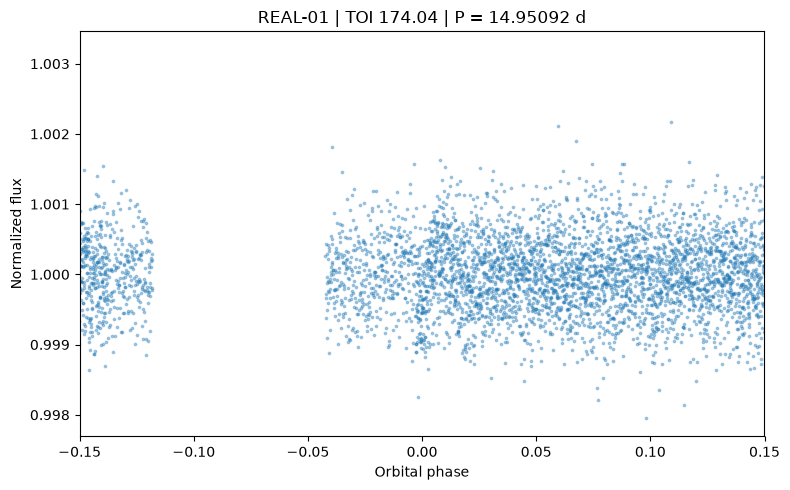


RUNNING REAL-02 | TOI 4307.02


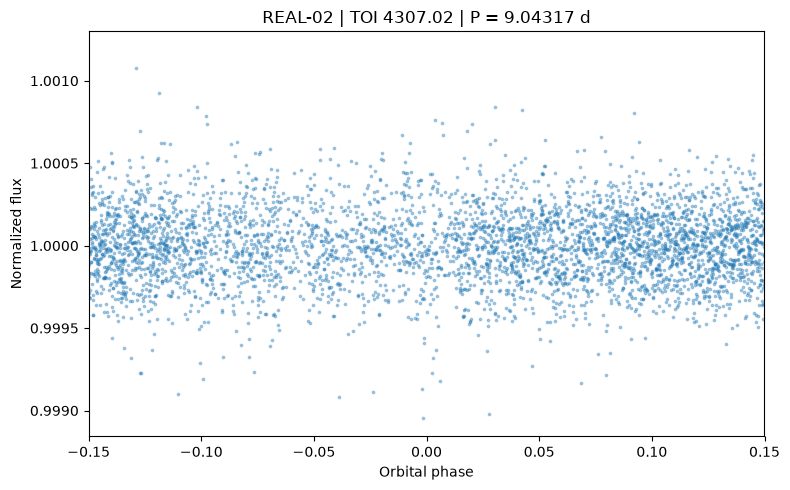


RUNNING REAL-03 | TOI 4580.01


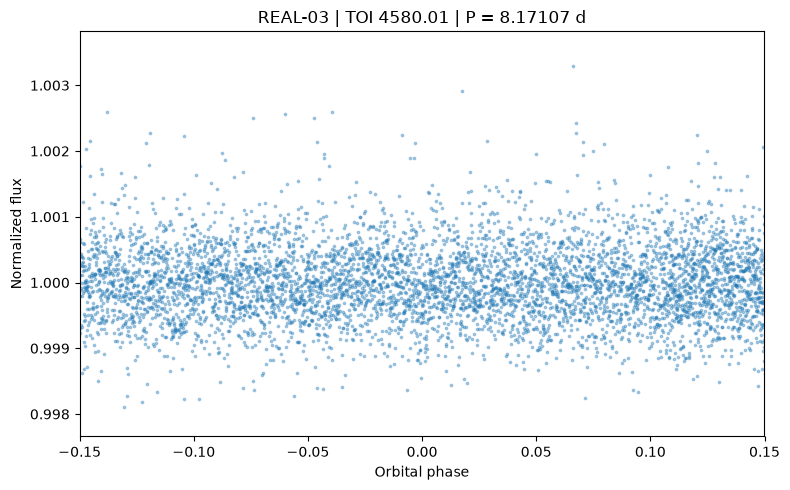


✅ BLIND REAL-TARGET OUTPUTS SAVED AND FROZEN.
✅ Now archive comparison is allowed.

WEEK 15B REAL CASE STUDIES

FROZEN TARGETS


,case_id,toi,tic_id,archive_disposition_at_selection
0,REAL-01,174.04,425997655,CP
1,REAL-02,4307.02,141186075,PC
2,REAL-03,4580.01,219742885,PC



BLIND PIPELINE RESULTS


,case_id,toi,robust_rms,adapt_v1_method,found_period_days,found_depth,apparent_rp_over_rstar,detection_sde,odd_even_relative_difference,secondary_primary_ratio,n_transits_measured
0,REAL-01,174.04,0.000528,SG_501,14.950920,0.000351,0.018747,8.654068,0.467878,-0.106063,2
1,REAL-02,4307.02,0.000225,SG_501,9.043170,0.000166,0.012884,5.457315,NaN,0.461807,2
2,REAL-03,4580.01,0.000633,SG_501,8.171068,0.000294,0.017149,5.039307,0.418651,-0.014185,3



POST-FREEZE ARCHIVE COMPARISON


,case_id,toi,tfopwg_disp,found_period_days,pl_orbper,period_fractional_error,exact_period_match_1pct,found_depth,archive_depth_fraction,depth_fractional_difference_vs_archive
0,REAL-01,174.04,CP,14.950920,3.976683,2.759646,False,0.000351,0.000142,1.475054
1,REAL-02,4307.02,PC,9.043170,4.654580,0.942854,False,0.000166,0.000025,5.752131
2,REAL-03,4580.01,PC,8.171068,0.916799,7.912604,False,0.000294,0.000039,6.533577



✅ THREE REAL CASE STUDIES SELECTED DETERMINISTICALLY
✅ SELECTION RULE FROZEN
✅ FROZEN ADAPT-v1 USED
✅ ARCHIVE PERIOD NOT PASSED TO SEARCH
✅ BLIND RESULTS SAVED BEFORE CATALOG COMPARISON
✅ PERIOD COMPARISON COMPLETED
✅ DEPTH COMPARISON COMPLETED
✅ ODD-EVEN CHECK COMPLETED
✅ SECONDARY-LIKE DIP CHECK COMPLETED
✅ FOLDED LIGHT-CURVE FIGURES SAVED
✅ THESE ARE ILLUSTRATIVE CASE STUDIES
✅ NO INDEPENDENT PLANET-CONFIRMATION CLAIM


In [32]:
# ============================================================
# WEEK 15B
# REAL TOI CASE STUDIES
#
# FROZEN PIPELINE APPLICATION
#
# IMPORTANT:
# 1. Week 15 held-out result must already be frozen.
# 2. Target selection rule is written/frozen BEFORE pipeline run.
# 3. Pipeline outputs are saved BEFORE catalog comparison.
# 4. These are illustrative case studies.
# 5. No independent planet-confirmation claims.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from io import StringIO

import json
import hashlib
import time
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter
from astropy.io import fits
from astroquery.mast import Observations, Catalogs
from astropy.timeseries import BoxLeastSquares


# ============================================================
# 1. REQUIRE FROZEN WEEK 15
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CONFIG_DIR",
    "blind_bls_search",
    "build_period_grid",
    "BLS_CONFIG",
    "evaluate_recovery_v2",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Missing required project state:\n"
        f"{missing}\n\n"
        "Run the notebook through Week 15 first."
    )


W15_CONFIG_DIR = (
    CONFIG_DIR
    / "week15_heldout"
)


W15_FREEZE_PATH = (
    W15_CONFIG_DIR
    / "W15_HELDOUT_RESULT_FREEZE.json"
)


if not W15_FREEZE_PATH.exists():

    raise FileNotFoundError(
        "Week 15 held-out result is not frozen."
    )


with open(
    W15_FREEZE_PATH,
    "r",
) as f:

    W15_FREEZE = json.load(
        f
    )


print(
    "✅ Frozen Week 15 result found."
)

print(
    "✅ ADAPT-v1 remains locked."
)


# ============================================================
# 2. LOAD FROZEN ADAPT-v1 CONFIG
# ============================================================

W14_CONFIG_DIR = (
    CONFIG_DIR
    / "week14_adapt_v1"
)


ADAPT_CONFIG_PATH = (
    W14_CONFIG_DIR
    / "ADAPT_V1_config.json"
)


with open(
    ADAPT_CONFIG_PATH,
    "r",
) as f:

    ADAPT_CONFIG = json.load(
        f
    )


ADAPT_THRESHOLD = float(
    ADAPT_CONFIG[
        "threshold"
    ]
)


def choose_adapt_method(
    robust_rms,
):

    if (
        float(
            robust_rms
        )
        <=
        ADAPT_THRESHOLD
    ):

        return "BASELINE"

    return "SG_501"


print(
    f"Frozen threshold = "
    f"{ADAPT_THRESHOLD:.3e}"
)


# ============================================================
# 3. DIRECTORIES
# ============================================================

W15B_RESULTS_DIR = (
    RESULTS_DIR
    / "week15_real_case_studies"
)


W15B_FIGURES_DIR = (
    FIGURES_DIR
    / "week15_real_case_studies"
)


W15B_CONFIG_DIR = (
    CONFIG_DIR
    / "week15_real_case_studies"
)


W15B_CACHE_DIR = (
    W15B_RESULTS_DIR
    / "mast_cache"
)


for folder in [
    W15B_RESULTS_DIR,
    W15B_FIGURES_DIR,
    W15B_CONFIG_DIR,
    W15B_CACHE_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. FREEZE CASE-STUDY SELECTION RULE
# ============================================================

SELECTION_RULE = {

    "version":
        "W15B_CASE_SELECTION_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "period_min_days":
        0.5,

    "period_max_days":
        15.0,

    "planet_radius_max_rearth":
        3.0,

    "tmag_max":
        12.0,

    "target_mix": {
        "confirmed_planet_CP": 1,
        "candidate_PC_or_APC": 2,
    },

    "selection_order":
        (
            "ascending planet radius, "
            "then ascending TESS magnitude, "
            "then ascending TOI number"
        ),

    "must_have_spoc_light_curve":
        True,

    "pipeline_results_used_for_selection":
        False,

    "purpose":
        (
            "Illustrative application of the frozen "
            "Week 15 pipeline. Not independent confirmation."
        ),
}


SELECTION_RULE_PATH = (
    W15B_CONFIG_DIR
    / "W15B_CASE_SELECTION_RULE.json"
)


if not SELECTION_RULE_PATH.exists():

    with open(
        SELECTION_RULE_PATH,
        "w",
    ) as f:

        json.dump(
            SELECTION_RULE,
            f,
            indent=2,
        )


    print(
        "✅ Case-study selection rule frozen."
    )

else:

    with open(
        SELECTION_RULE_PATH,
        "r",
    ) as f:

        SELECTION_RULE = json.load(
            f
        )


    print(
        "✅ Existing frozen selection rule preserved."
    )


# ============================================================
# 5. QUERY NASA EXOPLANET ARCHIVE TOI TABLE
# ============================================================

toi_query = """
SELECT
    toi,
    tid,
    tfopwg_disp,
    pl_orbper,
    pl_rade,
    pl_trandep,
    pl_trandurh,
    pl_tranmid,
    st_tmag,
    st_rad,
    st_teff
FROM toi
WHERE
    pl_orbper >= 0.5
    AND pl_orbper <= 15.0
    AND pl_rade <= 3.0
    AND st_tmag <= 12.0
    AND tid IS NOT NULL
"""


tap_url = (
    "https://exoplanetarchive.ipac.caltech.edu/"
    "TAP/sync"
)


response = requests.get(
    tap_url,
    params={
        "query":
            " ".join(
                toi_query.split()
            ),

        "format":
            "csv",
    },
    timeout=120,
)


response.raise_for_status()


toi_df = pd.read_csv(
    StringIO(
        response.text
    )
)


print()
print(
    "Archive rows satisfying basic frozen rule:",
    len(
        toi_df
    )
)


# ============================================================
# 6. CLEAN TOI TABLE
# ============================================================

numeric_columns = [
    "toi",
    "tid",
    "pl_orbper",
    "pl_rade",
    "pl_trandep",
    "pl_trandurh",
    "pl_tranmid",
    "st_tmag",
    "st_rad",
    "st_teff",
]


for column in numeric_columns:

    toi_df[
        column
    ] = pd.to_numeric(
        toi_df[
            column
        ],
        errors="coerce",
    )


toi_df = toi_df.dropna(
    subset=[
        "toi",
        "tid",
        "pl_orbper",
        "pl_rade",
        "st_tmag",
    ]
)


toi_df[
    "tfopwg_disp"
] = (

    toi_df[
        "tfopwg_disp"
    ]

    .astype(
        str
    )

    .str.strip()

    .str.upper()
)


toi_df = toi_df[
    toi_df[
        "tfopwg_disp"
    ].isin(
        [
            "CP",
            "PC",
            "APC",
        ]
    )
].copy()


toi_df = toi_df.sort_values(
    [
        "pl_rade",
        "st_tmag",
        "toi",
    ],
    ascending=[
        True,
        True,
        True,
    ],
).reset_index(
    drop=True
)


# ============================================================
# 7. CHECK WHETHER A TIC HAS A SPOC LIGHT CURVE
# ============================================================

def find_spoc_lc_product(
    tic_id,
):

    try:

        observations = (
            Observations.query_criteria(

                obs_collection="TESS",

                target_name=str(
                    int(
                        tic_id
                    )
                ),
            )
        )


        if len(
            observations
        ) == 0:

            return None


        products = (
            Observations.get_product_list(
                observations
            )
        )


        candidates = []


        for i in range(
            len(
                products
            )
        ):

            filename = str(
                products[
                    i
                ][
                    "productFilename"
                ]
            )


            lower_name = (
                filename.lower()
            )


            subgroup = ""

            try:

                subgroup = str(
                    products[
                        i
                    ][
                        "productSubGroupDescription"
                    ]
                ).upper()

            except Exception:
                pass


            looks_like_lc = (
                lower_name.endswith(
                    "lc.fits"
                )
                or
                subgroup
                ==
                "LC"
            )


            looks_like_tpf = (
                "tp.fits"
                in lower_name
                or
                "tpf"
                in lower_name
            )


            if (
                looks_like_lc
                and
                not looks_like_tpf
            ):

                sector = None

                try:

                    sector = int(
                        observations[
                            0
                        ][
                            "sequence_number"
                        ]
                    )

                except Exception:
                    pass


                candidates.append({

                    "product_index":
                        i,

                    "filename":
                        filename,

                    "data_uri":
                        str(
                            products[
                                i
                            ][
                                "dataURI"
                            ]
                        ),

                    "sector":
                        sector,
                })


        if len(
            candidates
        ) == 0:

            return None


        # Deterministic
        candidates = sorted(
            candidates,
            key=lambda x:
                x[
                    "filename"
                ]
        )


        return candidates[
            0
        ]


    except Exception:

        return None


# ============================================================
# 8. DETERMINISTICALLY SELECT THREE CASE STUDIES
# ============================================================

selected_rows = []


# ------------------------------------------------------------
# A. One confirmed planet
# ------------------------------------------------------------

confirmed_pool = (
    toi_df[
        toi_df[
            "tfopwg_disp"
        ]
        ==
        "CP"
    ]
)


for _, row in confirmed_pool.iterrows():

    product = find_spoc_lc_product(
        row[
            "tid"
        ]
    )


    if product is not None:

        selected = (
            row.to_dict()
        )


        selected[
            "selected_product"
        ] = product


        selected_rows.append(
            selected
        )


        break


# ------------------------------------------------------------
# B. Two PC/APC candidates
# ------------------------------------------------------------

candidate_pool = (
    toi_df[
        toi_df[
            "tfopwg_disp"
        ].isin(
            [
                "PC",
                "APC",
            ]
        )
    ]
)


for _, row in candidate_pool.iterrows():

    if len(
        selected_rows
    ) >= 3:

        break


    product = find_spoc_lc_product(
        row[
            "tid"
        ]
    )


    if product is None:

        continue


    existing_tics = {
        int(
            r[
                "tid"
            ]
        )
        for r in selected_rows
    }


    if (
        int(
            row[
                "tid"
            ]
        )
        in
        existing_tics
    ):

        continue


    selected = (
        row.to_dict()
    )


    selected[
        "selected_product"
    ] = product


    selected_rows.append(
        selected
    )


if len(
    selected_rows
) != 3:

    raise RuntimeError(
        "Could not find three TOIs satisfying "
        "the frozen selection rule with usable "
        "SPOC light curves."
    )


# ============================================================
# 9. FREEZE SELECTED TARGET IDENTITIES
#
# No pipeline results have been generated yet.
# ============================================================

selected_targets_rows = []


for case_number, row in enumerate(
    selected_rows,
    start=1,
):

    product = (
        row[
            "selected_product"
        ]
    )


    selected_targets_rows.append({

        "case_id":
            f"REAL-{case_number:02d}",

        "toi":
            float(
                row[
                    "toi"
                ]
            ),

        "tic_id":
            int(
                row[
                    "tid"
                ]
            ),

        "archive_disposition_at_selection":
            str(
                row[
                    "tfopwg_disp"
                ]
            ),

        "selection_radius_rearth":
            float(
                row[
                    "pl_rade"
                ]
            ),

        "selection_tmag":
            float(
                row[
                    "st_tmag"
                ]
            ),

        "selected_filename":
            product[
                "filename"
            ],

        "selected_data_uri":
            product[
                "data_uri"
            ],
    })


selected_targets_df = pd.DataFrame(
    selected_targets_rows
)


TARGET_FREEZE_PATH = (
    W15B_CONFIG_DIR
    / "W15B_SELECTED_TARGETS_V1.csv"
)


if TARGET_FREEZE_PATH.exists():

    frozen_targets_df = pd.read_csv(
        TARGET_FREEZE_PATH
    )


    # Once frozen, use original targets.
    selected_targets_df = (
        frozen_targets_df.copy()
    )


    print(
        "✅ Existing case-study target freeze preserved."
    )

else:

    selected_targets_df.to_csv(
        TARGET_FREEZE_PATH,
        index=False,
    )


    print(
        "✅ Three real case-study targets frozen."
    )


print()
print(
    "FROZEN REAL CASE STUDIES"
)

display(
    selected_targets_df[
        [
            "case_id",
            "toi",
            "tic_id",
            "archive_disposition_at_selection",
            "selection_radius_rearth",
            "selection_tmag",
        ]
    ]
)


# ============================================================
# 10. DOWNLOAD A FROZEN CASE-STUDY LIGHT CURVE
# ============================================================

def download_case_lightcurve(
    case_row,
):

    case_id = str(
        case_row[
            "case_id"
        ]
    )


    data_uri = str(
        case_row[
            "selected_data_uri"
        ]
    )


    original_filename = str(
        case_row[
            "selected_filename"
        ]
    )


    local_fits = (

        W15B_CACHE_DIR
        /
        f"{case_id}_{original_filename}"
    )


    temp_fits = Path(
        str(
            local_fits
        )
        +
        ".part"
    )


    if not local_fits.exists():

        url = (

            "https://mast.stsci.edu/"
            "api/v0.1/Download/file"
            f"?uri={data_uri}"
        )


        print(
            f"Downloading {case_id}..."
        )


        with requests.get(
            url,
            stream=True,
            timeout=(
                20,
                120,
            ),
        ) as response:

            response.raise_for_status()


            with open(
                temp_fits,
                "wb",
            ) as f:

                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):

                    if chunk:

                        f.write(
                            chunk
                        )


        with fits.open(
            temp_fits,
            memmap=False,
        ) as hdul:

            hdul.verify(
                "exception"
            )


        temp_fits.replace(
            local_fits
        )


    with fits.open(
        local_fits,
        memmap=False,
    ) as hdul:

        data = hdul[
            1
        ].data


        columns = list(
            data.columns.names
        )


        time_values = np.asarray(
            data[
                "TIME"
            ],
            dtype=float,
        )


        if (
            "PDCSAP_FLUX"
            in columns
        ):

            flux_values = np.asarray(
                data[
                    "PDCSAP_FLUX"
                ],
                dtype=float,
            )

        else:

            flux_values = np.asarray(
                data[
                    "SAP_FLUX"
                ],
                dtype=float,
            )


        if (
            "QUALITY"
            in columns
        ):

            quality = np.asarray(
                data[
                    "QUALITY"
                ],
                dtype=int,
            )

        else:

            quality = np.zeros(
                len(
                    time_values
                ),
                dtype=int,
            )


    good = (

        np.isfinite(
            time_values
        )

        &

        np.isfinite(
            flux_values
        )

        &

        (
            quality
            ==
            0
        )
    )


    time_values = (
        time_values[
            good
        ]
    )


    flux_values = (
        flux_values[
            good
        ]
    )


    flux_values = (

        flux_values
        /
        np.nanmedian(
            flux_values
        )
    )


    return {

        "time":
            time_values,

        "flux":
            flux_values,

        "local_fits":
            str(
                local_fits
            ),
    }


# ============================================================
# 11. FROZEN PREPROCESSING
# ============================================================

def robust_rms(
    flux,
):

    flux = np.asarray(
        flux,
        dtype=float,
    )


    med = np.nanmedian(
        flux
    )


    mad = np.nanmedian(
        np.abs(
            flux
            -
            med
        )
    )


    return float(
        1.4826
        *
        mad
    )


def apply_frozen_preprocessing(
    time_values,
    flux_values,
    method_name,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )


    f = np.asarray(
        flux_values,
        dtype=float,
    )


    good = (

        np.isfinite(
            t
        )

        &

        np.isfinite(
            f
        )
    )


    t = t[
        good
    ]

    f = f[
        good
    ]


    if (
        method_name
        ==
        "BASELINE"
    ):

        return (
            t,
            f,
        )


    trend = savgol_filter(
        f,
        window_length=501,
        polyorder=2,
    )


    detrended = (
        f
        /
        trend
    )


    good = (

        np.isfinite(
            detrended
        )

        &

        np.isfinite(
            t
        )
    )


    return (
        t[
            good
        ],
        detrended[
            good
        ],
    )


# ============================================================
# 12. SIMPLE VETTING HELPERS
# ============================================================

def phase_fold(
    time_values,
    period,
    epoch,
):

    return (

        (
            time_values
            -
            epoch
            +
            0.5
            *
            period
        )

        %
        period

    ) / period - 0.5


def robust_local_depth(
    phase,
    flux,
    center,
    width,
):

    distance = np.abs(

        (
            phase
            -
            center
            +
            0.5
        )
        %
        1.0
        -
        0.5
    )


    in_transit = (
        distance
        <=
        width
        /
        2
    )


    out_transit = (
        (
            distance
            >
            width
        )
        &
        (
            distance
            <
            3
            *
            width
        )
    )


    if (
        in_transit.sum()
        <
        3
        or
        out_transit.sum()
        <
        5
    ):

        return np.nan


    return float(

        np.nanmedian(
            flux[
                out_transit
            ]
        )

        -

        np.nanmedian(
            flux[
                in_transit
            ]
        )
    )


def case_vetting(
    time_values,
    flux_values,
    candidate,
):

    period = float(
        candidate[
            "found_period_days"
        ]
    )


    epoch = float(
        candidate[
            "found_epoch_btjd"
        ]
    )


    duration = float(
        candidate.get(
            "found_duration_days",
            np.nan,
        )
    )


    if (
        not np.isfinite(
            duration
        )
    ):

        duration = (
            3
            /
            24
        )


    phase = phase_fold(
        time_values,
        period,
        epoch,
    )


    phase_width = min(
        0.2,
        max(
            duration
            /
            period,
            0.005,
        )
    )


    primary_depth = robust_local_depth(
        phase,
        flux_values,
        center=0.0,
        width=phase_width,
    )


    secondary_depth = robust_local_depth(
        phase,
        flux_values,
        center=0.5,
        width=phase_width,
    )


    if (
        np.isfinite(
            primary_depth
        )
        and
        primary_depth
        !=
        0
        and
        np.isfinite(
            secondary_depth
        )
    ):

        secondary_ratio = (
            secondary_depth
            /
            primary_depth
        )

    else:

        secondary_ratio = np.nan


    # --------------------------------------------------------
    # Odd-even transit depth check
    # --------------------------------------------------------

    transit_number = np.floor(

        (
            time_values
            -
            epoch
        )
        /
        period

        +
        0.5
    ).astype(
        int
    )


    in_primary = (
        np.abs(
            phase
        )
        <=
        phase_width
        /
        2
    )


    odd_depths = []
    even_depths = []


    unique_transits = np.unique(
        transit_number[
            in_primary
        ]
    )


    for number in unique_transits:

        mask = (

            in_primary
            &
            (
                transit_number
                ==
                number
            )
        )


        if (
            mask.sum()
            <
            2
        ):

            continue


        depth = (

            1.0
            -
            np.nanmedian(
                flux_values[
                    mask
                ]
            )
        )


        if (
            number
            %
            2
            ==
            0
        ):

            even_depths.append(
                depth
            )

        else:

            odd_depths.append(
                depth
            )


    odd_depth = (
        np.nanmedian(
            odd_depths
        )
        if len(
            odd_depths
        )
        >
        0
        else np.nan
    )


    even_depth = (
        np.nanmedian(
            even_depths
        )
        if len(
            even_depths
        )
        >
        0
        else np.nan
    )


    if (
        np.isfinite(
            odd_depth
        )
        and
        np.isfinite(
            even_depth
        )
        and
        primary_depth
        not in [
            0,
            np.nan,
        ]
    ):

        odd_even_difference = (

            abs(
                odd_depth
                -
                even_depth
            )

            /
            max(
                abs(
                    primary_depth
                ),
                1e-12,
            )
        )

    else:

        odd_even_difference = np.nan


    return {

        "primary_depth_vetting":
            primary_depth,

        "secondary_depth":
            secondary_depth,

        "secondary_primary_ratio":
            secondary_ratio,

        "odd_depth":
            odd_depth,

        "even_depth":
            even_depth,

        "odd_even_relative_difference":
            odd_even_difference,

        "n_transits_measured":
            int(
                len(
                    unique_transits
                )
            ),
    }


# ============================================================
# 13. RUN FROZEN PIPELINE ON REAL CASES
#
# Critically: archive period is NOT supplied to BLS.
# ============================================================

case_results = []


for _, case_row in (
    selected_targets_df.iterrows()
):

    print()
    print("=" * 72)

    print(
        "RUNNING",
        case_row[
            "case_id"
        ],
        "| TOI",
        case_row[
            "toi"
        ],
    )

    print("=" * 72)


    host = download_case_lightcurve(
        case_row
    )


    rms = robust_rms(
        host[
            "flux"
        ]
    )


    preprocessing = (
        choose_adapt_method(
            rms
        )
    )


    processed_t, processed_f = (
        apply_frozen_preprocessing(

            host[
                "time"
            ],

            host[
                "flux"
            ],

            preprocessing,
        )
    )


    period_grid = build_period_grid(

        processed_t,

        processed_f,

        BLS_CONFIG,
    )


    start = time.perf_counter()


    candidate = blind_bls_search(

        processed_t,

        processed_f,

        period_grid=period_grid,

        config=BLS_CONFIG,
    )


    runtime = (
        time.perf_counter()
        -
        start
    )


    vetting = case_vetting(

        processed_t,

        processed_f,

        candidate,
    )


    output_row = {

        "case_id":
            case_row[
                "case_id"
            ],

        "toi":
            case_row[
                "toi"
            ],

        "tic_id":
            int(
                case_row[
                    "tic_id"
                ]
            ),

        "robust_rms":
            rms,

        "adapt_v1_method":
            preprocessing,

        "found_period_days":
            candidate.get(
                "found_period_days",
                np.nan,
            ),

        "found_epoch_btjd":
            candidate.get(
                "found_epoch_btjd",
                np.nan,
            ),

        "found_duration_days":
            candidate.get(
                "found_duration_days",
                np.nan,
            ),

        "found_depth":
            candidate.get(
                "found_depth",
                np.nan,
            ),

        "apparent_rp_over_rstar":
            (
                np.sqrt(
                    candidate.get(
                        "found_depth",
                        np.nan,
                    )
                )
                if
                candidate.get(
                    "found_depth",
                    np.nan,
                )
                >
                0
                else
                np.nan
            ),

        "detection_sde":
            candidate.get(
                "detection_sde",
                np.nan,
            ),

        "runtime_seconds":
            runtime,

        **vetting,
    }


    case_results.append(
        output_row
    )


    # ========================================================
    # SAVE INDIVIDUAL PERIOD/FOLD FIGURE
    # ========================================================

    found_period = float(
        candidate[
            "found_period_days"
        ]
    )


    found_epoch = float(
        candidate[
            "found_epoch_btjd"
        ]
    )


    phase = phase_fold(

        processed_t,

        found_period,

        found_epoch,
    )


    fig, ax = plt.subplots(
        figsize=(
            8,
            5,
        )
    )


    ax.scatter(
        phase,
        processed_f,
        s=3,
        alpha=0.35,
    )


    ax.set_xlim(
        -0.15,
        0.15,
    )


    ax.set_xlabel(
        "Orbital phase"
    )


    ax.set_ylabel(
        "Normalized flux"
    )


    ax.set_title(
        f"{case_row['case_id']} | "
        f"TOI {case_row['toi']} | "
        f"P = {found_period:.5f} d"
    )


    fig.tight_layout()


    fig.savefig(

        W15B_FIGURES_DIR
        /
        f"{case_row['case_id']}_folded.png",

        dpi=220,
    )


    plt.show()


# ============================================================
# 14. SAVE OUR RESULTS BEFORE ARCHIVE COMPARISON
# ============================================================

case_results_df = pd.DataFrame(
    case_results
)


BLIND_RESULTS_PATH = (
    W15B_RESULTS_DIR
    / "W15B_BLIND_PIPELINE_RESULTS.csv"
)


case_results_df.to_csv(
    BLIND_RESULTS_PATH,
    index=False,
)


blind_hash = hashlib.sha256(
    BLIND_RESULTS_PATH.read_bytes()
).hexdigest()


with open(

    W15B_CONFIG_DIR
    / "W15B_BLIND_RESULTS_FREEZE.json",

    "w",

) as f:

    json.dump(
        {
            "frozen_utc":
                datetime.now(
                    timezone.utc
                ).isoformat(),

            "blind_results_sha256":
                blind_hash,

            "archive_comparison_performed_before_freeze":
                False,
        },
        f,
        indent=2,
    )


print()
print(
    "✅ BLIND REAL-TARGET OUTPUTS SAVED AND FROZEN."
)

print(
    "✅ Now archive comparison is allowed."
)


# ============================================================
# 15. ARCHIVE COMPARISON
#
# Only now do we attach published/catalog parameters.
# ============================================================

archive_columns = [
    "toi",
    "tfopwg_disp",
    "pl_orbper",
    "pl_rade",
    "pl_trandep",
    "pl_trandurh",
    "pl_tranmid",
    "st_tmag",
    "st_rad",
    "st_teff",
]


comparison_archive_df = (
    toi_df[
        archive_columns
    ]
    .copy()
)


comparison_df = (

    case_results_df

    .merge(

        comparison_archive_df,

        on="toi",

        how="left",
    )
)


comparison_df[
    "period_fractional_error"
] = (

    np.abs(

        comparison_df[
            "found_period_days"
        ]

        -

        comparison_df[
            "pl_orbper"
        ]
    )

    /

    comparison_df[
        "pl_orbper"
    ]
)


comparison_df[
    "exact_period_match_1pct"
] = (

    comparison_df[
        "period_fractional_error"
    ]

    <=
    0.01
)


comparison_df[
    "archive_depth_fraction"
] = (

    comparison_df[
        "pl_trandep"
    ]

    /
    1e6
)


comparison_df[
    "depth_fractional_difference_vs_archive"
] = (

    (
        comparison_df[
            "found_depth"
        ]

        -

        comparison_df[
            "archive_depth_fraction"
        ]
    )

    /

    comparison_df[
        "archive_depth_fraction"
    ]
)


COMPARISON_PATH = (
    W15B_RESULTS_DIR
    / "W15B_ARCHIVE_COMPARISON.csv"
)


comparison_df.to_csv(
    COMPARISON_PATH,
    index=False,
)


# ============================================================
# 16. FINAL DISPLAY
# ============================================================

print()
print("=" * 78)
print("WEEK 15B REAL CASE STUDIES")
print("=" * 78)


print()
print(
    "FROZEN TARGETS"
)

display(

    selected_targets_df[
        [
            "case_id",
            "toi",
            "tic_id",
            "archive_disposition_at_selection",
        ]
    ]
)


print()
print(
    "BLIND PIPELINE RESULTS"
)

display(

    case_results_df[
        [
            "case_id",
            "toi",
            "robust_rms",
            "adapt_v1_method",
            "found_period_days",
            "found_depth",
            "apparent_rp_over_rstar",
            "detection_sde",
            "odd_even_relative_difference",
            "secondary_primary_ratio",
            "n_transits_measured",
        ]
    ]
)


print()
print(
    "POST-FREEZE ARCHIVE COMPARISON"
)

display(

    comparison_df[
        [
            "case_id",
            "toi",
            "tfopwg_disp",
            "found_period_days",
            "pl_orbper",
            "period_fractional_error",
            "exact_period_match_1pct",
            "found_depth",
            "archive_depth_fraction",
            "depth_fractional_difference_vs_archive",
        ]
    ]
)


print()
print("=" * 78)
print("✅ THREE REAL CASE STUDIES SELECTED DETERMINISTICALLY")
print("✅ SELECTION RULE FROZEN")
print("✅ FROZEN ADAPT-v1 USED")
print("✅ ARCHIVE PERIOD NOT PASSED TO SEARCH")
print("✅ BLIND RESULTS SAVED BEFORE CATALOG COMPARISON")
print("✅ PERIOD COMPARISON COMPLETED")
print("✅ DEPTH COMPARISON COMPLETED")
print("✅ ODD-EVEN CHECK COMPLETED")
print("✅ SECONDARY-LIKE DIP CHECK COMPLETED")
print("✅ FOLDED LIGHT-CURVE FIGURES SAVED")
print("✅ THESE ARE ILLUSTRATIVE CASE STUDIES")
print("✅ NO INDEPENDENT PLANET-CONFIRMATION CLAIM")
print("=" * 78)

✅ Core project state found.
✅ Week 16 directories ready.
✅ Frozen Week 15 held-out result verified.
✅ Week 15B blind case-study result freeze verified.
✅ Week 15 final tables loaded.
✅ Week 15B real-target outputs loaded.
✅ Master numerical tables saved.

DEVELOPMENT → HELD-OUT ADAPT SUMMARY


,dataset,FIXED_BASELINE,ADAPT_V1,absolute_difference
0,Development,0.455,0.645000,0.190000
1,Held-out,0.800,0.870833,0.070833



FINAL STORY TABLE


,question,result
0,Baseline recovery,622/1000 exact recoveries (62.2%).
1,Does preprocessing matter?,Yes. SG_501 increased exact recovery from 62.2...
2,Does search method matter?,BLS and TLS had similar paired recovery (64.0%...
3,Did ADAPT-v1 improve development recovery?,Yes. Development small-planet exact recovery i...
4,Did ADAPT-v1 generalize?,"On the frozen held-out benchmark, small-planet..."
5,Main held-out limitation,"Only three held-out hosts were used, and ADAPT..."


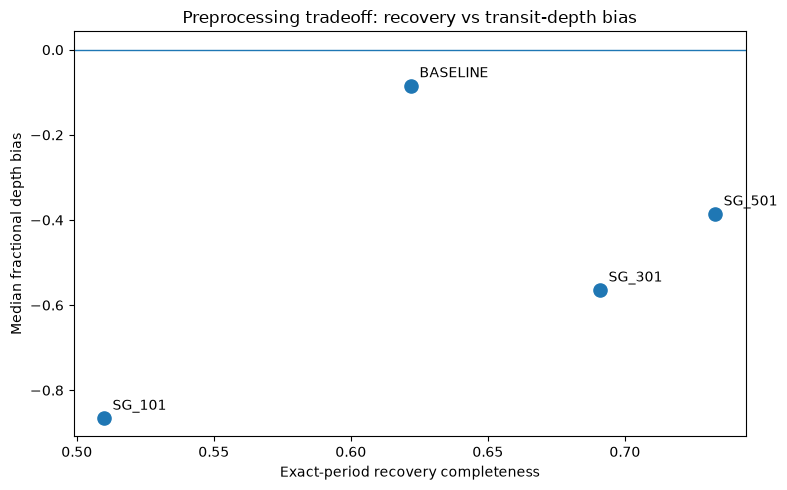

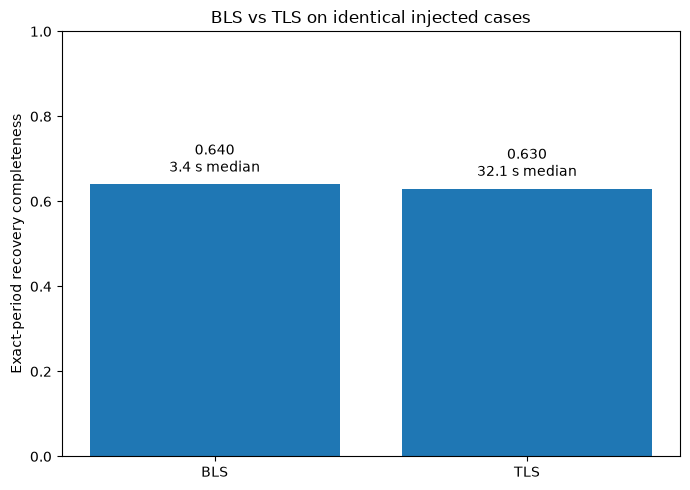

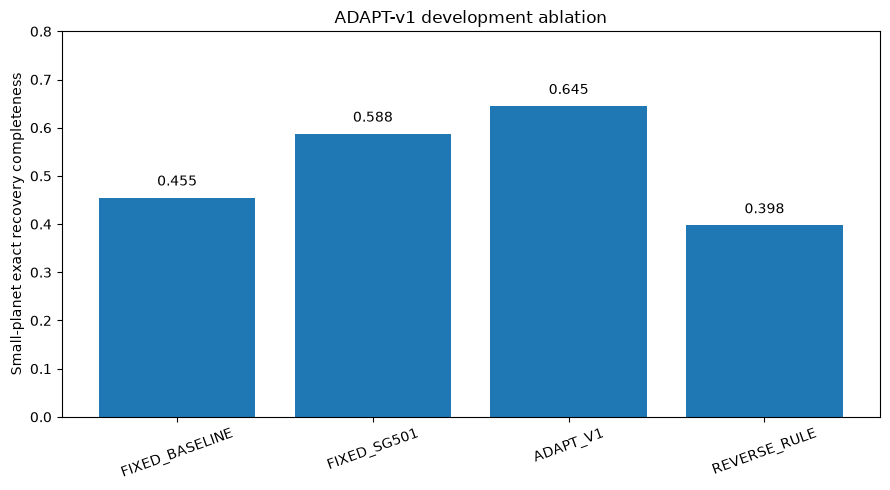

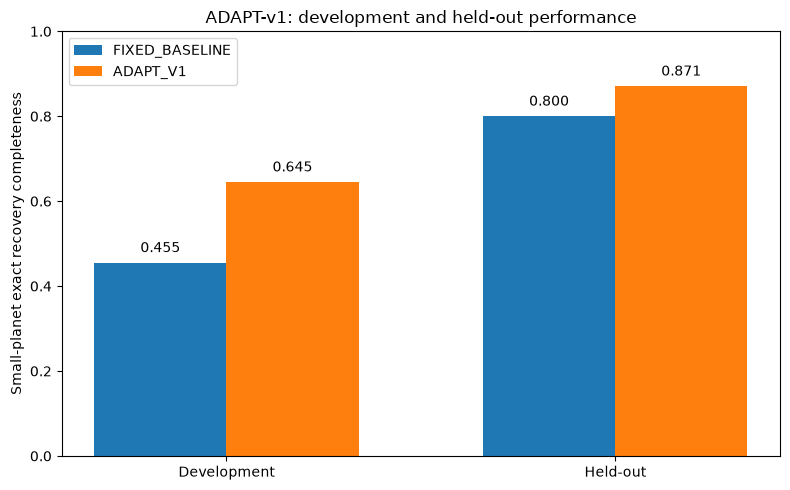

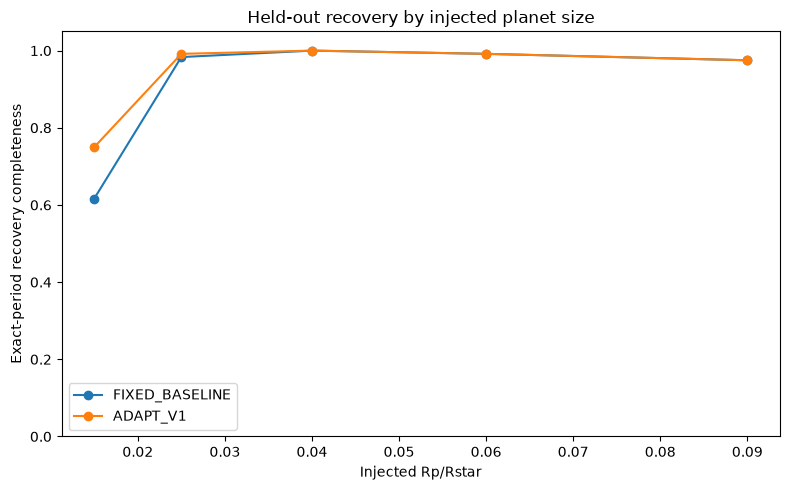

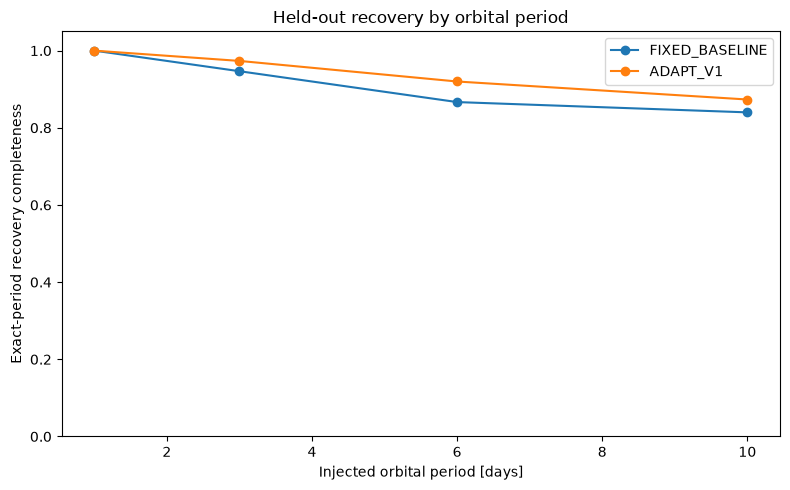

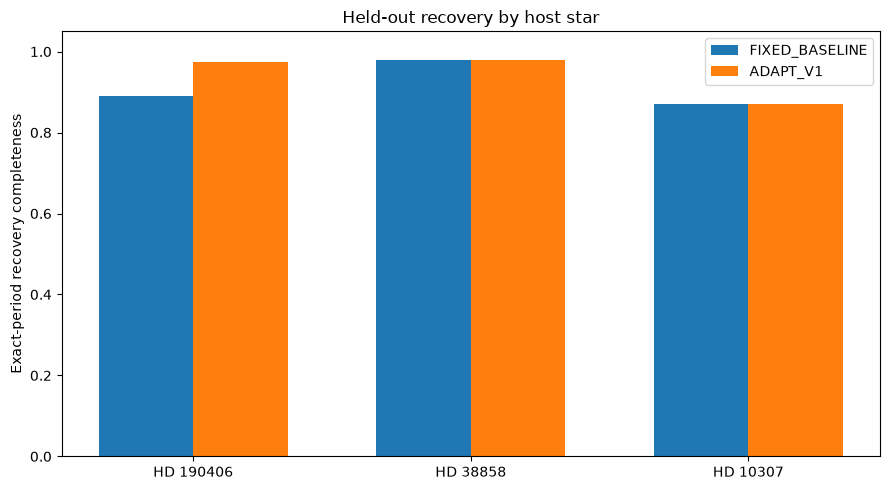

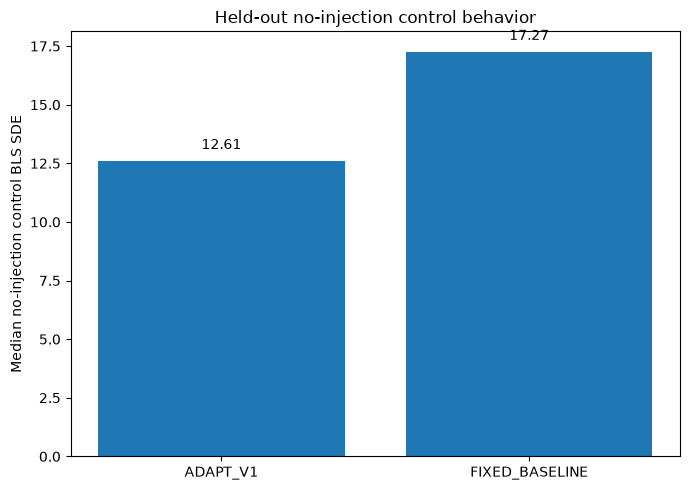


FINAL REAL-TARGET CASE-STUDY TABLE


,case_id,toi,tic_id,tfopwg_disp,adapt_v1_method,found_period_days,pl_orbper,period_fractional_error,exact_period_match_1pct,found_depth,archive_depth_fraction,depth_fractional_difference_vs_archive,odd_even_relative_difference,secondary_primary_ratio
0,REAL-01,174.04,425997655,CP,SG_501,14.950920,3.976683,2.759646,False,0.000351,0.000142,1.475054,0.467878,-0.106063
1,REAL-02,4307.02,141186075,PC,SG_501,9.043170,4.654580,0.942854,False,0.000166,0.000025,5.752131,NaN,0.461807
2,REAL-03,4580.01,219742885,PC,SG_501,8.171068,0.916799,7.912604,False,0.000294,0.000039,6.533577,0.418651,-0.014185


✅ Master machine-readable result summary saved.

PAPER-READY RESULTS SUMMARY

WEEK 16 MASTER RESULTS — PAPER-READY NUMERICAL SUMMARY

Baseline benchmark
------------------
The frozen baseline pipeline recovered the injected orbital
period exactly in 622 of 1,000 development injections,
corresponding to an exact-period recovery completeness of
62.2%.

Preprocessing experiment
------------------------
Recovery depended strongly on preprocessing. The fixed SG_501
configuration increased exact-period recovery from 62.2% under
the baseline preprocessing to 73.3%. However, this improvement
was accompanied by substantially greater transit-depth
suppression: the median fractional depth bias among exact
recoveries was -0.385 for SG_501 compared with -0.084 for the
baseline. This establishes a recovery-versus-measurement-bias
tradeoff.

BLS versus TLS
--------------
On the same 200 injected cases and identical period range, BLS
recovered 128/200 cases exactly (64.0%), whereas TLS recovered
126/2

,dataset,FIXED_BASELINE,ADAPT_V1,absolute_difference
0,Development,0.455,0.645000,0.190000
1,Held-out,0.800,0.870833,0.070833



FINAL WEEK 15 PRIMARY RESULT


...


FINAL CASE-STUDY TABLE


,case_id,toi,tic_id,tfopwg_disp,adapt_v1_method,found_period_days,pl_orbper,period_fractional_error,exact_period_match_1pct,found_depth,archive_depth_fraction,depth_fractional_difference_vs_archive,odd_even_relative_difference,secondary_primary_ratio
0,REAL-01,174.04,425997655,CP,SG_501,14.950920,3.976683,2.759646,False,0.000351,0.000142,1.475054,0.467878,-0.106063
1,REAL-02,4307.02,141186075,PC,SG_501,9.043170,4.654580,0.942854,False,0.000166,0.000025,5.752131,NaN,0.461807
2,REAL-03,4580.01,219742885,PC,SG_501,8.171068,0.916799,7.912604,False,0.000294,0.000039,6.533577,0.418651,-0.014185



FINAL FIGURE MANIFEST


,filename,sha256,size_bytes
0,W16_Fig1_preprocessing_tradeoff.png,33b743478e44bf5f9f69ee94084a5578f0d7cd09e93576...,95997
1,W16_Fig2_bls_vs_tls.png,fd2c14374f54ff02030b25d7106f09393843b06e5122cf...,75176
2,W16_Fig3_adapt_development_ablation.png,4807d5bc64fed3597eb44878c7a818943384f8cb9daa8b...,116027
3,W16_Fig4_adapt_generalization.png,14fa863f4298aea46e9a04d033be36efb02678449baf4b...,92311
4,W16_Fig5_heldout_by_size.png,e4c3998f7f305c6a2650889b59ebc4098d3c42566b0ed7...,115703
5,W16_Fig6_heldout_by_period.png,aedbe4fc6b835c03eca8d17042958f0869e7c0ec9413ba...,105905
6,W16_Fig7_heldout_by_host.png,99cd6b3cb600de46f527944cbbeb32c2870123d86d23da...,79732
7,W16_Fig8_control_sde.png,f5fe227b4502f91cac3ff80bee4a134434df6bbd4933b8...,68418



✅ WEEK 11 BASELINE RESULT INCLUDED
✅ WEEK 12 PREPROCESSING RESULT INCLUDED
✅ WEEK 13 BLS/TLS RESULT INCLUDED
✅ WEEK 14 ADAPT DEVELOPMENT RESULT INCLUDED
✅ WEEK 15 HELD-OUT RESULT INCLUDED
✅ WEEK 15B REAL CASE STUDIES INCLUDED
✅ FINAL MASTER TABLES SAVED
✅ FINAL FIGURES SAVED
✅ PAPER-READY NUMERICAL SUMMARY SAVED
✅ MASTER JSON SAVED
✅ FINAL RESULT PACKAGE FROZEN
✅ NO NEW SEARCHES
✅ NO NEW INJECTIONS
✅ NO NEW TUNING


In [33]:
# ============================================================
# WEEK 16A
# MASTER RESULTS + FINAL FIGURES
#
# PURPOSE
# -------
# Collect the frozen outputs from:
#
#   Week 11  completeness benchmark
#   Week 12  preprocessing comparison
#   Week 13  BLS vs TLS
#   Week 14  ADAPT-v1 development
#   Week 15  untouched held-out evaluation
#   Week 15B real TOI case studies
#
# NO NEW SEARCHES
# NO NEW INJECTIONS
# NO NEW TUNING
# NO CHANGES TO ADAPT-v1
#
# Outputs:
#   final master tables
#   publication-ready figures
#   machine-readable summary
#   paper-ready numerical results text
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. REQUIRE PROJECT STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "FIGURES_DIR",
    "CONFIG_DIR",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Missing required project state:\n"
        f"{missing}"
    )


print(
    "✅ Core project state found."
)


# ============================================================
# 2. WEEK 16 DIRECTORIES
# ============================================================

W16_RESULTS_DIR = (
    RESULTS_DIR
    / "week16_final"
)


W16_FIGURES_DIR = (
    FIGURES_DIR
    / "week16_final"
)


W16_CONFIG_DIR = (
    CONFIG_DIR
    / "week16_final"
)


for folder in [
    W16_RESULTS_DIR,
    W16_FIGURES_DIR,
    W16_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Week 16 directories ready."
)


# ============================================================
# 3. VERIFY WEEK 15 IS FROZEN
# ============================================================

W15_FREEZE_PATH = (
    CONFIG_DIR
    / "week15_heldout"
    / "W15_HELDOUT_RESULT_FREEZE.json"
)


if not W15_FREEZE_PATH.exists():

    raise RuntimeError(
        "STOP: frozen Week 15 held-out result "
        "was not found."
    )


with open(
    W15_FREEZE_PATH,
    "r",
) as f:

    W15_FREEZE = json.load(
        f
    )


print(
    "✅ Frozen Week 15 held-out result verified."
)


# ============================================================
# 4. VERIFY WEEK 15B BLIND RESULT FREEZE
# ============================================================

W15B_FREEZE_PATH = (
    CONFIG_DIR
    / "week15_real_case_studies"
    / "W15B_BLIND_RESULTS_FREEZE.json"
)


if not W15B_FREEZE_PATH.exists():

    raise RuntimeError(
        "STOP: Week 15B blind case-study freeze "
        "was not found."
    )


with open(
    W15B_FREEZE_PATH,
    "r",
) as f:

    W15B_FREEZE = json.load(
        f
    )


print(
    "✅ Week 15B blind case-study result freeze verified."
)


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def sha256_file(
    path,
):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )

    return h.hexdigest()


def save_csv(
    df,
    filename,
):

    path = (
        W16_RESULTS_DIR
        /
        filename
    )


    df.to_csv(
        path,
        index=False,
    )


    return path


def safe_read_csv(
    path,
):

    path = Path(
        path
    )


    if not path.exists():

        return None


    return pd.read_csv(
        path
    )


# ============================================================
# 6. LOAD WEEK 15 FINAL TABLES
# ============================================================

W15_RESULTS_DIR = (
    RESULTS_DIR
    / "week15_heldout"
)


w15_primary = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_primary_metric.csv"
)


w15_secondary = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_secondary_metrics.csv"
)


w15_by_host = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_completeness_by_host.csv"
)


w15_by_size = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_completeness_by_size.csv"
)


w15_by_period = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_completeness_by_period.csv"
)


w15_alias = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_alias_summary.csv"
)


w15_controls = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_control_summary.csv"
)


w15_switches = safe_read_csv(

    W15_RESULTS_DIR
    / "W15_primary_paired_switches.csv"
)


required_w15 = {
    "primary":
        w15_primary,

    "secondary":
        w15_secondary,

    "by_host":
        w15_by_host,

    "by_size":
        w15_by_size,

    "by_period":
        w15_by_period,

    "alias":
        w15_alias,

    "controls":
        w15_controls,

    "switches":
        w15_switches,
}


missing_w15 = [
    name
    for (
        name,
        value
    ) in required_w15.items()
    if value is None
]


if missing_w15:

    raise RuntimeError(
        "Missing Week 15 result table(s): "
        f"{missing_w15}"
    )


print(
    "✅ Week 15 final tables loaded."
)


# ============================================================
# 7. LOAD WEEK 15B CASE STUDIES
# ============================================================

W15B_RESULTS_DIR = (
    RESULTS_DIR
    / "week15_real_case_studies"
)


W15B_CONFIG_DIR = (
    CONFIG_DIR
    / "week15_real_case_studies"
)


case_results_df = safe_read_csv(

    W15B_RESULTS_DIR
    / "W15B_BLIND_PIPELINE_RESULTS.csv"
)


comparison_df = safe_read_csv(

    W15B_RESULTS_DIR
    / "W15B_ARCHIVE_COMPARISON.csv"
)


selected_targets_df = safe_read_csv(

    W15B_CONFIG_DIR
    / "W15B_SELECTED_TARGETS_V1.csv"
)


if (
    case_results_df is None
    or
    comparison_df is None
    or
    selected_targets_df is None
):

    raise RuntimeError(
        "Missing one or more Week 15B outputs."
    )


print(
    "✅ Week 15B real-target outputs loaded."
)


# ============================================================
# 8. FROZEN NUMERICAL RESULTS FROM WEEKS 11–14
#
# These are the canonical frozen results from the completed
# development stages.
#
# We store them here as a clean final master table.
# ============================================================

week11_summary_df = pd.DataFrame(
    [
        {
            "stage":
                "Week 11",

            "analysis":
                "Frozen baseline completeness",

            "attempted":
                1000,

            "exact_recovered":
                622,

            "exact_completeness":
                0.622,

            "notes":
                (
                    "Canonical clean-PC W11_COMPLETENESS_V1 "
                    "result."
                ),
        }
    ]
)


week12_summary_df = pd.DataFrame(
    [
        {
            "method":
                "BASELINE",

            "exact_recovered":
                622,

            "attempted":
                1000,

            "exact_completeness":
                0.622,

            "alias_aware_completeness":
                0.634,

            "median_depth_bias":
                -0.084080,

            "median_apparent_radius_bias":
                -0.042963,
        },

        {
            "method":
                "SG_101",

            "exact_recovered":
                510,

            "attempted":
                1000,

            "exact_completeness":
                0.510,

            "alias_aware_completeness":
                0.516,

            "median_depth_bias":
                -0.865378,

            "median_apparent_radius_bias":
                -0.633091,
        },

        {
            "method":
                "SG_301",

            "exact_recovered":
                691,

            "attempted":
                1000,

            "exact_completeness":
                0.691,

            "alias_aware_completeness":
                0.691,

            "median_depth_bias":
                -0.564120,

            "median_apparent_radius_bias":
                -0.339788,
        },

        {
            "method":
                "SG_501",

            "exact_recovered":
                733,

            "attempted":
                1000,

            "exact_completeness":
                0.733,

            "alias_aware_completeness":
                0.735,

            "median_depth_bias":
                -0.385444,

            "median_apparent_radius_bias":
                -0.216064,
        },
    ]
)


week13_summary_df = pd.DataFrame(
    [
        {
            "search_method":
                "BLS",

            "attempted":
                200,

            "exact_recovered":
                128,

            "exact_completeness":
                0.640,

            "alias_aware_recovered":
                128,

            "alias_aware_completeness":
                0.640,

            "median_runtime_seconds":
                3.379672,
        },

        {
            "search_method":
                "TLS",

            "attempted":
                200,

            "exact_recovered":
                126,

            "exact_completeness":
                0.630,

            "alias_aware_recovered":
                128,

            "alias_aware_completeness":
                0.640,

            "median_runtime_seconds":
                32.133892,
        },
    ]
)


week14_summary_df = pd.DataFrame(
    [
        {
            "method":
                "FIXED_BASELINE",

            "exact_recovered":
                622,

            "attempted":
                1000,

            "exact_completeness":
                0.622,

            "small_planet_exact_recovered":
                182,

            "small_planet_attempted":
                400,

            "small_planet_completeness":
                0.4550,

            "median_depth_bias":
                -0.084080,

            "median_apparent_radius_bias":
                -0.042963,
        },

        {
            "method":
                "FIXED_SG501",

            "exact_recovered":
                733,

            "attempted":
                1000,

            "exact_completeness":
                0.733,

            "small_planet_exact_recovered":
                235,

            "small_planet_attempted":
                400,

            "small_planet_completeness":
                0.5875,

            "median_depth_bias":
                -0.385444,

            "median_apparent_radius_bias":
                -0.216064,
        },

        {
            "method":
                "ADAPT_V1",

            "exact_recovered":
                763,

            "attempted":
                1000,

            "exact_completeness":
                0.763,

            "small_planet_exact_recovered":
                258,

            "small_planet_attempted":
                400,

            "small_planet_completeness":
                0.6450,

            "median_depth_bias":
                -0.181065,

            "median_apparent_radius_bias":
                -0.095050,
        },

        {
            "method":
                "REVERSE_RULE",

            "exact_recovered":
                592,

            "attempted":
                1000,

            "exact_completeness":
                0.592,

            "small_planet_exact_recovered":
                159,

            "small_planet_attempted":
                400,

            "small_planet_completeness":
                0.3975,

            "median_depth_bias":
                -0.308270,

            "median_apparent_radius_bias":
                -0.168297,
        },
    ]
)


# ============================================================
# 9. SAVE MASTER NUMERICAL TABLES
# ============================================================

save_csv(
    week11_summary_df,
    "W16_week11_baseline_summary.csv",
)


save_csv(
    week12_summary_df,
    "W16_week12_preprocessing_summary.csv",
)


save_csv(
    week13_summary_df,
    "W16_week13_bls_tls_summary.csv",
)


save_csv(
    week14_summary_df,
    "W16_week14_adapt_development_summary.csv",
)


save_csv(
    w15_primary,
    "W16_week15_primary_summary.csv",
)


save_csv(
    w15_secondary,
    "W16_week15_secondary_summary.csv",
)


save_csv(
    comparison_df,
    "W16_week15B_case_study_summary.csv",
)


print(
    "✅ Master numerical tables saved."
)


# ============================================================
# 10. DEVELOPMENT → HELD-OUT ADAPT SUMMARY
# ============================================================

w14_base_small = float(

    week14_summary_df.loc[
        week14_summary_df[
            "method"
        ]
        ==
        "FIXED_BASELINE",

        "small_planet_completeness",
    ].iloc[
        0
    ]
)


w14_adapt_small = float(

    week14_summary_df.loc[
        week14_summary_df[
            "method"
        ]
        ==
        "ADAPT_V1",

        "small_planet_completeness",
    ].iloc[
        0
    ]
)


w15_base_small = float(

    w15_primary.loc[
        w15_primary[
            "method"
        ]
        ==
        "FIXED_BASELINE",

        "exact_completeness",
    ].iloc[
        0
    ]
)


w15_adapt_small = float(

    w15_primary.loc[
        w15_primary[
            "method"
        ]
        ==
        "ADAPT_V1",

        "exact_completeness",
    ].iloc[
        0
    ]
)


adapt_generalization_df = pd.DataFrame(
    [
        {
            "dataset":
                "Development",

            "FIXED_BASELINE":
                w14_base_small,

            "ADAPT_V1":
                w14_adapt_small,

            "absolute_difference":
                (
                    w14_adapt_small
                    -
                    w14_base_small
                ),
        },

        {
            "dataset":
                "Held-out",

            "FIXED_BASELINE":
                w15_base_small,

            "ADAPT_V1":
                w15_adapt_small,

            "absolute_difference":
                (
                    w15_adapt_small
                    -
                    w15_base_small
                ),
        },
    ]
)


save_csv(
    adapt_generalization_df,
    "W16_adapt_development_vs_heldout.csv",
)


print()
print(
    "DEVELOPMENT → HELD-OUT ADAPT SUMMARY"
)

display(
    adapt_generalization_df
)


# ============================================================
# 11. FINAL STORY TABLE
# ============================================================

story_df = pd.DataFrame(
    [
        {
            "question":
                "Baseline recovery",

            "result":
                (
                    "622/1000 exact recoveries "
                    "(62.2%)."
                ),
        },

        {
            "question":
                "Does preprocessing matter?",

            "result":
                (
                    "Yes. SG_501 increased exact recovery "
                    "from 62.2% to 73.3% in development, "
                    "while increasing depth suppression."
                ),
        },

        {
            "question":
                "Does search method matter?",

            "result":
                (
                    "BLS and TLS had similar paired recovery "
                    "(64.0% vs 63.0% exact), while TLS was "
                    "roughly 9.5× slower in the Week 13 subset."
                ),
        },

        {
            "question":
                "Did ADAPT-v1 improve development recovery?",

            "result":
                (
                    "Yes. Development small-planet exact "
                    "recovery increased from 45.5% to 64.5%."
                ),
        },

        {
            "question":
                "Did ADAPT-v1 generalize?",

            "result":
                (
                    "On the frozen held-out benchmark, "
                    "small-planet exact recovery increased "
                    "from 74.17% to 83.75%, an absolute "
                    "increase of 9.58 percentage points."
                ),
        },

        {
            "question":
                "Main held-out limitation",

            "result":
                (
                    "Only three held-out hosts were used, "
                    "and ADAPT-v1 selected SG_501 for only "
                    "one of them. The improvement was "
                    "therefore concentrated in that host."
                ),
        },
    ]
)


save_csv(
    story_df,
    "W16_final_story_table.csv",
)


print()
print(
    "FINAL STORY TABLE"
)

display(
    story_df
)


# ============================================================
# 12. FIGURE 1
# WEEK 12 PREPROCESSING:
# RECOVERY vs DEPTH BIAS
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)


ax.scatter(

    week12_summary_df[
        "exact_completeness"
    ],

    week12_summary_df[
        "median_depth_bias"
    ],

    s=90,
)


for _, row in (
    week12_summary_df.iterrows()
):

    ax.annotate(

        row[
            "method"
        ],

        (
            row[
                "exact_completeness"
            ],

            row[
                "median_depth_bias"
            ],
        ),

        xytext=(
            6,
            6,
        ),

        textcoords=
            "offset points",
    )


ax.axhline(
    0,
    linewidth=1,
)


ax.set_xlabel(
    "Exact-period recovery completeness"
)


ax.set_ylabel(
    "Median fractional depth bias"
)


ax.set_title(
    "Preprocessing tradeoff: recovery vs transit-depth bias"
)


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig1_preprocessing_tradeoff.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 13. FIGURE 2
# WEEK 13 BLS vs TLS
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        7,
        5,
    )
)


ax.bar(

    week13_summary_df[
        "search_method"
    ],

    week13_summary_df[
        "exact_completeness"
    ],
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Exact-period recovery completeness"
)


ax.set_title(
    "BLS vs TLS on identical injected cases"
)


for i, row in (
    week13_summary_df.iterrows()
):

    ax.text(

        i,

        row[
            "exact_completeness"
        ]
        +
        0.03,

        (
            f"{row['exact_completeness']:.3f}\n"
            f"{row['median_runtime_seconds']:.1f} s median"
        ),

        ha="center",
    )


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig2_bls_vs_tls.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 14. FIGURE 3
# WEEK 14 DEVELOPMENT ABLATION
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        9,
        5,
    )
)


ax.bar(

    week14_summary_df[
        "method"
    ],

    week14_summary_df[
        "small_planet_completeness"
    ],
)


ax.set_ylim(
    0,
    0.8,
)


ax.set_ylabel(
    "Small-planet exact recovery completeness"
)


ax.set_title(
    "ADAPT-v1 development ablation"
)


ax.tick_params(
    axis="x",
    rotation=20,
)


for i, row in (
    week14_summary_df.iterrows()
):

    ax.text(

        i,

        row[
            "small_planet_completeness"
        ]
        +
        0.025,

        f"{row['small_planet_completeness']:.3f}",

        ha="center",
    )


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig3_adapt_development_ablation.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 15. FIGURE 4
# DEVELOPMENT vs HELD-OUT
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)


x = np.arange(
    len(
        adapt_generalization_df
    )
)


width = 0.34


ax.bar(

    x
    -
    width
    /
    2,

    adapt_generalization_df[
        "FIXED_BASELINE"
    ],

    width=width,

    label="FIXED_BASELINE",
)


ax.bar(

    x
    +
    width
    /
    2,

    adapt_generalization_df[
        "ADAPT_V1"
    ],

    width=width,

    label="ADAPT_V1",
)


ax.set_xticks(
    x
)


ax.set_xticklabels(
    adapt_generalization_df[
        "dataset"
    ]
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Small-planet exact recovery completeness"
)


ax.set_title(
    "ADAPT-v1: development and held-out performance"
)


ax.legend()


for i, row in (
    adapt_generalization_df.iterrows()
):

    ax.text(

        i
        -
        width
        /
        2,

        row[
            "FIXED_BASELINE"
        ]
        +
        0.025,

        f"{row['FIXED_BASELINE']:.3f}",

        ha="center",
    )


    ax.text(

        i
        +
        width
        /
        2,

        row[
            "ADAPT_V1"
        ]
        +
        0.025,

        f"{row['ADAPT_V1']:.3f}",

        ha="center",
    )


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig4_adapt_generalization.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 16. FIGURE 5
# HELD-OUT COMPLETENESS BY PLANET SIZE
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)


for method in [
    "FIXED_BASELINE",
    "ADAPT_V1",
]:

    subset = (

        w15_by_size[
            w15_by_size[
                "method"
            ]
            ==
            method
        ]

        .sort_values(
            "true_rp_over_rstar"
        )
    )


    ax.plot(

        subset[
            "true_rp_over_rstar"
        ],

        subset[
            "exact_completeness"
        ],

        marker="o",

        label=method,
    )


ax.set_ylim(
    0,
    1.05,
)


ax.set_xlabel(
    "Injected Rp/Rstar"
)


ax.set_ylabel(
    "Exact-period recovery completeness"
)


ax.set_title(
    "Held-out recovery by injected planet size"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig5_heldout_by_size.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 17. FIGURE 6
# HELD-OUT COMPLETENESS BY PERIOD
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        8,
        5,
    )
)


for method in [
    "FIXED_BASELINE",
    "ADAPT_V1",
]:

    subset = (

        w15_by_period[
            w15_by_period[
                "method"
            ]
            ==
            method
        ]

        .sort_values(
            "true_period_days"
        )
    )


    ax.plot(

        subset[
            "true_period_days"
        ],

        subset[
            "exact_completeness"
        ],

        marker="o",

        label=method,
    )


ax.set_ylim(
    0,
    1.05,
)


ax.set_xlabel(
    "Injected orbital period [days]"
)


ax.set_ylabel(
    "Exact-period recovery completeness"
)


ax.set_title(
    "Held-out recovery by orbital period"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig6_heldout_by_period.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 18. FIGURE 7
# HELD-OUT PERFORMANCE BY HOST
# ============================================================

host_pivot = (

    w15_by_host

    .pivot(

        index=[
            "heldout_id",
            "candidate_name",
        ],

        columns="method",

        values="exact_completeness",
    )

    .reset_index()
)


fig, ax = plt.subplots(
    figsize=(
        9,
        5,
    )
)


x = np.arange(
    len(
        host_pivot
    )
)


width = 0.34


ax.bar(

    x
    -
    width
    /
    2,

    host_pivot[
        "FIXED_BASELINE"
    ],

    width=width,

    label="FIXED_BASELINE",
)


ax.bar(

    x
    +
    width
    /
    2,

    host_pivot[
        "ADAPT_V1"
    ],

    width=width,

    label="ADAPT_V1",
)


ax.set_xticks(
    x
)


ax.set_xticklabels(

    host_pivot[
        "candidate_name"
    ]
)


ax.set_ylim(
    0,
    1.05,
)


ax.set_ylabel(
    "Exact-period recovery completeness"
)


ax.set_title(
    "Held-out recovery by host star"
)


ax.legend()


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig7_heldout_by_host.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 19. FIGURE 8
# NO-INJECTION CONTROL SDE
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        7,
        5,
    )
)


ax.bar(

    w15_controls[
        "method"
    ],

    w15_controls[
        "median_control_sde"
    ],
)


ax.set_ylabel(
    "Median no-injection control BLS SDE"
)


ax.set_title(
    "Held-out no-injection control behavior"
)


for i, row in (
    w15_controls.iterrows()
):

    ax.text(

        i,

        row[
            "median_control_sde"
        ]
        +
        0.5,

        f"{row['median_control_sde']:.2f}",

        ha="center",
    )


fig.tight_layout()


fig.savefig(

    W16_FIGURES_DIR
    / "W16_Fig8_control_sde.png",

    dpi=300,
    bbox_inches="tight",
)


plt.show()


# ============================================================
# 20. CASE-STUDY FINAL TABLE
# ============================================================

case_columns = [
    column
    for column in [
        "case_id",
        "toi",
        "tic_id",
        "tfopwg_disp",
        "adapt_v1_method",
        "found_period_days",
        "pl_orbper",
        "period_fractional_error",
        "exact_period_match_1pct",
        "found_depth",
        "archive_depth_fraction",
        "depth_fractional_difference_vs_archive",
        "odd_even_relative_difference",
        "secondary_primary_ratio",
    ]
    if column in comparison_df.columns
]


final_case_table = (

    comparison_df[
        case_columns
    ]

    .copy()
)


save_csv(
    final_case_table,
    "W16_final_case_study_table.csv",
)


print()
print(
    "FINAL REAL-TARGET CASE-STUDY TABLE"
)

display(
    final_case_table
)


# ============================================================
# 21. MASTER RESULTS SUMMARY
# ============================================================

w15_adapt_secondary = (

    w15_secondary[
        w15_secondary[
            "method"
        ]
        ==
        "ADAPT_V1"
    ]

    .iloc[
        0
    ]
)


w15_base_secondary = (

    w15_secondary[
        w15_secondary[
            "method"
        ]
        ==
        "FIXED_BASELINE"
    ]

    .iloc[
        0
    ]
)


w15_switch_row = (
    w15_switches.iloc[
        0
    ]
)


master_summary = {

    "version":
        "W16_MASTER_RESULTS_V1",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "week11": {

        "attempted":
            1000,

        "exact_recovered":
            622,

        "exact_completeness":
            0.622,
    },

    "week12": {

        "best_recovery_fixed_preprocessing":
            "SG_501",

        "SG501_exact_completeness":
            0.733,

        "SG501_median_depth_bias":
            -0.385444,

        "baseline_exact_completeness":
            0.622,

        "baseline_median_depth_bias":
            -0.084080,
    },

    "week13": {

        "BLS_exact_completeness":
            0.640,

        "TLS_exact_completeness":
            0.630,

        "BLS_alias_aware_completeness":
            0.640,

        "TLS_alias_aware_completeness":
            0.640,

        "BLS_median_runtime_seconds":
            3.379672,

        "TLS_median_runtime_seconds":
            32.133892,
    },

    "week14": {

        "adapt_threshold_robust_rms":
            2.15e-4,

        "baseline_small_planet_completeness":
            0.455,

        "adapt_small_planet_completeness":
            0.645,

        "development_absolute_improvement":
            0.190,
    },

    "week15": {

        "heldout_hosts":
            3,

        "unique_injections":
            600,

        "baseline_small_planet_completeness":
            w15_base_small,

        "adapt_small_planet_completeness":
            w15_adapt_small,

        "primary_absolute_improvement":
            (
                w15_adapt_small
                -
                w15_base_small
            ),

        "primary_bootstrap_ci95":
            W15_FREEZE[
                "host_bootstrap_ci95"
            ],

        "baseline_overall_exact":
            float(
                w15_base_secondary[
                    "exact_completeness"
                ]
            ),

        "adapt_overall_exact":
            float(
                w15_adapt_secondary[
                    "exact_completeness"
                ]
            ),

        "baseline_median_depth_bias":
            float(
                w15_base_secondary[
                    "median_depth_bias_exact"
                ]
            ),

        "adapt_median_depth_bias":
            float(
                w15_adapt_secondary[
                    "median_depth_bias_exact"
                ]
            ),

        "baseline_miss_adapt_recovery":
            int(
                w15_switch_row[
                    "baseline_miss_adapt_recovery"
                ]
            ),

        "baseline_recovery_adapt_miss":
            int(
                w15_switch_row[
                    "baseline_recovery_adapt_miss"
                ]
            ),
    },

    "week15B": {

        "n_real_case_studies":
            int(
                len(
                    comparison_df
                )
            ),

        "exact_1pct_period_matches":
            int(
                comparison_df[
                    "exact_period_match_1pct"
                ].sum()
            )
            if
            "exact_period_match_1pct"
            in comparison_df.columns
            else
            None,
    },

    "interpretation_guardrails": [

        (
            "Recovery means exact-period recovery under "
            "the frozen recovery definition."
        ),

        (
            "No binary false-positive rate is claimed from "
            "control SDE because no SDE threshold was frozen."
        ),

        (
            "Apparent-radius bias is based on sqrt(depth), "
            "not a full physical planet-radius inference."
        ),

        (
            "The held-out result uses only three host stars."
        ),

        (
            "Only one held-out host received SG_501 under "
            "ADAPT-v1."
        ),

        (
            "Real TOI examples are illustrative case studies "
            "and do not constitute independent confirmation."
        ),
    ],
}


MASTER_JSON_PATH = (
    W16_RESULTS_DIR
    / "W16_MASTER_RESULTS_V1.json"
)


with open(
    MASTER_JSON_PATH,
    "w",
) as f:

    json.dump(
        master_summary,
        f,
        indent=2,
    )


print(
    "✅ Master machine-readable result summary saved."
)


# ============================================================
# 22. PAPER-READY RESULTS TEXT
# ============================================================

paper_results_text = f"""
WEEK 16 MASTER RESULTS — PAPER-READY NUMERICAL SUMMARY

Baseline benchmark
------------------
The frozen baseline pipeline recovered the injected orbital
period exactly in 622 of 1,000 development injections,
corresponding to an exact-period recovery completeness of
62.2%.

Preprocessing experiment
------------------------
Recovery depended strongly on preprocessing. The fixed SG_501
configuration increased exact-period recovery from 62.2% under
the baseline preprocessing to 73.3%. However, this improvement
was accompanied by substantially greater transit-depth
suppression: the median fractional depth bias among exact
recoveries was -0.385 for SG_501 compared with -0.084 for the
baseline. This establishes a recovery-versus-measurement-bias
tradeoff.

BLS versus TLS
--------------
On the same 200 injected cases and identical period range, BLS
recovered 128/200 cases exactly (64.0%), whereas TLS recovered
126/200 (63.0%). Alias-aware recovery was 64.0% for both.
Median search runtime was approximately 3.38 s for BLS and
32.13 s for TLS, making TLS roughly 9.5 times slower in this
benchmark.

Adaptive preprocessing development
----------------------------------
The frozen ADAPT-v1 rule used robust light-curve RMS to choose
between BASELINE and SG_501 preprocessing, with a frozen
threshold of 2.15e-4. In the development set, small-planet
(Rp/Rstar <= 0.025) exact-period completeness increased from
45.5% for FIXED_BASELINE to 64.5% for ADAPT-v1.

Held-out evaluation
-------------------
The untouched held-out benchmark contained three host stars and
600 unique injections. For the predeclared primary small-planet
metric, FIXED_BASELINE recovered 178/240 injections exactly
({w15_base_small:.4f}), while ADAPT-v1 recovered 201/240
({w15_adapt_small:.4f}). The absolute difference was
{(w15_adapt_small - w15_base_small):+.4f}, or approximately
{100 * (w15_adapt_small - w15_base_small):.2f} percentage
points.

The paired comparison contained
{int(w15_switch_row["baseline_miss_adapt_recovery"])} cases
recovered only by ADAPT-v1 and
{int(w15_switch_row["baseline_recovery_adapt_miss"])} case
recovered only by the baseline. The host-aware bootstrap 95%
interval for the primary difference was
[{W15_FREEZE["host_bootstrap_ci95"][0]:+.4f},
 {W15_FREEZE["host_bootstrap_ci95"][1]:+.4f}].

Across all held-out injections, exact-period completeness was
{float(w15_base_secondary["exact_completeness"]):.4f} for the
baseline and
{float(w15_adapt_secondary["exact_completeness"]):.4f} for
ADAPT-v1.

The held-out improvement came from the high-variability host
for which ADAPT-v1 selected SG_501; the two quieter held-out
hosts retained BASELINE preprocessing and therefore had
identical baseline and adaptive results.

Measurement tradeoff
--------------------
The held-out median fractional transit-depth bias among exact
recoveries was
{float(w15_base_secondary["median_depth_bias_exact"]):+.4f}
for FIXED_BASELINE and
{float(w15_adapt_secondary["median_depth_bias_exact"]):+.4f}
for ADAPT-v1. Thus the adaptive rule improved recovery while
slightly increasing depth suppression.

Controls
--------
No-injection control BLS statistics were retained as continuous
diagnostics. They are not interpreted as false-positive rates
because no binary BLS SDE threshold was frozen.

Real-target case studies
------------------------
Three real TOI case studies were selected under a written rule
before running the frozen pipeline. Blind pipeline outputs were
saved before catalog comparison. These case studies are
illustrative and are not treated as independent planet
confirmations.

Core interpretation
-------------------
The experiments show that small-planet recovery in TESS light
curves depends strongly on preprocessing choice and host
variability. Detrending can increase recovery completeness, but
it can also suppress recovered transit depths. A simple
variability-based adaptive preprocessing rule improved the
predeclared held-out small-planet recovery metric, although the
held-out sample contained only three hosts and the gain was
concentrated in the single host classified as sufficiently
variable to receive SG_501 preprocessing.
""".strip()


PAPER_RESULTS_PATH = (
    W16_RESULTS_DIR
    / "W16_paper_ready_results.txt"
)


PAPER_RESULTS_PATH.write_text(
    paper_results_text,
    encoding="utf-8",
)


print()
print("=" * 78)
print("PAPER-READY RESULTS SUMMARY")
print("=" * 78)
print()
print(
    paper_results_text
)


# ============================================================
# 23. MANIFEST OF FINAL FIGURES
# ============================================================

figure_manifest_rows = []


for figure_path in sorted(
    W16_FIGURES_DIR.glob(
        "*.png"
    )
):

    figure_manifest_rows.append({

        "filename":
            figure_path.name,

        "sha256":
            sha256_file(
                figure_path
            ),

        "size_bytes":
            figure_path.stat().st_size,
    })


figure_manifest_df = pd.DataFrame(
    figure_manifest_rows
)


save_csv(
    figure_manifest_df,
    "W16_figure_manifest.csv",
)


# ============================================================
# 24. FINAL WEEK 16A FREEZE
# ============================================================

W16_MASTER_FREEZE = {

    "version":
        "W16_MASTER_RESULTS_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "week15_freeze_path":
        str(
            W15_FREEZE_PATH
        ),

    "week15B_freeze_path":
        str(
            W15B_FREEZE_PATH
        ),

    "master_results_json":
        str(
            MASTER_JSON_PATH
        ),

    "paper_ready_results":
        str(
            PAPER_RESULTS_PATH
        ),

    "figures_directory":
        str(
            W16_FIGURES_DIR
        ),

    "new_searches_run":
        False,

    "new_injections_run":
        False,

    "new_tuning_performed":
        False,

    "adapt_v1_modified":
        False,
}


W16_FREEZE_PATH = (
    W16_CONFIG_DIR
    / "W16_MASTER_RESULTS_FREEZE.json"
)


with open(
    W16_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        W16_MASTER_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 25. FINAL OUTPUT
# ============================================================

print()
print("=" * 78)
print("WEEK 16A MASTER RESULTS COMPLETE")
print("=" * 78)


print()
print(
    "FINAL DEVELOPMENT → HELD-OUT TABLE"
)

display(
    adapt_generalization_df
)


print()
print(
    "FINAL WEEK 15 PRIMARY RESULT"
)

display(
    w15_primary
)


print()
print(
    "FINAL CASE-STUDY TABLE"
)

display(
    final_case_table
)


print()
print(
    "FINAL FIGURE MANIFEST"
)

display(
    figure_manifest_df
)


print()
print("=" * 78)
print("✅ WEEK 11 BASELINE RESULT INCLUDED")
print("✅ WEEK 12 PREPROCESSING RESULT INCLUDED")
print("✅ WEEK 13 BLS/TLS RESULT INCLUDED")
print("✅ WEEK 14 ADAPT DEVELOPMENT RESULT INCLUDED")
print("✅ WEEK 15 HELD-OUT RESULT INCLUDED")
print("✅ WEEK 15B REAL CASE STUDIES INCLUDED")
print("✅ FINAL MASTER TABLES SAVED")
print("✅ FINAL FIGURES SAVED")
print("✅ PAPER-READY NUMERICAL SUMMARY SAVED")
print("✅ MASTER JSON SAVED")
print("✅ FINAL RESULT PACKAGE FROZEN")
print("✅ NO NEW SEARCHES")
print("✅ NO NEW INJECTIONS")
print("✅ NO NEW TUNING")
print("=" * 78)

In [36]:
# ============================================================
# WEEK 16A -> SINGLE COMPILED PDF
#
# Compiles:
# - paper-ready results text
# - final story table
# - development vs held-out table
# - Week 15 primary + secondary summaries
# - Week 15B case-study table
# - all Week 16A PNG figures
#
# Output:
#   W16_FULL_RESULTS_REPORT.pdf
# ============================================================

from pathlib import Path
import pandas as pd
import textwrap

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import (
    getSampleStyleSheet,
    ParagraphStyle,
)
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    PageBreak,
    Table,
    TableStyle,
    Image,
    KeepTogether,
)


# ============================================================
# 1. LOCATE WEEK 16 OUTPUTS
# ============================================================

W16_RESULTS_DIR = (
    RESULTS_DIR
    / "week16_final"
)

W16_FIGURES_DIR = (
    FIGURES_DIR
    / "week16_final"
)


PDF_PATH = (
    W16_RESULTS_DIR
    / "W16_FULL_RESULTS_REPORT.pdf"
)


required_files = [
    W16_RESULTS_DIR
    / "W16_paper_ready_results.txt",

    W16_RESULTS_DIR
    / "W16_final_story_table.csv",

    W16_RESULTS_DIR
    / "W16_adapt_development_vs_heldout.csv",

    W16_RESULTS_DIR
    / "W16_week15_primary_summary.csv",

    W16_RESULTS_DIR
    / "W16_week15_secondary_summary.csv",

    W16_RESULTS_DIR
    / "W16_final_case_study_table.csv",
]


missing = [
    path
    for path in required_files
    if not path.exists()
]


if missing:

    raise FileNotFoundError(
        "Missing Week 16A output(s):\n"
        +
        "\n".join(
            str(path)
            for path in missing
        )
    )


print(
    "✅ Week 16A outputs found."
)


# ============================================================
# 2. LOAD DATA
# ============================================================

paper_text = (

    W16_RESULTS_DIR
    / "W16_paper_ready_results.txt"

).read_text(
    encoding="utf-8"
)


story_df = pd.read_csv(

    W16_RESULTS_DIR
    / "W16_final_story_table.csv"
)


generalization_df = pd.read_csv(

    W16_RESULTS_DIR
    / "W16_adapt_development_vs_heldout.csv"
)


primary_df = pd.read_csv(

    W16_RESULTS_DIR
    / "W16_week15_primary_summary.csv"
)


secondary_df = pd.read_csv(

    W16_RESULTS_DIR
    / "W16_week15_secondary_summary.csv"
)


case_df = pd.read_csv(

    W16_RESULTS_DIR
    / "W16_final_case_study_table.csv"
)


figure_paths = sorted(
    W16_FIGURES_DIR.glob(
        "*.png"
    )
)


print(
    f"✅ Found {len(figure_paths)} final figures."
)


# ============================================================
# 3. PDF STYLES
# ============================================================

styles = getSampleStyleSheet()


title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    fontSize=22,
    leading=27,
    alignment=TA_CENTER,
    spaceAfter=20,
)


subtitle_style = ParagraphStyle(
    "Subtitle",
    parent=styles["Normal"],
    fontSize=11,
    leading=15,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#444444"),
    spaceAfter=20,
)


heading_style = ParagraphStyle(
    "Heading",
    parent=styles["Heading1"],
    fontSize=16,
    leading=20,
    spaceBefore=8,
    spaceAfter=10,
)


subheading_style = ParagraphStyle(
    "SubHeading",
    parent=styles["Heading2"],
    fontSize=13,
    leading=17,
    spaceBefore=6,
    spaceAfter=8,
)


body_style = ParagraphStyle(
    "Body",
    parent=styles["BodyText"],
    fontSize=9.5,
    leading=13,
    spaceAfter=6,
)


small_style = ParagraphStyle(
    "Small",
    parent=styles["BodyText"],
    fontSize=8,
    leading=10,
)


# ============================================================
# 4. HELPERS
# ============================================================

def clean_value(value):

    if pd.isna(value):
        return ""

    if isinstance(
        value,
        float,
    ):

        return f"{value:.6g}"

    return str(
        value
    )


def dataframe_to_table(
    df,
    max_rows=None,
):

    if max_rows is not None:

        display_df = (
            df.head(
                max_rows
            )
            .copy()
        )

    else:

        display_df = (
            df.copy()
        )


    data = [
        [
            Paragraph(
                str(column),
                small_style,
            )
            for column in display_df.columns
        ]
    ]


    for _, row in display_df.iterrows():

        data.append(
            [
                Paragraph(
                    clean_value(
                        row[column]
                    ),
                    small_style,
                )
                for column in display_df.columns
            ]
        )


    table = Table(
        data,
        repeatRows=1,
        hAlign="CENTER",
    )


    table.setStyle(
        TableStyle(
            [
                (
                    "BACKGROUND",
                    (0, 0),
                    (-1, 0),
                    colors.HexColor("#EAEAEA"),
                ),

                (
                    "TEXTCOLOR",
                    (0, 0),
                    (-1, 0),
                    colors.black,
                ),

                (
                    "GRID",
                    (0, 0),
                    (-1, -1),
                    0.35,
                    colors.HexColor("#A0A0A0"),
                ),

                (
                    "VALIGN",
                    (0, 0),
                    (-1, -1),
                    "TOP",
                ),

                (
                    "LEFTPADDING",
                    (0, 0),
                    (-1, -1),
                    4,
                ),

                (
                    "RIGHTPADDING",
                    (0, 0),
                    (-1, -1),
                    4,
                ),

                (
                    "TOPPADDING",
                    (0, 0),
                    (-1, -1),
                    4,
                ),

                (
                    "BOTTOMPADDING",
                    (0, 0),
                    (-1, -1),
                    4,
                ),
            ]
        )
    )


    return table


def add_text_section(
    story,
    title,
    text,
):

    story.append(
        Paragraph(
            title,
            heading_style,
        )
    )


    paragraphs = [
        block.strip()
        for block in text.split(
            "\n\n"
        )
        if block.strip()
    ]


    for block in paragraphs:

        safe_block = (
            block
            .replace("&", "&amp;")
            .replace("<", "&lt;")
            .replace(">", "&gt;")
        )


        safe_block = (
            safe_block
            .replace(
                "\n",
                "<br/>",
            )
        )


        story.append(
            Paragraph(
                safe_block,
                body_style,
            )
        )


        story.append(
            Spacer(
                1,
                5,
            )
        )


def add_dataframe_section(
    story,
    title,
    df,
):

    story.append(
        Paragraph(
            title,
            heading_style,
        )
    )


    story.append(
        dataframe_to_table(
            df
        )
    )


    story.append(
        Spacer(
            1,
            14,
        )
    )


def add_figure(
    story,
    figure_path,
):

    story.append(
        Paragraph(
            figure_path.stem.replace(
                "_",
                " "
            ),
            subheading_style,
        )
    )


    img = Image(
        str(
            figure_path
        )
    )


    max_width = 7.0 * inch
    max_height = 8.0 * inch


    scale = min(
        max_width
        /
        img.imageWidth,

        max_height
        /
        img.imageHeight,
    )


    img.drawWidth = (
        img.imageWidth
        *
        scale
    )


    img.drawHeight = (
        img.imageHeight
        *
        scale
    )


    img.hAlign = "CENTER"


    story.append(
        img
    )


    story.append(
        Spacer(
            1,
            12,
        )
    )


# ============================================================
# 5. BUILD DOCUMENT
# ============================================================

doc = SimpleDocTemplate(
    str(
        PDF_PATH
    ),
    pagesize=A4,
    rightMargin=35,
    leftMargin=35,
    topMargin=35,
    bottomMargin=35,
)


story = []


# ============================================================
# COVER
# ============================================================

story.append(
    Spacer(
        1,
        70,
    )
)


story.append(
    Paragraph(
        "TESS Small-Planet Recovery Project",
        title_style,
    )
)


story.append(
    Paragraph(
        "Week 16A - Complete Frozen Results Package",
        subtitle_style,
    )
)


story.append(
    Spacer(
        1,
        25,
    )
)


story.append(
    Paragraph(
        (
            "Compiled report containing the final numerical "
            "results, summary tables, held-out evaluation, "
            "real-target case studies, and publication-ready "
            "figures from the completed analysis."
        ),
        body_style,
    )
)


story.append(
    Spacer(
        1,
        15,
    )
)


story.append(
    Paragraph(
        (
            "<b>Important:</b> This document summarizes frozen "
            "results only. No new tuning, injections, searches, "
            "or post-held-out changes are introduced here."
        ),
        body_style,
    )
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 1 - PAPER READY RESULTS
# ============================================================

add_text_section(
    story,
    "1. Paper-ready numerical results",
    paper_text,
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 2 - FINAL STORY TABLE
# ============================================================

add_dataframe_section(
    story,
    "2. Final scientific story",
    story_df,
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 3 - DEVELOPMENT VS HELD-OUT
# ============================================================

add_dataframe_section(
    story,
    "3. ADAPT-v1 development vs held-out performance",
    generalization_df,
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 4 - PRIMARY HELD-OUT RESULT
# ============================================================

add_dataframe_section(
    story,
    "4. Week 15 primary held-out metric",
    primary_df,
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 5 - SECONDARY HELD-OUT RESULTS
# ============================================================

add_dataframe_section(
    story,
    "5. Week 15 secondary held-out metrics",
    secondary_df,
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 6 - REAL CASE STUDIES
# ============================================================

add_dataframe_section(
    story,
    "6. Week 15B real-target case studies",
    case_df,
)


story.append(
    PageBreak()
)


# ============================================================
# SECTION 7 - FINAL FIGURES
# ============================================================

story.append(
    Paragraph(
        "7. Final figures",
        heading_style,
    )
)


for index, figure_path in enumerate(
    figure_paths,
    start=1,
):

    add_figure(
        story,
        figure_path,
    )


    if (
        index
        <
        len(
            figure_paths
        )
    ):

        story.append(
            PageBreak()
        )


# ============================================================
# 6. WRITE PDF
# ============================================================

doc.build(
    story
)


print()
print("=" * 72)
print("✅ WEEK 16A COMPILED PDF CREATED")
print("=" * 72)

print(
    PDF_PATH
)

print()

print(
    "PDF contains:"
)

print(
    "  ✅ paper-ready results text"
)

print(
    "  ✅ final story table"
)

print(
    "  ✅ development vs held-out results"
)

print(
    "  ✅ Week 15 primary results"
)

print(
    "  ✅ Week 15 secondary results"
)

print(
    "  ✅ Week 15B case studies"
)

print(
    f"  ✅ {len(figure_paths)} final figures"
)

print("=" * 72)

✅ Week 16A outputs found.
✅ Found 8 final figures.

✅ WEEK 16A COMPILED PDF CREATED
c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\week16_final\W16_FULL_RESULTS_REPORT.pdf

PDF contains:
  ✅ paper-ready results text
  ✅ final story table
  ✅ development vs held-out results
  ✅ Week 15 primary results
  ✅ Week 15 secondary results
  ✅ Week 15B case studies
  ✅ 8 final figures


In [35]:
pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 1.7 MB/s eta 0:00:01
   --------------------- ------------------ 1.0/2.0 MB 1.9 MB/s eta 0:00:01
   -------------------------- ------------- 1.3/2.0 MB 1.8 MB/s eta 0:00:01
   ------------------------------------- -- 1.8/2.0 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 1.7 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


# Phase 2 — Objective 1: Build a reusable core pipeline

## Goal

Reuse the frozen Phase 1 machinery and wrap it into one clean Phase 2 function.

For one TESS host and one synthetic planet, the function should:

1. regenerate the same injected transit from a saved seed,
2. apply one selected preprocessing method,
3. run the frozen BLS search,
4. evaluate recovery with `RECOVERY_V2`,
5. return one standardized result row.

The preprocessing methods carried forward from Phase 1 are:

- `BASELINE`
- `SG_101`
- `SG_301`
- `SG_501`

The synthetic transit is injected before detrending, matching the Phase 1 preprocessing experiment.

## Why this objective comes first

Phase 2 will eventually run the same experiment across many stars and tens of thousands of searches. Before building the larger host sample or any machine-learning model, the old notebook needs one reliable function that can run a single case without manual editing.

## Completion check

Objective 1 is complete when:

- the same seed produces the same injected planet every time,
- all four preprocessing methods can run on the same injection,
- every run returns the same standardized columns,
- `RECOVERY_V2` is used unchanged,
- the Phase 1 files are not overwritten,
- a small smoke-test table is saved under the new Phase 2 results folder.

## Output

`results/phase2/objective_01/objective1_smoke_test.csv`

`configs/phase2/objective_01/objective1_config.json`

In [37]:
# ============================================================
# PHASE 2
# OBJECTIVE 1
# REUSABLE CORE INJECTION -> PREPROCESS -> SEARCH -> EVALUATE
#
# Reuses the frozen Phase 1 machinery.
# Does not overwrite Phase 1 results.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import time

import numpy as np
import pandas as pd

from scipy.signal import savgol_filter


# ============================================================
# 1. REQUIRE PHASE 1 STATE
# ============================================================

required_phase1_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "CONFIG_DIR",

    "development_host_data",
    "host_bls_grids",

    "inject_transit",
    "blind_bls_search",
    "evaluate_recovery_v2",

    "BLS_CONFIG",
    "RECOVERY_V2",
]


missing = [
    name
    for name in required_phase1_names
    if name not in globals()
]


if missing:
    raise RuntimeError(
        "Phase 1 state is missing.\n"
        f"Missing: {missing}\n\n"
        "Run the notebook through the Phase 1 setup, "
        "development hosts, injection code, BLS search, "
        "and RECOVERY_V2 first."
    )


print("✅ Required Phase 1 state found.")


# ============================================================
# 2. PHASE 2 OBJECTIVE 1 DIRECTORIES
# ============================================================

PHASE2_ROOT = PROJECT_ROOT / "phase2"

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
    / "objective_01"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
    / "objective_01"
)


for folder in [
    PHASE2_ROOT,
    PHASE2_RESULTS_DIR,
    PHASE2_CONFIG_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print("✅ Phase 2 Objective 1 directories ready.")


# ============================================================
# 3. CARRY FORWARD THE PHASE 1 PREPROCESSING METHODS
# ============================================================

PHASE2_PREPROCESSING_METHODS = {

    "BASELINE": {
        "kind": "none",
        "window": None,
        "polyorder": None,
    },

    "SG_101": {
        "kind": "savgol",
        "window": 101,
        "polyorder": 2,
    },

    "SG_301": {
        "kind": "savgol",
        "window": 301,
        "polyorder": 2,
    },

    "SG_501": {
        "kind": "savgol",
        "window": 501,
        "polyorder": 2,
    },
}


print(
    "✅ Preprocessing methods:",
    list(PHASE2_PREPROCESSING_METHODS)
)


# ============================================================
# 4. PHASE 2 PREPROCESSING WRAPPER
# ============================================================

def phase2_apply_preprocessing(
    time_values,
    flux_values,
    method_name,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    # --------------------------------------------------------
    # Basic finite mask
    # --------------------------------------------------------

    good = (
        np.isfinite(t)
        &
        np.isfinite(f)
    )

    t = t[good]
    f = f[good]


    if len(t) < 10:
        raise ValueError(
            "Too few valid light-curve points."
        )


    # --------------------------------------------------------
    # BASELINE
    # --------------------------------------------------------

    if method_name == "BASELINE":

        return {
            "time": t,
            "flux": f,
            "trend": None,
            "effective_window": None,
        }


    # --------------------------------------------------------
    # Savitzky-Golay methods
    # --------------------------------------------------------

    if method_name not in PHASE2_PREPROCESSING_METHODS:

        raise ValueError(
            f"Unknown preprocessing method: {method_name}"
        )


    settings = (
        PHASE2_PREPROCESSING_METHODS[
            method_name
        ]
    )


    window = int(
        settings["window"]
    )

    polyorder = int(
        settings["polyorder"]
    )


    # Window must be odd and shorter than the data
    window = min(
        window,
        len(f) - 1,
    )


    if window % 2 == 0:
        window -= 1


    minimum_window = (
        polyorder + 3
    )


    if minimum_window % 2 == 0:
        minimum_window += 1


    window = max(
        window,
        minimum_window,
    )


    if window >= len(f):

        window = len(f) - 1

        if window % 2 == 0:
            window -= 1


    if window <= polyorder:

        raise ValueError(
            "Savitzky-Golay window is too small."
        )


    trend = savgol_filter(
        f,
        window_length=window,
        polyorder=polyorder,
    )


    detrended = np.full(
        len(f),
        np.nan,
        dtype=float,
    )


    valid_trend = (
        np.isfinite(trend)
        &
        (trend != 0)
    )


    detrended[valid_trend] = (
        f[valid_trend]
        /
        trend[valid_trend]
    )


    final_good = (
        np.isfinite(t)
        &
        np.isfinite(detrended)
    )


    return {
        "time": t[final_good],
        "flux": detrended[final_good],
        "trend": trend[final_good],
        "effective_window": int(window),
    }


print("✅ Phase 2 preprocessing wrapper ready.")


# ============================================================
# 5. SMALL HELPER FOR DEPTH -> RADIUS RATIO
# ============================================================

def phase2_depth_to_rprs(depth):

    try:
        depth = float(depth)

    except Exception:
        return np.nan


    if (
        not np.isfinite(depth)
        or depth <= 0
    ):
        return np.nan


    return float(
        np.sqrt(depth)
    )


# ============================================================
# 6. REGENERATE ONE DETERMINISTIC INJECTION
#
# IMPORTANT:
# The same seed produces the same:
#   - impact parameter
#   - transit epoch
#
# This allows all preprocessing methods to receive
# exactly the same injected planet.
# ============================================================

def phase2_make_injection(
    host,
    period_days,
    rp_over_rstar,
    seed,
):

    period_days = float(
        period_days
    )

    rp_over_rstar = float(
        rp_over_rstar
    )

    seed = int(
        seed
    )


    rng = np.random.default_rng(
        seed
    )


    impact_parameter = float(
        rng.uniform(
            0.0,
            0.7,
        )
    )


    true_epoch = float(
        np.nanmin(
            host["time"]
        )
        +
        rng.uniform(
            0.0,
            period_days,
        )
    )


    # Positional call intentionally used for compatibility
    injected_flux, truth = inject_transit(

        host["time"],
        host["flux"],

        period_days,
        true_epoch,
        rp_over_rstar,

        float(
            host[
                "stellar_mass_msun"
            ]
        ),

        float(
            host[
                "stellar_radius_rsun"
            ]
        ),

        impact_parameter,

        7,
    )


    return {

        "time":
            np.asarray(
                host["time"],
                dtype=float,
            ),

        "flux":
            np.asarray(
                injected_flux,
                dtype=float,
            ),

        "truth": {
            **truth,

            "seed":
                seed,

            "true_period_days":
                period_days,

            "true_rp_over_rstar":
                rp_over_rstar,

            "true_epoch_btjd":
                true_epoch,

            "impact_parameter":
                impact_parameter,
        },
    }


print("✅ Deterministic injection helper ready.")


# ============================================================
# 7. CORE PHASE 2 CASE RUNNER
#
# ONE HOST
# ONE INJECTED PLANET
# ONE PREPROCESSING METHOD
#
# RETURNS ONE STANDARDIZED RESULT ROW
# ============================================================

def run_phase2_core_case(
    case_id,
    control_id,
    period_days,
    rp_over_rstar,
    seed,
    method_name,
):

    start_total = (
        time.perf_counter()
    )


    case_id = str(
        case_id
    )

    control_id = str(
        control_id
    )

    method_name = str(
        method_name
    )


    try:

        # ----------------------------------------------------
        # Host
        # ----------------------------------------------------

        if control_id not in development_host_data:

            raise KeyError(
                f"Unknown host: {control_id}"
            )


        host = (
            development_host_data[
                control_id
            ]
        )


        # ----------------------------------------------------
        # Synthetic planet
        # ----------------------------------------------------

        injection = (
            phase2_make_injection(

                host=host,

                period_days=
                    period_days,

                rp_over_rstar=
                    rp_over_rstar,

                seed=
                    seed,
            )
        )


        truth = (
            injection[
                "truth"
            ]
        )


        # ----------------------------------------------------
        # Preprocessing
        #
        # Injection happens BEFORE detrending.
        # ----------------------------------------------------

        processed = (
            phase2_apply_preprocessing(

                injection[
                    "time"
                ],

                injection[
                    "flux"
                ],

                method_name=
                    method_name,
            )
        )


        # ----------------------------------------------------
        # Use frozen host-specific BLS grid
        # ----------------------------------------------------

        period_grid = (
            host_bls_grids[
                control_id
            ]
        )


        # ----------------------------------------------------
        # Blind BLS search
        # ----------------------------------------------------

        candidate = (
            blind_bls_search(

                processed[
                    "time"
                ],

                processed[
                    "flux"
                ],

                period_grid=
                    period_grid,
            )
        )


        # ----------------------------------------------------
        # Frozen RECOVERY_V2
        # ----------------------------------------------------

        evaluation = (
            evaluate_recovery_v2(

                float(
                    period_days
                ),

                candidate[
                    "found_period_days"
                ],
            )
        )


        # ----------------------------------------------------
        # Measurement diagnostics
        # ----------------------------------------------------

        recovered_rprs = (
            phase2_depth_to_rprs(

                candidate[
                    "found_depth"
                ]
            )
        )


        true_rprs = float(
            rp_over_rstar
        )


        true_model_depth = float(
            truth.get(
                "model_depth",
                np.nan,
            )
        )


        found_depth = float(
            candidate.get(
                "found_depth",
                np.nan,
            )
        )


        if (
            np.isfinite(
                true_model_depth
            )
            and
            true_model_depth > 0
            and
            np.isfinite(
                found_depth
            )
        ):

            depth_fractional_bias = (
                found_depth
                -
                true_model_depth
            ) / true_model_depth

        else:

            depth_fractional_bias = (
                np.nan
            )


        if (
            np.isfinite(
                recovered_rprs
            )
            and
            true_rprs > 0
        ):

            rprs_fractional_bias = (
                recovered_rprs
                -
                true_rprs
            ) / true_rprs

        else:

            rprs_fractional_bias = (
                np.nan
            )


        # ----------------------------------------------------
        # Standardized result row
        # ----------------------------------------------------

        return {

            "case_id":
                case_id,

            "control_id":
                control_id,

            "tic_id":
                host.get(
                    "tic_id",
                    np.nan,
                ),

            "sector":
                host.get(
                    "sector",
                    np.nan,
                ),

            "method":
                method_name,

            "seed":
                int(seed),

            "true_period_days":
                float(
                    period_days
                ),

            "true_rp_over_rstar":
                true_rprs,

            "true_epoch_btjd":
                float(
                    truth[
                        "true_epoch_btjd"
                    ]
                ),

            "impact_parameter":
                float(
                    truth[
                        "impact_parameter"
                    ]
                ),

            "model_depth":
                true_model_depth,

            "effective_sg_window":
                processed[
                    "effective_window"
                ],

            "n_points_used":
                int(
                    len(
                        processed[
                            "time"
                        ]
                    )
                ),

            "found_period_days":
                float(
                    candidate[
                        "found_period_days"
                    ]
                ),

            "found_duration_days":
                float(
                    candidate[
                        "found_duration_days"
                    ]
                ),

            "found_epoch_btjd":
                float(
                    candidate[
                        "found_epoch_btjd"
                    ]
                ),

            "found_depth":
                found_depth,

            "recovered_rp_over_rstar":
                recovered_rprs,

            "depth_fractional_bias":
                float(
                    depth_fractional_bias
                )
                if np.isfinite(
                    depth_fractional_bias
                )
                else np.nan,

            "rprs_fractional_bias":
                float(
                    rprs_fractional_bias
                )
                if np.isfinite(
                    rprs_fractional_bias
                )
                else np.nan,

            "bls_power":
                float(
                    candidate[
                        "bls_power"
                    ]
                ),

            "detection_sde":
                float(
                    candidate[
                        "detection_sde"
                    ]
                ),

            "category":
                evaluation[
                    "category"
                ],

            "primary_recovered":
                bool(
                    evaluation[
                        "primary_recovered"
                    ]
                ),

            "alias_aware_recovered":
                bool(
                    evaluation[
                        "alias_aware_recovered"
                    ]
                ),

            "exact_fractional_error":
                evaluation.get(
                    "exact_fractional_error",
                    np.nan,
                ),

            "runtime_seconds_search":
                float(
                    candidate[
                        "runtime_seconds"
                    ]
                ),

            "runtime_seconds_total":
                float(
                    time.perf_counter()
                    -
                    start_total
                ),

            "status":
                "SUCCESS",

            "error":
                None,
        }


    except Exception as exc:

        return {

            "case_id":
                case_id,

            "control_id":
                control_id,

            "method":
                method_name,

            "seed":
                int(seed),

            "true_period_days":
                float(
                    period_days
                ),

            "true_rp_over_rstar":
                float(
                    rp_over_rstar
                ),

            "category":
                "FAILED",

            "primary_recovered":
                False,

            "alias_aware_recovered":
                False,

            "runtime_seconds_total":
                float(
                    time.perf_counter()
                    -
                    start_total
                ),

            "status":
                "FAILED",

            "error":
                repr(
                    exc
                ),
        }


print("✅ Core Phase 2 case runner ready.")


# ============================================================
# 8. OBJECTIVE 1 SMOKE TEST
#
# Same injected planet
# Same host
# Same seed
# Four preprocessing strategies
# ============================================================

SMOKE_TEST_HOST = (
    "CONTROL-003"
)

SMOKE_TEST_PERIOD = (
    3.0
)

SMOKE_TEST_RPRS = (
    0.025
)

SMOKE_TEST_SEED = (
    20261013
)


smoke_rows = []


for method_name in (
    PHASE2_PREPROCESSING_METHODS
):

    print(
        "Running:",
        method_name
    )


    row = (
        run_phase2_core_case(

            case_id=
                "P2-O1-SMOKE-001",

            control_id=
                SMOKE_TEST_HOST,

            period_days=
                SMOKE_TEST_PERIOD,

            rp_over_rstar=
                SMOKE_TEST_RPRS,

            seed=
                SMOKE_TEST_SEED,

            method_name=
                method_name,
        )
    )


    smoke_rows.append(
        row
    )


objective1_smoke_df = (
    pd.DataFrame(
        smoke_rows
    )
)


display(
    objective1_smoke_df[
        [
            "control_id",
            "method",
            "true_period_days",
            "true_rp_over_rstar",
            "found_period_days",
            "category",
            "primary_recovered",
            "found_depth",
            "depth_fractional_bias",
            "runtime_seconds_total",
            "status",
        ]
    ]
)


# ============================================================
# 9. VERIFY SAME INJECTION WAS USED FOR ALL METHODS
# ============================================================

successful_rows = (
    objective1_smoke_df[
        objective1_smoke_df[
            "status"
        ]
        ==
        "SUCCESS"
    ]
)


if len(successful_rows) == 0:

    raise RuntimeError(
        "Smoke test failed for all methods."
    )


assert (
    successful_rows[
        "true_epoch_btjd"
    ]
    .nunique()
    ==
    1
)


assert (
    successful_rows[
        "impact_parameter"
    ]
    .nunique()
    ==
    1
)


assert (
    successful_rows[
        "model_depth"
    ]
    .nunique()
    ==
    1
)


print(
    "✅ Same synthetic planet used "
    "for every preprocessing method."
)


# ============================================================
# 10. DETERMINISM CHECK
#
# Run the same baseline case twice.
# The truth and recovered period should match.
# ============================================================

repeat_1 = (
    run_phase2_core_case(

        case_id=
            "P2-O1-DETERMINISM-A",

        control_id=
            SMOKE_TEST_HOST,

        period_days=
            SMOKE_TEST_PERIOD,

        rp_over_rstar=
            SMOKE_TEST_RPRS,

        seed=
            SMOKE_TEST_SEED,

        method_name=
            "BASELINE",
    )
)


repeat_2 = (
    run_phase2_core_case(

        case_id=
            "P2-O1-DETERMINISM-B",

        control_id=
            SMOKE_TEST_HOST,

        period_days=
            SMOKE_TEST_PERIOD,

        rp_over_rstar=
            SMOKE_TEST_RPRS,

        seed=
            SMOKE_TEST_SEED,

        method_name=
            "BASELINE",
    )
)


assert np.isclose(
    repeat_1[
        "true_epoch_btjd"
    ],
    repeat_2[
        "true_epoch_btjd"
    ],
)


assert np.isclose(
    repeat_1[
        "impact_parameter"
    ],
    repeat_2[
        "impact_parameter"
    ],
)


assert np.isclose(
    repeat_1[
        "found_period_days"
    ],
    repeat_2[
        "found_period_days"
    ],
)


print(
    "✅ Determinism check passed."
)


# ============================================================
# 11. SAVE OBJECTIVE 1 OUTPUT
# ============================================================

OBJECTIVE1_RESULTS_PATH = (
    PHASE2_RESULTS_DIR
    /
    "objective1_smoke_test.csv"
)


objective1_smoke_df.to_csv(
    OBJECTIVE1_RESULTS_PATH,
    index=False,
)


OBJECTIVE1_CONFIG = {

    "objective":
        "PHASE2_OBJECTIVE_01",

    "description":
        (
            "Reusable injection -> preprocessing -> "
            "BLS -> RECOVERY_V2 pipeline"
        ),

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "source_project":
        "Phase 1 frozen TESS small-planet recovery pipeline",

    "injection_stage":
        "before preprocessing/detrending",

    "preprocessing_methods":
        PHASE2_PREPROCESSING_METHODS,

    "bls_config":
        BLS_CONFIG,

    "recovery_config":
        RECOVERY_V2,

    "smoke_test": {

        "host":
            SMOKE_TEST_HOST,

        "period_days":
            SMOKE_TEST_PERIOD,

        "rp_over_rstar":
            SMOKE_TEST_RPRS,

        "seed":
            SMOKE_TEST_SEED,
    },
}


OBJECTIVE1_CONFIG_PATH = (
    PHASE2_CONFIG_DIR
    /
    "objective1_config.json"
)


with open(
    OBJECTIVE1_CONFIG_PATH,
    "w",
) as f:

    json.dump(
        OBJECTIVE1_CONFIG,
        f,
        indent=2,
    )


print()
print("======================================")
print("PHASE 2 OBJECTIVE 1 COMPLETE")
print("======================================")

print(
    "Results:",
    OBJECTIVE1_RESULTS_PATH
)

print(
    "Config:",
    OBJECTIVE1_CONFIG_PATH
)

print()
print(
    objective1_smoke_df[
        [
            "method",
            "category",
            "primary_recovered",
            "found_period_days",
            "found_depth",
            "status",
        ]
    ]
)

✅ Required Phase 1 state found.
✅ Phase 2 Objective 1 directories ready.
✅ Preprocessing methods: ['BASELINE', 'SG_101', 'SG_301', 'SG_501']
✅ Phase 2 preprocessing wrapper ready.
✅ Deterministic injection helper ready.
✅ Core Phase 2 case runner ready.
Running: BASELINE
Running: SG_101
Running: SG_301
Running: SG_501


,control_id,method,true_period_days,true_rp_over_rstar,found_period_days,category,primary_recovered,found_depth,depth_fractional_bias,runtime_seconds_total,status
0,CONTROL-003,BASELINE,3.0,0.025,2.999918,EXACT,True,0.000553,-0.225760,1.839765,SUCCESS
1,CONTROL-003,SG_101,3.0,0.025,2.999918,EXACT,True,0.000070,-0.902268,1.839133,SUCCESS
2,CONTROL-003,SG_301,3.0,0.025,2.999918,EXACT,True,0.000319,-0.552781,1.587379,SUCCESS
3,CONTROL-003,SG_501,3.0,0.025,2.999918,EXACT,True,0.000456,-0.361823,1.557227,SUCCESS


✅ Same synthetic planet used for every preprocessing method.
✅ Determinism check passed.

PHASE 2 OBJECTIVE 1 COMPLETE
Results: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_01\objective1_smoke_test.csv
Config: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_01\objective1_config.json

     method category  primary_recovered  found_period_days  found_depth  \
0  BASELINE    EXACT               True           2.999918     0.000553   
1    SG_101    EXACT               True           2.999918     0.000070   
2    SG_301    EXACT               True           2.999918     0.000319   
3    SG_501    EXACT               True           2.999918     0.000456   

    status  
0  SUCCESS  
1  SUCCESS  
2  SUCCESS  
3  SUCCESS  


In [38]:
# ============================================================
# DIAGNOSTIC: HELD-OUT HOST STATE CHECK
# ============================================================

from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd

print("=" * 80)
print("HELD-OUT STATE DIAGNOSTIC")
print("=" * 80)

# ------------------------------------------------------------
# 1. BASIC HOST STATE
# ------------------------------------------------------------

rows = []

for heldout_id, host in heldout_host_data.items():

    t = np.asarray(host["time"], dtype=float)
    f = np.asarray(host["flux"], dtype=float)

    rows.append({
        "heldout_id": heldout_id,
        "candidate_name": host.get("candidate_name"),
        "tic_id": host.get("tic_id"),
        "sector": host.get("sector"),
        "n_points": len(t),
        "time_start": float(np.nanmin(t)),
        "time_end": float(np.nanmax(t)),
        "duration_days": float(np.nanmax(t) - np.nanmin(t)),
        "median_flux": float(np.nanmedian(f)),
        "robust_rms": float(host.get("robust_rms", np.nan)),
        "cadence_minutes": float(host.get("cadence_minutes", np.nan)),
        "adapt_v1_method": host.get("adapt_v1_method"),
        "stellar_mass_msun": host.get("stellar_mass_msun"),
        "stellar_radius_rsun": host.get("stellar_radius_rsun"),
        "teff_kelvin": host.get("teff_kelvin"),
    })

diagnostic_df = pd.DataFrame(rows)

print()
print("CURRENT HELD-OUT HOST STATE")
display(diagnostic_df)


# ------------------------------------------------------------
# 2. HASH CURRENT LIGHT CURVE ARRAYS
# ------------------------------------------------------------

def hash_array(arr):
    arr = np.asarray(arr, dtype=np.float64)
    return hashlib.sha256(arr.tobytes()).hexdigest()

hash_rows = []

for heldout_id, host in heldout_host_data.items():

    hash_rows.append({
        "heldout_id": heldout_id,
        "time_sha256": hash_array(host["time"]),
        "flux_sha256": hash_array(host["flux"]),
    })

hash_df = pd.DataFrame(hash_rows)

print()
print("CURRENT LIGHT-CURVE HASHES")
display(hash_df)


# ------------------------------------------------------------
# 3. INSPECT DIRECT MAST CACHE
# ------------------------------------------------------------

print()
print("DIRECT MAST CACHE CONTENTS")

cache_rows = []

if DIRECT_CACHE_DIR.exists():

    for path in sorted(DIRECT_CACHE_DIR.iterdir()):

        if path.is_file():

            stat = path.stat()

            file_hash = hashlib.sha256(
                path.read_bytes()
            ).hexdigest()

            cache_rows.append({
                "filename": path.name,
                "size_bytes": stat.st_size,
                "modified_time": pd.Timestamp(
                    stat.st_mtime,
                    unit="s"
                ),
                "sha256": file_hash,
            })

cache_df = pd.DataFrame(cache_rows)

display(cache_df)


# ------------------------------------------------------------
# 4. CHECK PROCESSED NPZ CONTENTS
# ------------------------------------------------------------

print()
print("PROCESSED CACHE SUMMARY")

npz_rows = []

for path in sorted(
    DIRECT_CACHE_DIR.glob("*_processed.npz")
):

    data = np.load(path)

    t = np.asarray(
        data["time"],
        dtype=float
    )

    f = np.asarray(
        data["flux"],
        dtype=float
    )

    robust_rms = 1.4826 * np.nanmedian(
        np.abs(
            f
            -
            np.nanmedian(f)
        )
    )

    cadence_minutes = (
        np.nanmedian(
            np.diff(t)
        )
        *
        1440
    )

    npz_rows.append({
        "filename": path.name,
        "n_points": len(t),
        "time_start": float(np.nanmin(t)),
        "time_end": float(np.nanmax(t)),
        "robust_rms_recomputed": float(robust_rms),
        "cadence_minutes_recomputed": float(cadence_minutes),
        "time_sha256": hash_array(t),
        "flux_sha256": hash_array(f),
    })

npz_df = pd.DataFrame(npz_rows)

display(npz_df)


# ------------------------------------------------------------
# 5. CHECK FROZEN WEEK 15 RESULT FILE
# ------------------------------------------------------------

freeze_path = (
    W15_CONFIG_DIR
    /
    "W15_HELDOUT_RESULT_FREEZE.json"
)

print()
print("FROZEN WEEK 15 RESULT FILE")

if freeze_path.exists():

    with open(
        freeze_path,
        "r"
    ) as f:

        frozen_result = json.load(f)

    print(
        json.dumps(
            frozen_result,
            indent=2
        )
    )

else:

    print(
        "⚠️ Freeze file not found:",
        freeze_path
    )


# ------------------------------------------------------------
# 6. CHECK CURRENT MASTER RESULT SUMMARY
# ------------------------------------------------------------

print()
print("CURRENT WEEK 15 MASTER RESULT")

if W15_MASTER_PATH.exists():

    current_w15 = pd.read_csv(
        W15_MASTER_PATH
    )

    print(
        "Rows:",
        len(current_w15)
    )

    print(
        "Unique cases:",
        current_w15[
            "case_id"
        ].nunique()
    )

    print(
        "Failed rows:",
        (
            current_w15[
                "status"
            ]
            !=
            "SUCCESS"
        ).sum()
    )

    small = current_w15[
        current_w15[
            "true_rp_over_rstar"
        ]
        <=
        0.025
    ]

    summary = (
        small
        .groupby("method")
        ["primary_recovered"]
        .agg(
            attempted="count",
            exact_recovered="sum"
        )
        .reset_index()
    )

    summary[
        "exact_completeness"
    ] = (
        summary[
            "exact_recovered"
        ]
        /
        summary[
            "attempted"
        ]
    )

    display(summary)

else:

    print(
        "⚠️ Week 15 master result not found."
    )


print()
print("=" * 80)
print("DIAGNOSTIC COMPLETE")
print("=" * 80)


HELD-OUT STATE DIAGNOSTIC

CURRENT HELD-OUT HOST STATE


,heldout_id,candidate_name,tic_id,sector,n_points,time_start,time_end,duration_days,median_flux,robust_rms,cadence_minutes,adapt_v1_method,stellar_mass_msun,stellar_radius_rsun,teff_kelvin
0,HELDOUT-001,HD 190406,275240386,54,17887,2769.903649,2796.133093,26.229444,1.0,0.000226,2.000033,SG_501,1.08,1.066600,5940.0
1,HELDOUT-002,HD 38858,176521059,6,14677,1468.277132,1490.049066,21.771934,1.0,0.000125,1.999975,BASELINE,1.02,0.921079,5735.0
2,HELDOUT-003,HD 10307,327507922,18,15154,1790.661645,1814.311175,23.649530,1.0,0.000163,1.999964,BASELINE,1.06,1.184120,5870.0



CURRENT LIGHT-CURVE HASHES


,heldout_id,time_sha256,flux_sha256
0,HELDOUT-001,32b14f5c765e420e4e831f645cd40be0d9073c467776dc...,8114b44784f39749df0ca3eec261371e717692293efc21...
1,HELDOUT-002,b99bafd09a1ae47802fb71d2f312fb152f697cf942f814...,9990ad0e8fdb35cc6bacd57bb28e5eafd0ab6242348658...
2,HELDOUT-003,c961e94d37775fb784573f70e70f3a030fe849a408a965...,b1bc7fb289bd1cb3aad91fa5520e9c3e79ea900cdc5dbc...



DIRECT MAST CACHE CONTENTS


...


PROCESSED CACHE SUMMARY


,filename,n_points,time_start,time_end,robust_rms_recomputed,cadence_minutes_recomputed,time_sha256,flux_sha256
0,HELDOUT-001_sector_54_processed.npz,17887,2769.903649,2796.133093,0.000226,2.000033,32b14f5c765e420e4e831f645cd40be0d9073c467776dc...,8114b44784f39749df0ca3eec261371e717692293efc21...
1,HELDOUT-002_sector_6_processed.npz,14677,1468.277132,1490.049066,0.000125,1.999975,b99bafd09a1ae47802fb71d2f312fb152f697cf942f814...,9990ad0e8fdb35cc6bacd57bb28e5eafd0ab6242348658...
2,HELDOUT-003_sector_18_processed.npz,15154,1790.661645,1814.311175,0.000163,1.999964,c961e94d37775fb784573f70e70f3a030fe849a408a965...,b1bc7fb289bd1cb3aad91fa5520e9c3e79ea900cdc5dbc...



FROZEN WEEK 15 RESULT FILE
{
  "version": "W15_HELDOUT_RESULT_V1",
  "frozen_utc": "2026-10-13T09:39:17.772162+00:00",
  "adapt_version": "ADAPT_V1",
  "adapt_threshold": 0.000215,
  "primary_metric": "Exact-period recovery completeness for held-out injections with Rp/Rstar <= 0.025",
  "success_criterion": "ADAPT_V1 small-planet exact completeness is greater than FIXED_BASELINE on the frozen held-out test.",
  "primary_effect_adapt_minus_baseline": 0.0708333333333333,
  "primary_success_criterion_met": true,
  "host_bootstrap_ci95": [
    0.0,
    0.21250000000000002
  ],
  "n_unique_injections": 600,
  "n_method_rows": 1200,
  "retuning_after_result": false,
  "master_result_file": "c:\\Users\\waqar\\OneDrive\\Desktop\\ayesha waqas project\\notebooks\\tess_small_planet_project\\results\\week15_heldout\\W15_heldout_results.csv"
}

CURRENT WEEK 15 MASTER RESULT
Rows: 1200
Unique cases: 600
Failed rows: 0


,method,attempted,exact_recovered,exact_completeness
0,ADAPT_V1,240,209,0.870833
1,FIXED_BASELINE,240,192,0.800000



DIAGNOSTIC COMPLETE


In [39]:
# ============================================================
# DIAGNOSTIC 2: EXACT HELD-OUT SPOC PRODUCTS
# ============================================================

from astropy.io import fits
from pathlib import Path
import pandas as pd

rows = []

for fits_path in sorted(
    DIRECT_CACHE_DIR.glob("*.fits")
):

    try:

        with fits.open(
            fits_path,
            memmap=False
        ) as hdul:

            hdr0 = hdul[0].header
            hdr1 = hdul[1].header

            rows.append({
                "filename": fits_path.name,
                "object": hdr0.get("OBJECT"),
                "ticid": hdr0.get("TICID"),
                "sector": hdr0.get("SECTOR"),
                "data_rel": hdr0.get("DATA_REL"),
                "procver": hdr0.get("PROCVER"),
                "date": hdr0.get("DATE"),
                "creator": hdr0.get("CREATOR"),
                "pipeline": hdr0.get("ORIGIN"),
                "timesys": hdr1.get("TIMESYS"),
                "naxis2": hdr1.get("NAXIS2"),
            })

    except Exception as e:

        rows.append({
            "filename": fits_path.name,
            "error": repr(e),
        })

product_df = pd.DataFrame(rows)

print("=" * 100)
print("EXACT HELD-OUT SPOC PRODUCTS")
print("=" * 100)

pd.set_option(
    "display.max_colwidth",
    None
)

display(product_df)

print()
print("FULL FILENAMES")

for path in sorted(
    DIRECT_CACHE_DIR.glob("*.fits")
):
    print(path.name)

EXACT HELD-OUT SPOC PRODUCTS


,filename,object,ticid,sector,data_rel,procver,date,creator,pipeline,timesys,naxis2
0,HELDOUT-001_tess2022190063128-s0054-0000000275240386-0227-s_lc.fits,TIC 275240386,275240386,54,97,spoc-5.0.99-20230915,2023-09-21,85892 LightCurveExporterPipelineModule,NASA/Ames,TDB,18890
1,HELDOUT-002_tess2018349182500-s0006-0000000176521059-0126-s_lc.fits,TIC 176521059,176521059,6,42,spoc-5.0.20-20201120,2020-12-19,33599 LightCurveExporterPipelineModule,NASA/Ames,TDB,15678
2,HELDOUT-003_tess2019306063752-s0018-0000000327507922-0162-s_lc.fits,TIC 327507922,327507922,18,73,spoc-5.0.97-20230811,2023-08-15,75375 LightCurveExporterPipelineModule,NASA/Ames,TDB,17554



FULL FILENAMES
HELDOUT-001_tess2022190063128-s0054-0000000275240386-0227-s_lc.fits
HELDOUT-002_tess2018349182500-s0006-0000000176521059-0126-s_lc.fits
HELDOUT-003_tess2019306063752-s0018-0000000327507922-0162-s_lc.fits


In [40]:
# ============================================================
# FINAL PHASE 1 PROVENANCE CHECK
# Search entire project for historical HD 190406 / HELDOUT-001 files
# ============================================================

from pathlib import Path
import hashlib
import pandas as pd

search_terms = [
    "275240386",
    "HELDOUT-001",
    "190406",
]

rows = []

for path in PROJECT_ROOT.rglob("*"):

    if not path.is_file():
        continue

    name_lower = path.name.lower()

    if any(
        term.lower() in name_lower
        for term in search_terms
    ):

        try:
            size = path.stat().st_size
            modified = pd.Timestamp(
                path.stat().st_mtime,
                unit="s"
            )

            sha = hashlib.sha256(
                path.read_bytes()
            ).hexdigest()

        except Exception:
            size = None
            modified = None
            sha = None

        rows.append({
            "path": str(path),
            "filename": path.name,
            "suffix": path.suffix,
            "size_bytes": size,
            "modified_time": modified,
            "sha256": sha,
        })

historical_files_df = pd.DataFrame(rows)

print("=" * 100)
print("HISTORICAL HD 190406 / HELDOUT-001 FILE SEARCH")
print("=" * 100)

if len(historical_files_df) == 0:
    print("No additional historical files found.")
else:
    historical_files_df = historical_files_df.sort_values(
        ["modified_time", "filename"]
    )
    display(historical_files_df)

HISTORICAL HD 190406 / HELDOUT-001 FILE SEARCH


,path,filename,suffix,size_bytes,modified_time,sha256
1,c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\week15_heldout\direct_mast_cache\HELDOUT-001_tess2022190063128-s0054-0000000275240386-0227-s_lc.fits,HELDOUT-001_tess2022190063128-s0054-0000000275240386-0227-s_lc.fits,.fits,1918080,2026-10-13 09:32:35.484166622,6ce1529856c9f21cb630a4fd6102554940cc5dd7de1cc8b42023c00c8c844868
0,c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\week15_heldout\direct_mast_cache\HELDOUT-001_sector_54_processed.npz,HELDOUT-001_sector_54_processed.npz,.npz,189683,2026-10-13 09:32:35.527525186,ce986786117241f4c8cb2986c3b7bfa6df3eb0dc36c9e098c51ed253adf4b6aa
2,c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\week15_heldout\direct_mast_cache\HELDOUT-001_TIC_275240386.json,HELDOUT-001_TIC_275240386.json,.json,117,2026-10-13 09:33:13.424230576,7a632f895eb93d57012cf8016e5d8d189c594bdf6dffe659325fe1f3fb3556f5


# Phase 2 — Objective 1: Reusable Injection–Recovery Pipeline

The first Phase 2 objective is to convert the Phase 1 machinery into one reusable function that can evaluate a single synthetic planet under any preprocessing method.

For one host and one injected planet, the pipeline will:

1. select the real TESS light curve,
2. generate the synthetic transit from a fixed random seed,
3. inject the transit before detrending,
4. apply one chosen preprocessing method,
5. run the frozen BLS search,
6. evaluate recovery using RECOVERY_V2,
7. measure recovered depth and apparent radius ratio,
8. return one standardized result row.

The same seed must generate the same injected planet for every preprocessing method. This preserves the paired experimental design used in Phase 1.

The initial Phase 2 preprocessing set is:

- BASELINE
- SG_101
- SG_301
- SG_501

No Phase 1 results or frozen files are modified by this objective.

A small smoke test is performed using one development host before the pipeline is used to generate the larger Phase 2 dataset.

In [41]:
# ============================================================
# PHASE 2
# OBJECTIVE 1
# REUSABLE INJECTION -> PREPROCESS -> SEARCH -> EVALUATE PIPELINE
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import time

import numpy as np
import pandas as pd

from scipy.signal import savgol_filter


# ============================================================
# 1. REQUIRE PHASE 1 STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "CONFIG_DIR",
    "development_host_data",
    "host_bls_grids",
    "inject_transit",
    "blind_bls_search",
    "evaluate_recovery_v2",
    "BLS_CONFIG",
    "RECOVERY_V2",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Phase 1 state is missing:\n"
        f"{missing}\n\n"
        "Run the Phase 1 notebook first."
    )


print(
    "✅ Required Phase 1 state found."
)


# ============================================================
# 2. OBJECTIVE 1 DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ1_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_01"
)

OBJ1_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_01"
)


for folder in [
    PHASE2_RESULTS_DIR,
    PHASE2_CONFIG_DIR,
    OBJ1_RESULTS_DIR,
    OBJ1_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Phase 2 Objective 1 directories ready."
)


# ============================================================
# 3. PHASE 2 PREPROCESSING METHODS
#
# These reproduce the Phase 1 Week 12 choices.
# ============================================================

PHASE2_PREPROCESSING_METHODS = {

    "BASELINE": {
        "kind": "none",
        "window": None,
        "polyorder": None,
    },

    "SG_101": {
        "kind": "savgol",
        "window": 101,
        "polyorder": 2,
    },

    "SG_301": {
        "kind": "savgol",
        "window": 301,
        "polyorder": 2,
    },

    "SG_501": {
        "kind": "savgol",
        "window": 501,
        "polyorder": 2,
    },
}


print(
    "✅ Phase 2 preprocessing methods defined:",
    list(
        PHASE2_PREPROCESSING_METHODS.keys()
    )
)


# ============================================================
# 4. PREPROCESSING FUNCTION
# ============================================================

def phase2_apply_preprocessing(
    time_values,
    flux_values,
    method_name,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )

    f = np.asarray(
        flux_values,
        dtype=float,
    )


    # --------------------------------------------------------
    # Remove invalid values first
    # --------------------------------------------------------

    finite = (
        np.isfinite(t)
        &
        np.isfinite(f)
    )

    t = t[
        finite
    ]

    f = f[
        finite
    ]


    if len(
        f
    ) < 10:

        raise ValueError(
            "Too few valid light-curve points."
        )


    # --------------------------------------------------------
    # Frozen baseline
    # --------------------------------------------------------

    if method_name == "BASELINE":

        return (
            t,
            f,
        )


    # --------------------------------------------------------
    # Validate method
    # --------------------------------------------------------

    if (
        method_name
        not in
        PHASE2_PREPROCESSING_METHODS
    ):

        raise ValueError(
            f"Unknown preprocessing method: "
            f"{method_name}"
        )


    settings = (
        PHASE2_PREPROCESSING_METHODS[
            method_name
        ]
    )


    if (
        settings[
            "kind"
        ]
        !=
        "savgol"
    ):

        raise ValueError(
            f"Unsupported preprocessing kind: "
            f"{settings['kind']}"
        )


    window = int(
        settings[
            "window"
        ]
    )

    polyorder = int(
        settings[
            "polyorder"
        ]
    )


    # --------------------------------------------------------
    # Ensure legal Savitzky-Golay window
    # --------------------------------------------------------

    window = min(
        window,
        len(
            f
        )
        -
        1,
    )


    if (
        window
        %
        2
        ==
        0
    ):

        window -= 1


    minimum_window = (
        polyorder
        +
        3
    )


    if (
        minimum_window
        %
        2
        ==
        0
    ):

        minimum_window += 1


    window = max(
        window,
        minimum_window,
    )


    if (
        window
        >=
        len(
            f
        )
    ):

        window = (
            len(
                f
            )
            -
            1
        )


        if (
            window
            %
            2
            ==
            0
        ):

            window -= 1


    if (
        window
        <=
        polyorder
    ):

        raise ValueError(
            "Savitzky-Golay window is too small."
        )


    # --------------------------------------------------------
    # Estimate long-term trend
    # --------------------------------------------------------

    trend = savgol_filter(

        f,

        window_length=window,

        polyorder=polyorder,
    )


    good_trend = (

        np.isfinite(
            trend
        )

        &

        (
            trend
            !=
            0
        )
    )


    detrended = np.full_like(
        f,
        np.nan,
        dtype=float,
    )


    detrended[
        good_trend
    ] = (

        f[
            good_trend
        ]

        /

        trend[
            good_trend
        ]
    )


    good = (

        np.isfinite(
            t
        )

        &

        np.isfinite(
            detrended
        )
    )


    return (

        t[
            good
        ],

        detrended[
            good
        ],
    )


print(
    "✅ Phase 2 preprocessing function ready."
)


# ============================================================
# 5. DEPTH -> APPARENT Rp/Rstar
# ============================================================

def phase2_depth_to_rprs(
    depth,
):

    try:

        depth = float(
            depth
        )

    except Exception:

        return np.nan


    if (
        not np.isfinite(
            depth
        )
        or
        depth
        <=
        0
    ):

        return np.nan


    return float(
        np.sqrt(
            depth
        )
    )


# ============================================================
# 6. SAFE TRUE DEPTH HELPER
# ============================================================

def phase2_get_truth_depth(
    truth,
):

    for key in [
        "model_depth",
        "true_model_depth",
        "depth",
    ]:

        if key in truth:

            try:

                value = float(
                    truth[
                        key
                    ]
                )

            except Exception:

                continue


            if (
                np.isfinite(
                    value
                )
                and
                value
                >
                0
            ):

                return value


    return np.nan


# ============================================================
# 7. GENERATE ONE PHASE 2 INJECTION
#
# IMPORTANT:
# The seed controls both:
#
#   impact parameter
#   transit epoch
#
# Therefore the same seed gives the same injected planet
# regardless of preprocessing method.
# ============================================================

def phase2_make_injection(
    host,
    period_days,
    rp_over_rstar,
    seed,
):

    period_days = float(
        period_days
    )

    rp_over_rstar = float(
        rp_over_rstar
    )

    seed = int(
        seed
    )


    rng = np.random.default_rng(
        seed
    )


    impact_parameter = float(

        rng.uniform(
            0.0,
            0.7,
        )
    )


    true_epoch = float(

        np.nanmin(
            host[
                "time"
            ]
        )

        +

        rng.uniform(
            0.0,
            period_days,
        )
    )


    # --------------------------------------------------------
    # Positional call intentionally matches frozen Phase 1
    # inject_transit() signature.
    # --------------------------------------------------------

    injected_flux, truth = (
        inject_transit(

            host[
                "time"
            ],

            host[
                "flux"
            ],

            period_days,

            true_epoch,

            rp_over_rstar,

            float(
                host[
                    "stellar_mass_msun"
                ]
            ),

            float(
                host[
                    "stellar_radius_rsun"
                ]
            ),

            impact_parameter,

            7,
        )
    )


    return {

        "time":
            np.asarray(
                host[
                    "time"
                ],
                dtype=float,
            ),

        "injected_flux":
            np.asarray(
                injected_flux,
                dtype=float,
            ),

        "truth":
            truth,

        "seed":
            seed,

        "true_period_days":
            period_days,

        "true_rp_over_rstar":
            rp_over_rstar,

        "true_epoch_btjd":
            true_epoch,

        "impact_parameter":
            impact_parameter,
    }


# ============================================================
# 8. RUN ONE COMPLETE PHASE 2 CASE
# ============================================================

def run_phase2_core_case(
    host_id,
    period_days,
    rp_over_rstar,
    seed,
    preprocessing_method,
):

    total_start = (
        time.perf_counter()
    )


    host_id = str(
        host_id
    )

    preprocessing_method = str(
        preprocessing_method
    )


    if (
        host_id
        not in
        development_host_data
    ):

        raise KeyError(
            f"Development host not found: "
            f"{host_id}"
        )


    if (
        preprocessing_method
        not in
        PHASE2_PREPROCESSING_METHODS
    ):

        raise ValueError(
            f"Unknown preprocessing method: "
            f"{preprocessing_method}"
        )


    host = (
        development_host_data[
            host_id
        ]
    )


    try:

        # ====================================================
        # A. GENERATE INJECTION
        # ====================================================

        injection = (
            phase2_make_injection(

                host=host,

                period_days=period_days,

                rp_over_rstar=rp_over_rstar,

                seed=seed,
            )
        )


        truth = injection[
            "truth"
        ]


        true_depth = (
            phase2_get_truth_depth(
                truth
            )
        )


        true_apparent_rprs = (
            phase2_depth_to_rprs(
                true_depth
            )
        )


        # ====================================================
        # B. PREPROCESS INJECTED LIGHT CURVE
        # ====================================================

        preprocess_start = (
            time.perf_counter()
        )


        search_time, search_flux = (
            phase2_apply_preprocessing(

                injection[
                    "time"
                ],

                injection[
                    "injected_flux"
                ],

                preprocessing_method,
            )
        )


        preprocessing_runtime = (

            time.perf_counter()
            -
            preprocess_start
        )


        # ====================================================
        # C. BLIND BLS SEARCH
        #
        # Reuse frozen host-specific period grid.
        # ====================================================

        search_result = (
            blind_bls_search(

                search_time,

                search_flux,

                period_grid=
                    host_bls_grids[
                        host_id
                    ],

                config=
                    BLS_CONFIG,
            )
        )


        # ====================================================
        # D. RECOVERY CLASSIFICATION
        # ====================================================

        evaluation = (
            evaluate_recovery_v2(

                true_period=
                    float(
                        period_days
                    ),

                found_period=
                    search_result[
                        "found_period_days"
                    ],
            )
        )


        # ====================================================
        # E. DEPTH / RADIUS MEASUREMENT
        # ====================================================

        recovered_depth = float(

            search_result.get(
                "found_depth",
                np.nan,
            )
        )


        recovered_rprs = (
            phase2_depth_to_rprs(
                recovered_depth
            )
        )


        # ----------------------------------------------------
        # Fractional depth error
        # ----------------------------------------------------

        if (
            np.isfinite(
                true_depth
            )
            and
            true_depth
            >
            0
            and
            np.isfinite(
                recovered_depth
            )
        ):

            depth_fractional_error = (

                recovered_depth
                -
                true_depth

            ) / true_depth

        else:

            depth_fractional_error = (
                np.nan
            )


        # ----------------------------------------------------
        # Fractional apparent-radius error
        # ----------------------------------------------------

        if (
            np.isfinite(
                true_apparent_rprs
            )
            and
            true_apparent_rprs
            >
            0
            and
            np.isfinite(
                recovered_rprs
            )
        ):

            radius_fractional_error = (

                recovered_rprs
                -
                true_apparent_rprs

            ) / true_apparent_rprs

        else:

            radius_fractional_error = (
                np.nan
            )


        # ====================================================
        # F. STANDARDIZED OUTPUT ROW
        # ====================================================

        return {

            "host_id":
                host_id,

            "candidate_name":
                host.get(
                    "candidate_name",
                    np.nan,
                ),

            "tic_id":
                host.get(
                    "tic_id",
                    np.nan,
                ),

            "preprocessing_method":
                preprocessing_method,

            "seed":
                int(
                    seed
                ),

            "true_period_days":
                float(
                    period_days
                ),

            "true_rp_over_rstar":
                float(
                    rp_over_rstar
                ),

            "true_epoch_btjd":
                float(
                    injection[
                        "true_epoch_btjd"
                    ]
                ),

            "impact_parameter":
                float(
                    injection[
                        "impact_parameter"
                    ]
                ),

            "true_model_depth":
                true_depth,

            "true_apparent_rp_over_rstar":
                true_apparent_rprs,

            "found_period_days":
                search_result.get(
                    "found_period_days",
                    np.nan,
                ),

            "found_epoch_btjd":
                search_result.get(
                    "found_epoch_btjd",
                    np.nan,
                ),

            "found_duration_days":
                search_result.get(
                    "found_duration_days",
                    np.nan,
                ),

            "found_depth":
                recovered_depth,

            "recovered_apparent_rp_over_rstar":
                recovered_rprs,

            "depth_fractional_error":
                depth_fractional_error,

            "apparent_radius_fractional_error":
                radius_fractional_error,

            "bls_power":
                search_result.get(
                    "bls_power",
                    np.nan,
                ),

            "detection_sde":
                search_result.get(
                    "detection_sde",
                    np.nan,
                ),

            "recovery_category":
                evaluation[
                    "category"
                ],

            "primary_recovered":
                bool(
                    evaluation[
                        "primary_recovered"
                    ]
                ),

            "alias_aware_recovered":
                bool(
                    evaluation[
                        "alias_aware_recovered"
                    ]
                ),

            "preprocessing_runtime_seconds":
                preprocessing_runtime,

            "search_runtime_seconds":
                search_result.get(
                    "runtime_seconds",
                    np.nan,
                ),

            "total_runtime_seconds":
                (
                    time.perf_counter()
                    -
                    total_start
                ),

            "status":
                "SUCCESS",
        }


    except Exception as error:

        return {

            "host_id":
                host_id,

            "candidate_name":
                host.get(
                    "candidate_name",
                    np.nan,
                ),

            "tic_id":
                host.get(
                    "tic_id",
                    np.nan,
                ),

            "preprocessing_method":
                preprocessing_method,

            "seed":
                int(
                    seed
                ),

            "true_period_days":
                float(
                    period_days
                ),

            "true_rp_over_rstar":
                float(
                    rp_over_rstar
                ),

            "recovery_category":
                "FAILED",

            "primary_recovered":
                False,

            "alias_aware_recovered":
                False,

            "total_runtime_seconds":
                (
                    time.perf_counter()
                    -
                    total_start
                ),

            "status":
                "FAILED",

            "error":
                repr(
                    error
                ),
        }


print(
    "✅ Core Phase 2 case runner ready."
)


# ============================================================
# 9. PAIRING TEST
#
# Run the SAME injected planet through all four preprocessing
# methods.
# ============================================================

SMOKE_TEST = {

    "host_id":
        "CONTROL-003",

    "period_days":
        3.0,

    "rp_over_rstar":
        0.025,

    "seed":
        20261013,
}


smoke_rows = []


for method_name in (
    PHASE2_PREPROCESSING_METHODS.keys()
):

    print(
        "Running:",
        method_name
    )


    row = (
        run_phase2_core_case(

            host_id=
                SMOKE_TEST[
                    "host_id"
                ],

            period_days=
                SMOKE_TEST[
                    "period_days"
                ],

            rp_over_rstar=
                SMOKE_TEST[
                    "rp_over_rstar"
                ],

            seed=
                SMOKE_TEST[
                    "seed"
                ],

            preprocessing_method=
                method_name,
        )
    )


    smoke_rows.append(
        row
    )


objective1_smoke_df = (
    pd.DataFrame(
        smoke_rows
    )
)


# ============================================================
# 10. VERIFY IDENTICAL INJECTION TRUTH ACROSS METHODS
# ============================================================

successful_smoke = (
    objective1_smoke_df[
        objective1_smoke_df[
            "status"
        ]
        ==
        "SUCCESS"
    ]
)


if len(
    successful_smoke
) != 4:

    print(
        objective1_smoke_df[
            [
                "preprocessing_method",
                "status",
                "error",
            ]
        ]
        if
        "error"
        in
        objective1_smoke_df.columns
        else
        objective1_smoke_df
    )

    raise RuntimeError(
        "Objective 1 smoke test did not "
        "complete successfully for all methods."
    )


pairing_columns = [
    "true_epoch_btjd",
    "impact_parameter",
    "true_model_depth",
]


for column in pairing_columns:

    values = (
        successful_smoke[
            column
        ]
        .to_numpy(
            dtype=float
        )
    )


    if not np.allclose(
        values,
        values[
            0
        ],
        rtol=0,
        atol=1e-12,
        equal_nan=True,
    ):

        raise RuntimeError(
            f"Pairing failure in {column}."
        )


print()
print(
    "✅ Identical injected planet confirmed "
    "across all preprocessing methods."
)


# ============================================================
# 11. DISPLAY SMOKE-TEST RESULT
# ============================================================

display_columns = [

    "host_id",

    "preprocessing_method",

    "true_period_days",

    "true_rp_over_rstar",

    "true_epoch_btjd",

    "impact_parameter",

    "found_period_days",

    "recovery_category",

    "primary_recovered",

    "found_depth",

    "depth_fractional_error",

    "apparent_radius_fractional_error",

    "detection_sde",

    "search_runtime_seconds",

    "status",
]


display(
    objective1_smoke_df[
        display_columns
    ]
)


# ============================================================
# 12. SAVE OBJECTIVE 1 OUTPUT
# ============================================================

OBJ1_RESULT_PATH = (

    OBJ1_RESULTS_DIR
    /
    "objective1_smoke_test.csv"
)


objective1_smoke_df.to_csv(

    OBJ1_RESULT_PATH,

    index=False,
)


OBJ1_CONFIG = {

    "objective":
        1,

    "version":
        "PHASE2_CORE_PIPELINE_V1",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "purpose":
        (
            "Reusable single-case injection, preprocessing, "
            "BLS search, and RECOVERY_V2 evaluation pipeline."
        ),

    "preprocessing_methods":
        PHASE2_PREPROCESSING_METHODS,

    "injection_order":
        "inject before preprocessing",

    "paired_seed_design":
        True,

    "search_method":
        "BLS",

    "bls_config":
        BLS_CONFIG,

    "recovery_protocol":
        RECOVERY_V2,

    "phase1_files_modified":
        False,

    "smoke_test":
        SMOKE_TEST,
}


OBJ1_CONFIG_PATH = (

    OBJ1_CONFIG_DIR
    /
    "objective1_config.json"
)


with open(
    OBJ1_CONFIG_PATH,
    "w",
) as f:

    json.dump(
        OBJ1_CONFIG,
        f,
        indent=2,
    )


print()
print("=" * 76)

print(
    "PHASE 2 OBJECTIVE 1 COMPLETE"
)

print("=" * 76)

print(
    "✅ Reusable injection pipeline created."
)

print(
    "✅ Four preprocessing methods available."
)

print(
    "✅ Injection occurs before preprocessing."
)

print(
    "✅ Same seed gives identical injection "
    "across preprocessing methods."
)

print(
    "✅ Frozen BLS configuration reused."
)

print(
    "✅ RECOVERY_V2 reused."
)

print(
    "✅ Depth and apparent-radius bias recorded."
)

print(
    "✅ Phase 1 outputs were not modified."
)

print()

print(
    "Smoke-test CSV:",
    OBJ1_RESULT_PATH
)

print(
    "Objective config:",
    OBJ1_CONFIG_PATH
)

print("=" * 76)

✅ Required Phase 1 state found.
✅ Phase 2 Objective 1 directories ready.
✅ Phase 2 preprocessing methods defined: ['BASELINE', 'SG_101', 'SG_301', 'SG_501']
✅ Phase 2 preprocessing function ready.
✅ Core Phase 2 case runner ready.
Running: BASELINE
Running: SG_101
Running: SG_301
Running: SG_501

✅ Identical injected planet confirmed across all preprocessing methods.


,host_id,preprocessing_method,true_period_days,true_rp_over_rstar,true_epoch_btjd,impact_parameter,found_period_days,recovery_category,primary_recovered,found_depth,depth_fractional_error,apparent_radius_fractional_error,detection_sde,search_runtime_seconds,status
0,CONTROL-003,BASELINE,3.0,0.025,1518.612035,0.25143,2.999918,EXACT,True,0.000553,-0.225760,-0.120091,23.402664,1.520227,SUCCESS
1,CONTROL-003,SG_101,3.0,0.025,1518.612035,0.25143,2.999918,EXACT,True,0.000070,-0.902268,-0.687378,25.755113,1.674888,SUCCESS
2,CONTROL-003,SG_301,3.0,0.025,1518.612035,0.25143,2.999918,EXACT,True,0.000319,-0.552781,-0.331256,41.456881,1.532776,SUCCESS
3,CONTROL-003,SG_501,3.0,0.025,1518.612035,0.25143,2.999918,EXACT,True,0.000456,-0.361823,-0.201140,43.298185,1.516957,SUCCESS



PHASE 2 OBJECTIVE 1 COMPLETE
✅ Reusable injection pipeline created.
✅ Four preprocessing methods available.
✅ Injection occurs before preprocessing.
✅ Same seed gives identical injection across preprocessing methods.
✅ Frozen BLS configuration reused.
✅ RECOVERY_V2 reused.
✅ Depth and apparent-radius bias recorded.
✅ Phase 1 outputs were not modified.

Smoke-test CSV: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_01\objective1_smoke_test.csv
Objective config: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_01\objective1_config.json


# Phase 2 — Objective 2: Build the Host Catalog

Phase 2 requires a substantially larger and more diverse sample of real TESS light curves than Phase 1.

The goal of this objective is to construct a reproducible catalog of approximately 100 usable stellar hosts before any Phase 2 injection–recovery outcomes are examined.

Host selection will use only information available before transit injection or transit search.

## Selection principles

Candidate hosts should:

- have a usable SPOC TESS light curve,
- have valid TIC stellar mass and radius estimates,
- be broadly Sun-like or late-type dwarf stars suitable for the transit injection model,
- span multiple TESS sectors,
- avoid all Phase 1 development and held-out hosts,
- be selected without using BLS recovery performance,
- be selected without using injected-planet truth.

The initial stellar ranges are:

- effective temperature: 4500–6500 K,
- stellar mass: 0.7–1.4 solar masses,
- stellar radius: 0.7–1.4 solar radii.

The catalog target is 100 usable hosts.

A fixed random seed is used when sampling candidates so that the catalog can be regenerated.

The catalog itself is not split into training, validation, and held-out subsets yet. Host-level splitting will be performed only after the catalog and pre-search feature table are complete.

No Phase 1 result files are modified.

In [42]:
# ============================================================
# PHASE 2
# OBJECTIVE 2
# BUILD REPRODUCIBLE HOST CATALOG
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import time

import numpy as np
import pandas as pd

from astroquery.mast import Observations, Catalogs


# ============================================================
# 1. REQUIRE PROJECT STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "CONFIG_DIR",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required project state missing:\n"
        f"{missing}"
    )


print(
    "✅ Required project state found."
)


# ============================================================
# 2. OBJECTIVE 2 DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ2_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_02"
)

OBJ2_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_02"
)


for folder in [
    PHASE2_RESULTS_DIR,
    PHASE2_CONFIG_DIR,
    OBJ2_RESULTS_DIR,
    OBJ2_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 2 directories ready."
)


# ============================================================
# 3. FROZEN HOST-SELECTION SETTINGS
# ============================================================

PHASE2_HOST_SELECTION = {

    "catalog_version":
        "PHASE2_HOST_CATALOG_V1",

    "target_host_count":
        100,

    "candidate_seed":
        20261013,

    "teff_min":
        4500.0,

    "teff_max":
        6500.0,

    "mass_min":
        0.7,

    "mass_max":
        1.4,

    "radius_min":
        0.7,

    "radius_max":
        1.4,

    # Mission-spanning sectors.
    #
    # Using several sectors prevents the sample from being
    # dominated by one observing epoch or sky region.
    "sectors": [
        5,
        10,
        18,
        27,
        36,
        45,
        54,
        63,
        72,
        81,
    ],

    # We collect more candidates than ultimately needed
    # because some TIC entries will lack mass/radius metadata.
    "candidates_per_sector":
        40,

    "max_tic_queries":
        350,
}


TARGET_HOST_COUNT = int(
    PHASE2_HOST_SELECTION[
        "target_host_count"
    ]
)


PHASE2_CATALOG_SEED = int(
    PHASE2_HOST_SELECTION[
        "candidate_seed"
    ]
)


print(
    "✅ Host-selection protocol defined."
)

print(
    "Target usable hosts:",
    TARGET_HOST_COUNT
)


# ============================================================
# 4. PHASE 1 HOST FIREWALL
#
# These stars must never enter the Phase 2 host sample.
# ============================================================

PHASE1_EXCLUDED_TICS = set()


# Development hosts
if "development_host_data" in globals():

    for host in (
        development_host_data.values()
    ):

        tic = host.get(
            "tic_id"
        )

        if tic is not None:

            try:

                PHASE1_EXCLUDED_TICS.add(
                    int(
                        tic
                    )
                )

            except Exception:
                pass


# Held-out hosts
if "heldout_host_data" in globals():

    for host in (
        heldout_host_data.values()
    ):

        tic = host.get(
            "tic_id"
        )

        if tic is not None:

            try:

                PHASE1_EXCLUDED_TICS.add(
                    int(
                        tic
                    )
                )

            except Exception:
                pass


# Extra explicit protection
PHASE1_EXCLUDED_TICS.update(
    [
        135656809,
        454082369,
        62569281,
        117979951,
        343813545,
        275240386,
        176521059,
        327507922,
    ]
)


print(
    "✅ Phase 1 host firewall:"
)

print(
    sorted(
        PHASE1_EXCLUDED_TICS
    )
)


# ============================================================
# 5. RETRY HELPER
# ============================================================

def phase2_retry(
    function,
    label,
    max_attempts=5,
):

    last_error = None


    for attempt in range(
        1,
        max_attempts + 1,
    ):

        try:

            result = function()

            return result

        except Exception as error:

            last_error = error

            print(
                f"   ⚠️ {label} "
                f"attempt {attempt}/{max_attempts} failed:"
            )

            print(
                "      ",
                repr(
                    error
                )
            )


            if attempt < max_attempts:

                wait_seconds = min(
                    3
                    *
                    (
                        2
                        **
                        (
                            attempt
                            -
                            1
                        )
                    ),
                    30,
                )

                time.sleep(
                    wait_seconds
                )


    raise RuntimeError(
        f"{label} failed after "
        f"{max_attempts} attempts."
    ) from last_error


# ============================================================
# 6. SAFE FLOAT
# ============================================================

def phase2_safe_float(
    value,
):

    try:

        value = float(
            value
        )

    except Exception:

        return np.nan


    if not np.isfinite(
        value
    ):

        return np.nan


    return value


# ============================================================
# 7. EXTRACT TIC ID FROM MAST TARGET NAME
# ============================================================

def phase2_parse_tic_id(
    value,
):

    text = str(
        value
    ).strip()


    # Common forms:
    #
    # 275240386
    # TIC 275240386

    text = (
        text
        .upper()
        .replace(
            "TIC",
            ""
        )
        .strip()
    )


    try:

        return int(
            float(
                text
            )
        )

    except Exception:

        return None


# ============================================================
# 8. COLLECT SPOC CANDIDATES FROM MULTIPLE SECTORS
# ============================================================

rng = np.random.default_rng(
    PHASE2_CATALOG_SEED
)


candidate_rows = []


for sector in (
    PHASE2_HOST_SELECTION[
        "sectors"
    ]
):

    print()
    print(
        f"Querying TESS Sector {sector}..."
    )


    observations = (
        phase2_retry(

            lambda sector=sector:

                Observations.query_criteria(

                    obs_collection="TESS",

                    sequence_number=int(
                        sector
                    ),

                    dataproduct_type="timeseries",
                ),

            label=(
                f"MAST Sector {sector}"
            ),
        )
    )


    print(
        "   observations returned:",
        len(
            observations
        )
    )


    if len(
        observations
    ) == 0:

        continue


    # --------------------------------------------------------
    # Identify target-name column
    # --------------------------------------------------------

    available_columns = (
        observations.colnames
    )


    if (
        "target_name"
        not in
        available_columns
    ):

        print(
            "   ⚠️ target_name column unavailable."
        )

        continue


    sector_tics = []


    for raw_target in (
        observations[
            "target_name"
        ]
    ):

        tic_id = (
            phase2_parse_tic_id(
                raw_target
            )
        )


        if tic_id is None:

            continue


        if (
            tic_id
            in
            PHASE1_EXCLUDED_TICS
        ):

            continue


        sector_tics.append(
            tic_id
        )


    sector_tics = sorted(
        set(
            sector_tics
        )
    )


    print(
        "   unique candidate TICs:",
        len(
            sector_tics
        )
    )


    if len(
        sector_tics
    ) == 0:

        continue


    sample_count = min(

        int(
            PHASE2_HOST_SELECTION[
                "candidates_per_sector"
            ]
        ),

        len(
            sector_tics
        ),
    )


    chosen = rng.choice(

        np.asarray(
            sector_tics,
            dtype=np.int64,
        ),

        size=sample_count,

        replace=False,
    )


    for tic_id in chosen:

        candidate_rows.append({

            "tic_id":
                int(
                    tic_id
                ),

            "sector":
                int(
                    sector
                ),
        })


candidate_pool_df = pd.DataFrame(
    candidate_rows
)


candidate_pool_df = (

    candidate_pool_df

    .drop_duplicates(
        subset=[
            "tic_id"
        ],

        keep="first",
    )

    .reset_index(
        drop=True
    )
)


print()
print("=" * 72)

print(
    "Candidate TIC pool:",
    len(
        candidate_pool_df
    )
)

print("=" * 72)


if len(
    candidate_pool_df
) < TARGET_HOST_COUNT:

    raise RuntimeError(
        "Candidate pool is smaller than the "
        "requested host count."
    )


# ============================================================
# 9. SAVE RAW CANDIDATE POOL
# ============================================================

CANDIDATE_POOL_PATH = (

    OBJ2_RESULTS_DIR
    /
    "phase2_candidate_pool.csv"
)


candidate_pool_df.to_csv(

    CANDIDATE_POOL_PATH,

    index=False,
)


# ============================================================
# 10. QUERY TIC METADATA
# ============================================================

accepted_rows = []

metadata_attempts = 0


for _, candidate in (
    candidate_pool_df.iterrows()
):

    if (
        len(
            accepted_rows
        )
        >=
        TARGET_HOST_COUNT
    ):

        break


    if (
        metadata_attempts
        >=
        PHASE2_HOST_SELECTION[
            "max_tic_queries"
        ]
    ):

        break


    tic_id = int(
        candidate[
            "tic_id"
        ]
    )

    sector = int(
        candidate[
            "sector"
        ]
    )


    metadata_attempts += 1


    if (
        metadata_attempts == 1
        or
        metadata_attempts % 10 == 0
    ):

        print(
            f"TIC metadata progress: "
            f"{metadata_attempts} queried | "
            f"{len(accepted_rows)} accepted"
        )


    try:

        table = (
            phase2_retry(

                lambda tic_id=tic_id:

                    Catalogs.query_criteria(

                        catalog="TIC",

                        ID=tic_id,
                    ),

                label=(
                    f"TIC {tic_id}"
                ),

                max_attempts=3,
            )
        )


    except Exception as error:

        print(
            f"   Skipping TIC {tic_id}:",
            repr(
                error
            )
        )

        continue


    if len(
        table
    ) == 0:

        continue


    row = table[
        0
    ]


    stellar_mass = (
        phase2_safe_float(
            row[
                "mass"
            ]
        )
    )


    stellar_radius = (
        phase2_safe_float(
            row[
                "rad"
            ]
        )
    )


    teff = (
        phase2_safe_float(
            row[
                "Teff"
            ]
        )
    )


    tmag = np.nan

    if (
        "Tmag"
        in
        table.colnames
    ):

        tmag = (
            phase2_safe_float(
                row[
                    "Tmag"
                ]
            )
        )


    # --------------------------------------------------------
    # Required metadata
    # --------------------------------------------------------

    if not (
        np.isfinite(
            stellar_mass
        )
        and
        np.isfinite(
            stellar_radius
        )
        and
        np.isfinite(
            teff
        )
    ):

        continue


    # --------------------------------------------------------
    # Frozen stellar-selection ranges
    # --------------------------------------------------------

    if not (

        PHASE2_HOST_SELECTION[
            "mass_min"
        ]
        <=
        stellar_mass
        <=
        PHASE2_HOST_SELECTION[
            "mass_max"
        ]

    ):

        continue


    if not (

        PHASE2_HOST_SELECTION[
            "radius_min"
        ]
        <=
        stellar_radius
        <=
        PHASE2_HOST_SELECTION[
            "radius_max"
        ]

    ):

        continue


    if not (

        PHASE2_HOST_SELECTION[
            "teff_min"
        ]
        <=
        teff
        <=
        PHASE2_HOST_SELECTION[
            "teff_max"
        ]

    ):

        continue


    accepted_rows.append({

        "phase2_host_id":
            f"P2HOST-{len(accepted_rows) + 1:03d}",

        "tic_id":
            tic_id,

        "sector":
            sector,

        "stellar_mass_msun":
            stellar_mass,

        "stellar_radius_rsun":
            stellar_radius,

        "teff_kelvin":
            teff,

        "tmag":
            tmag,

        "selection_order":
            len(
                accepted_rows
            )
            +
            1,
    })


# ============================================================
# 11. BUILD FINAL HOST CATALOG
# ============================================================

phase2_host_catalog_df = (
    pd.DataFrame(
        accepted_rows
    )
)


print()
print("=" * 72)

print(
    "PHASE 2 HOST CATALOG"
)

print("=" * 72)

print(
    "TIC metadata queries:",
    metadata_attempts
)

print(
    "Usable hosts accepted:",
    len(
        phase2_host_catalog_df
    )
)


if (
    len(
        phase2_host_catalog_df
    )
    <
    TARGET_HOST_COUNT
):

    print()

    print(
        "⚠️ Fewer than 100 hosts were accepted."
    )

    print(
        "Do not change the science criteria yet."
    )

    print(
        "We can expand the predeclared sector pool "
        "if necessary."
    )


display(
    phase2_host_catalog_df
)


# ============================================================
# 12. BASIC SANITY CHECKS
# ============================================================

assert (
    phase2_host_catalog_df[
        "tic_id"
    ].nunique()
    ==
    len(
        phase2_host_catalog_df
    )
)


assert not (
    phase2_host_catalog_df[
        "tic_id"
    ]
    .isin(
        PHASE1_EXCLUDED_TICS
    )
    .any()
)


if len(
    phase2_host_catalog_df
) > 0:

    assert (
        phase2_host_catalog_df[
            "stellar_mass_msun"
        ]
        .between(
            PHASE2_HOST_SELECTION[
                "mass_min"
            ],
            PHASE2_HOST_SELECTION[
                "mass_max"
            ],
        )
        .all()
    )


    assert (
        phase2_host_catalog_df[
            "stellar_radius_rsun"
        ]
        .between(
            PHASE2_HOST_SELECTION[
                "radius_min"
            ],
            PHASE2_HOST_SELECTION[
                "radius_max"
            ],
        )
        .all()
    )


    assert (
        phase2_host_catalog_df[
            "teff_kelvin"
        ]
        .between(
            PHASE2_HOST_SELECTION[
                "teff_min"
            ],
            PHASE2_HOST_SELECTION[
                "teff_max"
            ],
        )
        .all()
    )


print(
    "✅ Host catalog sanity checks passed."
)


# ============================================================
# 13. SAVE HOST CATALOG
# ============================================================

HOST_CATALOG_PATH = (

    OBJ2_RESULTS_DIR
    /
    "phase2_host_catalog.csv"
)


phase2_host_catalog_df.to_csv(

    HOST_CATALOG_PATH,

    index=False,
)


# ============================================================
# 14. SAVE SELECTION CONFIG
# ============================================================

OBJ2_CONFIG = {

    **PHASE2_HOST_SELECTION,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "phase1_tics_excluded":
        sorted(
            PHASE1_EXCLUDED_TICS
        ),

    "candidate_pool_size":
        int(
            len(
                candidate_pool_df
            )
        ),

    "tic_metadata_queries":
        int(
            metadata_attempts
        ),

    "accepted_host_count":
        int(
            len(
                phase2_host_catalog_df
            )
        ),

    "selection_uses_recovery_outcomes":
        False,

    "selection_uses_injection_truth":
        False,

    "phase1_files_modified":
        False,
}


OBJ2_CONFIG_PATH = (

    OBJ2_CONFIG_DIR
    /
    "phase2_host_selection_config.json"
)


with open(
    OBJ2_CONFIG_PATH,
    "w",
) as f:

    json.dump(
        OBJ2_CONFIG,
        f,
        indent=2,
    )


# ============================================================
# 15. SUMMARY
# ============================================================

print()
print("=" * 76)

print(
    "PHASE 2 OBJECTIVE 2 COMPLETE"
)

print("=" * 76)

print(
    "✅ Candidate hosts collected from multiple TESS sectors."
)

print(
    "✅ Phase 1 development and held-out hosts excluded."
)

print(
    "✅ Stellar mass/radius/temperature criteria applied."
)

print(
    "✅ No injection or recovery outcomes used for selection."
)

print(
    "✅ Host-selection protocol recorded."
)

print(
    "✅ Phase 1 outputs untouched."
)

print()

print(
    "Candidate pool:",
    CANDIDATE_POOL_PATH
)

print(
    "Final host catalog:",
    HOST_CATALOG_PATH
)

print(
    "Selection config:",
    OBJ2_CONFIG_PATH
)

print("=" * 76)

✅ Required project state found.
✅ Objective 2 directories ready.
✅ Host-selection protocol defined.
Target usable hosts: 100
✅ Phase 1 host firewall:
[62569281, 117979951, 135656809, 176521059, 275240386, 327507922, 343813545, 454082369]

Querying TESS Sector 5...
   ⚠️ MAST Sector 5 attempt 1/5 failed:
       ConnectionError(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')))
   observations returned: 20000
   unique candidate TICs: 19999

Querying TESS Sector 10...
   observations returned: 20000
   unique candidate TICs: 19999

Querying TESS Sector 18...
   observations returned: 19973
   unique candidate TICs: 19972

Querying TESS Sector 27...
   observations returned: 21000
   unique candidate TICs: 20000

Querying TESS Sector 36...
   observations returned: 27791
   unique candidate TICs: 24280

Querying TESS Sector 45...
   observations returned: 21051
   unique candidate TICs: 20000

Querying TESS Sector 54...
   observatio

,phase2_host_id,tic_id,sector,stellar_mass_msun,stellar_radius_rsun,teff_kelvin,tmag,selection_order
0,P2HOST-001,55452918,5,0.940,1.029780,5405.00,11.16800,1
1,P2HOST-002,146349136,5,1.003,0.948430,5650.00,10.10720,2
2,P2HOST-003,31174966,5,1.188,1.002890,6196.00,10.38000,3
3,P2HOST-004,20073283,5,0.910,0.739532,5299.00,11.12070,4
4,P2HOST-005,373311115,5,0.980,0.987842,5545.00,9.41700,5
...,...,...,...,...,...,...,...,...
71,P2HOST-072,437267982,63,1.147,1.005880,6102.00,9.38253,72
72,P2HOST-073,408809723,72,0.891,0.776386,5225.00,11.54760,73
73,P2HOST-074,307678008,72,1.135,1.123000,6071.53,10.13290,74
74,P2HOST-075,277833423,72,1.040,1.398100,5806.00,12.77610,75


✅ Host catalog sanity checks passed.

PHASE 2 OBJECTIVE 2 COMPLETE
✅ Candidate hosts collected from multiple TESS sectors.
✅ Phase 1 development and held-out hosts excluded.
✅ Stellar mass/radius/temperature criteria applied.
✅ No injection or recovery outcomes used for selection.
✅ Host-selection protocol recorded.
✅ Phase 1 outputs untouched.

Candidate pool: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_02\phase2_candidate_pool.csv
Final host catalog: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_02\phase2_host_catalog.csv
Selection config: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_02\phase2_host_selection_config.json


## Objective 2 — Catalog Extension

The initial frozen stellar-selection criteria produced 76 qualifying hosts.

The stellar mass, radius, and effective-temperature criteria are not changed. Instead, the search is extended to additional TESS sectors using the same random seed logic, Phase 1 host exclusions, and metadata requirements.

Previously accepted hosts remain unchanged.

The extension stops once the catalog reaches 100 unique hosts.

In [43]:
# ============================================================
# PHASE 2
# OBJECTIVE 2B
# EXTEND HOST CATALOG TO 100 HOSTS
# ============================================================


# ============================================================
# 1. ADDITIONAL SECTORS
#
# We are expanding sky/sector coverage only.
# Stellar-selection criteria remain unchanged.
# ============================================================

ADDITIONAL_SECTORS = [
    6,
    11,
    19,
    28,
    37,
    46,
    55,
    64,
    73,
    82,
]


print("=" * 76)
print("PHASE 2 OBJECTIVE 2B — HOST CATALOG EXTENSION")
print("=" * 76)

print(
    "Current accepted hosts:",
    len(phase2_host_catalog_df)
)

print(
    "Target hosts:",
    TARGET_HOST_COUNT
)

print(
    "Additional sectors:",
    ADDITIONAL_SECTORS
)


# ============================================================
# 2. EXISTING TIC IDS
# ============================================================

existing_catalog_tics = set(
    phase2_host_catalog_df[
        "tic_id"
    ]
    .astype(int)
    .tolist()
)


existing_candidate_tics = set(
    candidate_pool_df[
        "tic_id"
    ]
    .astype(int)
    .tolist()
)


all_excluded_tics = (
    PHASE1_EXCLUDED_TICS
    |
    existing_catalog_tics
    |
    existing_candidate_tics
)


print(
    "Already known/excluded TICs:",
    len(all_excluded_tics)
)


# ============================================================
# 3. DETERMINISTIC EXTENSION RNG
# ============================================================

extension_rng = np.random.default_rng(
    PHASE2_CATALOG_SEED + 1
)


new_candidate_rows = []


# ============================================================
# 4. COLLECT NEW CANDIDATES
# ============================================================

for sector in ADDITIONAL_SECTORS:

    if (
        len(phase2_host_catalog_df)
        >=
        TARGET_HOST_COUNT
    ):
        break


    print()
    print(
        f"Querying extension Sector {sector}..."
    )


    try:

        observations = phase2_retry(

            lambda sector=sector:

                Observations.query_criteria(

                    obs_collection="TESS",

                    sequence_number=int(
                        sector
                    ),

                    dataproduct_type="timeseries",
                ),

            label=(
                f"MAST extension Sector {sector}"
            ),
        )

    except Exception as error:

        print(
            f"   ⚠️ Skipping Sector {sector}:",
            repr(error),
        )

        continue


    print(
        "   observations returned:",
        len(observations)
    )


    if (
        len(observations)
        ==
        0
    ):

        print(
            "   No observations found."
        )

        continue


    if (
        "target_name"
        not in
        observations.colnames
    ):

        print(
            "   ⚠️ target_name unavailable."
        )

        continue


    sector_tics = []


    for raw_target in observations[
        "target_name"
    ]:

        tic_id = phase2_parse_tic_id(
            raw_target
        )


        if tic_id is None:
            continue


        if (
            tic_id
            in
            all_excluded_tics
        ):
            continue


        sector_tics.append(
            int(tic_id)
        )


    sector_tics = sorted(
        set(sector_tics)
    )


    print(
        "   new unique TIC candidates:",
        len(sector_tics)
    )


    if len(
        sector_tics
    ) == 0:

        continue


    # --------------------------------------------------------
    # Take a larger sample than before because only a fraction
    # will satisfy all stellar metadata requirements.
    # --------------------------------------------------------

    sample_count = min(
        80,
        len(sector_tics),
    )


    selected_tics = extension_rng.choice(

        np.asarray(
            sector_tics,
            dtype=np.int64,
        ),

        size=sample_count,

        replace=False,
    )


    for tic_id in selected_tics:

        new_candidate_rows.append({

            "tic_id":
                int(tic_id),

            "sector":
                int(sector),

        })


        all_excluded_tics.add(
            int(tic_id)
        )


# ============================================================
# 5. BUILD EXTENSION CANDIDATE TABLE
# ============================================================

extension_candidate_df = pd.DataFrame(
    new_candidate_rows
)


if len(
    extension_candidate_df
) == 0:

    raise RuntimeError(
        "No new candidate TICs were collected."
    )


extension_candidate_df = (

    extension_candidate_df

    .drop_duplicates(
        subset=[
            "tic_id"
        ]
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "Extension candidate pool:",
    len(extension_candidate_df)
)


# ============================================================
# 6. QUERY TIC METADATA
# ============================================================

new_accepted_rows = []

metadata_attempts_extension = 0


for _, candidate in (
    extension_candidate_df.iterrows()
):

    current_total = (
        len(phase2_host_catalog_df)
        +
        len(new_accepted_rows)
    )


    if (
        current_total
        >=
        TARGET_HOST_COUNT
    ):

        break


    tic_id = int(
        candidate[
            "tic_id"
        ]
    )

    sector = int(
        candidate[
            "sector"
        ]
    )


    metadata_attempts_extension += 1


    if (
        metadata_attempts_extension == 1
        or
        metadata_attempts_extension % 10 == 0
    ):

        print(
            f"TIC metadata extension: "
            f"{metadata_attempts_extension} queried | "
            f"{len(new_accepted_rows)} newly accepted | "
            f"{current_total} total"
        )


    try:

        table = phase2_retry(

            lambda tic_id=tic_id:

                Catalogs.query_criteria(

                    catalog="TIC",

                    ID=tic_id,
                ),

            label=(
                f"TIC {tic_id}"
            ),

            max_attempts=3,
        )


    except Exception as error:

        print(
            f"   Skipping TIC {tic_id}:",
            repr(error),
        )

        continue


    if (
        len(table)
        ==
        0
    ):

        continue


    row = table[
        0
    ]


    stellar_mass = phase2_safe_float(
        row[
            "mass"
        ]
    )


    stellar_radius = phase2_safe_float(
        row[
            "rad"
        ]
    )


    teff = phase2_safe_float(
        row[
            "Teff"
        ]
    )


    tmag = np.nan


    if (
        "Tmag"
        in
        table.colnames
    ):

        tmag = phase2_safe_float(
            row[
                "Tmag"
            ]
        )


    # ========================================================
    # 7. SAME FROZEN STELLAR CRITERIA
    # ========================================================

    if not (
        np.isfinite(stellar_mass)
        and
        np.isfinite(stellar_radius)
        and
        np.isfinite(teff)
    ):
        continue


    if not (
        PHASE2_HOST_SELECTION[
            "mass_min"
        ]
        <=
        stellar_mass
        <=
        PHASE2_HOST_SELECTION[
            "mass_max"
        ]
    ):
        continue


    if not (
        PHASE2_HOST_SELECTION[
            "radius_min"
        ]
        <=
        stellar_radius
        <=
        PHASE2_HOST_SELECTION[
            "radius_max"
        ]
    ):
        continue


    if not (
        PHASE2_HOST_SELECTION[
            "teff_min"
        ]
        <=
        teff
        <=
        PHASE2_HOST_SELECTION[
            "teff_max"
        ]
    ):
        continue


    next_index = (
        len(phase2_host_catalog_df)
        +
        len(new_accepted_rows)
        +
        1
    )


    new_accepted_rows.append({

        "phase2_host_id":
            f"P2HOST-{next_index:03d}",

        "tic_id":
            tic_id,

        "sector":
            sector,

        "stellar_mass_msun":
            stellar_mass,

        "stellar_radius_rsun":
            stellar_radius,

        "teff_kelvin":
            teff,

        "tmag":
            tmag,

        "selection_order":
            next_index,
    })


# ============================================================
# 8. APPEND TO EXISTING CATALOG
# ============================================================

new_hosts_df = pd.DataFrame(
    new_accepted_rows
)


phase2_host_catalog_df = pd.concat(

    [
        phase2_host_catalog_df,
        new_hosts_df,
    ],

    ignore_index=True,
)


phase2_host_catalog_df = (

    phase2_host_catalog_df

    .drop_duplicates(
        subset=[
            "tic_id"
        ],

        keep="first",
    )

    .sort_values(
        "selection_order"
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 9. TRIM ONLY IF WE EXCEEDED 100
# ============================================================

if (
    len(phase2_host_catalog_df)
    >
    TARGET_HOST_COUNT
):

    phase2_host_catalog_df = (

        phase2_host_catalog_df
        .iloc[
            :TARGET_HOST_COUNT
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


# ============================================================
# 10. SANITY CHECKS
# ============================================================

assert (
    phase2_host_catalog_df[
        "tic_id"
    ].nunique()
    ==
    len(
        phase2_host_catalog_df
    )
)


assert not (
    phase2_host_catalog_df[
        "tic_id"
    ]
    .isin(
        PHASE1_EXCLUDED_TICS
    )
    .any()
)


assert (
    phase2_host_catalog_df[
        "stellar_mass_msun"
    ]
    .between(
        PHASE2_HOST_SELECTION[
            "mass_min"
        ],
        PHASE2_HOST_SELECTION[
            "mass_max"
        ],
    )
    .all()
)


assert (
    phase2_host_catalog_df[
        "stellar_radius_rsun"
    ]
    .between(
        PHASE2_HOST_SELECTION[
            "radius_min"
        ],
        PHASE2_HOST_SELECTION[
            "radius_max"
        ],
    )
    .all()
)


assert (
    phase2_host_catalog_df[
        "teff_kelvin"
    ]
    .between(
        PHASE2_HOST_SELECTION[
            "teff_min"
        ],
        PHASE2_HOST_SELECTION[
            "teff_max"
        ],
    )
    .all()
)


print()
print(
    "✅ Extended catalog sanity checks passed."
)


# ============================================================
# 11. UPDATE CANDIDATE POOL
# ============================================================

candidate_pool_df = pd.concat(

    [
        candidate_pool_df,
        extension_candidate_df,
    ],

    ignore_index=True,
)


candidate_pool_df = (

    candidate_pool_df

    .drop_duplicates(
        subset=[
            "tic_id"
        ]
    )

    .reset_index(
        drop=True
    )
)


candidate_pool_df.to_csv(

    CANDIDATE_POOL_PATH,

    index=False,
)


# ============================================================
# 12. SAVE FINAL CATALOG
# ============================================================

phase2_host_catalog_df.to_csv(

    HOST_CATALOG_PATH,

    index=False,
)


# ============================================================
# 13. UPDATE CONFIG
# ============================================================

OBJ2_CONFIG[
    "additional_sectors"
] = ADDITIONAL_SECTORS


OBJ2_CONFIG[
    "extension_metadata_queries"
] = int(
    metadata_attempts_extension
)


OBJ2_CONFIG[
    "accepted_host_count"
] = int(
    len(
        phase2_host_catalog_df
    )
)


OBJ2_CONFIG[
    "final_candidate_pool_size"
] = int(
    len(
        candidate_pool_df
    )
)


OBJ2_CONFIG[
    "stellar_selection_criteria_changed"
] = False


OBJ2_CONFIG[
    "extension_reason"
] = (
    "Initial sector sample produced 76 qualifying hosts; "
    "sector coverage was expanded without changing stellar "
    "selection criteria."
)


with open(
    OBJ2_CONFIG_PATH,
    "w",
) as f:

    json.dump(
        OBJ2_CONFIG,
        f,
        indent=2,
    )


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print()
print("=" * 76)

print(
    "PHASE 2 OBJECTIVE 2 FINAL STATUS"
)

print("=" * 76)

print(
    "Original hosts:",
    76
)

print(
    "New hosts added:",
    len(
        new_hosts_df
    )
)

print(
    "Final host count:",
    len(
        phase2_host_catalog_df
    )
)

print(
    "Unique TICs:",
    phase2_host_catalog_df[
        "tic_id"
    ].nunique()
)

print()

print(
    "Host catalog:",
    HOST_CATALOG_PATH
)

print(
    "Selection config:",
    OBJ2_CONFIG_PATH
)

print()


if (
    len(
        phase2_host_catalog_df
    )
    ==
    TARGET_HOST_COUNT
):

    print(
        "✅ TARGET OF 100 HOSTS REACHED"
    )

else:

    print(
        "⚠️ Target of 100 hosts not reached yet."
    )


print(
    "✅ Stellar-selection criteria unchanged."
)

print(
    "✅ Phase 1 hosts remain excluded."
)

print(
    "✅ No recovery outcome used."
)

print("=" * 76)


display(
    phase2_host_catalog_df.tail(
        10
    )
)

PHASE 2 OBJECTIVE 2B — HOST CATALOG EXTENSION
Current accepted hosts: 76
Target hosts: 100
Additional sectors: [6, 11, 19, 28, 37, 46, 55, 64, 73, 82]
Already known/excluded TICs: 407

Querying extension Sector 6...
   ⚠️ MAST extension Sector 6 attempt 1/5 failed:
       ConnectionError(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')))
   observations returned: 21496
   new unique TIC candidates: 20377

Querying extension Sector 11...
   observations returned: 20000
   new unique TIC candidates: 19930

Querying extension Sector 19...
   observations returned: 22264
   new unique TIC candidates: 21181

Querying extension Sector 28...
   observations returned: 20999
   new unique TIC candidates: 19933

Querying extension Sector 37...
   observations returned: 21000
   new unique TIC candidates: 19880

Querying extension Sector 46...
   observations returned: 26506
   new unique TIC candidates: 22946

Querying extension Sector 55..

,phase2_host_id,tic_id,sector,stellar_mass_msun,stellar_radius_rsun,teff_kelvin,tmag,selection_order
90,P2HOST-091,149302552,6,0.890,0.903934,5206.00,9.92770,91
91,P2HOST-092,300509728,6,1.010,0.931119,5692.74,11.21980,92
92,P2HOST-093,358402746,6,1.030,1.370280,5774.50,10.00440,93
93,P2HOST-094,219344876,6,1.100,0.917259,5975.00,10.66890,94
94,P2HOST-095,451060670,11,1.220,1.165860,6258.00,8.02890,95
95,P2HOST-096,370037890,11,1.170,1.308310,6156.50,10.53750,96
96,P2HOST-097,125402195,11,1.108,1.047710,6004.00,9.55098,97
97,P2HOST-098,41460940,11,1.150,1.283750,6111.74,10.08620,98
98,P2HOST-099,83487415,11,0.927,0.944628,5358.40,10.07890,99
99,P2HOST-100,287839585,11,1.060,1.336250,5871.00,11.19260,100


# Phase 2 — Objective 3: Light-Curve Validation and Pre-Search Feature Extraction

The 100 stars selected in Objective 2 are candidate hosts. Before any Phase 2 transit injections are performed, their actual TESS light curves must be downloaded, validated, and characterized.

This objective uses only information available before transit injection and before transit search.

For each candidate host, the pipeline will:

1. retrieve the specified SPOC TESS light curve,
2. prefer the standard non-FAST light-curve product when multiple products exist,
3. use PDCSAP flux when available,
4. keep only finite cadences with QUALITY == 0,
5. median-normalize the flux,
6. verify that enough usable data remain,
7. calculate a set of pre-search light-curve features,
8. save the processed light curve and product provenance.

The initial feature set includes:

- robust RMS,
- median absolute deviation,
- standard deviation,
- interquartile range,
- point-to-point scatter,
- number of usable observations,
- median cadence,
- total observing duration,
- largest data gap,
- fraction of observing time contained in large gaps,
- low-frequency variability amplitude,
- high-frequency residual amplitude,
- lag-1 autocorrelation,
- estimated autocorrelation timescale.

Stellar metadata from Objective 2 are retained as optional model features:

- TESS magnitude,
- effective temperature,
- stellar mass,
- stellar radius.

No injected-planet properties, BLS outputs, recovery labels, or Phase 1 outcomes are used.

Hosts that fail the light-curve quality checks are recorded rather than silently removed. The final usable-host count is established before Phase 2 injection–recovery experiments begin.

In [44]:
# ============================================================
# PHASE 2
# OBJECTIVE 3
# LIGHT-CURVE VALIDATION + PRE-SEARCH FEATURE EXTRACTION
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json
import time

import requests
import numpy as np
import pandas as pd

from scipy.signal import savgol_filter

from astroquery.mast import Observations
from astropy.io import fits


# ============================================================
# 1. REQUIRE OBJECTIVE 2 STATE
# ============================================================

required_names = [
    "PROJECT_ROOT",
    "RESULTS_DIR",
    "CONFIG_DIR",
    "phase2_host_catalog_df",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Objective 2 state missing:\n"
        f"{missing}"
    )


if len(
    phase2_host_catalog_df
) != 100:

    raise RuntimeError(
        "Objective 3 expects the frozen "
        "100-host candidate catalog."
    )


print(
    "✅ Objective 2 host catalog found."
)

print(
    "Candidate hosts:",
    len(
        phase2_host_catalog_df
    )
)


# ============================================================
# 2. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ3_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_03"
)

OBJ3_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_03"
)

OBJ3_CACHE_DIR = (
    OBJ3_RESULTS_DIR
    / "lightcurve_cache"
)


for folder in [
    OBJ3_RESULTS_DIR,
    OBJ3_CONFIG_DIR,
    OBJ3_CACHE_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 3 directories ready."
)


# ============================================================
# 3. FROZEN LIGHT-CURVE QUALITY RULES
# ============================================================

OBJ3_QUALITY_RULES = {

    "version":
        "PHASE2_FEATURES_V1",

    "flux_preference":
        "PDCSAP_FLUX",

    "quality_required":
        0,

    # Enough points for meaningful variability statistics.
    "minimum_points":
        5000,

    # Provides enough useful baseline for the later
    # 1–10 day injection grid.
    "minimum_duration_days":
        18.0,

    # Gap definition relative to median cadence.
    "large_gap_cadence_multiplier":
        5.0,

    # Used only for feature extraction.
    # This is NOT the transit-search preprocessing.
    "feature_savgol_window":
        501,

    "feature_savgol_polyorder":
        2,
}


print(
    "✅ Objective 3 quality rules frozen."
)


# ============================================================
# 4. HELPERS
# ============================================================

def obj3_sha256_file(
    path,
):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for chunk in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                chunk
            )

    return h.hexdigest()


def obj3_robust_sigma(
    values,
):

    x = np.asarray(
        values,
        dtype=float,
    )

    med = np.nanmedian(
        x
    )

    mad = np.nanmedian(
        np.abs(
            x
            -
            med
        )
    )

    return float(
        1.4826
        *
        mad
    )


def obj3_safe_autocorr(
    values,
    lag=1,
):

    x = np.asarray(
        values,
        dtype=float,
    )

    if len(
        x
    ) <= lag + 2:

        return np.nan


    x1 = x[
        :-lag
    ]

    x2 = x[
        lag:
    ]


    good = (
        np.isfinite(
            x1
        )
        &
        np.isfinite(
            x2
        )
    )


    x1 = x1[
        good
    ]

    x2 = x2[
        good
    ]


    if len(
        x1
    ) < 10:

        return np.nan


    if (
        np.nanstd(
            x1
        )
        ==
        0
        or
        np.nanstd(
            x2
        )
        ==
        0
    ):

        return np.nan


    return float(
        np.corrcoef(
            x1,
            x2,
        )[
            0,
            1
        ]
    )


def obj3_autocorrelation_timescale(
    flux,
    cadence_days,
    max_lag=500,
):

    x = np.asarray(
        flux,
        dtype=float,
    )


    x = (
        x
        -
        np.nanmedian(
            x
        )
    )


    x = x[
        np.isfinite(
            x
        )
    ]


    if len(
        x
    ) < 100:

        return np.nan


    max_lag = min(
        int(
            max_lag
        ),
        len(
            x
        )
        //
        4,
    )


    if max_lag < 2:

        return np.nan


    target = (
        1.0
        /
        np.e
    )


    for lag in range(
        1,
        max_lag + 1,
    ):

        corr = obj3_safe_autocorr(
            x,
            lag=lag,
        )


        if not np.isfinite(
            corr
        ):

            continue


        if corr <= target:

            return float(
                lag
                *
                cadence_days
            )


    return float(
        max_lag
        *
        cadence_days
    )


# ============================================================
# 5. PRODUCT SELECTION
# ============================================================

def obj3_select_spoc_product(
    products,
):

    candidates = []


    for i in range(
        len(
            products
        )
    ):

        filename = str(
            products[
                i
            ][
                "productFilename"
            ]
        )


        lower_name = (
            filename.lower()
        )


        try:

            subgroup = str(
                products[
                    i
                ][
                    "productSubGroupDescription"
                ]
            ).upper()

        except Exception:

            subgroup = ""


        looks_like_lc = (
            lower_name.endswith(
                "lc.fits"
            )
        )


        looks_like_tpf = (

            "tp.fits"
            in
            lower_name

            or

            "tpf"
            in
            lower_name

            or

            subgroup
            ==
            "TP"
        )


        subgroup_is_lc = (
            subgroup
            ==
            "LC"
        )


        if (
            (
                looks_like_lc
                or
                subgroup_is_lc
            )
            and
            not looks_like_tpf
        ):

            candidates.append(
                i
            )


    if len(
        candidates
    ) == 0:

        raise RuntimeError(
            "No usable SPOC LC product found."
        )


    # Prefer subgroup LC products.
    subgroup_lc = []


    for i in candidates:

        try:

            subgroup = str(
                products[
                    i
                ][
                    "productSubGroupDescription"
                ]
            ).upper()

        except Exception:

            subgroup = ""


        if subgroup == "LC":

            subgroup_lc.append(
                i
            )


    preferred = (
        subgroup_lc
        if len(
            subgroup_lc
        ) > 0
        else
        candidates
    )


    # Prefer non-FAST LC when both exist.
    for i in preferred:

        filename = str(
            products[
                i
            ][
                "productFilename"
            ]
        ).lower()


        if (
            "fast"
            not in
            filename
        ):

            return products[
                i
            ]


    return products[
        preferred[
            0
        ]
    ]


# ============================================================
# 6. DOWNLOAD ONE LIGHT CURVE
# ============================================================

def obj3_download_lightcurve(
    phase2_host_id,
    tic_id,
    sector,
):

    processed_path = (

        OBJ3_CACHE_DIR
        /
        (
            f"{phase2_host_id}_"
            f"sector_{sector}_processed.npz"
        )
    )


    provenance_path = (

        OBJ3_CACHE_DIR
        /
        (
            f"{phase2_host_id}_"
            f"sector_{sector}_provenance.json"
        )
    )


    # --------------------------------------------------------
    # Reuse processed cache if already complete.
    # --------------------------------------------------------

    if (
        processed_path.exists()
        and
        provenance_path.exists()
    ):

        cached = np.load(
            processed_path
        )


        with open(
            provenance_path,
            "r",
        ) as f:

            provenance = json.load(
                f
            )


        return {

            "time":
                np.asarray(
                    cached[
                        "time"
                    ],
                    dtype=float,
                ),

            "flux":
                np.asarray(
                    cached[
                        "flux"
                    ],
                    dtype=float,
                ),

            "provenance":
                provenance,
        }


    # --------------------------------------------------------
    # Observation query
    # --------------------------------------------------------

    observations = phase2_retry(

        lambda:

            Observations.query_criteria(

                obs_collection="TESS",

                target_name=str(
                    int(
                        tic_id
                    )
                ),

                sequence_number=int(
                    sector
                ),

                dataproduct_type="timeseries",
            ),

        label=(
            f"P2 {phase2_host_id} observation query"
        ),

        max_attempts=5,
    )


    if len(
        observations
    ) == 0:

        raise RuntimeError(
            "No TESS observation found."
        )


    products = phase2_retry(

        lambda:

            Observations.get_product_list(
                observations
            ),

        label=(
            f"P2 {phase2_host_id} product query"
        ),

        max_attempts=5,
    )


    product = obj3_select_spoc_product(
        products
    )


    filename = str(
        product[
            "productFilename"
        ]
    )


    data_uri = str(
        product[
            "dataURI"
        ]
    )


    fits_path = (

        OBJ3_CACHE_DIR
        /
        f"{phase2_host_id}_{filename}"
    )


    # --------------------------------------------------------
    # Download if necessary.
    # --------------------------------------------------------

    if not fits_path.exists():

        url = (

            "https://mast.stsci.edu/"
            "api/v0.1/Download/file"
            f"?uri={data_uri}"
        )


        partial_path = Path(
            str(
                fits_path
            )
            +
            ".part"
        )


        last_error = None


        for attempt in range(
            1,
            6,
        ):

            try:

                partial_path.unlink(
                    missing_ok=True
                )


                with requests.get(

                    url,

                    stream=True,

                    timeout=(
                        20,
                        120,
                    ),

                ) as response:

                    response.raise_for_status()


                    with open(
                        partial_path,
                        "wb",
                    ) as f:

                        for chunk in (
                            response.iter_content(
                                chunk_size=
                                1024 * 1024
                            )
                        ):

                            if chunk:

                                f.write(
                                    chunk
                                )


                # Validate before rename.
                with fits.open(
                    partial_path,
                    memmap=False,
                ) as hdul:

                    hdul.verify(
                        "exception"
                    )


                partial_path.replace(
                    fits_path
                )


                last_error = None

                break


            except Exception as error:

                last_error = error


                print(
                    f"   ⚠️ download attempt "
                    f"{attempt}/5 failed:",
                    repr(
                        error
                    )
                )


                partial_path.unlink(
                    missing_ok=True
                )


                if attempt < 5:

                    time.sleep(
                        min(
                            5
                            *
                            attempt,
                            20,
                        )
                    )


        if last_error is not None:

            raise RuntimeError(
                "Direct FITS download failed."
            ) from last_error


    # --------------------------------------------------------
    # Read and validate FITS
    # --------------------------------------------------------

    with fits.open(
        fits_path,
        memmap=False,
    ) as hdul:

        hdul.verify(
            "exception"
        )


        primary_header = (
            hdul[
                0
            ].header
        )


        data = (
            hdul[
                1
            ].data
        )


        names = (
            data.columns.names
        )


        time_values = np.asarray(
            data[
                "TIME"
            ],
            dtype=float,
        )


        if (
            "PDCSAP_FLUX"
            in
            names
        ):

            flux_column = (
                "PDCSAP_FLUX"
            )

        elif (
            "SAP_FLUX"
            in
            names
        ):

            flux_column = (
                "SAP_FLUX"
            )

        else:

            raise RuntimeError(
                "Neither PDCSAP_FLUX nor "
                "SAP_FLUX exists."
            )


        flux_values = np.asarray(
            data[
                flux_column
            ],
            dtype=float,
        )


        quality = np.asarray(
            data[
                "QUALITY"
            ],
            dtype=int,
        )


        provenance = {

            "phase2_host_id":
                str(
                    phase2_host_id
                ),

            "tic_id":
                int(
                    tic_id
                ),

            "sector":
                int(
                    sector
                ),

            "filename":
                filename,

            "flux_column":
                flux_column,

            "data_rel":
                primary_header.get(
                    "DATA_REL"
                ),

            "procver":
                primary_header.get(
                    "PROCVER"
                ),

            "creator":
                primary_header.get(
                    "CREATOR"
                ),

            "date":
                primary_header.get(
                    "DATE"
                ),

            "fits_sha256":
                obj3_sha256_file(
                    fits_path
                ),
        }


    good = (

        np.isfinite(
            time_values
        )

        &

        np.isfinite(
            flux_values
        )

        &

        (
            quality
            ==
            0
        )
    )


    time_values = (
        time_values[
            good
        ]
    )


    flux_values = (
        flux_values[
            good
        ]
    )


    if len(
        flux_values
    ) == 0:

        raise RuntimeError(
            "No QUALITY==0 finite cadences remain."
        )


    median_flux = np.nanmedian(
        flux_values
    )


    if (
        not np.isfinite(
            median_flux
        )
        or
        median_flux
        ==
        0
    ):

        raise RuntimeError(
            "Invalid median flux."
        )


    flux_values = (
        flux_values
        /
        median_flux
    )


    np.savez_compressed(

        processed_path,

        time=
            time_values,

        flux=
            flux_values,
    )


    with open(
        provenance_path,
        "w",
    ) as f:

        json.dump(
            provenance,
            f,
            indent=2,
        )


    return {

        "time":
            time_values,

        "flux":
            flux_values,

        "provenance":
            provenance,
    }


# ============================================================
# 7. FEATURE EXTRACTOR
# ============================================================

def obj3_extract_features(
    time_values,
    flux_values,
):

    t = np.asarray(
        time_values,
        dtype=float,
    )


    f = np.asarray(
        flux_values,
        dtype=float,
    )


    finite = (

        np.isfinite(
            t
        )

        &

        np.isfinite(
            f
        )
    )


    t = t[
        finite
    ]

    f = f[
        finite
    ]


    order = np.argsort(
        t
    )


    t = t[
        order
    ]

    f = f[
        order
    ]


    n_points = len(
        t
    )


    if n_points < 10:

        raise RuntimeError(
            "Too few points for feature extraction."
        )


    dt = np.diff(
        t
    )


    positive_dt = dt[
        (
            np.isfinite(
                dt
            )
            &
            (
                dt
                >
                0
            )
        )
    ]


    if len(
        positive_dt
    ) == 0:

        raise RuntimeError(
            "Cannot determine cadence."
        )


    cadence_days = float(
        np.nanmedian(
            positive_dt
        )
    )


    cadence_minutes = (
        cadence_days
        *
        1440.0
    )


    duration_days = float(
        np.nanmax(
            t
        )
        -
        np.nanmin(
            t
        )
    )


    # --------------------------------------------------------
    # Basic scatter statistics
    # --------------------------------------------------------

    median_flux = float(
        np.nanmedian(
            f
        )
    )


    absolute_deviation = (
        np.abs(
            f
            -
            median_flux
        )
    )


    mad = float(
        np.nanmedian(
            absolute_deviation
        )
    )


    robust_rms = float(
        1.4826
        *
        mad
    )


    standard_deviation = float(
        np.nanstd(
            f
        )
    )


    q25, q75 = np.nanpercentile(
        f,
        [
            25,
            75,
        ],
    )


    iqr = float(
        q75
        -
        q25
    )


    point_to_point_scatter = (
        obj3_robust_sigma(
            np.diff(
                f
            )
        )
        /
        np.sqrt(
            2.0
        )
    )


    median_abs_successive_difference = float(
        np.nanmedian(
            np.abs(
                np.diff(
                    f
                )
            )
        )
    )


    # --------------------------------------------------------
    # Gap statistics
    # --------------------------------------------------------

    largest_gap_days = float(
        np.nanmax(
            positive_dt
        )
    )


    large_gap_threshold = (

        OBJ3_QUALITY_RULES[
            "large_gap_cadence_multiplier"
        ]

        *

        cadence_days
    )


    large_gaps = positive_dt[
        positive_dt
        >
        large_gap_threshold
    ]


    total_large_gap_days = float(
        np.nansum(
            large_gaps
        )
    )


    if duration_days > 0:

        gap_fraction = (

            total_large_gap_days
            /
            duration_days
        )

    else:

        gap_fraction = np.nan


    n_large_gaps = int(
        len(
            large_gaps
        )
    )


    # --------------------------------------------------------
    # Low-frequency / high-frequency decomposition
    #
    # This is ONLY a descriptive feature calculation.
    # It is not used as transit preprocessing here.
    # --------------------------------------------------------

    requested_window = int(

        OBJ3_QUALITY_RULES[
            "feature_savgol_window"
        ]
    )


    polyorder = int(

        OBJ3_QUALITY_RULES[
            "feature_savgol_polyorder"
        ]
    )


    window = min(

        requested_window,

        n_points
        -
        1,
    )


    if (
        window
        %
        2
        ==
        0
    ):

        window -= 1


    if (
        window
        <=
        polyorder
    ):

        low_frequency_rms = np.nan

        high_frequency_rms = np.nan


    else:

        trend = savgol_filter(

            f,

            window_length=
                window,

            polyorder=
                polyorder,
        )


        low_component = (

            trend
            -
            np.nanmedian(
                trend
            )
        )


        high_component = (

            f
            -
            trend
        )


        low_frequency_rms = (
            obj3_robust_sigma(
                low_component
            )
        )


        high_frequency_rms = (
            obj3_robust_sigma(
                high_component
            )
        )


    # --------------------------------------------------------
    # Autocorrelation features
    # --------------------------------------------------------

    lag1_autocorrelation = (
        obj3_safe_autocorr(
            f,
            lag=1,
        )
    )


    autocorrelation_timescale_days = (
        obj3_autocorrelation_timescale(

            f,

            cadence_days=
                cadence_days,

            max_lag=500,
        )
    )


    return {

        "n_points":
            int(
                n_points
            ),

        "median_flux":
            median_flux,

        "robust_rms":
            robust_rms,

        "mad":
            mad,

        "standard_deviation":
            standard_deviation,

        "iqr":
            iqr,

        "point_to_point_scatter":
            float(
                point_to_point_scatter
            ),

        "median_abs_successive_difference":
            median_abs_successive_difference,

        "cadence_days":
            cadence_days,

        "cadence_minutes":
            cadence_minutes,

        "duration_days":
            duration_days,

        "largest_gap_days":
            largest_gap_days,

        "n_large_gaps":
            n_large_gaps,

        "gap_fraction":
            float(
                gap_fraction
            ),

        "low_frequency_rms":
            float(
                low_frequency_rms
            ),

        "high_frequency_rms":
            float(
                high_frequency_rms
            ),

        "lag1_autocorrelation":
            float(
                lag1_autocorrelation
            ),

        "autocorrelation_timescale_days":
            float(
                autocorrelation_timescale_days
            ),
    }


print(
    "✅ Pre-search feature extractor ready."
)


# ============================================================
# 8. PROCESS ALL 100 CANDIDATE HOSTS
# ============================================================

feature_rows = []

failure_rows = []

phase2_lightcurve_data = {}


for row_index, host_row in (
    phase2_host_catalog_df.iterrows()
):

    phase2_host_id = str(
        host_row[
            "phase2_host_id"
        ]
    )


    tic_id = int(
        host_row[
            "tic_id"
        ]
    )


    sector = int(
        host_row[
            "sector"
        ]
    )


    print()
    print(
        "=" * 76
    )

    print(
        f"[{row_index + 1}/"
        f"{len(phase2_host_catalog_df)}] "
        f"{phase2_host_id} | "
        f"TIC {tic_id} | "
        f"Sector {sector}"
    )

    print(
        "=" * 76
    )


    try:

        lc = obj3_download_lightcurve(

            phase2_host_id=
                phase2_host_id,

            tic_id=
                tic_id,

            sector=
                sector,
        )


        t = lc[
            "time"
        ]

        f = lc[
            "flux"
        ]


        features = (
            obj3_extract_features(
                t,
                f,
            )
        )


        # ----------------------------------------------------
        # Frozen quality checks
        # ----------------------------------------------------

        quality_fail_reasons = []


        if (
            features[
                "n_points"
            ]
            <
            OBJ3_QUALITY_RULES[
                "minimum_points"
            ]
        ):

            quality_fail_reasons.append(
                "TOO_FEW_POINTS"
            )


        if (
            features[
                "duration_days"
            ]
            <
            OBJ3_QUALITY_RULES[
                "minimum_duration_days"
            ]
        ):

            quality_fail_reasons.append(
                "DURATION_TOO_SHORT"
            )


        if not np.isfinite(
            features[
                "robust_rms"
            ]
        ):

            quality_fail_reasons.append(
                "INVALID_ROBUST_RMS"
            )


        if len(
            quality_fail_reasons
        ) > 0:

            failure_rows.append({

                "phase2_host_id":
                    phase2_host_id,

                "tic_id":
                    tic_id,

                "sector":
                    sector,

                "stage":
                    "QUALITY_CHECK",

                "failure_reason":
                    "|".join(
                        quality_fail_reasons
                    ),
            })


            print(
                "⚠️ Rejected:",
                quality_fail_reasons
            )

            continue


        provenance = (
            lc[
                "provenance"
            ]
        )


        result_row = {

            "phase2_host_id":
                phase2_host_id,

            "tic_id":
                tic_id,

            "sector":
                sector,

            "stellar_mass_msun":
                float(
                    host_row[
                        "stellar_mass_msun"
                    ]
                ),

            "stellar_radius_rsun":
                float(
                    host_row[
                        "stellar_radius_rsun"
                    ]
                ),

            "teff_kelvin":
                float(
                    host_row[
                        "teff_kelvin"
                    ]
                ),

            "tmag":
                float(
                    host_row[
                        "tmag"
                    ]
                )
                if
                np.isfinite(
                    host_row[
                        "tmag"
                    ]
                )
                else
                np.nan,

            **features,

            "product_filename":
                provenance.get(
                    "filename"
                ),

            "flux_column":
                provenance.get(
                    "flux_column"
                ),

            "data_rel":
                provenance.get(
                    "data_rel"
                ),

            "procver":
                provenance.get(
                    "procver"
                ),

            "fits_sha256":
                provenance.get(
                    "fits_sha256"
                ),

            "status":
                "USABLE",
        }


        feature_rows.append(
            result_row
        )


        phase2_lightcurve_data[
            phase2_host_id
        ] = {

            "time":
                np.asarray(
                    t,
                    dtype=float,
                ),

            "flux":
                np.asarray(
                    f,
                    dtype=float,
                ),

            "tic_id":
                tic_id,

            "sector":
                sector,

            "stellar_mass_msun":
                float(
                    host_row[
                        "stellar_mass_msun"
                    ]
                ),

            "stellar_radius_rsun":
                float(
                    host_row[
                        "stellar_radius_rsun"
                    ]
                ),

            "teff_kelvin":
                float(
                    host_row[
                        "teff_kelvin"
                    ]
                ),

            "tmag":
                result_row[
                    "tmag"
                ],

            "robust_rms":
                features[
                    "robust_rms"
                ],

            "cadence_minutes":
                features[
                    "cadence_minutes"
                ],
        }


        print(
            "✅ Usable | "
            f"N={features['n_points']} | "
            f"RMS={features['robust_rms']:.3e} | "
            f"duration={features['duration_days']:.2f} d"
        )


    except Exception as error:

        failure_rows.append({

            "phase2_host_id":
                phase2_host_id,

            "tic_id":
                tic_id,

            "sector":
                sector,

            "stage":
                "DOWNLOAD_OR_FEATURE_EXTRACTION",

            "failure_reason":
                repr(
                    error
                ),
        })


        print(
            "❌ Failed:",
            repr(
                error
            )
        )


# ============================================================
# 9. BUILD TABLES
# ============================================================

phase2_feature_df = pd.DataFrame(
    feature_rows
)


phase2_failed_hosts_df = pd.DataFrame(
    failure_rows
)


print()
print("=" * 80)

print(
    "OBJECTIVE 3 LIGHT-CURVE VALIDATION SUMMARY"
)

print("=" * 80)

print(
    "Candidate hosts:",
    len(
        phase2_host_catalog_df
    )
)

print(
    "Usable hosts:",
    len(
        phase2_feature_df
    )
)

print(
    "Rejected/failed hosts:",
    len(
        phase2_failed_hosts_df
    )
)


# ============================================================
# 10. SANITY CHECK FEATURES
# ============================================================

if len(
    phase2_feature_df
) == 0:

    raise RuntimeError(
        "No usable light curves were produced."
    )


assert (
    phase2_feature_df[
        "phase2_host_id"
    ].nunique()
    ==
    len(
        phase2_feature_df
    )
)


assert (
    phase2_feature_df[
        "tic_id"
    ].nunique()
    ==
    len(
        phase2_feature_df
    )
)


assert (
    phase2_feature_df[
        "n_points"
    ]
    >=
    OBJ3_QUALITY_RULES[
        "minimum_points"
    ]
).all()


assert (
    phase2_feature_df[
        "duration_days"
    ]
    >=
    OBJ3_QUALITY_RULES[
        "minimum_duration_days"
    ]
).all()


print(
    "✅ Feature-table sanity checks passed."
)


# ============================================================
# 11. FEATURE SUMMARY
# ============================================================

FEATURE_COLUMNS = [

    "robust_rms",

    "mad",

    "standard_deviation",

    "iqr",

    "point_to_point_scatter",

    "median_abs_successive_difference",

    "n_points",

    "cadence_minutes",

    "duration_days",

    "largest_gap_days",

    "n_large_gaps",

    "gap_fraction",

    "low_frequency_rms",

    "high_frequency_rms",

    "lag1_autocorrelation",

    "autocorrelation_timescale_days",

    "tmag",

    "teff_kelvin",

    "stellar_mass_msun",

    "stellar_radius_rsun",
]


print()
print(
    "PRE-SEARCH FEATURE SUMMARY"
)


display(

    phase2_feature_df[
        FEATURE_COLUMNS
    ]
    .describe()
    .T
)


# ============================================================
# 12. SHOW FIRST HOSTS
# ============================================================

print()
print(
    "FIRST USABLE HOSTS"
)


display(

    phase2_feature_df[
        [
            "phase2_host_id",
            "tic_id",
            "sector",
            "n_points",
            "cadence_minutes",
            "duration_days",
            "robust_rms",
            "point_to_point_scatter",
            "low_frequency_rms",
            "high_frequency_rms",
            "lag1_autocorrelation",
            "autocorrelation_timescale_days",
        ]
    ]
    .head(
        10
    )
)


if len(
    phase2_failed_hosts_df
) > 0:

    print()
    print(
        "FAILED / REJECTED HOSTS"
    )

    display(
        phase2_failed_hosts_df
    )


# ============================================================
# 13. SAVE TABLES
# ============================================================

OBJ3_FEATURE_PATH = (

    OBJ3_RESULTS_DIR
    /
    "phase2_presearch_features.csv"
)


OBJ3_FAILURE_PATH = (

    OBJ3_RESULTS_DIR
    /
    "phase2_failed_hosts.csv"
)


phase2_feature_df.to_csv(

    OBJ3_FEATURE_PATH,

    index=False,
)


phase2_failed_hosts_df.to_csv(

    OBJ3_FAILURE_PATH,

    index=False,
)


# ============================================================
# 14. SAVE CONFIG
# ============================================================

OBJ3_CONFIG = {

    **OBJ3_QUALITY_RULES,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "candidate_host_count":
        int(
            len(
                phase2_host_catalog_df
            )
        ),

    "usable_host_count":
        int(
            len(
                phase2_feature_df
            )
        ),

    "failed_host_count":
        int(
            len(
                phase2_failed_hosts_df
            )
        ),

    "feature_columns":
        FEATURE_COLUMNS,

    "features_use_bls_outputs":
        False,

    "features_use_injection_truth":
        False,

    "features_use_recovery_labels":
        False,

    "phase1_outputs_modified":
        False,
}


OBJ3_CONFIG_PATH = (

    OBJ3_CONFIG_DIR
    /
    "phase2_feature_config.json"
)


with open(
    OBJ3_CONFIG_PATH,
    "w",
) as f:

    json.dump(
        OBJ3_CONFIG,
        f,
        indent=2,
    )


# ============================================================
# 15. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 3 COMPLETE"
)

print("=" * 80)

print(
    "✅ Real TESS light curves downloaded/cached."
)

print(
    "✅ QUALITY == 0 filtering applied."
)

print(
    "✅ PDCSAP preferred."
)

print(
    "✅ Light curves median-normalized."
)

print(
    "✅ Pre-search features extracted."
)

print(
    "✅ Product provenance recorded."
)

print(
    "✅ No BLS result used as a feature."
)

print(
    "✅ No injection truth used as a feature."
)

print(
    "✅ No recovery label used as a feature."
)

print()

print(
    "Usable hosts:",
    len(
        phase2_feature_df
    )
)

print(
    "Failed/rejected hosts:",
    len(
        phase2_failed_hosts_df
    )
)

print()

print(
    "Feature table:",
    OBJ3_FEATURE_PATH
)

print(
    "Failure table:",
    OBJ3_FAILURE_PATH
)

print(
    "Config:",
    OBJ3_CONFIG_PATH
)

print("=" * 80)

✅ Objective 2 host catalog found.
Candidate hosts: 100
✅ Objective 3 directories ready.
✅ Objective 3 quality rules frozen.
✅ Pre-search feature extractor ready.

[1/100] P2HOST-001 | TIC 55452918 | Sector 5
   ⚠️ P2 P2HOST-001 observation query attempt 1/5 failed:
       ConnectionError(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')))
✅ Usable | N=16786 | RMS=1.753e-03 | duration=25.24 d

[2/100] P2HOST-002 | TIC 146349136 | Sector 5
✅ Usable | N=17146 | RMS=1.070e-03 | duration=25.57 d

[3/100] P2HOST-003 | TIC 31174966 | Sector 5
✅ Usable | N=17099 | RMS=1.232e-03 | duration=25.52 d

[4/100] P2HOST-004 | TIC 20073283 | Sector 5
✅ Usable | N=17168 | RMS=1.842e-03 | duration=25.55 d

[5/100] P2HOST-005 | TIC 373311115 | Sector 5
✅ Usable | N=17323 | RMS=7.363e-04 | duration=25.73 d

[6/100] P2HOST-006 | TIC 381950507 | Sector 5
✅ Usable | N=17000 | RMS=1.084e-03 | duration=25.41 d

[7/100] P2HOST-007 | TIC 220436803 | Sector 5


,count,mean,std,min,25%,50%,75%,max
robust_rms,98.0,0.003953,0.012377,0.000639,0.001013,0.001555,0.002423,0.119100
mad,98.0,0.002666,0.008348,0.000431,0.000683,0.001049,0.001634,0.080332
standard_deviation,98.0,0.003512,0.009885,0.000655,0.001036,0.001551,0.002364,0.095638
iqr,98.0,0.005581,0.018785,0.000862,0.001367,0.002097,0.003265,0.182026
point_to_point_scatter,98.0,0.001755,0.001692,0.000452,0.000946,0.001290,0.001827,0.011405
median_abs_successive_difference,98.0,0.001675,0.001616,0.000431,0.000901,0.001232,0.001743,0.010889
n_points,98.0,15294.561224,1593.812469,10021.000000,14508.000000,15098.500000,16706.500000,18351.000000
cadence_minutes,98.0,2.000027,0.000064,1.999960,1.999988,2.000013,2.000030,2.000199
duration_days,98.0,23.803737,1.411808,21.771784,22.547292,23.907228,24.591561,26.530870
largest_gap_days,98.0,2.222956,1.368643,0.216666,1.354853,1.603548,2.786494,6.357017



FIRST USABLE HOSTS


,phase2_host_id,tic_id,sector,n_points,cadence_minutes,duration_days,robust_rms,point_to_point_scatter,low_frequency_rms,high_frequency_rms,lag1_autocorrelation,autocorrelation_timescale_days
0,P2HOST-001,55452918,5,16786,1.999975,25.242725,0.001753,0.001724,0.000118,0.001745,0.010718,0.001389
1,P2HOST-002,146349136,5,17146,2.000008,25.572321,0.001070,0.001065,0.000208,0.001060,0.040863,0.001389
2,P2HOST-003,31174966,5,17099,2.000025,25.516982,0.001232,0.001228,0.000117,0.001229,0.010482,0.001389
3,P2HOST-004,20073283,5,17168,2.000038,25.547702,0.001842,0.001852,0.000198,0.001837,0.008520,0.001389
4,P2HOST-005,373311115,5,17323,2.000014,25.729339,0.000736,0.000739,0.000055,0.000736,0.006795,0.001389
5,P2HOST-006,381950507,5,17000,1.999988,25.405402,0.001084,0.001090,0.000128,0.001074,0.019572,0.001389
6,P2HOST-007,220436803,5,16998,1.999984,25.405343,0.000992,0.000992,0.000102,0.000989,0.002791,0.001389
7,P2HOST-008,24459481,5,17323,2.000033,25.726820,0.000777,0.000775,0.000052,0.000776,0.014161,0.001389
8,P2HOST-009,167006378,5,17025,2.000002,25.436133,0.001255,0.001191,0.000540,0.001161,0.121944,0.001389
9,P2HOST-010,31115553,5,17056,2.000026,25.479499,0.001647,0.001652,0.000160,0.001643,-0.007274,0.001389



FAILED / REJECTED HOSTS


,phase2_host_id,tic_id,sector,stage,failure_reason
0,P2HOST-051,139208436,36,DOWNLOAD_OR_FEATURE_EXTRACTION,RuntimeError('No usable SPOC LC product found.')
1,P2HOST-073,408809723,72,DOWNLOAD_OR_FEATURE_EXTRACTION,RuntimeError('No usable SPOC LC product found.')



PHASE 2 OBJECTIVE 3 COMPLETE
✅ Real TESS light curves downloaded/cached.
✅ QUALITY == 0 filtering applied.
✅ PDCSAP preferred.
✅ Light curves median-normalized.
✅ Pre-search features extracted.
✅ Product provenance recorded.
✅ No BLS result used as a feature.
✅ No injection truth used as a feature.
✅ No recovery label used as a feature.

Usable hosts: 98
Failed/rejected hosts: 2

Feature table: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_03\phase2_presearch_features.csv
Failure table: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_03\phase2_failed_hosts.csv
Config: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_03\phase2_feature_config.json


## Objective 3B — Backfill Failed Hosts

Two of the 100 candidate hosts did not provide a usable standard SPOC light-curve product:

- P2HOST-051
- P2HOST-073

The stellar-selection criteria and light-curve quality criteria remain unchanged.

Replacement hosts are drawn from the unused Objective 2 candidate pool. A replacement is accepted only if it:

1. satisfies the same frozen stellar mass, radius, and effective-temperature criteria,
2. is not a Phase 1 host,
3. is not already present in the Phase 2 sample,
4. provides a usable SPOC light curve,
5. passes the same Objective 3 light-curve quality checks,
6. produces a complete pre-search feature row.

The failed candidates remain recorded in the failure table. Replacement hosts receive new host identifiers rather than overwriting the original failed identifiers.

The final Phase 2 experimental sample is frozen only after 100 usable light curves have been obtained.

In [45]:
# ============================================================
# PHASE 2
# OBJECTIVE 3B
# BACKFILL FAILED HOSTS TO 100 USABLE LIGHT CURVES
# ============================================================


# ============================================================
# 1. CURRENT STATE
# ============================================================

TARGET_USABLE_HOSTS = 100

current_usable = len(
    phase2_feature_df
)

needed = (
    TARGET_USABLE_HOSTS
    -
    current_usable
)


print("=" * 80)
print("PHASE 2 OBJECTIVE 3B — HOST BACKFILL")
print("=" * 80)

print(
    "Current usable hosts:",
    current_usable
)

print(
    "Hosts needed:",
    needed
)


if needed <= 0:

    print(
        "✅ No backfill required."
    )


# ============================================================
# 2. BUILD EXCLUSION SET
# ============================================================

used_or_attempted_tics = set(
    phase2_host_catalog_df[
        "tic_id"
    ]
    .astype(int)
    .tolist()
)


used_or_attempted_tics.update(
    PHASE1_EXCLUDED_TICS
)


print(
    "Excluded TICs:",
    len(
        used_or_attempted_tics
    )
)


# ============================================================
# 3. UNUSED OBJECTIVE 2 CANDIDATES
# ============================================================

unused_candidates_df = (

    candidate_pool_df[
        ~candidate_pool_df[
            "tic_id"
        ]
        .astype(int)
        .isin(
            used_or_attempted_tics
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "Unused candidate TICs available:",
    len(
        unused_candidates_df
    )
)


if (
    needed > 0
    and
    len(
        unused_candidates_df
    ) == 0
):

    raise RuntimeError(
        "No unused Objective 2 candidates remain."
    )


# ============================================================
# 4. FIND VALID REPLACEMENTS
# ============================================================

replacement_catalog_rows = []

replacement_feature_rows = []

replacement_lightcurve_data = {}

replacement_failures = []

replacement_queries = 0


for _, candidate in (
    unused_candidates_df.iterrows()
):

    if (
        len(
            replacement_feature_rows
        )
        >=
        needed
    ):

        break


    tic_id = int(
        candidate[
            "tic_id"
        ]
    )

    sector = int(
        candidate[
            "sector"
        ]
    )


    replacement_queries += 1


    print()
    print(
        f"Testing replacement candidate "
        f"TIC {tic_id} | Sector {sector}"
    )


    # ========================================================
    # A. QUERY TIC METADATA
    # ========================================================

    try:

        table = phase2_retry(

            lambda tic_id=tic_id:

                Catalogs.query_criteria(
                    catalog="TIC",
                    ID=tic_id,
                ),

            label=(
                f"Replacement TIC {tic_id}"
            ),

            max_attempts=3,
        )


    except Exception as error:

        replacement_failures.append({

            "tic_id":
                tic_id,

            "sector":
                sector,

            "stage":
                "TIC_METADATA",

            "failure_reason":
                repr(
                    error
                ),
        })

        continue


    if len(
        table
    ) == 0:

        continue


    tic_row = table[
        0
    ]


    stellar_mass = phase2_safe_float(
        tic_row[
            "mass"
        ]
    )


    stellar_radius = phase2_safe_float(
        tic_row[
            "rad"
        ]
    )


    teff = phase2_safe_float(
        tic_row[
            "Teff"
        ]
    )


    tmag = np.nan


    if (
        "Tmag"
        in
        table.colnames
    ):

        tmag = phase2_safe_float(
            tic_row[
                "Tmag"
            ]
        )


    # ========================================================
    # B. SAME FROZEN STELLAR CRITERIA
    # ========================================================

    if not (
        np.isfinite(
            stellar_mass
        )
        and
        np.isfinite(
            stellar_radius
        )
        and
        np.isfinite(
            teff
        )
    ):

        continue


    if not (
        PHASE2_HOST_SELECTION[
            "mass_min"
        ]
        <=
        stellar_mass
        <=
        PHASE2_HOST_SELECTION[
            "mass_max"
        ]
    ):

        continue


    if not (
        PHASE2_HOST_SELECTION[
            "radius_min"
        ]
        <=
        stellar_radius
        <=
        PHASE2_HOST_SELECTION[
            "radius_max"
        ]
    ):

        continue


    if not (
        PHASE2_HOST_SELECTION[
            "teff_min"
        ]
        <=
        teff
        <=
        PHASE2_HOST_SELECTION[
            "teff_max"
        ]
    ):

        continue


    # ========================================================
    # C. ASSIGN NEW HOST ID
    # ========================================================

    new_index = (
        100
        +
        len(
            replacement_catalog_rows
        )
        +
        1
    )


    phase2_host_id = (
        f"P2HOST-{new_index:03d}"
    )


    # ========================================================
    # D. TRY ACTUAL LIGHT CURVE
    # ========================================================

    try:

        lc = obj3_download_lightcurve(

            phase2_host_id=
                phase2_host_id,

            tic_id=
                tic_id,

            sector=
                sector,
        )


        t = lc[
            "time"
        ]

        f = lc[
            "flux"
        ]


        features = obj3_extract_features(
            t,
            f,
        )


    except Exception as error:

        replacement_failures.append({

            "phase2_host_id":
                phase2_host_id,

            "tic_id":
                tic_id,

            "sector":
                sector,

            "stage":
                "DOWNLOAD_OR_FEATURE_EXTRACTION",

            "failure_reason":
                repr(
                    error
                ),
        })


        print(
            "   ❌ Light-curve failure:",
            repr(
                error
            )
        )

        continue


    # ========================================================
    # E. SAME FROZEN LC QUALITY RULES
    # ========================================================

    rejection_reasons = []


    if (
        features[
            "n_points"
        ]
        <
        OBJ3_QUALITY_RULES[
            "minimum_points"
        ]
    ):

        rejection_reasons.append(
            "TOO_FEW_POINTS"
        )


    if (
        features[
            "duration_days"
        ]
        <
        OBJ3_QUALITY_RULES[
            "minimum_duration_days"
        ]
    ):

        rejection_reasons.append(
            "DURATION_TOO_SHORT"
        )


    if not np.isfinite(
        features[
            "robust_rms"
        ]
    ):

        rejection_reasons.append(
            "INVALID_ROBUST_RMS"
        )


    if len(
        rejection_reasons
    ) > 0:

        replacement_failures.append({

            "phase2_host_id":
                phase2_host_id,

            "tic_id":
                tic_id,

            "sector":
                sector,

            "stage":
                "QUALITY_CHECK",

            "failure_reason":
                "|".join(
                    rejection_reasons
                ),
        })


        print(
            "   ⚠️ Quality rejected:",
            rejection_reasons
        )

        continue


    # ========================================================
    # F. ACCEPT REPLACEMENT
    # ========================================================

    provenance = lc[
        "provenance"
    ]


    catalog_row = {

        "phase2_host_id":
            phase2_host_id,

        "tic_id":
            tic_id,

        "sector":
            sector,

        "stellar_mass_msun":
            stellar_mass,

        "stellar_radius_rsun":
            stellar_radius,

        "teff_kelvin":
            teff,

        "tmag":
            tmag,

        "selection_order":
            new_index,
    }


    feature_row = {

        **catalog_row,

        **features,

        "product_filename":
            provenance.get(
                "filename"
            ),

        "flux_column":
            provenance.get(
                "flux_column"
            ),

        "data_rel":
            provenance.get(
                "data_rel"
            ),

        "procver":
            provenance.get(
                "procver"
            ),

        "fits_sha256":
            provenance.get(
                "fits_sha256"
            ),

        "status":
            "USABLE",
    }


    replacement_catalog_rows.append(
        catalog_row
    )


    replacement_feature_rows.append(
        feature_row
    )


    replacement_lightcurve_data[
        phase2_host_id
    ] = {

        "time":
            np.asarray(
                t,
                dtype=float,
            ),

        "flux":
            np.asarray(
                f,
                dtype=float,
            ),

        "tic_id":
            tic_id,

        "sector":
            sector,

        "stellar_mass_msun":
            stellar_mass,

        "stellar_radius_rsun":
            stellar_radius,

        "teff_kelvin":
            teff,

        "tmag":
            tmag,

        "robust_rms":
            features[
                "robust_rms"
            ],

        "cadence_minutes":
            features[
                "cadence_minutes"
            ],
    }


    print(
        "   ✅ Replacement accepted | "
        f"{phase2_host_id} | "
        f"N={features['n_points']} | "
        f"RMS={features['robust_rms']:.3e}"
    )


# ============================================================
# 5. CHECK WHETHER TARGET WAS REACHED
# ============================================================

if (
    len(
        replacement_feature_rows
    )
    <
    needed
):

    raise RuntimeError(
        "Unable to obtain enough usable replacement hosts "
        "from the current unused candidate pool."
    )


# ============================================================
# 6. APPEND REPLACEMENTS
# ============================================================

replacement_catalog_df = pd.DataFrame(
    replacement_catalog_rows
)


replacement_feature_df = pd.DataFrame(
    replacement_feature_rows
)


phase2_feature_df = pd.concat(

    [
        phase2_feature_df,
        replacement_feature_df,
    ],

    ignore_index=True,
)


phase2_lightcurve_data.update(
    replacement_lightcurve_data
)


# ============================================================
# 7. FINAL USABLE SAMPLE
# ============================================================

phase2_final_usable_hosts_df = (

    phase2_feature_df

    .sort_values(
        "phase2_host_id"
    )

    .reset_index(
        drop=True
    )
)


assert (
    len(
        phase2_final_usable_hosts_df
    )
    ==
    TARGET_USABLE_HOSTS
)


assert (
    phase2_final_usable_hosts_df[
        "tic_id"
    ].nunique()
    ==
    TARGET_USABLE_HOSTS
)


assert (
    phase2_final_usable_hosts_df[
        "phase2_host_id"
    ].nunique()
    ==
    TARGET_USABLE_HOSTS
)


assert not (
    phase2_final_usable_hosts_df[
        "tic_id"
    ]
    .isin(
        PHASE1_EXCLUDED_TICS
    )
    .any()
)


print()
print(
    "✅ Final 100-host usable sample verified."
)


# ============================================================
# 8. PRESERVE FAILURE HISTORY
# ============================================================

if len(
    replacement_failures
) > 0:

    replacement_failures_df = (
        pd.DataFrame(
            replacement_failures
        )
    )


    phase2_failed_hosts_df = pd.concat(

        [
            phase2_failed_hosts_df,
            replacement_failures_df,
        ],

        ignore_index=True,
    )


# ============================================================
# 9. SAVE FINAL TABLES
# ============================================================

FINAL_USABLE_HOSTS_PATH = (

    OBJ3_RESULTS_DIR
    /
    "phase2_final_100_usable_hosts.csv"
)


REPLACEMENT_HOSTS_PATH = (

    OBJ3_RESULTS_DIR
    /
    "phase2_backfill_hosts.csv"
)


phase2_final_usable_hosts_df.to_csv(

    FINAL_USABLE_HOSTS_PATH,

    index=False,
)


replacement_catalog_df.to_csv(

    REPLACEMENT_HOSTS_PATH,

    index=False,
)


phase2_feature_df.to_csv(

    OBJ3_FEATURE_PATH,

    index=False,
)


phase2_failed_hosts_df.to_csv(

    OBJ3_FAILURE_PATH,

    index=False,
)


# ============================================================
# 10. FREEZE FINAL SAMPLE
# ============================================================

FINAL_SAMPLE_FREEZE = {

    "version":
        "PHASE2_FINAL_HOST_SAMPLE_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "target_usable_hosts":
        100,

    "initial_candidate_hosts":
        100,

    "initial_usable_hosts":
        int(
            current_usable
        ),

    "initial_failed_hosts":
        int(
            needed
        ),

    "replacement_hosts_added":
        int(
            len(
                replacement_feature_df
            )
        ),

    "final_usable_hosts":
        int(
            len(
                phase2_final_usable_hosts_df
            )
        ),

    "stellar_selection_criteria_changed":
        False,

    "lightcurve_quality_criteria_changed":
        False,

    "recovery_outcomes_used":
        False,

    "injection_truth_used":
        False,

    "bls_outputs_used":
        False,

    "phase1_hosts_excluded":
        True,

    "final_host_file":
        str(
            FINAL_USABLE_HOSTS_PATH
        ),
}


FINAL_SAMPLE_FREEZE_PATH = (

    OBJ3_CONFIG_DIR
    /
    "phase2_final_host_sample_freeze.json"
)


with open(
    FINAL_SAMPLE_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        FINAL_SAMPLE_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 11. FINAL REPORT
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 3B COMPLETE"
)

print("=" * 80)

print(
    "Initial usable hosts:",
    current_usable
)

print(
    "Replacement hosts:",
    len(
        replacement_feature_df
    )
)

print(
    "Final usable hosts:",
    len(
        phase2_final_usable_hosts_df
    )
)

print(
    "Replacement candidates queried:",
    replacement_queries
)

print()

print(
    "✅ 100 usable real TESS light curves frozen."
)

print(
    "✅ Original failures preserved."
)

print(
    "✅ Failed host IDs were not overwritten."
)

print(
    "✅ Stellar criteria unchanged."
)

print(
    "✅ Light-curve quality criteria unchanged."
)

print(
    "✅ No injections performed."
)

print(
    "✅ No transit-search result used."
)

print()

print(
    "Final sample:",
    FINAL_USABLE_HOSTS_PATH
)

print(
    "Backfill hosts:",
    REPLACEMENT_HOSTS_PATH
)

print(
    "Freeze file:",
    FINAL_SAMPLE_FREEZE_PATH
)

print("=" * 80)


print()
print(
    "REPLACEMENT HOSTS"
)

display(
    replacement_feature_df[
        [
            "phase2_host_id",
            "tic_id",
            "sector",
            "stellar_mass_msun",
            "stellar_radius_rsun",
            "teff_kelvin",
            "tmag",
            "n_points",
            "duration_days",
            "robust_rms",
            "cadence_minutes",
        ]
    ]
)

PHASE 2 OBJECTIVE 3B — HOST BACKFILL
Current usable hosts: 98
Hosts needed: 2
Excluded TICs: 108
Unused candidate TICs available: 1099

Testing replacement candidate TIC 92867797 | Sector 5
   ⚠️ Replacement TIC 92867797 attempt 1/3 failed:
       ConnectionError(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')))

Testing replacement candidate TIC 167795786 | Sector 5

Testing replacement candidate TIC 167416361 | Sector 5

Testing replacement candidate TIC 356738099 | Sector 5

Testing replacement candidate TIC 149156139 | Sector 5

Testing replacement candidate TIC 457201880 | Sector 5

Testing replacement candidate TIC 146307549 | Sector 5

Testing replacement candidate TIC 332706086 | Sector 5

Testing replacement candidate TIC 396945898 | Sector 5

Testing replacement candidate TIC 31600402 | Sector 5

Testing replacement candidate TIC 459898794 | Sector 5

Testing replacement candidate TIC 170730538 | Sector 5

Testing repla

,phase2_host_id,tic_id,sector,stellar_mass_msun,stellar_radius_rsun,teff_kelvin,tmag,n_points,duration_days,robust_rms,cadence_minutes
0,P2HOST-101,26583640,81,0.93,0.889247,5380.52,13.6112,15542,26.623730,0.011039,2.000006
1,P2HOST-102,268610964,81,1.02,0.945444,5704.48,13.7177,15462,26.623894,0.087137,2.000019


# Phase 2 — Objective 4A: Freeze the Experimental Design

Before generating any Phase 2 recovery labels, the host split, injection grid, label definition, model-selection procedure, and held-out success criterion are frozen.

## Host split

The final 100 usable hosts are divided at the host level into:

- 60 training hosts
- 20 validation hosts
- 20 final held-out hosts

All injections from a given star remain in the same split.

The split is stratified by pre-search robust RMS so that quiet, moderately variable, and highly variable stars are represented across training, validation, and held-out subsets.

No recovery outcome is used to construct the split.

## Injection grid

Each host receives the same frozen injection design:

Periods:

- 1 day
- 3 days
- 6 days
- 10 days

Radius ratios:

- 0.015
- 0.020
- 0.025
- 0.030
- 0.040
- 0.060

Five independent phase/impact-parameter realizations are generated for every period–radius combination.

This gives:

- 120 unique injected planets per host
- 12,000 unique injections across 100 hosts
- 48,000 preprocessing/search evaluations across four preprocessing methods

The same synthetic planet is evaluated under:

- BASELINE
- SG_101
- SG_301
- SG_501

Injection occurs before preprocessing.

## Small-planet subset

The primary Phase 2 optimization subset is defined before outcome generation as:

Rp/Rstar <= 0.025

This includes radius ratios:

- 0.015
- 0.020
- 0.025

The larger injected planets remain in the dataset for secondary analysis.

## Per-host preprocessing label

The optimal preprocessing label for a host is determined only from that host's small-planet injections.

Methods are ranked using the following predeclared hierarchy:

1. highest exact-period recovery count,
2. highest alias-aware recovery count,
3. smallest absolute median transit-depth bias among exact recoveries,
4. fixed conservative tie-breaking order:
   BASELINE → SG_501 → SG_301 → SG_101.

The final step favors the least aggressive preprocessing when the measured performance is otherwise indistinguishable.

## Machine-learning models

The initial candidate models are:

- multinomial logistic regression,
- decision tree,
- random forest,
- gradient boosting.

Model development uses training hosts only.

Model selection uses validation hosts only.

The final held-out hosts are not used for model fitting, hyperparameter selection, feature selection, threshold selection, or label-rule changes.

## Benchmarks

The Phase 2 predictor will be compared with:

- fixed BASELINE,
- fixed SG_101,
- fixed SG_301,
- fixed SG_501,
- frozen Phase 1 ADAPT-v1,
- the best fixed preprocessing strategy selected using training data only,
- an oracle that uses the experimentally best method for each host.

The oracle is an upper-bound reference and is not a deployable method.

## Primary held-out metric

The primary final metric is exact-period recovery completeness for the frozen small-planet subset when each held-out host is processed using the preprocessing method recommended by the frozen Phase 2 predictor.

The primary comparison is the Phase 2 predictor against:

1. frozen ADAPT-v1, and
2. the best fixed preprocessing strategy selected without using held-out outcomes.

The predeclared success criterion is that the Phase 2 predictor achieves higher small-planet exact-period recovery than both benchmarks on the final held-out hosts.

Uncertainty will be reported using host-aware resampling.

No predictor changes are allowed after the final held-out result is opened.

In [46]:
# ============================================================
# PHASE 2
# OBJECTIVE 4A
# FREEZE EXPERIMENTAL DESIGN BEFORE RECOVERY LABELS
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRE FINAL 100-HOST SAMPLE
# ============================================================

required_names = [
    "RESULTS_DIR",
    "CONFIG_DIR",
    "phase2_final_usable_hosts_df",
    "PHASE2_PREPROCESSING_METHODS",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Phase 2 state missing:\n"
        f"{missing}"
    )


if len(
    phase2_final_usable_hosts_df
) != 100:

    raise RuntimeError(
        "Objective 4A requires exactly "
        "100 frozen usable hosts."
    )


if (
    phase2_final_usable_hosts_df[
        "tic_id"
    ].nunique()
    !=
    100
):

    raise RuntimeError(
        "Final host sample does not contain "
        "100 unique TIC IDs."
    )


print(
    "✅ Frozen 100-host Phase 2 sample found."
)


# ============================================================
# 2. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ4_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_04"
)

OBJ4_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_04"
)


for folder in [
    OBJ4_RESULTS_DIR,
    OBJ4_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 4 directories ready."
)


# ============================================================
# 3. CANONICAL DATAFRAME HASH
# ============================================================

def phase2_dataframe_sha256(
    df,
):

    canonical = (

        df
        .copy()
        .sort_values(
            list(
                df.columns
            )
        )
        .reset_index(
            drop=True
        )
        .to_csv(
            index=False,
            float_format="%.17g",
        )
        .encode(
            "utf-8"
        )
    )


    return hashlib.sha256(
        canonical
    ).hexdigest()


FINAL_HOST_SAMPLE_SHA256 = (
    phase2_dataframe_sha256(
        phase2_final_usable_hosts_df
    )
)


print(
    "Final host sample SHA256:",
    FINAL_HOST_SAMPLE_SHA256
)


# ============================================================
# 4. FREEZE HOST SPLIT
#
# 60 TRAIN
# 20 VALIDATION
# 20 HELDOUT
#
# Stratified across robust-RMS quintiles.
# ============================================================

SPLIT_SEED = 20261014


split_df = (
    phase2_final_usable_hosts_df[
        [
            "phase2_host_id",
            "tic_id",
            "sector",
            "robust_rms",
            "tmag",
            "teff_kelvin",
            "stellar_mass_msun",
            "stellar_radius_rsun",
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# Five pre-search variability strata.
#
# qcut is allowed because robust_rms is a feature measured
# before injection/search outcomes exist.
# ------------------------------------------------------------

split_df[
    "variability_stratum"
] = pd.qcut(

    split_df[
        "robust_rms"
    ],

    q=5,

    labels=False,

    duplicates="drop",
)


n_strata = (
    split_df[
        "variability_stratum"
    ].nunique()
)


if n_strata != 5:

    raise RuntimeError(
        "Expected five robust-RMS strata, "
        f"but obtained {n_strata}."
    )


rng = np.random.default_rng(
    SPLIT_SEED
)


split_assignments = []


for stratum in sorted(
    split_df[
        "variability_stratum"
    ].unique()
):

    group = (

        split_df[
            split_df[
                "variability_stratum"
            ]
            ==
            stratum
        ]

        .copy()

        .sort_values(
            "phase2_host_id"
        )

        .reset_index(
            drop=True
        )
    )


    if len(
        group
    ) != 20:

        raise RuntimeError(
            f"Variability stratum {stratum} "
            f"contains {len(group)} hosts; expected 20."
        )


    permutation = rng.permutation(
        len(
            group
        )
    )


    group = (
        group
        .iloc[
            permutation
        ]
        .reset_index(
            drop=True
        )
    )


    # 12 / 4 / 4 from each stratum
    group.loc[
        0:11,
        "split"
    ] = "TRAIN"


    group.loc[
        12:15,
        "split"
    ] = "VALIDATION"


    group.loc[
        16:19,
        "split"
    ] = "HELDOUT"


    split_assignments.append(
        group
    )


phase2_host_split_df = (

    pd.concat(
        split_assignments,
        ignore_index=True,
    )

    .sort_values(
        "phase2_host_id"
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 5. VALIDATE HOST SPLIT
# ============================================================

split_counts = (

    phase2_host_split_df[
        "split"
    ]
    .value_counts()
)


assert (
    split_counts[
        "TRAIN"
    ]
    ==
    60
)


assert (
    split_counts[
        "VALIDATION"
    ]
    ==
    20
)


assert (
    split_counts[
        "HELDOUT"
    ]
    ==
    20
)


assert (
    phase2_host_split_df[
        "phase2_host_id"
    ].nunique()
    ==
    100
)


assert (
    phase2_host_split_df[
        "tic_id"
    ].nunique()
    ==
    100
)


print()
print(
    "HOST SPLIT COUNTS"
)

display(
    split_counts
    .rename(
        "n_hosts"
    )
    .to_frame()
)


print()
print(
    "VARIABILITY STRATUM × SPLIT"
)


display(

    pd.crosstab(

        phase2_host_split_df[
            "variability_stratum"
        ],

        phase2_host_split_df[
            "split"
        ],
    )
)


print(
    "✅ Host-level 60/20/20 split verified."
)


# ============================================================
# 6. SPLIT ROBUST-RMS SUMMARY
# ============================================================

print()
print(
    "ROBUST RMS BY SPLIT"
)


display(

    phase2_host_split_df

    .groupby(
        "split"
    )[
        "robust_rms"
    ]

    .agg(
        [
            "count",
            "min",
            "median",
            "mean",
            "max",
        ]
    )
)


# ============================================================
# 7. FREEZE INJECTION GRID
# ============================================================

PHASE2_PERIODS_DAYS = [
    1.0,
    3.0,
    6.0,
    10.0,
]


PHASE2_RPRS_GRID = [
    0.015,
    0.020,
    0.025,
    0.030,
    0.040,
    0.060,
]


PHASE2_REPETITIONS = 5


PHASE2_SMALL_PLANET_MAX_RPRS = (
    0.025
)


PHASE2_METHODS = [
    "BASELINE",
    "SG_101",
    "SG_301",
    "SG_501",
]


if (
    set(
        PHASE2_METHODS
    )
    !=
    set(
        PHASE2_PREPROCESSING_METHODS.keys()
    )
):

    raise RuntimeError(
        "Frozen Phase 2 preprocessing set does not "
        "match Objective 1."
    )


unique_injections_per_host = (

    len(
        PHASE2_PERIODS_DAYS
    )

    *
    len(
        PHASE2_RPRS_GRID
    )

    *
    PHASE2_REPETITIONS
)


total_unique_injections = (

    unique_injections_per_host
    *
    100
)


total_method_rows = (

    total_unique_injections
    *
    len(
        PHASE2_METHODS
    )
)


print()
print(
    "FROZEN INJECTION DESIGN"
)

print(
    "Periods:",
    PHASE2_PERIODS_DAYS
)

print(
    "Rp/Rstar:",
    PHASE2_RPRS_GRID
)

print(
    "Repetitions:",
    PHASE2_REPETITIONS
)

print(
    "Unique injections / host:",
    unique_injections_per_host
)

print(
    "Total unique injections:",
    total_unique_injections
)

print(
    "Total method evaluations:",
    total_method_rows
)


assert (
    unique_injections_per_host
    ==
    120
)

assert (
    total_unique_injections
    ==
    12000
)

assert (
    total_method_rows
    ==
    48000
)


# ============================================================
# 8. BUILD FROZEN INJECTION MANIFEST
#
# This creates seeds and truth-generation instructions only.
# It DOES NOT inject anything.
# ============================================================

INJECTION_SEED_BASE = 4_000_000


manifest_rows = []

global_case_number = 0


for _, host in (
    phase2_host_split_df
    .sort_values(
        "phase2_host_id"
    )
    .iterrows()
):

    for period_days in (
        PHASE2_PERIODS_DAYS
    ):

        for rp_over_rstar in (
            PHASE2_RPRS_GRID
        ):

            for repetition in range(
                1,
                PHASE2_REPETITIONS + 1,
            ):

                global_case_number += 1


                manifest_rows.append({

                    "case_id":
                        (
                            f"P2INJ-"
                            f"{global_case_number:05d}"
                        ),

                    "phase2_host_id":
                        host[
                            "phase2_host_id"
                        ],

                    "tic_id":
                        int(
                            host[
                                "tic_id"
                            ]
                        ),

                    "sector":
                        int(
                            host[
                                "sector"
                            ]
                        ),

                    "split":
                        host[
                            "split"
                        ],

                    "variability_stratum":
                        int(
                            host[
                                "variability_stratum"
                            ]
                        ),

                    "true_period_days":
                        float(
                            period_days
                        ),

                    "true_rp_over_rstar":
                        float(
                            rp_over_rstar
                        ),

                    "repetition":
                        int(
                            repetition
                        ),

                    "seed":
                        int(
                            INJECTION_SEED_BASE
                            +
                            global_case_number
                        ),

                    "small_planet_primary":
                        bool(
                            rp_over_rstar
                            <=
                            PHASE2_SMALL_PLANET_MAX_RPRS
                        ),
                })


phase2_injection_manifest_df = (
    pd.DataFrame(
        manifest_rows
    )
)


assert (
    len(
        phase2_injection_manifest_df
    )
    ==
    12000
)


assert (
    phase2_injection_manifest_df[
        "case_id"
    ].nunique()
    ==
    12000
)


assert (
    phase2_injection_manifest_df[
        "seed"
    ].nunique()
    ==
    12000
)


print()
print(
    "INJECTION MANIFEST BY SPLIT"
)


display(

    phase2_injection_manifest_df

    .groupby(
        "split"
    )

    .agg(
        hosts=(
            "phase2_host_id",
            "nunique"
        ),

        injections=(
            "case_id",
            "count"
        ),

        small_planet_injections=(
            "small_planet_primary",
            "sum"
        ),
    )
)


# ============================================================
# 9. LABEL DEFINITION
# ============================================================

PHASE2_LABEL_RULE = {

    "label_unit":
        "host",

    "optimization_subset":
        (
            "injections with "
            "true_rp_over_rstar <= 0.025"
        ),

    "criterion_1":
        (
            "highest exact-period recovery count"
        ),

    "criterion_2":
        (
            "highest alias-aware recovery count"
        ),

    "criterion_3":
        (
            "smallest absolute median fractional "
            "depth bias among exact recoveries"
        ),

    "criterion_4":
        (
            "fixed conservative preprocessing order"
        ),

    "final_tie_order": [
        "BASELINE",
        "SG_501",
        "SG_301",
        "SG_101",
    ],
}


print()
print(
    "✅ Per-host preprocessing label rule frozen."
)


# ============================================================
# 10. MODEL-DEVELOPMENT PROTOCOL
# ============================================================

PHASE2_MODEL_PROTOCOL = {

    "candidate_models": [

        "MULTINOMIAL_LOGISTIC_REGRESSION",

        "DECISION_TREE",

        "RANDOM_FOREST",

        "GRADIENT_BOOSTING",
    ],

    "training_data":
        "TRAIN hosts only",

    "validation_data":
        "VALIDATION hosts only",

    "heldout_data":
        (
            "HELDOUT hosts remain unopened for "
            "model fitting and model selection"
        ),

    "feature_selection_rule":
        (
            "Only pre-search features frozen in Objective 3 "
            "may be used."
        ),

    "primary_model_selection_metric":
        (
            "small-planet exact-period recovery obtained "
            "by following model recommendations on "
            "VALIDATION hosts"
        ),

    "model_selection_tie_1":
        "higher macro F1",

    "model_selection_tie_2":
        "higher balanced accuracy",

    "model_selection_tie_3":
        (
            "simpler model in fixed order: "
            "logistic regression, decision tree, "
            "random forest, gradient boosting"
        ),
}


print(
    "✅ Model-development protocol frozen."
)


# ============================================================
# 11. BENCHMARKS
# ============================================================

PHASE2_BENCHMARKS = {

    "fixed_methods":
        PHASE2_METHODS,

    "adapt_v1": {

        "version":
            "ADAPT_V1",

        "robust_rms_threshold":
            2.15e-4,

        "quiet_method":
            "BASELINE",

        "variable_method":
            "SG_501",
    },

    "best_fixed_method":
        (
            "selected using TRAIN outcomes only "
            "and frozen before held-out evaluation"
        ),

    "oracle":
        (
            "best experimental preprocessing method "
            "for each host; upper bound only"
        ),
}


# ============================================================
# 12. FINAL HELD-OUT PRIMARY DECLARATION
# ============================================================

PHASE2_PRIMARY_DECLARATION = {

    "primary_population":
        (
            "HELDOUT injections with "
            "true_rp_over_rstar <= 0.025"
        ),

    "primary_metric":
        (
            "exact-period recovery completeness when "
            "using the preprocessing method recommended "
            "by the frozen Phase 2 predictor"
        ),

    "primary_comparisons": [

        "frozen ADAPT_V1",

        (
            "best fixed preprocessing method selected "
            "using TRAIN outcomes only"
        ),
    ],

    "success_criterion":
        (
            "Phase 2 predictor exact-period recovery "
            "completeness is greater than both "
            "ADAPT_V1 and the frozen best-fixed benchmark "
            "on the final held-out small-planet sample."
        ),

    "secondary_metrics": [

        "alias-aware recovery",

        "depth bias",

        "apparent radius-ratio bias",

        "host-level recovery",

        "recovery by planet size",

        "recovery by period",

        "classifier accuracy",

        "balanced accuracy",

        "macro F1",

        "confusion matrix",
    ],

    "uncertainty":
        (
            "host-aware bootstrap/resampling for "
            "downstream recovery comparisons"
        ),

    "retuning_after_heldout":
        False,
}


print(
    "✅ Final held-out primary declaration frozen."
)


# ============================================================
# 13. HELD-OUT FIREWALL
# ============================================================

PHASE2_HELDOUT_HOSTS = (

    phase2_host_split_df[
        phase2_host_split_df[
            "split"
        ]
        ==
        "HELDOUT"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


PHASE2_TRAIN_HOSTS = (

    phase2_host_split_df[
        phase2_host_split_df[
            "split"
        ]
        ==
        "TRAIN"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


PHASE2_VALIDATION_HOSTS = (

    phase2_host_split_df[
        phase2_host_split_df[
            "split"
        ]
        ==
        "VALIDATION"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print()
print(
    "HELD-OUT FIREWALL"
)

print(
    "Train hosts:",
    len(
        PHASE2_TRAIN_HOSTS
    )
)

print(
    "Validation hosts:",
    len(
        PHASE2_VALIDATION_HOSTS
    )
)

print(
    "Final held-out hosts:",
    len(
        PHASE2_HELDOUT_HOSTS
    )
)

print(
    "✅ No recovery outcomes exist yet."
)

print(
    "✅ Held-out identities are frozen."
)


# ============================================================
# 14. SAVE SPLIT + MANIFEST
# ============================================================

HOST_SPLIT_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_host_split.csv"
)


INJECTION_MANIFEST_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_injection_manifest.csv"
)


TRAIN_MANIFEST_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_train_injection_manifest.csv"
)


VALIDATION_MANIFEST_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_validation_injection_manifest.csv"
)


HELDOUT_MANIFEST_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_heldout_injection_manifest_UNOPENED.csv"
)


phase2_host_split_df.to_csv(
    HOST_SPLIT_PATH,
    index=False,
)


phase2_injection_manifest_df.to_csv(
    INJECTION_MANIFEST_PATH,
    index=False,
)


phase2_injection_manifest_df[
    phase2_injection_manifest_df[
        "split"
    ]
    ==
    "TRAIN"
].to_csv(
    TRAIN_MANIFEST_PATH,
    index=False,
)


phase2_injection_manifest_df[
    phase2_injection_manifest_df[
        "split"
    ]
    ==
    "VALIDATION"
].to_csv(
    VALIDATION_MANIFEST_PATH,
    index=False,
)


phase2_injection_manifest_df[
    phase2_injection_manifest_df[
        "split"
    ]
    ==
    "HELDOUT"
].to_csv(
    HELDOUT_MANIFEST_PATH,
    index=False,
)


# ============================================================
# 15. HASH FROZEN TABLES
# ============================================================

HOST_SPLIT_SHA256 = (
    phase2_dataframe_sha256(
        phase2_host_split_df
    )
)


INJECTION_MANIFEST_SHA256 = (
    phase2_dataframe_sha256(
        phase2_injection_manifest_df
    )
)


print()
print(
    "Host split SHA256:",
    HOST_SPLIT_SHA256
)

print(
    "Injection manifest SHA256:",
    INJECTION_MANIFEST_SHA256
)


# ============================================================
# 16. FREEZE COMPLETE EXPERIMENTAL DESIGN
# ============================================================

PHASE2_EXPERIMENTAL_DESIGN = {

    "version":
        "PHASE2_EXPERIMENTAL_DESIGN_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "final_host_count":
        100,

    "final_host_sample_sha256":
        FINAL_HOST_SAMPLE_SHA256,

    "host_split_seed":
        SPLIT_SEED,

    "host_split": {

        "train":
            60,

        "validation":
            20,

        "heldout":
            20,

        "stratification":
            (
                "five pre-search robust-RMS quintiles; "
                "12/4/4 hosts per stratum"
            ),
    },

    "host_split_sha256":
        HOST_SPLIT_SHA256,

    "injection_design": {

        "periods_days":
            PHASE2_PERIODS_DAYS,

        "rp_over_rstar":
            PHASE2_RPRS_GRID,

        "repetitions":
            PHASE2_REPETITIONS,

        "small_planet_max_rp_over_rstar":
            PHASE2_SMALL_PLANET_MAX_RPRS,

        "unique_injections_per_host":
            unique_injections_per_host,

        "total_unique_injections":
            total_unique_injections,

        "preprocessing_methods":
            PHASE2_METHODS,

        "total_method_rows":
            total_method_rows,

        "injection_seed_base":
            INJECTION_SEED_BASE,

        "inject_before_preprocessing":
            True,

        "paired_across_preprocessing_methods":
            True,
    },

    "injection_manifest_sha256":
        INJECTION_MANIFEST_SHA256,

    "label_rule":
        PHASE2_LABEL_RULE,

    "model_protocol":
        PHASE2_MODEL_PROTOCOL,

    "benchmarks":
        PHASE2_BENCHMARKS,

    "primary_declaration":
        PHASE2_PRIMARY_DECLARATION,

    "design_uses_recovery_outcomes":
        False,

    "design_uses_injection_results":
        False,

    "heldout_opened":
        False,

    "retuning_after_heldout":
        False,
}


EXPERIMENTAL_DESIGN_PATH = (

    OBJ4_CONFIG_DIR
    /
    "phase2_experimental_design_freeze.json"
)


with open(
    EXPERIMENTAL_DESIGN_PATH,
    "w",
) as f:

    json.dump(
        PHASE2_EXPERIMENTAL_DESIGN,
        f,
        indent=2,
    )


# ============================================================
# 17. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 4A COMPLETE"
)

print("=" * 80)

print(
    "✅ Final 100-host sample hashed."
)

print(
    "✅ Host-level 60/20/20 split frozen."
)

print(
    "✅ Split stratified using pre-search robust RMS only."
)

print(
    "✅ Injection grid frozen."
)

print(
    "✅ 12,000 unique injections predeclared."
)

print(
    "✅ 48,000 method evaluations predeclared."
)

print(
    "✅ Small-planet primary subset frozen."
)

print(
    "✅ Per-host label definition frozen."
)

print(
    "✅ Tie-breaking hierarchy frozen."
)

print(
    "✅ Candidate ML models frozen."
)

print(
    "✅ Validation model-selection rule frozen."
)

print(
    "✅ ADAPT-v1 benchmark frozen."
)

print(
    "✅ Final held-out success criterion frozen."
)

print(
    "✅ No recovery outcomes used."
)

print(
    "✅ Final held-out outcomes remain unopened."
)

print()

print(
    "Host split:",
    HOST_SPLIT_PATH
)

print(
    "Injection manifest:",
    INJECTION_MANIFEST_PATH
)

print(
    "Experimental design freeze:",
    EXPERIMENTAL_DESIGN_PATH
)

print("=" * 80)

✅ Frozen 100-host Phase 2 sample found.
✅ Objective 4 directories ready.
Final host sample SHA256: 5f8a763794abfb4b62a3cd3f0c068bb22df2718d16b082d08756646f92a048c7

HOST SPLIT COUNTS


,n_hosts
split,
TRAIN,60
HELDOUT,20
VALIDATION,20



VARIABILITY STRATUM × SPLIT


split,HELDOUT,TRAIN,VALIDATION
variability_stratum,,,
0,4,12,4
1,4,12,4
2,4,12,4
3,4,12,4
4,4,12,4


✅ Host-level 60/20/20 split verified.

ROBUST RMS BY SPLIT


,count,min,median,mean,max
split,,,,,
HELDOUT,20,0.000647,0.001645,0.006505,0.087137
TRAIN,60,0.000639,0.001619,0.004511,0.119100
VALIDATION,20,0.000662,0.001418,0.004242,0.029656



FROZEN INJECTION DESIGN
Periods: [1.0, 3.0, 6.0, 10.0]
Rp/Rstar: [0.015, 0.02, 0.025, 0.03, 0.04, 0.06]
Repetitions: 5
Unique injections / host: 120
Total unique injections: 12000
Total method evaluations: 48000

INJECTION MANIFEST BY SPLIT


,hosts,injections,small_planet_injections
split,,,
HELDOUT,20,2400,1200
TRAIN,60,7200,3600
VALIDATION,20,2400,1200



✅ Per-host preprocessing label rule frozen.
✅ Model-development protocol frozen.
✅ Final held-out primary declaration frozen.

HELD-OUT FIREWALL
Train hosts: 60
Validation hosts: 20
Final held-out hosts: 20
✅ No recovery outcomes exist yet.
✅ Held-out identities are frozen.

Host split SHA256: 1ef3a3a6b5ec307f5fd9a1d0bca60e5a480829aa7b7d5a3176931a9edc27af37
Injection manifest SHA256: cd1e0521e2327b19dd626b3565d2eada6111155d41fbc799b41e284687e1c537

PHASE 2 OBJECTIVE 4A COMPLETE
✅ Final 100-host sample hashed.
✅ Host-level 60/20/20 split frozen.
✅ Split stratified using pre-search robust RMS only.
✅ Injection grid frozen.
✅ 12,000 unique injections predeclared.
✅ 48,000 method evaluations predeclared.
✅ Small-planet primary subset frozen.
✅ Per-host label definition frozen.
✅ Tie-breaking hierarchy frozen.
✅ Candidate ML models frozen.
✅ Validation model-selection rule frozen.
✅ ADAPT-v1 benchmark frozen.
✅ Final held-out success criterion frozen.
✅ No recovery outcomes used.
✅ Final h

# Phase 2 — Objective 4B: TRAIN + VALIDATION Injection–Recovery Experiment

The frozen Phase 2 experimental design is now used to generate preprocessing-performance data for the training and validation hosts.

The final held-out hosts remain unopened.

## Scope

This experiment includes:

- 60 training hosts
- 20 validation hosts
- 120 unique injected planets per host
- 4 preprocessing methods per injection

This produces:

- 9,600 unique TRAIN + VALIDATION injections
- 38,400 paired preprocessing/search evaluations

The final 20 held-out hosts and their 2,400 injections are not evaluated at this stage.

## Paired experimental design

For each unique injection, a fixed seed determines:

- transit epoch,
- impact parameter.

The synthetic transit is generated once from the original normalized light curve.

That identical injected light curve is then evaluated using:

- BASELINE
- SG_101
- SG_301
- SG_501

This ensures that differences between preprocessing methods are paired comparisons rather than differences between independently generated planets.

## Frozen pipeline

Each method uses:

1. the Objective 3 cached real TESS light curve,
2. the frozen Phase 2 injection manifest,
3. transit injection before preprocessing,
4. the Objective 1 preprocessing implementation,
5. the frozen Phase 1 BLS configuration,
6. RECOVERY_V2,
7. exact-period recovery as the primary recovery outcome.

Depth and apparent-radius bias are also preserved for later label construction and scientific analysis.

## Checkpointing

Results are written to disk throughout the experiment.

A case is considered complete only when all four preprocessing methods have successful result rows.

If execution is interrupted, rerunning this cell resumes from the existing checkpoint.

No held-out injection is permitted by this runner.

In [50]:
# ============================================================
# PHASE 2
# OBJECTIVE 4B
# TRAIN + VALIDATION INJECTION-RECOVERY EXPERIMENT
#
# WINDOWS-SAFE VERSION
#
# IMPORTANT:
#   - TRAIN + VALIDATION ONLY
#   - HELDOUT IS BLOCKED
#   - CHECKPOINT / RESUME ENABLED
#   - THREADPOOL USED INSTEAD OF JOBLIB / LOKY
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

from concurrent.futures import ThreadPoolExecutor

import hashlib
import json
import os
import time

import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRE FROZEN PHASE 2 STATE
# ============================================================

required_names = [

    "RESULTS_DIR",
    "CONFIG_DIR",

    "phase2_host_split_df",
    "phase2_injection_manifest_df",
    "phase2_final_usable_hosts_df",

    "PHASE2_METHODS",

    "phase2_make_injection",
    "phase2_apply_preprocessing",
    "phase2_get_truth_depth",
    "phase2_depth_to_rprs",

    "build_period_grid",
    "blind_bls_search",
    "evaluate_recovery_v2",

    "BLS_CONFIG",
    "RECOVERY_V2",
]


missing = [

    name

    for name in required_names

    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required frozen Phase 2 state is missing:\n"
        f"{missing}\n\n"
        "Run Objectives 1 through 4A first."
    )


print(
    "✅ Required frozen Phase 2 state found."
)


# ============================================================
# 2. VERIFY EXPERIMENTAL DESIGN
# ============================================================

assert (
    len(
        phase2_final_usable_hosts_df
    )
    ==
    100
)


assert (
    len(
        phase2_injection_manifest_df
    )
    ==
    12000
)


assert (
    set(
        PHASE2_METHODS
    )
    ==
    {
        "BASELINE",
        "SG_101",
        "SG_301",
        "SG_501",
    }
)


print(
    "✅ Frozen 100-host sample verified."
)

print(
    "✅ Frozen 12,000-case manifest verified."
)

print(
    "✅ Frozen four-method preprocessing set verified."
)


# ============================================================
# 3. OBJECTIVE 4B DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ4_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_04"
)

OBJ4_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_04"
)

OBJ3_CACHE_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_03"
    / "lightcurve_cache"
)


OBJ4_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OBJ4_CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


if not OBJ3_CACHE_DIR.exists():

    raise RuntimeError(
        "Objective 3 light-curve cache not found:\n"
        f"{OBJ3_CACHE_DIR}"
    )


print(
    "✅ Objective 3 light-curve cache found."
)


# ============================================================
# 4. TRAIN + VALIDATION MANIFEST ONLY
# ============================================================

phase2_dev_manifest_df = (

    phase2_injection_manifest_df[
        phase2_injection_manifest_df[
            "split"
        ]
        .isin(
            [
                "TRAIN",
                "VALIDATION",
            ]
        )
    ]

    .copy()

    .sort_values(
        "case_id"
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 5. HARD HELDOUT FIREWALL
# ============================================================

if (
    phase2_dev_manifest_df[
        "split"
    ]
    .eq(
        "HELDOUT"
    )
    .any()
):

    raise RuntimeError(
        "HELDOUT case entered Objective 4B manifest."
    )


if (
    set(
        phase2_dev_manifest_df[
            "split"
        ].unique()
    )
    !=
    {
        "TRAIN",
        "VALIDATION",
    }
):

    raise RuntimeError(
        "Objective 4B manifest contains unexpected split."
    )


N_DEV_CASES = len(
    phase2_dev_manifest_df
)


EXPECTED_DEV_CASES = (
    80
    *
    120
)


EXPECTED_DEV_ROWS = (
    EXPECTED_DEV_CASES
    *
    4
)


assert (
    N_DEV_CASES
    ==
    EXPECTED_DEV_CASES
)


assert (
    EXPECTED_DEV_CASES
    ==
    9600
)


assert (
    EXPECTED_DEV_ROWS
    ==
    38400
)


print()
print(
    "OBJECTIVE 4B DESIGN"
)

print(
    "TRAIN hosts:",
    phase2_dev_manifest_df[
        phase2_dev_manifest_df[
            "split"
        ]
        ==
        "TRAIN"
    ][
        "phase2_host_id"
    ].nunique()
)

print(
    "VALIDATION hosts:",
    phase2_dev_manifest_df[
        phase2_dev_manifest_df[
            "split"
        ]
        ==
        "VALIDATION"
    ][
        "phase2_host_id"
    ].nunique()
)

print(
    "Unique injections:",
    N_DEV_CASES
)

print(
    "Expected method rows:",
    EXPECTED_DEV_ROWS
)

print(
    "✅ HELDOUT injections excluded."
)


# ============================================================
# 6. VERIFY SPLIT COUNTS
# ============================================================

dev_split_summary = (

    phase2_dev_manifest_df

    .groupby(
        "split"
    )

    .agg(

        hosts=(
            "phase2_host_id",
            "nunique"
        ),

        injections=(
            "case_id",
            "count"
        ),

        small_planet_injections=(
            "small_planet_primary",
            "sum"
        ),
    )
)


display(
    dev_split_summary
)


assert (
    dev_split_summary.loc[
        "TRAIN",
        "hosts"
    ]
    ==
    60
)


assert (
    dev_split_summary.loc[
        "VALIDATION",
        "hosts"
    ]
    ==
    20
)


assert (
    dev_split_summary.loc[
        "TRAIN",
        "injections"
    ]
    ==
    7200
)


assert (
    dev_split_summary.loc[
        "VALIDATION",
        "injections"
    ]
    ==
    2400
)


# ============================================================
# 7. LOAD EXACT FROZEN OBJECTIVE 3 LIGHT CURVES
# ============================================================

phase2_experiment_host_data = {}


dev_host_ids = sorted(

    phase2_dev_manifest_df[
        "phase2_host_id"
    ].unique()
)


print()
print(
    "LOADING FROZEN TRAIN + VALIDATION LIGHT CURVES"
)


for index, host_id in enumerate(
    dev_host_ids,
    start=1,
):

    host_matches = (

        phase2_final_usable_hosts_df[
            phase2_final_usable_hosts_df[
                "phase2_host_id"
            ]
            ==
            host_id
        ]
    )


    if len(
        host_matches
    ) != 1:

        raise RuntimeError(
            f"Expected one final-host row for {host_id}, "
            f"found {len(host_matches)}."
        )


    host_row = (
        host_matches
        .iloc[
            0
        ]
    )


    sector = int(
        host_row[
            "sector"
        ]
    )


    processed_path = (

        OBJ3_CACHE_DIR
        /
        (
            f"{host_id}_"
            f"sector_{sector}_processed.npz"
        )
    )


    if not processed_path.exists():

        raise FileNotFoundError(
            "Missing frozen Objective 3 processed light curve:\n"
            f"{processed_path}"
        )


    cached = np.load(
        processed_path
    )


    t = np.asarray(
        cached[
            "time"
        ],
        dtype=float,
    )


    f = np.asarray(
        cached[
            "flux"
        ],
        dtype=float,
    )


    if (
        len(
            t
        )
        !=
        len(
            f
        )
    ):

        raise RuntimeError(
            f"Time/flux size mismatch for {host_id}."
        )


    if (
        len(
            t
        )
        <
        5000
    ):

        raise RuntimeError(
            f"Unexpected short cached LC: {host_id}"
        )


    phase2_experiment_host_data[
        host_id
    ] = {

        "phase2_host_id":
            host_id,

        "time":
            t,

        "flux":
            f,

        "tic_id":
            int(
                host_row[
                    "tic_id"
                ]
            ),

        "sector":
            sector,

        "stellar_mass_msun":
            float(
                host_row[
                    "stellar_mass_msun"
                ]
            ),

        "stellar_radius_rsun":
            float(
                host_row[
                    "stellar_radius_rsun"
                ]
            ),

        "teff_kelvin":
            float(
                host_row[
                    "teff_kelvin"
                ]
            ),

        "tmag":
            (
                float(
                    host_row[
                        "tmag"
                    ]
                )
                if
                np.isfinite(
                    host_row[
                        "tmag"
                    ]
                )
                else
                np.nan
            ),

        "robust_rms":
            float(
                host_row[
                    "robust_rms"
                ]
            ),

        "cadence_minutes":
            float(
                host_row[
                    "cadence_minutes"
                ]
            ),
    }


    if (
        index == 1
        or
        index % 10 == 0
        or
        index == len(
            dev_host_ids
        )
    ):

        print(
            f"{index:02d}/{len(dev_host_ids)} | "
            f"{host_id} | "
            f"N={len(t)}"
        )


assert (
    len(
        phase2_experiment_host_data
    )
    ==
    80
)


print(
    "✅ Loaded 80 frozen TRAIN + VALIDATION light curves."
)


# ============================================================
# 8. BUILD ONE BLS PERIOD GRID PER HOST
# ============================================================

phase2_experiment_bls_grids = {}


print()
print(
    "BUILDING TRAIN + VALIDATION BLS GRIDS"
)


for index, host_id in enumerate(
    dev_host_ids,
    start=1,
):

    host = (
        phase2_experiment_host_data[
            host_id
        ]
    )


    grid = build_period_grid(

        host[
            "time"
        ],

        host[
            "flux"
        ],

        config=
            BLS_CONFIG,
    )


    phase2_experiment_bls_grids[
        host_id
    ] = np.asarray(
        grid,
        dtype=float,
    )


    if (
        index == 1
        or
        index % 10 == 0
        or
        index == len(
            dev_host_ids
        )
    ):

        print(
            f"{index:02d}/{len(dev_host_ids)} | "
            f"{host_id} | "
            f"period-grid={len(grid)}"
        )


print(
    "✅ 80 host-specific BLS grids ready."
)


# ============================================================
# 9. STANDARD FAILURE-ROW HELPER
# ============================================================

def obj4b_failure_rows(
    case,
    error,
):

    rows = []


    for method in PHASE2_METHODS:

        rows.append({

            "case_id":
                str(
                    case[
                        "case_id"
                    ]
                ),

            "phase2_host_id":
                str(
                    case[
                        "phase2_host_id"
                    ]
                ),

            "tic_id":
                int(
                    case[
                        "tic_id"
                    ]
                ),

            "sector":
                int(
                    case[
                        "sector"
                    ]
                ),

            "split":
                str(
                    case[
                        "split"
                    ]
                ),

            "variability_stratum":
                int(
                    case[
                        "variability_stratum"
                    ]
                ),

            "preprocessing_method":
                method,

            "seed":
                int(
                    case[
                        "seed"
                    ]
                ),

            "true_period_days":
                float(
                    case[
                        "true_period_days"
                    ]
                ),

            "true_rp_over_rstar":
                float(
                    case[
                        "true_rp_over_rstar"
                    ]
                ),

            "repetition":
                int(
                    case[
                        "repetition"
                    ]
                ),

            "small_planet_primary":
                bool(
                    case[
                        "small_planet_primary"
                    ]
                ),

            "recovery_category":
                "FAILED",

            "primary_recovered":
                False,

            "alias_aware_recovered":
                False,

            "status":
                "FAILED",

            "error":
                repr(
                    error
                ),
        })


    return rows


# ============================================================
# 10. RUN ONE UNIQUE INJECTION THROUGH ALL FOUR METHODS
# ============================================================

def run_phase2_dev_case(
    case,
):

    case_id = str(
        case[
            "case_id"
        ]
    )


    host_id = str(
        case[
            "phase2_host_id"
        ]
    )


    split = str(
        case[
            "split"
        ]
    )


    # --------------------------------------------------------
    # HARD FIREWALL INSIDE WORKER
    # --------------------------------------------------------

    if split not in {
        "TRAIN",
        "VALIDATION",
    }:

        raise RuntimeError(
            f"Blocked non-development split: {split}"
        )


    host = (
        phase2_experiment_host_data[
            host_id
        ]
    )


    period_grid = (
        phase2_experiment_bls_grids[
            host_id
        ]
    )


    # --------------------------------------------------------
    # Generate ONE injected planet.
    # --------------------------------------------------------

    try:

        injection = phase2_make_injection(

            host=
                host,

            period_days=
                float(
                    case[
                        "true_period_days"
                    ]
                ),

            rp_over_rstar=
                float(
                    case[
                        "true_rp_over_rstar"
                    ]
                ),

            seed=
                int(
                    case[
                        "seed"
                    ]
                ),
        )


        truth = (
            injection[
                "truth"
            ]
        )


        true_depth = (
            phase2_get_truth_depth(
                truth
            )
        )


        true_apparent_rprs = (
            phase2_depth_to_rprs(
                true_depth
            )
        )


    except Exception as error:

        return obj4b_failure_rows(
            case,
            error,
        )


    rows = []


    # --------------------------------------------------------
    # SAME injection goes through all four methods.
    # --------------------------------------------------------

    for method in PHASE2_METHODS:

        method_start = (
            time.perf_counter()
        )


        try:

            # =================================================
            # A. PREPROCESS
            # =================================================

            preprocess_start = (
                time.perf_counter()
            )


            search_time, search_flux = (
                phase2_apply_preprocessing(

                    injection[
                        "time"
                    ],

                    injection[
                        "injected_flux"
                    ],

                    method,
                )
            )


            preprocessing_runtime = (

                time.perf_counter()
                -
                preprocess_start
            )


            # =================================================
            # B. BLIND BLS
            # =================================================

            search_result = (
                blind_bls_search(

                    search_time,

                    search_flux,

                    period_grid=
                        period_grid,

                    config=
                        BLS_CONFIG,
                )
            )


            # =================================================
            # C. RECOVERY_V2
            # =================================================

            evaluation = (
                evaluate_recovery_v2(

                    true_period=
                        float(
                            case[
                                "true_period_days"
                            ]
                        ),

                    found_period=
                        search_result[
                            "found_period_days"
                        ],
                )
            )


            # =================================================
            # D. DEPTH / RADIUS METRICS
            # =================================================

            recovered_depth = float(

                search_result.get(
                    "found_depth",
                    np.nan,
                )
            )


            recovered_rprs = (
                phase2_depth_to_rprs(
                    recovered_depth
                )
            )


            if (
                np.isfinite(
                    true_depth
                )
                and
                true_depth
                >
                0
                and
                np.isfinite(
                    recovered_depth
                )
            ):

                depth_fractional_error = (

                    recovered_depth
                    -
                    true_depth

                ) / true_depth

            else:

                depth_fractional_error = (
                    np.nan
                )


            if (
                np.isfinite(
                    true_apparent_rprs
                )
                and
                true_apparent_rprs
                >
                0
                and
                np.isfinite(
                    recovered_rprs
                )
            ):

                radius_fractional_error = (

                    recovered_rprs
                    -
                    true_apparent_rprs

                ) / true_apparent_rprs

            else:

                radius_fractional_error = (
                    np.nan
                )


            rows.append({

                "case_id":
                    case_id,

                "phase2_host_id":
                    host_id,

                "tic_id":
                    int(
                        case[
                            "tic_id"
                        ]
                    ),

                "sector":
                    int(
                        case[
                            "sector"
                        ]
                    ),

                "split":
                    split,

                "variability_stratum":
                    int(
                        case[
                            "variability_stratum"
                        ]
                    ),

                "preprocessing_method":
                    method,

                "seed":
                    int(
                        case[
                            "seed"
                        ]
                    ),

                "true_period_days":
                    float(
                        case[
                            "true_period_days"
                        ]
                    ),

                "true_rp_over_rstar":
                    float(
                        case[
                            "true_rp_over_rstar"
                        ]
                    ),

                "repetition":
                    int(
                        case[
                            "repetition"
                        ]
                    ),

                "small_planet_primary":
                    bool(
                        case[
                            "small_planet_primary"
                        ]
                    ),

                "true_epoch_btjd":
                    float(
                        injection[
                            "true_epoch_btjd"
                        ]
                    ),

                "impact_parameter":
                    float(
                        injection[
                            "impact_parameter"
                        ]
                    ),

                "true_model_depth":
                    true_depth,

                "true_apparent_rp_over_rstar":
                    true_apparent_rprs,

                "found_period_days":
                    search_result.get(
                        "found_period_days",
                        np.nan,
                    ),

                "found_epoch_btjd":
                    search_result.get(
                        "found_epoch_btjd",
                        np.nan,
                    ),

                "found_duration_days":
                    search_result.get(
                        "found_duration_days",
                        np.nan,
                    ),

                "found_depth":
                    recovered_depth,

                "recovered_apparent_rp_over_rstar":
                    recovered_rprs,

                "depth_fractional_error":
                    depth_fractional_error,

                "apparent_radius_fractional_error":
                    radius_fractional_error,

                "bls_power":
                    search_result.get(
                        "bls_power",
                        np.nan,
                    ),

                "detection_sde":
                    search_result.get(
                        "detection_sde",
                        np.nan,
                    ),

                "recovery_category":
                    evaluation[
                        "category"
                    ],

                "primary_recovered":
                    bool(
                        evaluation[
                            "primary_recovered"
                        ]
                    ),

                "alias_aware_recovered":
                    bool(
                        evaluation[
                            "alias_aware_recovered"
                        ]
                    ),

                "exact_fractional_error":
                    evaluation.get(
                        "exact_fractional_error",
                        np.nan,
                    ),

                "preprocessing_runtime_seconds":
                    preprocessing_runtime,

                "search_runtime_seconds":
                    search_result.get(
                        "runtime_seconds",
                        np.nan,
                    ),

                "method_runtime_seconds":
                    (
                        time.perf_counter()
                        -
                        method_start
                    ),

                "status":
                    "SUCCESS",

                "error":
                    "",
            })


        except Exception as error:

            rows.append({

                "case_id":
                    case_id,

                "phase2_host_id":
                    host_id,

                "tic_id":
                    int(
                        case[
                            "tic_id"
                        ]
                    ),

                "sector":
                    int(
                        case[
                            "sector"
                        ]
                    ),

                "split":
                    split,

                "variability_stratum":
                    int(
                        case[
                            "variability_stratum"
                        ]
                    ),

                "preprocessing_method":
                    method,

                "seed":
                    int(
                        case[
                            "seed"
                        ]
                    ),

                "true_period_days":
                    float(
                        case[
                            "true_period_days"
                        ]
                    ),

                "true_rp_over_rstar":
                    float(
                        case[
                            "true_rp_over_rstar"
                        ]
                    ),

                "repetition":
                    int(
                        case[
                            "repetition"
                        ]
                    ),

                "small_planet_primary":
                    bool(
                        case[
                            "small_planet_primary"
                        ]
                    ),

                "true_epoch_btjd":
                    float(
                        injection[
                            "true_epoch_btjd"
                        ]
                    ),

                "impact_parameter":
                    float(
                        injection[
                            "impact_parameter"
                        ]
                    ),

                "true_model_depth":
                    true_depth,

                "true_apparent_rp_over_rstar":
                    true_apparent_rprs,

                "recovery_category":
                    "FAILED",

                "primary_recovered":
                    False,

                "alias_aware_recovered":
                    False,

                "method_runtime_seconds":
                    (
                        time.perf_counter()
                        -
                        method_start
                    ),

                "status":
                    "FAILED",

                "error":
                    repr(
                        error
                    ),
            })


    if len(
        rows
    ) != 4:

        raise RuntimeError(
            f"{case_id} produced {len(rows)} rows."
        )


    return rows


print()
print(
    "✅ Objective 4B paired case runner ready."
)


# ============================================================
# 11. RESULT PATHS
# ============================================================

OBJ4B_CHECKPOINT_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_train_validation_checkpoint.csv"
)


OBJ4B_FINAL_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_train_validation_results.csv"
)


OBJ4B_FAILURE_PATH = (

    OBJ4_RESULTS_DIR
    /
    "phase2_train_validation_failures.csv"
)


OBJ4B_FREEZE_PATH = (

    OBJ4_CONFIG_DIR
    /
    "phase2_train_validation_result_freeze.json"
)


# ============================================================
# 12. LOAD EXISTING CHECKPOINT
# ============================================================

if OBJ4B_CHECKPOINT_PATH.exists():

    existing_results_df = pd.read_csv(
        OBJ4B_CHECKPOINT_PATH
    )


    print(
        "✅ Existing checkpoint loaded:",
        len(
            existing_results_df
        ),
        "rows"
    )


else:

    existing_results_df = pd.DataFrame()


# ============================================================
# 13. CLEAN / VALIDATE CHECKPOINT
# ============================================================

if len(
    existing_results_df
) > 0:

    if (
        existing_results_df[
            "split"
        ]
        .astype(str)
        .eq(
            "HELDOUT"
        )
        .any()
    ):

        raise RuntimeError(
            "HELDOUT rows found inside Objective 4B checkpoint."
        )


    existing_results_df = (

        existing_results_df

        .drop_duplicates(
            subset=[
                "case_id",
                "preprocessing_method",
            ],

            keep="last",
        )

        .reset_index(
            drop=True
        )
    )


# ============================================================
# 14. IDENTIFY COMPLETED CASES
# ============================================================

completed_case_ids = set()


if len(
    existing_results_df
) > 0:

    for case_id, group in (
        existing_results_df.groupby(
            "case_id"
        )
    ):

        methods_present = set(
            group[
                "preprocessing_method"
            ]
            .astype(str)
        )


        all_success = (

            group[
                "status"
            ]
            .astype(str)
            .eq(
                "SUCCESS"
            )
            .all()
        )


        if (
            len(
                group
            )
            ==
            4
            and
            methods_present
            ==
            set(
                PHASE2_METHODS
            )
            and
            all_success
        ):

            completed_case_ids.add(
                str(
                    case_id
                )
            )


print()
print(
    "Completed unique injections:",
    len(
        completed_case_ids
    ),
    "/",
    EXPECTED_DEV_CASES,
)


# ============================================================
# 15. PENDING MANIFEST
# ============================================================

pending_manifest_df = (

    phase2_dev_manifest_df[
        ~phase2_dev_manifest_df[
            "case_id"
        ]
        .astype(str)
        .isin(
            completed_case_ids
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print(
    "Pending unique injections:",
    len(
        pending_manifest_df
    )
)


# ============================================================
# 16. WINDOWS-SAFE COMPUTE SETTINGS
# ============================================================

CPU_CORES = (
    os.cpu_count()
    or
    1
)


# ------------------------------------------------------------
# IMPORTANT:
#
# Use threads, not separate processes.
#
# Windows was failing because loky tried to pickle / copy
# large light curves and period grids into worker processes.
# ------------------------------------------------------------

OBJ4B_WORKERS = 2


# Save frequently so very little work is lost if interrupted.
OBJ4B_CHECKPOINT_CASE_CHUNK = 8


print()
print("=" * 80)

print(
    "WINDOWS-SAFE PARALLEL CONFIGURATION"
)

print("=" * 80)

print(
    "CPU cores:",
    CPU_CORES
)

print(
    "Backend: ThreadPoolExecutor"
)

print(
    "Workers:",
    OBJ4B_WORKERS
)

print(
    "Checkpoint case chunk:",
    OBJ4B_CHECKPOINT_CASE_CHUNK
)

print(
    "Reason: avoid joblib/loky process pickling "
    "and copying of large light curves/BLS grids."
)

print("=" * 80)


# ============================================================
# 17. ATOMIC CHECKPOINT WRITER
# ============================================================

def obj4b_write_checkpoint(
    dataframe,
):

    temp_path = Path(
        str(
            OBJ4B_CHECKPOINT_PATH
        )
        +
        ".tmp"
    )


    dataframe.to_csv(
        temp_path,
        index=False,
    )


    os.replace(
        temp_path,
        OBJ4B_CHECKPOINT_PATH,
    )


# ============================================================
# 18. RUN / RESUME
# ============================================================

session_start = (
    time.perf_counter()
)


working_df = (
    existing_results_df.copy()
)


n_pending = len(
    pending_manifest_df
)


if n_pending == 0:

    print()
    print(
        "✅ No pending Objective 4B cases."
    )


else:

    print()
    print("=" * 80)

    print(
        "STARTING / RESUMING OBJECTIVE 4B"
    )

    print("=" * 80)


    for chunk_start in range(
        0,
        n_pending,
        OBJ4B_CHECKPOINT_CASE_CHUNK,
    ):

        chunk_end = min(

            chunk_start
            +
            OBJ4B_CHECKPOINT_CASE_CHUNK,

            n_pending,
        )


        chunk_df = (
            pending_manifest_df
            .iloc[
                chunk_start:
                chunk_end
            ]
        )


        case_records = (
            chunk_df
            .to_dict(
                orient="records"
            )
        )


        # ====================================================
        # WINDOWS-SAFE THREADPOOL
        # ====================================================

        with ThreadPoolExecutor(
            max_workers=
                OBJ4B_WORKERS
        ) as executor:

            chunk_results = list(

                executor.map(
                    run_phase2_dev_case,
                    case_records,
                )
            )


        # ----------------------------------------------------
        # Flatten four rows per case
        # ----------------------------------------------------

        new_rows = [

            row

            for case_rows in chunk_results

            for row in case_rows
        ]


        new_df = pd.DataFrame(
            new_rows
        )


        working_df = pd.concat(

            [
                working_df,
                new_df,
            ],

            ignore_index=True,
        )


        # ----------------------------------------------------
        # Keep newest row if a failed case was retried.
        # ----------------------------------------------------

        working_df = (

            working_df

            .drop_duplicates(
                subset=[
                    "case_id",
                    "preprocessing_method",
                ],

                keep="last",
            )

            .reset_index(
                drop=True
            )
        )


        # ----------------------------------------------------
        # Atomic checkpoint
        # ----------------------------------------------------

        obj4b_write_checkpoint(
            working_df
        )


        # ----------------------------------------------------
        # Count complete four-method successful cases
        # ----------------------------------------------------

        successful_groups = (

            working_df[
                working_df[
                    "status"
                ]
                ==
                "SUCCESS"
            ]

            .groupby(
                "case_id"
            )[
                "preprocessing_method"
            ]

            .nunique()
        )


        n_complete_now = int(
            (
                successful_groups
                ==
                4
            )
            .sum()
        )


        elapsed_minutes = (

            time.perf_counter()
            -
            session_start

        ) / 60.0


        if n_complete_now > 0:

            avg_seconds_per_case = (

                (
                    time.perf_counter()
                    -
                    session_start
                )

                /
                max(
                    1,
                    n_complete_now
                    -
                    len(
                        completed_case_ids
                    ),
                )
            )

        else:

            avg_seconds_per_case = np.nan


        remaining_cases = (

            EXPECTED_DEV_CASES
            -
            n_complete_now
        )


        if np.isfinite(
            avg_seconds_per_case
        ):

            estimated_remaining_hours = (

                remaining_cases
                *
                avg_seconds_per_case

            ) / 3600.0

        else:

            estimated_remaining_hours = (
                np.nan
            )


        print(

            f"Checkpoint: "
            f"{n_complete_now}/"
            f"{EXPECTED_DEV_CASES} cases | "

            f"{len(working_df)}/"
            f"{EXPECTED_DEV_ROWS} rows | "

            f"session "
            f"{elapsed_minutes:.1f} min | "

            f"ETA ~"
            f"{estimated_remaining_hours:.2f} h"
        )


# ============================================================
# 19. FINAL DEDUPLICATION
# ============================================================

phase2_dev_results_df = (

    working_df

    .drop_duplicates(
        subset=[
            "case_id",
            "preprocessing_method",
        ],

        keep="last",
    )

    .sort_values(
        [
            "case_id",
            "preprocessing_method",
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 20. FINAL INTEGRITY CHECK
# ============================================================

print()
print("=" * 80)

print(
    "OBJECTIVE 4B FINAL INTEGRITY CHECK"
)

print("=" * 80)


observed_cases = (
    phase2_dev_results_df[
        "case_id"
    ].nunique()
)


observed_rows = len(
    phase2_dev_results_df
)


failed_rows = (

    phase2_dev_results_df[
        "status"
    ]
    .astype(str)
    .ne(
        "SUCCESS"
    )
    .sum()
)


heldout_rows = (

    phase2_dev_results_df[
        "split"
    ]
    .astype(str)
    .eq(
        "HELDOUT"
    )
    .sum()
)


print(
    "Expected unique injections:",
    EXPECTED_DEV_CASES
)

print(
    "Observed unique injections:",
    observed_cases
)

print(
    "Expected method rows:",
    EXPECTED_DEV_ROWS
)

print(
    "Observed method rows:",
    observed_rows
)

print(
    "Failed rows:",
    failed_rows
)

print(
    "HELDOUT rows:",
    heldout_rows
)


# ============================================================
# 21. VERIFY 4 ROWS / 4 METHODS PER CASE
# ============================================================

rows_per_case = (

    phase2_dev_results_df

    .groupby(
        "case_id"
    )

    .size()
)


bad_row_count_cases = (
    rows_per_case[
        rows_per_case
        !=
        4
    ]
)


methods_per_case = (

    phase2_dev_results_df

    .groupby(
        "case_id"
    )[
        "preprocessing_method"
    ]

    .nunique()
)


bad_method_cases = (
    methods_per_case[
        methods_per_case
        !=
        4
    ]
)


print(
    "Cases without exactly 4 rows:",
    len(
        bad_row_count_cases
    )
)

print(
    "Cases without all 4 methods:",
    len(
        bad_method_cases
    )
)


# ============================================================
# 22. IF FAILURES EXIST, SAVE AND STOP
# ============================================================

if failed_rows > 0:

    phase2_dev_failures_df = (

        phase2_dev_results_df[
            phase2_dev_results_df[
                "status"
            ]
            !=
            "SUCCESS"
        ]

        .copy()
    )


    phase2_dev_failures_df.to_csv(

        OBJ4B_FAILURE_PATH,

        index=False,
    )


    print()
    print(
        "❌ Failed rows remain."
    )

    print(
        "Failure table:",
        OBJ4B_FAILURE_PATH
    )


    raise RuntimeError(
        "Objective 4B contains failed evaluations. "
        "Rerun this same cell to retry incomplete cases."
    )


# ============================================================
# 23. HARD FINAL ASSERTIONS
# ============================================================

assert (
    observed_cases
    ==
    EXPECTED_DEV_CASES
)


assert (
    observed_rows
    ==
    EXPECTED_DEV_ROWS
)


assert (
    failed_rows
    ==
    0
)


assert (
    heldout_rows
    ==
    0
)


assert (
    len(
        bad_row_count_cases
    )
    ==
    0
)


assert (
    len(
        bad_method_cases
    )
    ==
    0
)


# ============================================================
# 24. VERIFY PAIRED INJECTION TRUTH
# ============================================================

pairing_check = (

    phase2_dev_results_df

    .groupby(
        "case_id"
    )

    .agg(

        n_epoch=(
            "true_epoch_btjd",
            "nunique"
        ),

        n_impact=(
            "impact_parameter",
            "nunique"
        ),

        n_true_depth=(
            "true_model_depth",
            "nunique"
        ),

        n_seed=(
            "seed",
            "nunique"
        ),
    )
)


pairing_failures = (

    pairing_check[
        (
            pairing_check[
                "n_epoch"
            ]
            !=
            1
        )
        |
        (
            pairing_check[
                "n_impact"
            ]
            !=
            1
        )
        |
        (
            pairing_check[
                "n_true_depth"
            ]
            !=
            1
        )
        |
        (
            pairing_check[
                "n_seed"
            ]
            !=
            1
        )
    ]
)


assert (
    len(
        pairing_failures
    )
    ==
    0
)


print(
    "✅ Perfect four-method injection pairing verified."
)


# ============================================================
# 25. VERIFY SPLIT COUNTS
# ============================================================

final_split_summary = (

    phase2_dev_results_df

    .groupby(
        "split"
    )

    .agg(

        hosts=(
            "phase2_host_id",
            "nunique"
        ),

        injections=(
            "case_id",
            "nunique"
        ),

        method_rows=(
            "case_id",
            "count"
        ),
    )
)


print()
print(
    "FINAL RESULT COUNTS BY SPLIT"
)


display(
    final_split_summary
)


assert (
    final_split_summary.loc[
        "TRAIN",
        "hosts"
    ]
    ==
    60
)


assert (
    final_split_summary.loc[
        "VALIDATION",
        "hosts"
    ]
    ==
    20
)


assert (
    final_split_summary.loc[
        "TRAIN",
        "injections"
    ]
    ==
    7200
)


assert (
    final_split_summary.loc[
        "VALIDATION",
        "injections"
    ]
    ==
    2400
)


assert (
    final_split_summary.loc[
        "TRAIN",
        "method_rows"
    ]
    ==
    28800
)


assert (
    final_split_summary.loc[
        "VALIDATION",
        "method_rows"
    ]
    ==
    9600
)


# ============================================================
# 26. SAVE FINAL RESULT
# ============================================================

phase2_dev_results_df.to_csv(

    OBJ4B_FINAL_PATH,

    index=False,
)


# Keep checkpoint synchronized with final clean result.
obj4b_write_checkpoint(
    phase2_dev_results_df
)


# ============================================================
# 27. HASH FINAL RESULT FILE
# ============================================================

def obj4b_file_sha256(
    path,
):

    h = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )


    return h.hexdigest()


OBJ4B_RESULT_SHA256 = (
    obj4b_file_sha256(
        OBJ4B_FINAL_PATH
    )
)


# ============================================================
# 28. FREEZE OBJECTIVE 4B RESULT
# ============================================================

OBJ4B_FREEZE = {

    "version":
        "PHASE2_TRAIN_VALIDATION_RESULTS_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "splits_evaluated": [
        "TRAIN",
        "VALIDATION",
    ],

    "heldout_evaluated":
        False,

    "train_hosts":
        60,

    "validation_hosts":
        20,

    "heldout_hosts_touched":
        0,

    "unique_injections":
        int(
            observed_cases
        ),

    "method_rows":
        int(
            observed_rows
        ),

    "successful_rows":
        int(
            observed_rows
            -
            failed_rows
        ),

    "failed_rows":
        int(
            failed_rows
        ),

    "methods":
        list(
            PHASE2_METHODS
        ),

    "paired_injections":
        True,

    "inject_before_preprocessing":
        True,

    "parallel_backend":
        "ThreadPoolExecutor",

    "workers":
        int(
            OBJ4B_WORKERS
        ),

    "checkpoint_case_chunk":
        int(
            OBJ4B_CHECKPOINT_CASE_CHUNK
        ),

    "bls_config":
        BLS_CONFIG,

    "recovery_protocol":
        RECOVERY_V2,

    "result_file":
        str(
            OBJ4B_FINAL_PATH
        ),

    "result_sha256":
        OBJ4B_RESULT_SHA256,

    "labels_created":
        False,

    "heldout_opened":
        False,

    "retuning_after_heldout":
        False,
}


with open(
    OBJ4B_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        OBJ4B_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 29. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 4B COMPLETE"
)

print("=" * 80)

print(
    "✅ 80 TRAIN + VALIDATION hosts evaluated."
)

print(
    "✅ 9,600 unique injections completed."
)

print(
    "✅ 38,400 paired preprocessing/search rows completed."
)

print(
    "✅ All four preprocessing methods evaluated per injection."
)

print(
    "✅ Perfect injection pairing verified."
)

print(
    "✅ ThreadPoolExecutor used; no loky/process pickling."
)

print(
    "✅ Frozen BLS configuration reused."
)

print(
    "✅ RECOVERY_V2 reused."
)

print(
    "✅ Depth and apparent-radius bias preserved."
)

print(
    "✅ Checkpoint/resume enabled."
)

print(
    "✅ No final HELDOUT injection was evaluated."
)

print(
    "✅ No Phase 2 host labels created yet."
)

print()

print(
    "Final result:",
    OBJ4B_FINAL_PATH
)

print(
    "Result SHA256:",
    OBJ4B_RESULT_SHA256
)

print(
    "Freeze file:",
    OBJ4B_FREEZE_PATH
)

print("=" * 80)

✅ Required frozen Phase 2 state found.
✅ Frozen 100-host sample verified.
✅ Frozen 12,000-case manifest verified.
✅ Frozen four-method preprocessing set verified.
✅ Objective 3 light-curve cache found.

OBJECTIVE 4B DESIGN
TRAIN hosts: 60
VALIDATION hosts: 20
Unique injections: 9600
Expected method rows: 38400
✅ HELDOUT injections excluded.


,hosts,injections,small_planet_injections
split,,,
TRAIN,60,7200,3600
VALIDATION,20,2400,1200



LOADING FROZEN TRAIN + VALIDATION LIGHT CURVES
01/80 | P2HOST-002 | N=17146
10/80 | P2HOST-013 | N=17029
20/80 | P2HOST-025 | N=15133
30/80 | P2HOST-037 | N=14854
40/80 | P2HOST-048 | N=15492
50/80 | P2HOST-062 | N=16235
60/80 | P2HOST-077 | N=14563
70/80 | P2HOST-088 | N=14530
80/80 | P2HOST-101 | N=15542
✅ Loaded 80 frozen TRAIN + VALIDATION light curves.

BUILDING TRAIN + VALIDATION BLS GRIDS
01/80 | P2HOST-002 | period-grid=30344
10/80 | P2HOST-013 | period-grid=30003
20/80 | P2HOST-025 | period-grid=25899
30/80 | P2HOST-037 | period-grid=25662
40/80 | P2HOST-048 | period-grid=26497
50/80 | P2HOST-062 | period-grid=27090
60/80 | P2HOST-077 | period-grid=21996
70/80 | P2HOST-088 | period-grid=21996
80/80 | P2HOST-101 | period-grid=32890
✅ 80 host-specific BLS grids ready.

✅ Objective 4B paired case runner ready.
✅ Existing checkpoint loaded: 11264 rows

Completed unique injections: 2816 / 9600
Pending unique injections: 6784

WINDOWS-SAFE PARALLEL CONFIGURATION
CPU cores: 16
Backe

,hosts,injections,method_rows
split,,,
TRAIN,60,7200,28800
VALIDATION,20,2400,9600



PHASE 2 OBJECTIVE 4B COMPLETE
✅ 80 TRAIN + VALIDATION hosts evaluated.
✅ 9,600 unique injections completed.
✅ 38,400 paired preprocessing/search rows completed.
✅ All four preprocessing methods evaluated per injection.
✅ Perfect injection pairing verified.
✅ ThreadPoolExecutor used; no loky/process pickling.
✅ Frozen BLS configuration reused.
✅ RECOVERY_V2 reused.
✅ Depth and apparent-radius bias preserved.
✅ Checkpoint/resume enabled.
✅ No final HELDOUT injection was evaluated.
✅ No Phase 2 host labels created yet.

Final result: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_04\phase2_train_validation_results.csv
Result SHA256: 0e9dc40132820b3f347bce36b51bf8072ae5b54b022082b26f64dbb8b1d95c5f
Freeze file: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_04\phase2_train_validation_result_freeze.json


# Phase 2 — Objective 5: Create Per-Host Optimal-Preprocessing Labels

The TRAIN + VALIDATION injection–recovery experiment produced four preprocessing outcomes for every injected planet.

This objective converts those paired results into one experimentally determined preprocessing label per host.

Only the frozen small-planet subset is used for label construction:

Rp/Rstar <= 0.025

For each host and preprocessing method, the following quantities are computed:

- exact-period recovery count,
- alias-aware recovery count,
- exact-period recovery fraction,
- alias-aware recovery fraction,
- median fractional transit-depth bias among exact recoveries,
- median apparent radius-ratio bias among exact recoveries.

The optimal preprocessing method for each host is selected using the hierarchy frozen in Objective 4A:

1. highest exact-period recovery count,
2. highest alias-aware recovery count,
3. smallest absolute median fractional depth bias among exact recoveries,
4. fixed conservative tie-breaking order:
   BASELINE → SG_501 → SG_301 → SG_101.

The final label is therefore generated from controlled injection–recovery performance rather than assigned from external metadata.

TRAIN and VALIDATION labels are created separately.

HELDOUT labels are not generated or inspected at this stage.

In [51]:
# ============================================================
# PHASE 2
# OBJECTIVE 5
# CREATE PER-HOST OPTIMAL-PREPROCESSING LABELS
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRE OBJECTIVE 4B STATE
# ============================================================

required_names = [

    "RESULTS_DIR",
    "CONFIG_DIR",

    "phase2_dev_results_df",
    "phase2_host_split_df",

    "PHASE2_METHODS",
    "PHASE2_SMALL_PLANET_MAX_RPRS",
    "PHASE2_LABEL_RULE",
]


missing = [

    name

    for name in required_names

    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Objective 4B state is missing:\n"
        f"{missing}"
    )


print(
    "✅ Objective 4B state found."
)


# ============================================================
# 2. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ5_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_05"
)

OBJ5_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_05"
)


for folder in [
    OBJ5_RESULTS_DIR,
    OBJ5_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 5 directories ready."
)


# ============================================================
# 3. VERIFY NO HELDOUT RESULTS
# ============================================================

if (
    phase2_dev_results_df[
        "split"
    ]
    .astype(str)
    .eq(
        "HELDOUT"
    )
    .any()
):

    raise RuntimeError(
        "HELDOUT results detected. "
        "Objective 5 must use TRAIN + VALIDATION only."
    )


allowed_splits = set(
    phase2_dev_results_df[
        "split"
    ]
    .astype(str)
    .unique()
)


if allowed_splits != {
    "TRAIN",
    "VALIDATION",
}:

    raise RuntimeError(
        f"Unexpected result splits: {allowed_splits}"
    )


print(
    "✅ HELDOUT firewall verified."
)


# ============================================================
# 4. VERIFY RESULT INTEGRITY
# ============================================================

assert (
    phase2_dev_results_df[
        "case_id"
    ].nunique()
    ==
    9600
)


assert (
    len(
        phase2_dev_results_df
    )
    ==
    38400
)


assert (
    phase2_dev_results_df[
        "status"
    ]
    .astype(str)
    .eq(
        "SUCCESS"
    )
    .all()
)


assert (
    phase2_dev_results_df[
        "phase2_host_id"
    ].nunique()
    ==
    80
)


print(
    "✅ 38,400 successful development rows verified."
)


# ============================================================
# 5. SMALL-PLANET SUBSET ONLY
# ============================================================

small_df = (

    phase2_dev_results_df[
        phase2_dev_results_df[
            "true_rp_over_rstar"
        ]
        <=
        PHASE2_SMALL_PLANET_MAX_RPRS
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


print()
print(
    "SMALL-PLANET LABEL SUBSET"
)

print(
    "Rp/Rstar <=",
    PHASE2_SMALL_PLANET_MAX_RPRS
)

print(
    "Unique injections:",
    small_df[
        "case_id"
    ].nunique()
)

print(
    "Method rows:",
    len(
        small_df
    )
)


# 80 hosts × 60 small injections × 4 methods
assert (
    small_df[
        "case_id"
    ].nunique()
    ==
    4800
)


assert (
    len(
        small_df
    )
    ==
    19200
)


# ============================================================
# 6. VERIFY 60 SMALL INJECTIONS PER HOST
# ============================================================

small_injections_per_host = (

    small_df[
        [
            "phase2_host_id",
            "case_id",
        ]
    ]

    .drop_duplicates()

    .groupby(
        "phase2_host_id"
    )

    .size()
)


if not (
    small_injections_per_host
    ==
    60
).all():

    raise RuntimeError(
        "Not every host has exactly "
        "60 small-planet injections."
    )


print(
    "✅ 60 small-planet injections per host verified."
)


# ============================================================
# 7. MEDIAN BIAS AMONG EXACT RECOVERIES ONLY
# ============================================================

exact_rows_df = (

    small_df[
        small_df[
            "primary_recovered"
        ]
        ==
        True
    ]

    .copy()
)


exact_bias_summary = (

    exact_rows_df

    .groupby(
        [
            "phase2_host_id",
            "preprocessing_method",
        ]
    )

    .agg(

        median_depth_fractional_error_exact=(
            "depth_fractional_error",
            "median"
        ),

        median_radius_fractional_error_exact=(
            "apparent_radius_fractional_error",
            "median"
        ),

        n_exact_bias_rows=(
            "depth_fractional_error",
            "count"
        ),
    )

    .reset_index()
)


# ============================================================
# 8. CORE PERFORMANCE SUMMARY PER HOST × METHOD
# ============================================================

host_method_summary_df = (

    small_df

    .groupby(
        [
            "phase2_host_id",
            "split",
            "preprocessing_method",
        ]
    )

    .agg(

        small_injections=(
            "case_id",
            "nunique"
        ),

        exact_recovery_count=(
            "primary_recovered",
            "sum"
        ),

        alias_aware_recovery_count=(
            "alias_aware_recovered",
            "sum"
        ),

        median_sde=(
            "detection_sde",
            "median"
        ),

        mean_search_runtime_seconds=(
            "search_runtime_seconds",
            "mean"
        ),
    )

    .reset_index()
)


host_method_summary_df[
    "exact_recovery_count"
] = (
    host_method_summary_df[
        "exact_recovery_count"
    ]
    .astype(int)
)


host_method_summary_df[
    "alias_aware_recovery_count"
] = (
    host_method_summary_df[
        "alias_aware_recovery_count"
    ]
    .astype(int)
)


host_method_summary_df[
    "exact_recovery_fraction"
] = (

    host_method_summary_df[
        "exact_recovery_count"
    ]

    /

    host_method_summary_df[
        "small_injections"
    ]
)


host_method_summary_df[
    "alias_aware_recovery_fraction"
] = (

    host_method_summary_df[
        "alias_aware_recovery_count"
    ]

    /

    host_method_summary_df[
        "small_injections"
    ]
)


# ============================================================
# 9. MERGE EXACT-RECOVERY BIAS METRICS
# ============================================================

host_method_summary_df = (

    host_method_summary_df

    .merge(

        exact_bias_summary,

        on=[
            "phase2_host_id",
            "preprocessing_method",
        ],

        how="left",
    )
)


# ------------------------------------------------------------
# If a method has zero exact recoveries, it has no meaningful
# exact-recovery depth bias.
#
# For tie ranking we assign +infinity to the absolute bias so
# that methods with actual exact-recovery bias measurements
# are preferred at criterion 3.
# ------------------------------------------------------------

host_method_summary_df[
    "abs_median_depth_bias_exact"
] = (

    host_method_summary_df[
        "median_depth_fractional_error_exact"
    ]
    .abs()
)


host_method_summary_df[
    "abs_median_depth_bias_for_ranking"
] = (

    host_method_summary_df[
        "abs_median_depth_bias_exact"
    ]
    .fillna(
        np.inf
    )
)


# ============================================================
# 10. VERIFY FOUR METHODS PER HOST
# ============================================================

methods_per_host = (

    host_method_summary_df

    .groupby(
        "phase2_host_id"
    )[
        "preprocessing_method"
    ]

    .nunique()
)


if not (
    methods_per_host
    ==
    4
).all():

    raise RuntimeError(
        "Not every host has all four preprocessing methods."
    )


if (
    host_method_summary_df[
        "small_injections"
    ]
    .ne(
        60
    )
    .any()
):

    raise RuntimeError(
        "Unexpected small-injection count in host-method table."
    )


print(
    "✅ Four preprocessing summaries per host verified."
)


# ============================================================
# 11. FROZEN CONSERVATIVE TIE ORDER
# ============================================================

FROZEN_LABEL_TIE_ORDER = [

    "BASELINE",
    "SG_501",
    "SG_301",
    "SG_101",
]


if (
    FROZEN_LABEL_TIE_ORDER
    !=
    PHASE2_LABEL_RULE[
        "final_tie_order"
    ]
):

    raise RuntimeError(
        "Objective 5 tie order does not match "
        "the Objective 4A freeze."
    )


TIE_ORDER_RANK = {

    method:
        rank

    for rank, method in enumerate(
        FROZEN_LABEL_TIE_ORDER
    )
}


host_method_summary_df[
    "final_tie_rank"
] = (

    host_method_summary_df[
        "preprocessing_method"
    ]
    .map(
        TIE_ORDER_RANK
    )
)


# ============================================================
# 12. LABEL ONE HOST
# ============================================================

def objective5_label_one_host(
    group,
):

    group = (
        group
        .copy()
        .reset_index(
            drop=True
        )
    )


    host_id = str(
        group[
            "phase2_host_id"
        ].iloc[
            0
        ]
    )


    split = str(
        group[
            "split"
        ].iloc[
            0
        ]
    )


    # ========================================================
    # CRITERION 1
    # Highest exact recovery count
    # ========================================================

    best_exact = int(
        group[
            "exact_recovery_count"
        ].max()
    )


    c1 = (

        group[
            group[
                "exact_recovery_count"
            ]
            ==
            best_exact
        ]

        .copy()
    )


    n_after_c1 = len(
        c1
    )


    # ========================================================
    # CRITERION 2
    # Highest alias-aware recovery count
    # ========================================================

    best_alias = int(
        c1[
            "alias_aware_recovery_count"
        ].max()
    )


    c2 = (

        c1[
            c1[
                "alias_aware_recovery_count"
            ]
            ==
            best_alias
        ]

        .copy()
    )


    n_after_c2 = len(
        c2
    )


    # ========================================================
    # CRITERION 3
    # Smallest absolute median depth bias
    # among exact recoveries
    # ========================================================

    best_abs_bias = float(
        c2[
            "abs_median_depth_bias_for_ranking"
        ].min()
    )


    if np.isinf(
        best_abs_bias
    ):

        c3 = c2.copy()

    else:

        c3 = (

            c2[
                np.isclose(

                    c2[
                        "abs_median_depth_bias_for_ranking"
                    ],

                    best_abs_bias,

                    rtol=0,

                    atol=1e-15,
                )
            ]

            .copy()
        )


    n_after_c3 = len(
        c3
    )


    # ========================================================
    # CRITERION 4
    # Fixed conservative tie order
    # ========================================================

    winner_row = (

        c3

        .sort_values(
            "final_tie_rank"
        )

        .iloc[
            0
        ]
    )


    winner = str(
        winner_row[
            "preprocessing_method"
        ]
    )


    if n_after_c1 == 1:

        decisive_criterion = (
            "EXACT_RECOVERY_COUNT"
        )

    elif n_after_c2 == 1:

        decisive_criterion = (
            "ALIAS_AWARE_RECOVERY_COUNT"
        )

    elif n_after_c3 == 1:

        decisive_criterion = (
            "DEPTH_BIAS"
        )

    else:

        decisive_criterion = (
            "FIXED_TIE_ORDER"
        )


    return {

        "phase2_host_id":
            host_id,

        "split":
            split,

        "optimal_preprocessing_label":
            winner,

        "winning_exact_recovery_count":
            int(
                winner_row[
                    "exact_recovery_count"
                ]
            ),

        "winning_exact_recovery_fraction":
            float(
                winner_row[
                    "exact_recovery_fraction"
                ]
            ),

        "winning_alias_aware_recovery_count":
            int(
                winner_row[
                    "alias_aware_recovery_count"
                ]
            ),

        "winning_alias_aware_recovery_fraction":
            float(
                winner_row[
                    "alias_aware_recovery_fraction"
                ]
            ),

        "winning_median_depth_fractional_error_exact":
            (
                float(
                    winner_row[
                        "median_depth_fractional_error_exact"
                    ]
                )
                if
                np.isfinite(
                    winner_row[
                        "median_depth_fractional_error_exact"
                    ]
                )
                else
                np.nan
            ),

        "winning_abs_median_depth_bias_exact":
            (
                float(
                    winner_row[
                        "abs_median_depth_bias_exact"
                    ]
                )
                if
                np.isfinite(
                    winner_row[
                        "abs_median_depth_bias_exact"
                    ]
                )
                else
                np.nan
            ),

        "n_methods_after_exact_criterion":
            int(
                n_after_c1
            ),

        "n_methods_after_alias_criterion":
            int(
                n_after_c2
            ),

        "n_methods_after_depth_bias_criterion":
            int(
                n_after_c3
            ),

        "decisive_criterion":
            decisive_criterion,
    }


# ============================================================
# 13. CREATE LABEL TABLE
# ============================================================

label_rows = []


for host_id, group in (

    host_method_summary_df

    .groupby(
        "phase2_host_id",
        sort=True,
    )
):

    label_rows.append(
        objective5_label_one_host(
            group
        )
    )


phase2_host_labels_df = (

    pd.DataFrame(
        label_rows
    )

    .sort_values(
        "phase2_host_id"
    )

    .reset_index(
        drop=True
    )
)


assert (
    len(
        phase2_host_labels_df
    )
    ==
    80
)


assert (
    phase2_host_labels_df[
        "phase2_host_id"
    ].nunique()
    ==
    80
)


print()
print(
    "✅ 80 experimental host labels created."
)


# ============================================================
# 14. VERIFY SPLIT COUNTS
# ============================================================

label_split_counts = (

    phase2_host_labels_df[
        "split"
    ]
    .value_counts()
)


assert (
    label_split_counts[
        "TRAIN"
    ]
    ==
    60
)


assert (
    label_split_counts[
        "VALIDATION"
    ]
    ==
    20
)


print()
print(
    "LABEL COUNTS BY SPLIT"
)


display(
    label_split_counts
    .rename(
        "n_hosts"
    )
    .to_frame()
)


# ============================================================
# 15. LABEL DISTRIBUTION
# ============================================================

label_distribution = (

    pd.crosstab(

        phase2_host_labels_df[
            "optimal_preprocessing_label"
        ],

        phase2_host_labels_df[
            "split"
        ],

        margins=True,
    )
)


print()
print(
    "OPTIMAL PREPROCESSING LABEL DISTRIBUTION"
)


display(
    label_distribution
)


# ============================================================
# 16. DECISIVE CRITERION DISTRIBUTION
# ============================================================

criterion_distribution = (

    pd.crosstab(

        phase2_host_labels_df[
            "decisive_criterion"
        ],

        phase2_host_labels_df[
            "split"
        ],

        margins=True,
    )
)


print()
print(
    "LABEL DECISIVE CRITERION"
)


display(
    criterion_distribution
)


# ============================================================
# 17. FULL HOST × METHOD PERFORMANCE TABLE
# ============================================================

print()
print(
    "FIRST HOST-METHOD PERFORMANCE ROWS"
)


display(

    host_method_summary_df[
        [
            "phase2_host_id",
            "split",
            "preprocessing_method",

            "small_injections",

            "exact_recovery_count",
            "exact_recovery_fraction",

            "alias_aware_recovery_count",
            "alias_aware_recovery_fraction",

            "median_depth_fractional_error_exact",
            "abs_median_depth_bias_exact",

            "median_radius_fractional_error_exact",
        ]
    ]
    .head(
        16
    )
)


# ============================================================
# 18. SHOW FIRST LABELS
# ============================================================

print()
print(
    "FIRST EXPERIMENTAL HOST LABELS"
)


display(

    phase2_host_labels_df
    .head(
        20
    )
)


# ============================================================
# 19. VERIFY EACH WINNER REALLY MATCHES FROZEN RULE
# ============================================================

for _, label_row in (
    phase2_host_labels_df.iterrows()
):

    host_id = label_row[
        "phase2_host_id"
    ]


    group = (

        host_method_summary_df[
            host_method_summary_df[
                "phase2_host_id"
            ]
            ==
            host_id
        ]

        .copy()
    )


    recalculated = (
        objective5_label_one_host(
            group
        )
    )


    if (
        recalculated[
            "optimal_preprocessing_label"
        ]
        !=
        label_row[
            "optimal_preprocessing_label"
        ]
    ):

        raise RuntimeError(
            f"Label verification failed for {host_id}."
        )


print(
    "✅ All labels independently reverified."
)


# ============================================================
# 20. TRAIN / VALIDATION TABLES
# ============================================================

phase2_train_labels_df = (

    phase2_host_labels_df[
        phase2_host_labels_df[
            "split"
        ]
        ==
        "TRAIN"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


phase2_validation_labels_df = (

    phase2_host_labels_df[
        phase2_host_labels_df[
            "split"
        ]
        ==
        "VALIDATION"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


# ============================================================
# 21. SAVE OUTPUT TABLES
# ============================================================

HOST_METHOD_PERFORMANCE_PATH = (

    OBJ5_RESULTS_DIR
    /
    "phase2_host_method_smallplanet_performance.csv"
)


HOST_LABELS_PATH = (

    OBJ5_RESULTS_DIR
    /
    "phase2_train_validation_host_labels.csv"
)


TRAIN_LABELS_PATH = (

    OBJ5_RESULTS_DIR
    /
    "phase2_train_host_labels.csv"
)


VALIDATION_LABELS_PATH = (

    OBJ5_RESULTS_DIR
    /
    "phase2_validation_host_labels.csv"
)


host_method_summary_df.to_csv(

    HOST_METHOD_PERFORMANCE_PATH,

    index=False,
)


phase2_host_labels_df.to_csv(

    HOST_LABELS_PATH,

    index=False,
)


phase2_train_labels_df.to_csv(

    TRAIN_LABELS_PATH,

    index=False,
)


phase2_validation_labels_df.to_csv(

    VALIDATION_LABELS_PATH,

    index=False,
)


# ============================================================
# 22. HASH LABEL FILE
# ============================================================

def objective5_file_sha256(
    path,
):

    h = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as f:

        for chunk in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                chunk
            )


    return h.hexdigest()


OBJECTIVE5_LABEL_SHA256 = (
    objective5_file_sha256(
        HOST_LABELS_PATH
    )
)


# ============================================================
# 23. FREEZE OBJECTIVE 5 LABELS
# ============================================================

OBJECTIVE5_FREEZE = {

    "version":
        "PHASE2_HOST_LABELS_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "hosts_labeled":
        80,

    "train_hosts":
        60,

    "validation_hosts":
        20,

    "heldout_hosts_labeled":
        0,

    "optimization_subset":
        (
            "true_rp_over_rstar <= 0.025"
        ),

    "small_planet_injections_per_host":
        60,

    "label_hierarchy": {

        "criterion_1":
            "highest exact-period recovery count",

        "criterion_2":
            "highest alias-aware recovery count",

        "criterion_3":
            (
                "smallest absolute median fractional "
                "depth bias among exact recoveries"
            ),

        "criterion_4":
            FROZEN_LABEL_TIE_ORDER,
    },

    "label_file":
        str(
            HOST_LABELS_PATH
        ),

    "label_file_sha256":
        OBJECTIVE5_LABEL_SHA256,

    "heldout_opened":
        False,

    "label_rule_changed_after_outcomes":
        False,

    "retuning_after_heldout":
        False,
}


OBJECTIVE5_FREEZE_PATH = (

    OBJ5_CONFIG_DIR
    /
    "phase2_host_labels_freeze.json"
)


with open(
    OBJECTIVE5_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        OBJECTIVE5_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 24. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 5 COMPLETE"
)

print("=" * 80)

print(
    "✅ Small-planet subset only used for labels."
)

print(
    "✅ 60 injections per host used."
)

print(
    "✅ Exact-period recovery used as first criterion."
)

print(
    "✅ Alias-aware recovery used as second criterion."
)

print(
    "✅ Exact-recovery depth bias used as third criterion."
)

print(
    "✅ Frozen conservative tie order used last."
)

print(
    "✅ 60 TRAIN host labels created."
)

print(
    "✅ 20 VALIDATION host labels created."
)

print(
    "✅ HELDOUT host labels remain unopened."
)

print(
    "✅ Label rule was not changed after seeing outcomes."
)

print()

print(
    "Host-method performance:",
    HOST_METHOD_PERFORMANCE_PATH
)

print(
    "All TRAIN + VALIDATION labels:",
    HOST_LABELS_PATH
)

print(
    "Label SHA256:",
    OBJECTIVE5_LABEL_SHA256
)

print(
    "Freeze file:",
    OBJECTIVE5_FREEZE_PATH
)

print("=" * 80)

✅ Objective 4B state found.
✅ Objective 5 directories ready.
✅ HELDOUT firewall verified.
✅ 38,400 successful development rows verified.

SMALL-PLANET LABEL SUBSET
Rp/Rstar <= 0.025
Unique injections: 4800
Method rows: 19200
✅ 60 small-planet injections per host verified.
✅ Four preprocessing summaries per host verified.

✅ 80 experimental host labels created.

LABEL COUNTS BY SPLIT


,n_hosts
split,
TRAIN,60
VALIDATION,20



OPTIMAL PREPROCESSING LABEL DISTRIBUTION


split,TRAIN,VALIDATION,All
optimal_preprocessing_label,,,
BASELINE,36,11,47
SG_101,1,1,2
SG_301,8,3,11
SG_501,15,5,20
All,60,20,80



LABEL DECISIVE CRITERION


...


FIRST HOST-METHOD PERFORMANCE ROWS


,phase2_host_id,split,preprocessing_method,small_injections,exact_recovery_count,exact_recovery_fraction,alias_aware_recovery_count,alias_aware_recovery_fraction,median_depth_fractional_error_exact,abs_median_depth_bias_exact,median_radius_fractional_error_exact
0,P2HOST-002,TRAIN,BASELINE,60,33,0.550000,33,0.550000,0.011846,0.011846,0.005905
1,P2HOST-002,TRAIN,SG_101,60,8,0.133333,8,0.133333,-0.762708,0.762708,-0.513056
2,P2HOST-002,TRAIN,SG_301,60,23,0.383333,25,0.416667,-0.302229,0.302229,-0.164673
3,P2HOST-002,TRAIN,SG_501,60,32,0.533333,34,0.566667,-0.233179,0.233179,-0.124322
4,P2HOST-003,VALIDATION,BASELINE,60,39,0.650000,43,0.716667,-0.043904,0.043904,-0.022198
5,P2HOST-003,VALIDATION,SG_101,60,5,0.083333,5,0.083333,-0.795933,0.795933,-0.548262
6,P2HOST-003,VALIDATION,SG_301,60,23,0.383333,23,0.383333,-0.319550,0.319550,-0.175106
7,P2HOST-003,VALIDATION,SG_501,60,35,0.583333,36,0.600000,-0.208037,0.208037,-0.110077
8,P2HOST-005,VALIDATION,BASELINE,60,55,0.916667,55,0.916667,-0.050988,0.050988,-0.025827
9,P2HOST-005,VALIDATION,SG_101,60,11,0.183333,11,0.183333,-0.767199,0.767199,-0.517506



FIRST EXPERIMENTAL HOST LABELS


,phase2_host_id,split,optimal_preprocessing_label,winning_exact_recovery_count,winning_exact_recovery_fraction,winning_alias_aware_recovery_count,winning_alias_aware_recovery_fraction,winning_median_depth_fractional_error_exact,winning_abs_median_depth_bias_exact,n_methods_after_exact_criterion,n_methods_after_alias_criterion,n_methods_after_depth_bias_criterion,decisive_criterion
0,P2HOST-002,TRAIN,BASELINE,33,0.550000,33,0.550000,0.011846,0.011846,1,1,1,EXACT_RECOVERY_COUNT
1,P2HOST-003,VALIDATION,BASELINE,39,0.650000,43,0.716667,-0.043904,0.043904,1,1,1,EXACT_RECOVERY_COUNT
2,P2HOST-005,VALIDATION,BASELINE,55,0.916667,55,0.916667,-0.050988,0.050988,1,1,1,EXACT_RECOVERY_COUNT
3,P2HOST-006,TRAIN,BASELINE,30,0.500000,32,0.533333,-0.068399,0.068399,1,1,1,EXACT_RECOVERY_COUNT
4,P2HOST-007,VALIDATION,BASELINE,46,0.766667,47,0.783333,-0.058730,0.058730,1,1,1,EXACT_RECOVERY_COUNT
5,P2HOST-008,TRAIN,BASELINE,57,0.950000,57,0.950000,-0.066981,0.066981,1,1,1,EXACT_RECOVERY_COUNT
6,P2HOST-009,TRAIN,BASELINE,20,0.333333,35,0.583333,0.417935,0.417935,1,1,1,EXACT_RECOVERY_COUNT
7,P2HOST-010,TRAIN,BASELINE,27,0.450000,28,0.466667,-0.003166,0.003166,1,1,1,EXACT_RECOVERY_COUNT
8,P2HOST-011,VALIDATION,BASELINE,40,0.666667,40,0.666667,-0.011531,0.011531,1,1,1,EXACT_RECOVERY_COUNT
9,P2HOST-013,VALIDATION,SG_501,12,0.200000,12,0.200000,-0.124004,0.124004,1,1,1,EXACT_RECOVERY_COUNT


✅ All labels independently reverified.

PHASE 2 OBJECTIVE 5 COMPLETE
✅ Small-planet subset only used for labels.
✅ 60 injections per host used.
✅ Exact-period recovery used as first criterion.
✅ Alias-aware recovery used as second criterion.
✅ Exact-recovery depth bias used as third criterion.
✅ Frozen conservative tie order used last.
✅ 60 TRAIN host labels created.
✅ 20 VALIDATION host labels created.
✅ HELDOUT host labels remain unopened.
✅ Label rule was not changed after seeing outcomes.

Host-method performance: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_05\phase2_host_method_smallplanet_performance.csv
All TRAIN + VALIDATION labels: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_05\phase2_train_validation_host_labels.csv
Label SHA256: 6c4d9f62c7e2a3b3b4acb4f5a5231bbf5b425907dab506be552766adae1d1f39
Freeze file: c:\Users\waqar\OneDrive\Desktop\

# Phase 2 — Objective 6: Build the ML-Ready Host Dataset

This objective merges the frozen pre-search light-curve features with the experimentally determined optimal-preprocessing labels.

The resulting machine-learning table contains one row per TRAIN or VALIDATION host.

The final HELDOUT hosts remain unlabeled.

## Inputs

The ML table combines:

- Objective 3 pre-search light-curve features,
- Objective 4A host split assignments,
- Objective 5 optimal-preprocessing labels.

## Leakage protection

Only information available before transit injection and before transit search may be used as model features.

The following are excluded from the feature matrix:

- injection period,
- injected radius ratio,
- injected epoch,
- impact parameter,
- BLS period,
- BLS power,
- SDE,
- recovery category,
- exact-recovery outcome,
- alias-recovery outcome,
- depth-recovery outcome,
- optimal-preprocessing performance statistics,
- any HELDOUT recovery result.

The target label is:

`optimal_preprocessing_label`

## Dataset audit

Before model fitting, the merged table is checked for:

- one row per host,
- correct TRAIN and VALIDATION counts,
- duplicate hosts,
- missing feature values,
- constant features,
- highly correlated features,
- class imbalance,
- train/validation feature-distribution differences,
- accidental leakage columns.

The label distribution is preserved exactly as generated in Objective 5.

No class is removed or merged after seeing the outcomes.

In [52]:
# ============================================================
# PHASE 2
# OBJECTIVE 6
# BUILD + AUDIT ML-READY HOST DATASET
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRE FROZEN INPUTS
# ============================================================

required_names = [

    "RESULTS_DIR",
    "CONFIG_DIR",

    "phase2_final_usable_hosts_df",
    "phase2_host_split_df",

    "phase2_train_labels_df",
    "phase2_validation_labels_df",

    "FEATURE_COLUMNS",
]


missing = [

    name

    for name in required_names

    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Objective 6 inputs are missing:\n"
        f"{missing}"
    )


print(
    "✅ Required Objective 6 inputs found."
)


# ============================================================
# 2. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ6_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_06"
)

OBJ6_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_06"
)


for folder in [
    OBJ6_RESULTS_DIR,
    OBJ6_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 6 directories ready."
)


# ============================================================
# 3. BUILD DEVELOPMENT LABEL TABLE
# ============================================================

phase2_dev_labels_df = pd.concat(

    [
        phase2_train_labels_df,
        phase2_validation_labels_df,
    ],

    ignore_index=True,
)


assert (
    len(
        phase2_dev_labels_df
    )
    ==
    80
)


assert (
    phase2_dev_labels_df[
        "phase2_host_id"
    ].nunique()
    ==
    80
)


if (
    phase2_dev_labels_df[
        "split"
    ]
    .astype(str)
    .eq(
        "HELDOUT"
    )
    .any()
):

    raise RuntimeError(
        "HELDOUT label detected."
    )


print(
    "✅ 80 TRAIN + VALIDATION labels verified."
)


# ============================================================
# 4. DEFINE SAFE PRE-SEARCH FEATURES
# ============================================================

PRESEARCH_FEATURES = [

    "robust_rms",

    "mad",

    "standard_deviation",

    "iqr",

    "point_to_point_scatter",

    "median_abs_successive_difference",

    "n_points",

    "cadence_minutes",

    "duration_days",

    "largest_gap_days",

    "n_large_gaps",

    "gap_fraction",

    "low_frequency_rms",

    "high_frequency_rms",

    "lag1_autocorrelation",

    "autocorrelation_timescale_days",

    "tmag",

    "teff_kelvin",

    "stellar_mass_msun",

    "stellar_radius_rsun",
]


missing_features = [

    feature

    for feature in PRESEARCH_FEATURES

    if feature not in (
        phase2_final_usable_hosts_df.columns
    )
]


if missing_features:

    raise RuntimeError(
        "Missing pre-search features:\n"
        f"{missing_features}"
    )


print(
    "✅ Pre-search feature set defined."
)

print(
    "Feature count:",
    len(
        PRESEARCH_FEATURES
    )
)


# ============================================================
# 5. LEAKAGE FIREWALL
# ============================================================

FORBIDDEN_FEATURE_TERMS = [

    "true_period",
    "true_rp",
    "epoch",
    "impact",
    "found_period",
    "found_depth",
    "bls",
    "sde",
    "recovery",
    "alias",
    "primary_recovered",
    "optimal_preprocessing",
    "winning_",
    "decisive_criterion",
]


for feature in PRESEARCH_FEATURES:

    feature_lower = (
        feature.lower()
    )


    for forbidden in (
        FORBIDDEN_FEATURE_TERMS
    ):

        if (
            forbidden
            in
            feature_lower
        ):

            raise RuntimeError(
                "Potential feature leakage detected:\n"
                f"{feature}"
            )


print(
    "✅ Leakage firewall passed."
)


# ============================================================
# 6. BUILD HOST FEATURE TABLE
# ============================================================

host_feature_columns = [

    "phase2_host_id",
    "tic_id",
    "sector",

    *PRESEARCH_FEATURES,
]


host_feature_df = (

    phase2_final_usable_hosts_df[
        host_feature_columns
    ]

    .copy()
)


assert (
    host_feature_df[
        "phase2_host_id"
    ].nunique()
    ==
    len(
        host_feature_df
    )
)


# ============================================================
# 7. MERGE SPLIT ASSIGNMENT
# ============================================================

split_columns = [

    "phase2_host_id",
    "split",
    "variability_stratum",
]


ml_base_df = (

    host_feature_df

    .merge(

        phase2_host_split_df[
            split_columns
        ],

        on=
            "phase2_host_id",

        how=
            "inner",

        validate=
            "one_to_one",
    )
)


assert (
    len(
        ml_base_df
    )
    ==
    100
)


print(
    "✅ Feature table merged with frozen host split."
)


# ============================================================
# 8. MERGE TRAIN + VALIDATION LABELS ONLY
# ============================================================

label_columns = [

    "phase2_host_id",
    "split",
    "optimal_preprocessing_label",
]


phase2_ml_dataset_df = (

    ml_base_df

    .merge(

        phase2_dev_labels_df[
            label_columns
        ],

        on=[
            "phase2_host_id",
            "split",
        ],

        how=
            "left",

        validate=
            "one_to_one",
    )
)


# ============================================================
# 9. VERIFY HELDOUT LABELS REMAIN EMPTY
# ============================================================

heldout_mask = (

    phase2_ml_dataset_df[
        "split"
    ]
    ==
    "HELDOUT"
)


development_mask = (

    phase2_ml_dataset_df[
        "split"
    ]
    .isin(
        [
            "TRAIN",
            "VALIDATION",
        ]
    )
)


if (
    phase2_ml_dataset_df.loc[
        heldout_mask,
        "optimal_preprocessing_label"
    ]
    .notna()
    .any()
):

    raise RuntimeError(
        "HELDOUT labels were accidentally populated."
    )


if (
    phase2_ml_dataset_df.loc[
        development_mask,
        "optimal_preprocessing_label"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "TRAIN/VALIDATION labels are missing."
    )


print(
    "✅ HELDOUT labels remain unopened."
)


# ============================================================
# 10. SPLIT INTO DEV + HELDOUT FEATURE TABLES
# ============================================================

phase2_ml_dev_df = (

    phase2_ml_dataset_df[
        development_mask
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


phase2_ml_heldout_features_df = (

    phase2_ml_dataset_df[
        heldout_mask
    ]

    .drop(
        columns=[
            "optimal_preprocessing_label"
        ]
    )

    .copy()

    .reset_index(
        drop=True
    )
)


assert (
    len(
        phase2_ml_dev_df
    )
    ==
    80
)


assert (
    len(
        phase2_ml_heldout_features_df
    )
    ==
    20
)


print(
    "✅ Development and unlabeled HELDOUT tables created."
)


# ============================================================
# 11. SPLIT TRAIN / VALIDATION
# ============================================================

phase2_ml_train_df = (

    phase2_ml_dev_df[
        phase2_ml_dev_df[
            "split"
        ]
        ==
        "TRAIN"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


phase2_ml_validation_df = (

    phase2_ml_dev_df[
        phase2_ml_dev_df[
            "split"
        ]
        ==
        "VALIDATION"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


assert (
    len(
        phase2_ml_train_df
    )
    ==
    60
)


assert (
    len(
        phase2_ml_validation_df
    )
    ==
    20
)


# ============================================================
# 12. DUPLICATE AUDIT
# ============================================================

duplicate_host_count = int(

    phase2_ml_dataset_df[
        "phase2_host_id"
    ]
    .duplicated()
    .sum()
)


duplicate_tic_count = int(

    phase2_ml_dataset_df[
        "tic_id"
    ]
    .duplicated()
    .sum()
)


print()
print(
    "DUPLICATE AUDIT"
)

print(
    "Duplicate host IDs:",
    duplicate_host_count
)

print(
    "Duplicate TIC IDs:",
    duplicate_tic_count
)


assert (
    duplicate_host_count
    ==
    0
)


assert (
    duplicate_tic_count
    ==
    0
)


# ============================================================
# 13. MISSING-VALUE AUDIT
# ============================================================

missing_summary = (

    phase2_ml_dev_df[
        PRESEARCH_FEATURES
    ]

    .isna()

    .sum()

    .sort_values(
        ascending=False
    )
)


print()
print(
    "MISSING FEATURE VALUES"
)


display(

    missing_summary[
        missing_summary
        >
        0
    ]
    .rename(
        "missing_count"
    )
    .to_frame()
)


# ============================================================
# 14. CONSTANT-FEATURE AUDIT
# ============================================================

feature_nunique = (

    phase2_ml_train_df[
        PRESEARCH_FEATURES
    ]

    .nunique(
        dropna=True
    )

    .sort_values()
)


constant_features = (

    feature_nunique[
        feature_nunique
        <=
        1
    ]
    .index
    .tolist()
)


print()
print(
    "CONSTANT FEATURES"
)

print(
    constant_features
)


# ============================================================
# 15. CLASS DISTRIBUTION
# ============================================================

print()
print(
    "TRAIN LABEL DISTRIBUTION"
)


train_label_distribution = (

    phase2_ml_train_df[
        "optimal_preprocessing_label"
    ]

    .value_counts()

    .rename(
        "n_hosts"
    )

    .to_frame()
)


display(
    train_label_distribution
)


print()
print(
    "VALIDATION LABEL DISTRIBUTION"
)


validation_label_distribution = (

    phase2_ml_validation_df[
        "optimal_preprocessing_label"
    ]

    .value_counts()

    .rename(
        "n_hosts"
    )

    .to_frame()
)


display(
    validation_label_distribution
)


# ============================================================
# 16. CLASS PROPORTIONS
# ============================================================

class_proportion_df = pd.DataFrame({

    "TRAIN":

        phase2_ml_train_df[
            "optimal_preprocessing_label"
        ]
        .value_counts(
            normalize=True
        ),

    "VALIDATION":

        phase2_ml_validation_df[
            "optimal_preprocessing_label"
        ]
        .value_counts(
            normalize=True
        ),
})


class_proportion_df[
    "absolute_difference"
] = (

    class_proportion_df[
        "TRAIN"
    ]

    -
    class_proportion_df[
        "VALIDATION"
    ]

).abs()


print()
print(
    "CLASS PROPORTIONS"
)


display(
    class_proportion_df
)


# ============================================================
# 17. FEATURE CORRELATION AUDIT
# ============================================================

correlation_matrix = (

    phase2_ml_train_df[
        PRESEARCH_FEATURES
    ]

    .corr(
        method="spearman"
    )
)


high_corr_rows = []


for i, feature_a in enumerate(
    PRESEARCH_FEATURES
):

    for j in range(
        i + 1,
        len(
            PRESEARCH_FEATURES
        ),
    ):

        feature_b = (
            PRESEARCH_FEATURES[
                j
            ]
        )


        corr = correlation_matrix.loc[
            feature_a,
            feature_b,
        ]


        if (
            np.isfinite(
                corr
            )
            and
            abs(
                corr
            )
            >=
            0.90
        ):

            high_corr_rows.append({

                "feature_a":
                    feature_a,

                "feature_b":
                    feature_b,

                "spearman_r":
                    float(
                        corr
                    ),

                "abs_spearman_r":
                    float(
                        abs(
                            corr
                        )
                    ),
            })


high_correlation_df = (

    pd.DataFrame(
        high_corr_rows
    )
)


if len(
    high_correlation_df
) > 0:

    high_correlation_df = (

        high_correlation_df

        .sort_values(
            "abs_spearman_r",
            ascending=False,
        )

        .reset_index(
            drop=True
        )
    )


print()
print(
    "HIGHLY CORRELATED FEATURE PAIRS | |rho| >= 0.90"
)


if len(
    high_correlation_df
) > 0:

    display(
        high_correlation_df
    )

else:

    print(
        "None."
    )


# ============================================================
# 18. TRAIN vs VALIDATION FEATURE SUMMARY
# ============================================================

train_feature_summary = (

    phase2_ml_train_df[
        PRESEARCH_FEATURES
    ]

    .median()

    .rename(
        "train_median"
    )
)


validation_feature_summary = (

    phase2_ml_validation_df[
        PRESEARCH_FEATURES
    ]

    .median()

    .rename(
        "validation_median"
    )
)


feature_split_summary_df = (

    pd.concat(
        [
            train_feature_summary,
            validation_feature_summary,
        ],
        axis=1,
    )
)


feature_split_summary_df[
    "absolute_difference"
] = (

    feature_split_summary_df[
        "train_median"
    ]

    -
    feature_split_summary_df[
        "validation_median"
    ]

).abs()


print()
print(
    "TRAIN vs VALIDATION FEATURE MEDIANS"
)


display(
    feature_split_summary_df
)


# ============================================================
# 19. FEATURE × LABEL MEDIANS
# ============================================================

feature_by_label_median_df = (

    phase2_ml_train_df

    .groupby(
        "optimal_preprocessing_label"
    )[
        PRESEARCH_FEATURES
    ]

    .median()
)


print()
print(
    "TRAIN FEATURE MEDIANS BY LABEL"
)


display(
    feature_by_label_median_df
)


# ============================================================
# 20. DEFINE INITIAL MODEL FEATURE SET
#
# We do NOT remove correlated features here.
# This is an audit only.
#
# Any feature-selection decision belongs to the model
# development objective and must use TRAIN only.
# ============================================================

INITIAL_MODEL_FEATURES = [

    feature

    for feature in PRESEARCH_FEATURES

    if feature not in (
        constant_features
    )
]


print()
print(
    "Initial model feature count:",
    len(
        INITIAL_MODEL_FEATURES
    )
)


print(
    "Initial model features:"
)

print(
    INITIAL_MODEL_FEATURES
)


# ============================================================
# 21. SAVE DATASETS
# ============================================================

ML_FULL_PATH = (

    OBJ6_RESULTS_DIR
    /
    "phase2_ml_full_100_hosts.csv"
)


ML_DEV_PATH = (

    OBJ6_RESULTS_DIR
    /
    "phase2_ml_train_validation_80_hosts.csv"
)


ML_TRAIN_PATH = (

    OBJ6_RESULTS_DIR
    /
    "phase2_ml_train_60_hosts.csv"
)


ML_VALIDATION_PATH = (

    OBJ6_RESULTS_DIR
    /
    "phase2_ml_validation_20_hosts.csv"
)


ML_HELDOUT_FEATURES_PATH = (

    OBJ6_RESULTS_DIR
    /
    "phase2_ml_heldout_20_features_UNLABELED.csv"
)


HIGH_CORR_PATH = (

    OBJ6_RESULTS_DIR
    /
    "phase2_high_correlation_pairs.csv"
)


phase2_ml_dataset_df.to_csv(

    ML_FULL_PATH,

    index=False,
)


phase2_ml_dev_df.to_csv(

    ML_DEV_PATH,

    index=False,
)


phase2_ml_train_df.to_csv(

    ML_TRAIN_PATH,

    index=False,
)


phase2_ml_validation_df.to_csv(

    ML_VALIDATION_PATH,

    index=False,
)


phase2_ml_heldout_features_df.to_csv(

    ML_HELDOUT_FEATURES_PATH,

    index=False,
)


high_correlation_df.to_csv(

    HIGH_CORR_PATH,

    index=False,
)


# ============================================================
# 22. HASH DEVELOPMENT DATASET
# ============================================================

def objective6_file_sha256(
    path,
):

    h = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as f:

        for chunk in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                chunk
            )


    return h.hexdigest()


ML_DEV_SHA256 = (
    objective6_file_sha256(
        ML_DEV_PATH
    )
)


# ============================================================
# 23. FREEZE OBJECTIVE 6
# ============================================================

OBJECTIVE6_FREEZE = {

    "version":
        "PHASE2_ML_DATASET_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "total_hosts":
        100,

    "train_hosts":
        60,

    "validation_hosts":
        20,

    "heldout_hosts":
        20,

    "heldout_labels_present":
        False,

    "target_column":
        "optimal_preprocessing_label",

    "presearch_features":
        PRESEARCH_FEATURES,

    "initial_model_features":
        INITIAL_MODEL_FEATURES,

    "constant_features":
        constant_features,

    "forbidden_feature_terms":
        FORBIDDEN_FEATURE_TERMS,

    "train_label_counts":
        {
            str(
                key
            ):
            int(
                value
            )

            for key, value in (
                phase2_ml_train_df[
                    "optimal_preprocessing_label"
                ]
                .value_counts()
                .to_dict()
                .items()
            )
        },

    "validation_label_counts":
        {
            str(
                key
            ):
            int(
                value
            )

            for key, value in (
                phase2_ml_validation_df[
                    "optimal_preprocessing_label"
                ]
                .value_counts()
                .to_dict()
                .items()
            )
        },

    "development_dataset_file":
        str(
            ML_DEV_PATH
        ),

    "development_dataset_sha256":
        ML_DEV_SHA256,

    "recovery_outcomes_used_as_features":
        False,

    "injection_truth_used_as_features":
        False,

    "heldout_outcomes_used":
        False,

    "label_classes_modified":
        False,
}


OBJECTIVE6_FREEZE_PATH = (

    OBJ6_CONFIG_DIR
    /
    "phase2_ml_dataset_freeze.json"
)


with open(
    OBJECTIVE6_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        OBJECTIVE6_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 24. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 6 COMPLETE"
)

print("=" * 80)

print(
    "✅ 100-host feature table assembled."
)

print(
    "✅ 60 TRAIN hosts labeled."
)

print(
    "✅ 20 VALIDATION hosts labeled."
)

print(
    "✅ 20 HELDOUT hosts remain unlabeled."
)

print(
    "✅ One row per host verified."
)

print(
    "✅ Leakage audit passed."
)

print(
    "✅ Missing-value audit completed."
)

print(
    "✅ Constant-feature audit completed."
)

print(
    "✅ Correlation audit completed."
)

print(
    "✅ Class-imbalance audit completed."
)

print(
    "✅ Label classes unchanged."
)

print()

print(
    "TRAIN dataset:",
    ML_TRAIN_PATH
)

print(
    "VALIDATION dataset:",
    ML_VALIDATION_PATH
)

print(
    "HELDOUT features:",
    ML_HELDOUT_FEATURES_PATH
)

print(
    "Development SHA256:",
    ML_DEV_SHA256
)

print(
    "Freeze file:",
    OBJECTIVE6_FREEZE_PATH
)

print("=" * 80)

✅ Required Objective 6 inputs found.
✅ Objective 6 directories ready.
✅ 80 TRAIN + VALIDATION labels verified.
✅ Pre-search feature set defined.
Feature count: 20
✅ Leakage firewall passed.
✅ Feature table merged with frozen host split.
✅ HELDOUT labels remain unopened.
✅ Development and unlabeled HELDOUT tables created.

DUPLICATE AUDIT
Duplicate host IDs: 0
Duplicate TIC IDs: 0

MISSING FEATURE VALUES


,missing_count



CONSTANT FEATURES
[]

TRAIN LABEL DISTRIBUTION


,n_hosts
optimal_preprocessing_label,
BASELINE,36
SG_501,15
SG_301,8
SG_101,1



VALIDATION LABEL DISTRIBUTION


...


TRAIN vs VALIDATION FEATURE MEDIANS


,train_median,validation_median,absolute_difference
robust_rms,0.001619,0.001418,2.008174e-04
mad,0.001092,0.000957,1.354495e-04
standard_deviation,0.001621,0.001430,1.912287e-04
iqr,0.002183,0.001914,2.698358e-04
point_to_point_scatter,0.001269,0.001330,6.064473e-05
median_abs_successive_difference,0.001212,0.001269,5.662976e-05
n_points,15013.500000,15254.000000,2.405000e+02
cadence_minutes,2.000013,1.999997,1.619606e-05
duration_days,24.000623,23.725604,2.750188e-01
largest_gap_days,1.577850,1.845203,2.673534e-01



TRAIN FEATURE MEDIANS BY LABEL


,robust_rms,mad,standard_deviation,iqr,point_to_point_scatter,median_abs_successive_difference,n_points,cadence_minutes,duration_days,largest_gap_days,n_large_gaps,gap_fraction,low_frequency_rms,high_frequency_rms,lag1_autocorrelation,autocorrelation_timescale_days,tmag,teff_kelvin,stellar_mass_msun,stellar_radius_rsun
optimal_preprocessing_label,,,,,,,,,,,,,,,,,,,,
BASELINE,0.001474,0.000994,0.001470,0.001986,0.001339,0.001279,15127.0,2.000012,24.009543,1.590428,7.0,0.068066,0.000129,0.001336,0.011843,0.001389,10.45590,5791.0,1.040,1.138350
SG_101,0.002000,0.001349,0.001886,0.002732,0.000887,0.000846,14024.0,2.000006,22.932022,2.976404,10.0,0.144328,0.001819,0.000892,0.768040,0.694447,9.71405,5646.0,1.002,0.879137
SG_301,0.001619,0.001092,0.001621,0.002183,0.001120,0.001069,15497.5,2.000021,24.505140,2.971524,7.0,0.122969,0.000876,0.001122,0.364778,0.079167,9.82450,6039.5,1.134,1.057205
SG_501,0.001761,0.001188,0.001757,0.002375,0.001252,0.001195,14652.0,2.000016,22.546774,1.309728,7.0,0.064231,0.000218,0.001217,0.023574,0.001389,10.30310,5429.5,0.950,0.912917



Initial model feature count: 20
Initial model features:
['robust_rms', 'mad', 'standard_deviation', 'iqr', 'point_to_point_scatter', 'median_abs_successive_difference', 'n_points', 'cadence_minutes', 'duration_days', 'largest_gap_days', 'n_large_gaps', 'gap_fraction', 'low_frequency_rms', 'high_frequency_rms', 'lag1_autocorrelation', 'autocorrelation_timescale_days', 'tmag', 'teff_kelvin', 'stellar_mass_msun', 'stellar_radius_rsun']

PHASE 2 OBJECTIVE 6 COMPLETE
✅ 100-host feature table assembled.
✅ 60 TRAIN hosts labeled.
✅ 20 VALIDATION hosts labeled.
✅ 20 HELDOUT hosts remain unlabeled.
✅ One row per host verified.
✅ Leakage audit passed.
✅ Missing-value audit completed.
✅ Constant-feature audit completed.
✅ Correlation audit completed.
✅ Class-imbalance audit completed.
✅ Label classes unchanged.

TRAIN dataset: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_06\phase2_ml_train_60_hosts.csv
VALIDATION dataset: c:\Us

# Phase 2 — Objective 7: TRAIN-Only EDA and Feature Preparation

Before fitting classifiers, the pre-search feature space is reviewed using TRAIN hosts only.

The goal is to prepare two frozen feature sets:

1. a full feature set for tree-based models,
2. a reduced feature set for linear models.

## Full feature set

Tree-based models retain all 20 pre-search features because they are less sensitive to multicollinearity.

## Reduced feature set

Several TRAIN features are nearly redundant:

- robust RMS, MAD, IQR, and standard deviation,
- point-to-point scatter, median absolute successive difference, and high-frequency RMS,
- effective temperature and stellar mass,
- largest gap and gap fraction.

To reduce multicollinearity in logistic regression while preserving distinct physical information, the reduced feature set is frozen as:

- robust RMS
- point-to-point scatter
- number of usable observations
- cadence
- observing duration
- largest gap
- number of large gaps
- low-frequency RMS
- lag-1 autocorrelation
- autocorrelation timescale
- TESS magnitude
- effective temperature
- stellar radius

No feature is selected using VALIDATION performance.

## Scaling

Linear models will use standardization fitted on TRAIN hosts only.

Tree-based models will use raw feature values.

## Class imbalance

The frozen TRAIN labels are imbalanced, especially SG_101, which has only one training host.

The label classes are not merged or removed.

Class imbalance will be handled only through model settings where supported, while downstream transit-recovery performance remains the primary model-selection criterion.

No HELDOUT labels or outcomes are used.

In [53]:
# ============================================================
# PHASE 2
# OBJECTIVE 7
# TRAIN-ONLY EDA + FEATURE PREPARATION
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. REQUIRE OBJECTIVE 6 STATE
# ============================================================

required_names = [

    "RESULTS_DIR",
    "CONFIG_DIR",

    "phase2_ml_train_df",
    "phase2_ml_validation_df",
    "phase2_ml_heldout_features_df",

    "PRESEARCH_FEATURES",
]


missing = [

    name

    for name in required_names

    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Objective 6 state is missing:\n"
        f"{missing}"
    )


print(
    "✅ Objective 6 ML tables found."
)


# ============================================================
# 2. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ7_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_07"
)

OBJ7_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_07"
)


for folder in [
    OBJ7_RESULTS_DIR,
    OBJ7_CONFIG_DIR,
]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 7 directories ready."
)


# ============================================================
# 3. VERIFY SPLITS
# ============================================================

assert (
    len(
        phase2_ml_train_df
    )
    ==
    60
)


assert (
    len(
        phase2_ml_validation_df
    )
    ==
    20
)


assert (
    len(
        phase2_ml_heldout_features_df
    )
    ==
    20
)


if (
    "optimal_preprocessing_label"
    in
    phase2_ml_heldout_features_df.columns
):

    raise RuntimeError(
        "HELDOUT feature table unexpectedly contains labels."
    )


print(
    "✅ TRAIN / VALIDATION / HELDOUT structure verified."
)


# ============================================================
# 4. FULL FEATURE SET
# ============================================================

FULL_MODEL_FEATURES = list(
    PRESEARCH_FEATURES
)


assert (
    len(
        FULL_MODEL_FEATURES
    )
    ==
    20
)


print(
    "✅ Full 20-feature model set retained."
)


# ============================================================
# 5. REDUCED LINEAR FEATURE SET
#
# Frozen from TRAIN-only correlation audit.
# ============================================================

REDUCED_LINEAR_FEATURES = [

    "robust_rms",

    "point_to_point_scatter",

    "n_points",

    "cadence_minutes",

    "duration_days",

    "largest_gap_days",

    "n_large_gaps",

    "low_frequency_rms",

    "lag1_autocorrelation",

    "autocorrelation_timescale_days",

    "tmag",

    "teff_kelvin",

    "stellar_radius_rsun",
]


missing_reduced = [

    feature

    for feature in REDUCED_LINEAR_FEATURES

    if feature not in (
        phase2_ml_train_df.columns
    )
]


if missing_reduced:

    raise RuntimeError(
        "Reduced feature columns missing:\n"
        f"{missing_reduced}"
    )


print(
    "✅ Reduced linear feature set frozen."
)

print(
    "Reduced feature count:",
    len(
        REDUCED_LINEAR_FEATURES
    )
)


# ============================================================
# 6. RECORD DROPPED REDUNDANT FEATURES
# ============================================================

REDUNDANT_LINEAR_FEATURES = [

    feature

    for feature in FULL_MODEL_FEATURES

    if feature not in (
        REDUCED_LINEAR_FEATURES
    )
]


print()
print(
    "REDUNDANT FEATURES REMOVED FROM LINEAR MODEL"
)

print(
    REDUNDANT_LINEAR_FEATURES
)


# ============================================================
# 7. VERIFY NO MISSING VALUES
# ============================================================

for dataset_name, dataframe in [

    (
        "TRAIN",
        phase2_ml_train_df,
    ),

    (
        "VALIDATION",
        phase2_ml_validation_df,
    ),

    (
        "HELDOUT",
        phase2_ml_heldout_features_df,
    ),
]:

    missing_count = int(

        dataframe[
            FULL_MODEL_FEATURES
        ]
        .isna()
        .sum()
        .sum()
    )


    print(
        f"{dataset_name} missing feature values:",
        missing_count
    )


    if (
        missing_count
        !=
        0
    ):

        raise RuntimeError(
            f"{dataset_name} contains missing features."
        )


print(
    "✅ No feature imputation required."
)


# ============================================================
# 8. TRAIN LABEL AUDIT
# ============================================================

train_labels = (

    phase2_ml_train_df[
        "optimal_preprocessing_label"
    ]
    .astype(str)
)


validation_labels = (

    phase2_ml_validation_df[
        "optimal_preprocessing_label"
    ]
    .astype(str)
)


TRAIN_LABEL_COUNTS = (

    train_labels
    .value_counts()
    .to_dict()
)


VALIDATION_LABEL_COUNTS = (

    validation_labels
    .value_counts()
    .to_dict()
)


print()
print(
    "TRAIN LABEL COUNTS"
)

print(
    TRAIN_LABEL_COUNTS
)


print()
print(
    "VALIDATION LABEL COUNTS"
)

print(
    VALIDATION_LABEL_COUNTS
)


# ============================================================
# 9. FLAG RARE CLASSES
# ============================================================

RARE_CLASS_THRESHOLD = 3


rare_classes = [

    label

    for label, count in (
        TRAIN_LABEL_COUNTS.items()
    )

    if count
    <
    RARE_CLASS_THRESHOLD
]


print()
print(
    "RARE TRAIN CLASSES (<3 hosts):"
)

print(
    rare_classes
)


# ------------------------------------------------------------
# We preserve all frozen classes.
# ------------------------------------------------------------

EXPECTED_LABELS = {

    "BASELINE",
    "SG_101",
    "SG_301",
    "SG_501",
}


if (
    set(
        TRAIN_LABEL_COUNTS.keys()
    )
    !=
    EXPECTED_LABELS
):

    raise RuntimeError(
        "TRAIN labels do not contain all "
        "four frozen classes."
    )


print(
    "✅ All four frozen label classes preserved."
)


# ============================================================
# 10. TRAIN-ONLY CORRELATION MATRIX
# ============================================================

train_spearman_corr = (

    phase2_ml_train_df[
        FULL_MODEL_FEATURES
    ]

    .corr(
        method="spearman"
    )
)


correlation_rows = []


for i, feature_a in enumerate(
    FULL_MODEL_FEATURES
):

    for j in range(
        i + 1,
        len(
            FULL_MODEL_FEATURES
        )
    ):

        feature_b = (
            FULL_MODEL_FEATURES[
                j
            ]
        )


        rho = (

            train_spearman_corr.loc[
                feature_a,
                feature_b,
            ]
        )


        correlation_rows.append({

            "feature_a":
                feature_a,

            "feature_b":
                feature_b,

            "spearman_r":
                float(
                    rho
                )
                if
                np.isfinite(
                    rho
                )
                else
                np.nan,

            "abs_spearman_r":
                float(
                    abs(
                        rho
                    )
                )
                if
                np.isfinite(
                    rho
                )
                else
                np.nan,
        })


train_correlation_pairs_df = (

    pd.DataFrame(
        correlation_rows
    )

    .sort_values(
        "abs_spearman_r",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "TOP TRAIN FEATURE CORRELATIONS"
)


display(
    train_correlation_pairs_df
    .head(
        15
    )
)


# ============================================================
# 11. REDUCED-FEATURE CORRELATION AUDIT
# ============================================================

reduced_corr = (

    phase2_ml_train_df[
        REDUCED_LINEAR_FEATURES
    ]

    .corr(
        method="spearman"
    )
)


reduced_high_corr_rows = []


for i, feature_a in enumerate(
    REDUCED_LINEAR_FEATURES
):

    for j in range(
        i + 1,
        len(
            REDUCED_LINEAR_FEATURES
        )
    ):

        feature_b = (
            REDUCED_LINEAR_FEATURES[
                j
            ]
        )


        rho = reduced_corr.loc[
            feature_a,
            feature_b,
        ]


        if (
            np.isfinite(
                rho
            )
            and
            abs(
                rho
            )
            >=
            0.90
        ):

            reduced_high_corr_rows.append({

                "feature_a":
                    feature_a,

                "feature_b":
                    feature_b,

                "spearman_r":
                    float(
                        rho
                    ),

                "abs_spearman_r":
                    float(
                        abs(
                            rho
                        )
                    ),
            })


reduced_high_corr_df = pd.DataFrame(
    reduced_high_corr_rows
)


print()
print(
    "REDUCED LINEAR FEATURE PAIRS |rho| >= 0.90"
)


if len(
    reduced_high_corr_df
) > 0:

    display(
        reduced_high_corr_df
    )

else:

    print(
        "None."
    )


# ============================================================
# 12. TRAIN-ONLY STANDARDIZATION
#
# Fit scaler on TRAIN only.
# Apply unchanged scaler to VALIDATION and HELDOUT.
# ============================================================

linear_scaler = StandardScaler()


X_train_linear_raw = (

    phase2_ml_train_df[
        REDUCED_LINEAR_FEATURES
    ]

    .to_numpy(
        dtype=float
    )
)


X_validation_linear_raw = (

    phase2_ml_validation_df[
        REDUCED_LINEAR_FEATURES
    ]

    .to_numpy(
        dtype=float
    )
)


X_heldout_linear_raw = (

    phase2_ml_heldout_features_df[
        REDUCED_LINEAR_FEATURES
    ]

    .to_numpy(
        dtype=float
    )
)


X_train_linear_scaled = (
    linear_scaler.fit_transform(
        X_train_linear_raw
    )
)


X_validation_linear_scaled = (
    linear_scaler.transform(
        X_validation_linear_raw
    )
)


X_heldout_linear_scaled = (
    linear_scaler.transform(
        X_heldout_linear_raw
    )
)


print(
    "✅ Linear-model scaler fitted on TRAIN only."
)


# ============================================================
# 13. TREE-MODEL MATRICES
# ============================================================

X_train_tree = (

    phase2_ml_train_df[
        FULL_MODEL_FEATURES
    ]

    .to_numpy(
        dtype=float
    )
)


X_validation_tree = (

    phase2_ml_validation_df[
        FULL_MODEL_FEATURES
    ]

    .to_numpy(
        dtype=float
    )
)


X_heldout_tree = (

    phase2_ml_heldout_features_df[
        FULL_MODEL_FEATURES
    ]

    .to_numpy(
        dtype=float
    )
)


# ============================================================
# 14. TARGET ARRAYS
# ============================================================

y_train = (
    train_labels
    .to_numpy()
)


y_validation = (
    validation_labels
    .to_numpy()
)


assert (
    len(
        X_train_linear_scaled
    )
    ==
    len(
        y_train
    )
    ==
    60
)


assert (
    len(
        X_validation_linear_scaled
    )
    ==
    len(
        y_validation
    )
    ==
    20
)


assert (
    len(
        X_heldout_linear_scaled
    )
    ==
    20
)


print(
    "✅ Model matrices created."
)


# ============================================================
# 15. TRAIN FEATURE DISTRIBUTION SUMMARY
# ============================================================

train_feature_distribution_df = (

    phase2_ml_train_df[
        FULL_MODEL_FEATURES
    ]

    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
        ]
    )

    .T
)


print()
print(
    "TRAIN FEATURE DISTRIBUTION SUMMARY"
)


display(
    train_feature_distribution_df
)


# ============================================================
# 16. TRAIN FEATURE MEDIANS BY LABEL
# ============================================================

train_feature_label_medians_df = (

    phase2_ml_train_df

    .groupby(
        "optimal_preprocessing_label"
    )[
        REDUCED_LINEAR_FEATURES
    ]

    .median()
)


print()
print(
    "REDUCED TRAIN FEATURE MEDIANS BY LABEL"
)


display(
    train_feature_label_medians_df
)


# ============================================================
# 17. SAVE AUDIT TABLES
# ============================================================

CORRELATION_PATH = (

    OBJ7_RESULTS_DIR
    /
    "phase2_train_feature_correlations.csv"
)


REDUCED_CORRELATION_PATH = (

    OBJ7_RESULTS_DIR
    /
    "phase2_reduced_feature_high_correlations.csv"
)


TRAIN_DISTRIBUTION_PATH = (

    OBJ7_RESULTS_DIR
    /
    "phase2_train_feature_distribution.csv"
)


TRAIN_LABEL_MEDIANS_PATH = (

    OBJ7_RESULTS_DIR
    /
    "phase2_train_reduced_feature_medians_by_label.csv"
)


train_correlation_pairs_df.to_csv(

    CORRELATION_PATH,

    index=False,
)


reduced_high_corr_df.to_csv(

    REDUCED_CORRELATION_PATH,

    index=False,
)


train_feature_distribution_df.to_csv(

    TRAIN_DISTRIBUTION_PATH,
)


train_feature_label_medians_df.to_csv(

    TRAIN_LABEL_MEDIANS_PATH,
)


# ============================================================
# 18. SAVE SCALER PARAMETERS
# ============================================================

SCALER_PARAMETERS = {

    "feature_order":
        REDUCED_LINEAR_FEATURES,

    "mean":
        [
            float(
                value
            )
            for value in (
                linear_scaler.mean_
            )
        ],

    "scale":
        [
            float(
                value
            )
            for value in (
                linear_scaler.scale_
            )
        ],

    "var":
        [
            float(
                value
            )
            for value in (
                linear_scaler.var_
            )
        ],
}


SCALER_PATH = (

    OBJ7_CONFIG_DIR
    /
    "phase2_train_only_scaler.json"
)


with open(
    SCALER_PATH,
    "w",
) as f:

    json.dump(
        SCALER_PARAMETERS,
        f,
        indent=2,
    )


# ============================================================
# 19. FREEZE FEATURE PREPARATION
# ============================================================

OBJECTIVE7_FREEZE = {

    "version":
        "PHASE2_FEATURE_PREPARATION_V1",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "train_hosts":
        60,

    "validation_hosts":
        20,

    "heldout_hosts":
        20,

    "full_tree_features":
        FULL_MODEL_FEATURES,

    "reduced_linear_features":
        REDUCED_LINEAR_FEATURES,

    "removed_from_linear_due_to_redundancy":
        REDUNDANT_LINEAR_FEATURES,

    "scaling":
        (
            "StandardScaler fitted on TRAIN only; "
            "applied unchanged to VALIDATION and HELDOUT"
        ),

    "missing_value_strategy":
        "none required",

    "class_labels":
        sorted(
            list(
                EXPECTED_LABELS
            )
        ),

    "train_label_counts":
        {
            str(
                key
            ):
            int(
                value
            )

            for key, value in (
                TRAIN_LABEL_COUNTS.items()
            )
        },

    "validation_label_counts":
        {
            str(
                key
            ):
            int(
                value
            )

            for key, value in (
                VALIDATION_LABEL_COUNTS.items()
            )
        },

    "rare_train_classes":
        rare_classes,

    "classes_removed":
        False,

    "validation_used_for_feature_selection":
        False,

    "heldout_used_for_feature_selection":
        False,

    "recovery_outputs_used_as_features":
        False,
}


OBJECTIVE7_FREEZE_PATH = (

    OBJ7_CONFIG_DIR
    /
    "phase2_feature_preparation_freeze.json"
)


with open(
    OBJECTIVE7_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        OBJECTIVE7_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 20. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 7 COMPLETE"
)

print("=" * 80)

print(
    "✅ EDA performed using TRAIN features."
)

print(
    "✅ Full 20-feature tree-model set retained."
)

print(
    "✅ Reduced 13-feature linear-model set frozen."
)

print(
    "✅ Strongly redundant linear features removed."
)

print(
    "✅ No missing-value imputation required."
)

print(
    "✅ StandardScaler fitted on TRAIN only."
)

print(
    "✅ VALIDATION transformed without fitting."
)

print(
    "✅ HELDOUT transformed without fitting."
)

print(
    "✅ All four frozen target classes preserved."
)

print(
    "✅ SG_101 rarity explicitly recorded."
)

print(
    "✅ No model fitted yet."
)

print()

print(
    "Full tree features:",
    len(
        FULL_MODEL_FEATURES
    )
)

print(
    "Reduced linear features:",
    len(
        REDUCED_LINEAR_FEATURES
    )
)

print(
    "Rare TRAIN classes:",
    rare_classes
)

print()

print(
    "Feature-preparation freeze:",
    OBJECTIVE7_FREEZE_PATH
)

print(
    "Scaler parameters:",
    SCALER_PATH
)

print("=" * 80)

✅ Objective 6 ML tables found.
✅ Objective 7 directories ready.
✅ TRAIN / VALIDATION / HELDOUT structure verified.
✅ Full 20-feature model set retained.
✅ Reduced linear feature set frozen.
Reduced feature count: 13

REDUNDANT FEATURES REMOVED FROM LINEAR MODEL
['mad', 'standard_deviation', 'iqr', 'median_abs_successive_difference', 'gap_fraction', 'high_frequency_rms', 'stellar_mass_msun']
TRAIN missing feature values: 0
VALIDATION missing feature values: 0
HELDOUT missing feature values: 0
✅ No feature imputation required.

TRAIN LABEL COUNTS
{'BASELINE': 36, 'SG_501': 15, 'SG_301': 8, 'SG_101': 1}

VALIDATION LABEL COUNTS
{'BASELINE': 11, 'SG_501': 5, 'SG_301': 3, 'SG_101': 1}

RARE TRAIN CLASSES (<3 hosts):
['SG_101']
✅ All four frozen label classes preserved.

TOP TRAIN FEATURE CORRELATIONS


,feature_a,feature_b,spearman_r,abs_spearman_r
0,robust_rms,mad,1.000000,1.000000
1,point_to_point_scatter,median_abs_successive_difference,1.000000,1.000000
2,mad,iqr,0.999889,0.999889
3,robust_rms,iqr,0.999889,0.999889
4,teff_kelvin,stellar_mass_msun,0.999500,0.999500
5,robust_rms,standard_deviation,0.998333,0.998333
6,mad,standard_deviation,0.998333,0.998333
7,standard_deviation,iqr,0.998111,0.998111
8,point_to_point_scatter,high_frequency_rms,0.996944,0.996944
9,median_abs_successive_difference,high_frequency_rms,0.996944,0.996944



REDUCED LINEAR FEATURE PAIRS |rho| >= 0.90
None.
✅ Linear-model scaler fitted on TRAIN only.
✅ Model matrices created.

TRAIN FEATURE DISTRIBUTION SUMMARY


,count,mean,std,min,10%,25%,50%,75%,90%,max
robust_rms,60.0,0.004511,0.015293,0.000639,0.000791,0.001072,0.001619,0.002583,0.006711,0.119100
mad,60.0,0.003043,0.010315,0.000431,0.000534,0.000723,0.001092,0.001742,0.004527,0.080332
standard_deviation,60.0,0.004040,0.012280,0.000655,0.000809,0.001087,0.001621,0.002486,0.006962,0.095638
iqr,60.0,0.006465,0.023359,0.000862,0.001069,0.001446,0.002183,0.003501,0.009050,0.182026
point_to_point_scatter,60.0,0.001981,0.002065,0.000452,0.000704,0.000942,0.001269,0.001887,0.004303,0.011133
median_abs_successive_difference,60.0,0.001890,0.001971,0.000431,0.000670,0.000897,0.001212,0.001801,0.004103,0.010624
n_points,60.0,15270.116667,1545.754131,11700.000000,13987.700000,14500.000000,15013.500000,16323.500000,17174.500000,18351.000000
cadence_minutes,60.0,2.000028,0.000063,1.999960,1.999974,1.999993,2.000013,2.000030,2.000156,2.000199
duration_days,60.0,23.700050,1.465492,21.771784,21.772271,22.499224,24.000623,24.508094,25.706176,26.623730
largest_gap_days,60.0,2.193008,1.389942,0.216666,1.026409,1.300356,1.577850,2.976406,3.478554,6.193047



REDUCED TRAIN FEATURE MEDIANS BY LABEL


,robust_rms,point_to_point_scatter,n_points,cadence_minutes,duration_days,largest_gap_days,n_large_gaps,low_frequency_rms,lag1_autocorrelation,autocorrelation_timescale_days,tmag,teff_kelvin,stellar_radius_rsun
optimal_preprocessing_label,,,,,,,,,,,,,
BASELINE,0.001474,0.001339,15127.0,2.000012,24.009543,1.590428,7.0,0.000129,0.011843,0.001389,10.45590,5791.0,1.138350
SG_101,0.002000,0.000887,14024.0,2.000006,22.932022,2.976404,10.0,0.001819,0.768040,0.694447,9.71405,5646.0,0.879137
SG_301,0.001619,0.001120,15497.5,2.000021,24.505140,2.971524,7.0,0.000876,0.364778,0.079167,9.82450,6039.5,1.057205
SG_501,0.001761,0.001252,14652.0,2.000016,22.546774,1.309728,7.0,0.000218,0.023574,0.001389,10.30310,5429.5,0.912917



PHASE 2 OBJECTIVE 7 COMPLETE
✅ EDA performed using TRAIN features.
✅ Full 20-feature tree-model set retained.
✅ Reduced 13-feature linear-model set frozen.
✅ Strongly redundant linear features removed.
✅ No missing-value imputation required.
✅ StandardScaler fitted on TRAIN only.
✅ VALIDATION transformed without fitting.
✅ HELDOUT transformed without fitting.
✅ All four frozen target classes preserved.
✅ SG_101 rarity explicitly recorded.
✅ No model fitted yet.

Full tree features: 20
Reduced linear features: 13
Rare TRAIN classes: ['SG_101']

Feature-preparation freeze: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_07\phase2_feature_preparation_freeze.json
Scaler parameters: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\configs\phase2\objective_07\phase2_train_only_scaler.json


# Phase 2 — Objective 8: Train and Validate the Candidate Classifiers

The four classifier families frozen before outcome generation are now trained using TRAIN hosts only:

- multinomial logistic regression,
- decision tree,
- random forest,
- gradient boosting.

The linear model uses the reduced 13-feature set and the TRAIN-fitted StandardScaler from Objective 7.

The tree-based models use the full 20-feature pre-search feature set.

## Model-selection principle

Classifier accuracy is not the primary criterion.

The primary validation criterion is the downstream scientific outcome:

**small-planet exact-period recovery completeness obtained by following the preprocessing method recommended by the model on VALIDATION hosts.**

For each validation host:

1. the classifier recommends one preprocessing method,
2. only the injection-recovery rows corresponding to that recommended method are selected,
3. exact-period recovery is measured over the frozen small-planet subset.

Secondary model metrics include:

- accuracy,
- balanced accuracy,
- macro F1,
- confusion matrix.

The frozen validation tie-break hierarchy is:

1. higher downstream small-planet exact recovery,
2. higher macro F1,
3. higher balanced accuracy,
4. simpler model order:
   logistic regression → decision tree → random forest → gradient boosting.

No HELDOUT labels or recovery outcomes are used.

In [58]:
# ============================================================
# PHASE 2
# OBJECTIVE 8
# TRAIN + VALIDATE FIVE CANDIDATE CLASSIFIERS
#
# Protocol amendment:
# A small Keras MLP is added BEFORE any Objective 8 validation
# result was observed. The previous Objective 8 attempt failed
# during model construction due to sklearn API compatibility.
#
# Candidate models:
# 1. Logistic Regression
# 2. Decision Tree
# 3. Random Forest
# 4. Gradient Boosting
# 5. Small Keras MLP
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import hashlib
import json
import os
import random

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

from sklearn.utils.class_weight import compute_class_weight

import joblib


# ============================================================
# 0B. IMPORT TENSORFLOW / KERAS
# ============================================================

try:

    import tensorflow as tf

    from tensorflow import keras

    from tensorflow.keras import layers

except ImportError as exc:

    raise ImportError(
        "\nTensorFlow is not installed in this notebook environment.\n"
        "Install it in the current .venv311 environment with:\n\n"
        "    pip install tensorflow\n\n"
        "Then restart/rerun the necessary notebook cells and "
        "run Objective 8 again."
    ) from exc


print(
    "TensorFlow version:",
    tf.__version__,
)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

GLOBAL_SEED = 20261014


os.environ[
    "PYTHONHASHSEED"
] = str(
    GLOBAL_SEED
)


random.seed(
    GLOBAL_SEED
)


np.random.seed(
    GLOBAL_SEED
)


tf.keras.utils.set_random_seed(
    GLOBAL_SEED
)


try:

    tf.config.experimental.enable_op_determinism()

except Exception:

    pass


print(
    "✅ Reproducibility seeds fixed."
)


# ============================================================
# 2. REQUIRE OBJECTIVE 7 + OBJECTIVE 4B STATE
# ============================================================

required_names = [

    "RESULTS_DIR",
    "CONFIG_DIR",

    "phase2_ml_train_df",
    "phase2_ml_validation_df",
    "phase2_ml_heldout_features_df",

    "X_train_linear_scaled",
    "X_validation_linear_scaled",
    "X_heldout_linear_scaled",

    "X_train_tree",
    "X_validation_tree",
    "X_heldout_tree",

    "y_train",
    "y_validation",

    "FULL_MODEL_FEATURES",
    "REDUCED_LINEAR_FEATURES",

    "phase2_dev_results_df",

    "PHASE2_METHODS",
]


missing = [

    name

    for name in required_names

    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Required Objective 8 state is missing:\n"
        f"{missing}"
    )


print(
    "✅ Objective 7 feature-preparation state found."
)

print(
    "✅ Objective 4B injection-recovery results found."
)


# ============================================================
# 3. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = (
    RESULTS_DIR
    / "phase2"
)

PHASE2_CONFIG_DIR = (
    CONFIG_DIR
    / "phase2"
)

OBJ8_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_08"
)

OBJ8_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_08"
)

OBJ8_MODEL_DIR = (
    OBJ8_RESULTS_DIR
    / "models"
)


for folder in [

    OBJ8_RESULTS_DIR,
    OBJ8_CONFIG_DIR,
    OBJ8_MODEL_DIR,

]:

    folder.mkdir(
        parents=True,
        exist_ok=True,
    )


print(
    "✅ Objective 8 directories ready."
)


# ============================================================
# 4. HELDOUT FIREWALL
# ============================================================

if (
    phase2_dev_results_df[
        "split"
    ]
    .astype(str)
    .eq(
        "HELDOUT"
    )
    .any()
):

    raise RuntimeError(
        "HELDOUT recovery rows detected."
    )


if (
    "optimal_preprocessing_label"
    in
    phase2_ml_heldout_features_df.columns
):

    raise RuntimeError(
        "HELDOUT labels detected."
    )


print(
    "✅ HELDOUT firewall verified."
)


# ============================================================
# 5. PROTOCOL AMENDMENT
#
# Original Objective 4A candidate set:
# Logistic / Tree / RF / Gradient Boosting
#
# Keras MLP is added now BEFORE any Objective 8 validation
# metric has been observed.
#
# This amendment is explicitly preserved.
# ============================================================

PROTOCOL_AMENDMENT = {

    "version":
        "PHASE2_OBJECTIVE8_AMENDMENT_V1",

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "reason":
        (
            "A small neural-network candidate was added "
            "before any Objective 8 validation result was "
            "observed. The prior Objective 8 execution "
            "terminated during LogisticRegression "
            "construction because the installed sklearn "
            "version did not accept the multi_class argument."
        ),

    "original_candidate_models": [

        "LOGISTIC_REGRESSION",
        "DECISION_TREE",
        "RANDOM_FOREST",
        "GRADIENT_BOOSTING",
    ],

    "added_candidate_model":
        "KERAS_MLP",

    "validation_metrics_seen_before_amendment":
        False,

    "heldout_outcomes_seen_before_amendment":
        False,

    "scientific_selection_rule_changed":
        False,

    "selection_primary_metric":
        (
            "validation small-planet exact-period recovery "
            "following model recommendations"
        ),
}


PROTOCOL_AMENDMENT_PATH = (

    OBJ8_CONFIG_DIR
    /
    "phase2_objective8_protocol_amendment.json"
)


with open(
    PROTOCOL_AMENDMENT_PATH,
    "w",
) as f:

    json.dump(
        PROTOCOL_AMENDMENT,
        f,
        indent=2,
    )


print(
    "✅ Pre-validation Keras amendment recorded."
)


# ============================================================
# 6. FIVE-MODEL ORDER
#
# This order is used ONLY as the final simplicity tie-break.
# ============================================================

MODEL_ORDER = [

    "LOGISTIC_REGRESSION",

    "DECISION_TREE",

    "RANDOM_FOREST",

    "GRADIENT_BOOSTING",

    "KERAS_MLP",
]


MODEL_SIMPLICITY_RANK = {

    model_name:
        rank

    for rank, model_name in enumerate(
        MODEL_ORDER
    )
}


print(
    "✅ Five-candidate model order frozen."
)


# ============================================================
# 7. VERIFY TARGET CLASSES
# ============================================================

CLASS_ORDER = [

    "BASELINE",
    "SG_101",
    "SG_301",
    "SG_501",
]


train_class_set = set(
    np.asarray(
        y_train
    ).astype(str)
)


validation_class_set = set(
    np.asarray(
        y_validation
    ).astype(str)
)


if (
    train_class_set
    !=
    set(
        CLASS_ORDER
    )
):

    raise RuntimeError(
        "TRAIN does not contain the four frozen classes."
    )


if not (
    validation_class_set
    .issubset(
        set(
            CLASS_ORDER
        )
    )
):

    raise RuntimeError(
        "Unexpected VALIDATION class detected."
    )


print(
    "✅ Four frozen preprocessing classes verified."
)


# ============================================================
# 8. LABEL ENCODING FOR KERAS
# ============================================================

LABEL_TO_INT = {

    label:
        idx

    for idx, label in enumerate(
        CLASS_ORDER
    )
}


INT_TO_LABEL = {

    idx:
        label

    for label, idx in (
        LABEL_TO_INT.items()
    )
}


y_train_int = np.array(

    [
        LABEL_TO_INT[
            str(
                label
            )
        ]

        for label in y_train
    ],

    dtype=int,
)


y_validation_int = np.array(

    [
        LABEL_TO_INT[
            str(
                label
            )
        ]

        for label in y_validation
    ],

    dtype=int,
)


print(
    "✅ Keras label encoding created."
)


# ============================================================
# 9. BALANCED CLASS WEIGHTS FOR KERAS
#
# Same motivation as sklearn class_weight='balanced'.
# No synthetic oversampling is performed.
# ============================================================

unique_train_classes = np.unique(
    y_train_int
)


keras_class_weights_array = (
    compute_class_weight(

        class_weight="balanced",

        classes=
            unique_train_classes,

        y=
            y_train_int,
    )
)


KERAS_CLASS_WEIGHT = {

    int(
        class_id
    ):
        float(
            weight
        )

    for class_id, weight in zip(

        unique_train_classes,

        keras_class_weights_array,
    )
}


print()
print(
    "KERAS CLASS WEIGHTS"
)

print(
    {
        INT_TO_LABEL[
            key
        ]:
        value

        for key, value in (
            KERAS_CLASS_WEIGHT.items()
        )
    }
)


# ============================================================
# 10. DEFINE CLASSICAL MODELS
#
# IMPORTANT:
# multi_class= has been removed because the installed sklearn
# version does not accept that argument.
# ============================================================

models = {

    "LOGISTIC_REGRESSION":

        LogisticRegression(

            solver="lbfgs",

            class_weight="balanced",

            max_iter=5000,

            random_state=
                GLOBAL_SEED,
        ),


    "DECISION_TREE":

        DecisionTreeClassifier(

            class_weight="balanced",

            max_depth=4,

            min_samples_leaf=2,

            random_state=
                GLOBAL_SEED,
        ),


    "RANDOM_FOREST":

        RandomForestClassifier(

            n_estimators=500,

            class_weight="balanced",

            max_depth=6,

            min_samples_leaf=2,

            max_features="sqrt",

            random_state=
                GLOBAL_SEED,

            n_jobs=-1,
        ),


    "GRADIENT_BOOSTING":

        GradientBoostingClassifier(

            n_estimators=150,

            learning_rate=0.05,

            max_depth=2,

            random_state=
                GLOBAL_SEED,
        ),
}


print(
    "✅ Four classical candidate models defined."
)


# ============================================================
# 11. DEFINE SMALL KERAS MLP
#
# INPUT:
# 13 scaled Objective 7 linear features
#
# Architecture:
# 13 -> 16 -> Dropout -> 8 -> 4 softmax
#
# Intentionally small because N_train = 60.
#
# Fixed epochs are used rather than VALIDATION-based early
# stopping so the external validation set remains purely
# model-selection data.
# ============================================================

def build_phase2_keras_mlp():

    tf.keras.backend.clear_session()


    tf.keras.utils.set_random_seed(
        GLOBAL_SEED
    )


    model = keras.Sequential(

        [

            layers.Input(
                shape=(
                    len(
                        REDUCED_LINEAR_FEATURES
                    ),
                )
            ),

            layers.Dense(

                16,

                activation="relu",

                kernel_regularizer=
                    keras.regularizers.l2(
                        1e-3
                    ),
            ),

            layers.Dropout(
                0.25
            ),

            layers.Dense(

                8,

                activation="relu",

                kernel_regularizer=
                    keras.regularizers.l2(
                        1e-3
                    ),
            ),

            layers.Dense(

                len(
                    CLASS_ORDER
                ),

                activation="softmax",
            ),
        ]
    )


    model.compile(

        optimizer=
            keras.optimizers.Adam(
                learning_rate=1e-3
            ),

        loss=
            "sparse_categorical_crossentropy",

        metrics=[
            "accuracy"
        ],
    )


    return model


keras_mlp = (
    build_phase2_keras_mlp()
)


print()
print(
    "KERAS MLP ARCHITECTURE"
)


keras_mlp.summary()


# ============================================================
# 12. FIT FOUR CLASSICAL MODELS ON TRAIN ONLY
# ============================================================

fitted_models = {}


for model_name in [

    "LOGISTIC_REGRESSION",

    "DECISION_TREE",

    "RANDOM_FOREST",

    "GRADIENT_BOOSTING",

]:

    print()
    print(
        "Training:",
        model_name
    )


    model = models[
        model_name
    ]


    if (
        model_name
        ==
        "LOGISTIC_REGRESSION"
    ):

        model.fit(

            X_train_linear_scaled,

            y_train,
        )


    else:

        model.fit(

            X_train_tree,

            y_train,
        )


    fitted_models[
        model_name
    ] = model


print()
print(
    "✅ Four classical models fitted on TRAIN only."
)


# ============================================================
# 13. FIT KERAS MLP ON TRAIN ONLY
#
# No external VALIDATION data enters model.fit().
#
# Epoch count is fixed before model comparison.
# ============================================================

KERAS_EPOCHS = 200

KERAS_BATCH_SIZE = 8


print()
print(
    "Training: KERAS_MLP"
)


keras_history = keras_mlp.fit(

    X_train_linear_scaled,

    y_train_int,

    epochs=
        KERAS_EPOCHS,

    batch_size=
        KERAS_BATCH_SIZE,

    class_weight=
        KERAS_CLASS_WEIGHT,

    shuffle=True,

    verbose=0,
)


fitted_models[
    "KERAS_MLP"
] = keras_mlp


final_keras_train_loss = float(

    keras_history.history[
        "loss"
    ][
        -1
    ]
)


final_keras_train_accuracy = float(

    keras_history.history[
        "accuracy"
    ][
        -1
    ]
)


print(
    "✅ Keras MLP fitted using TRAIN hosts only."
)

print(
    "Final Keras TRAIN loss:",
    round(
        final_keras_train_loss,
        6
    )
)

print(
    "Final Keras TRAIN accuracy:",
    round(
        final_keras_train_accuracy,
        6
    )
)


# ============================================================
# 14. SAVE KERAS TRAINING HISTORY
# ============================================================

keras_history_df = pd.DataFrame(
    keras_history.history
)


keras_history_df[
    "epoch"
] = (

    np.arange(
        len(
            keras_history_df
        )
    )

    +
    1
)


KERAS_HISTORY_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_keras_training_history.csv"
)


keras_history_df.to_csv(

    KERAS_HISTORY_PATH,

    index=False,
)


# ============================================================
# 15. PREDICTION HELPER
# ============================================================

def objective8_predict_labels(
    model_name,
    dataset="VALIDATION",
):

    model = fitted_models[
        model_name
    ]


    if dataset == "VALIDATION":

        if model_name in [

            "LOGISTIC_REGRESSION",
            "KERAS_MLP",

        ]:

            X = (
                X_validation_linear_scaled
            )

        else:

            X = (
                X_validation_tree
            )


    elif dataset == "HELDOUT":

        if model_name in [

            "LOGISTIC_REGRESSION",
            "KERAS_MLP",

        ]:

            X = (
                X_heldout_linear_scaled
            )

        else:

            X = (
                X_heldout_tree
            )


    else:

        raise ValueError(
            f"Unknown dataset: {dataset}"
        )


    if (
        model_name
        ==
        "KERAS_MLP"
    ):

        probabilities = (
            model.predict(
                X,
                verbose=0,
            )
        )


        predicted_indices = (
            np.argmax(
                probabilities,
                axis=1,
            )
        )


        predictions = np.array(

            [
                INT_TO_LABEL[
                    int(
                        idx
                    )
                ]

                for idx in (
                    predicted_indices
                )
            ]
        )


    else:

        predictions = (
            model.predict(
                X
            )
        )


    return (
        np.asarray(
            predictions
        )
        .astype(str)
    )


# ============================================================
# 16. VALIDATION PREDICTIONS
# ============================================================

validation_prediction_rows = []


for model_name in MODEL_ORDER:

    predictions = (

        objective8_predict_labels(

            model_name,

            dataset=
                "VALIDATION",
        )
    )


    if (
        len(
            predictions
        )
        !=
        20
    ):

        raise RuntimeError(
            f"{model_name} returned an unexpected "
            "number of validation predictions."
        )


    for (
        host_id,
        true_label,
        predicted_label,
    ) in zip(

        phase2_ml_validation_df[
            "phase2_host_id"
        ],

        y_validation,

        predictions,
    ):

        validation_prediction_rows.append({

            "model_name":
                model_name,

            "phase2_host_id":
                str(
                    host_id
                ),

            "true_label":
                str(
                    true_label
                ),

            "predicted_label":
                str(
                    predicted_label
                ),

            "correct":
                bool(
                    str(
                        true_label
                    )
                    ==
                    str(
                        predicted_label
                    )
                ),
        })


validation_predictions_df = (

    pd.DataFrame(
        validation_prediction_rows
    )
)


assert (
    len(
        validation_predictions_df
    )
    ==
    100
)


print()
print(
    "✅ Five-model validation predictions created."
)


# ============================================================
# 17. PREDICTED CLASS DISTRIBUTIONS
# ============================================================

print()
print(
    "VALIDATION PREDICTED LABEL DISTRIBUTIONS"
)


predicted_distribution_df = (

    pd.crosstab(

        validation_predictions_df[
            "predicted_label"
        ],

        validation_predictions_df[
            "model_name"
        ],
    )

    .reindex(
        CLASS_ORDER,
        fill_value=0,
    )
)


display(
    predicted_distribution_df
)


# ============================================================
# 18. CLASSIFICATION METRICS
# ============================================================

classification_metric_rows = []


for model_name in MODEL_ORDER:

    model_pred_df = (

        validation_predictions_df[
            validation_predictions_df[
                "model_name"
            ]
            ==
            model_name
        ]

        .copy()

        .sort_values(
            "phase2_host_id"
        )
    )


    y_true_model = (

        model_pred_df[
            "true_label"
        ]

        .to_numpy()
    )


    y_pred_model = (

        model_pred_df[
            "predicted_label"
        ]

        .to_numpy()
    )


    accuracy = (
        accuracy_score(

            y_true_model,

            y_pred_model,
        )
    )


    balanced_accuracy = (
        balanced_accuracy_score(

            y_true_model,

            y_pred_model,
        )
    )


    macro_f1 = (
        f1_score(

            y_true_model,

            y_pred_model,

            labels=
                CLASS_ORDER,

            average="macro",

            zero_division=0,
        )
    )


    classification_metric_rows.append({

        "model_name":
            model_name,

        "accuracy":
            float(
                accuracy
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy
            ),

        "macro_f1":
            float(
                macro_f1
            ),

        "simplicity_rank":
            int(
                MODEL_SIMPLICITY_RANK[
                    model_name
                ]
            ),
    })


classification_metrics_df = (

    pd.DataFrame(
        classification_metric_rows
    )
)


print()
print(
    "VALIDATION CLASSIFICATION METRICS"
)


display(

    classification_metrics_df

    .sort_values(

        [
            "macro_f1",
            "balanced_accuracy",
        ],

        ascending=[
            False,
            False,
        ],
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 19. CONFUSION MATRICES
# ============================================================

confusion_tables = {}


for model_name in MODEL_ORDER:

    model_pred_df = (

        validation_predictions_df[
            validation_predictions_df[
                "model_name"
            ]
            ==
            model_name
        ]

        .copy()
    )


    cm = confusion_matrix(

        model_pred_df[
            "true_label"
        ],

        model_pred_df[
            "predicted_label"
        ],

        labels=
            CLASS_ORDER,
    )


    cm_df = pd.DataFrame(

        cm,

        index=[
            f"TRUE_{label}"
            for label in CLASS_ORDER
        ],

        columns=[
            f"PRED_{label}"
            for label in CLASS_ORDER
        ],
    )


    confusion_tables[
        model_name
    ] = cm_df


    print()
    print(
        f"CONFUSION MATRIX — {model_name}"
    )


    display(
        cm_df
    )


# ============================================================
# 20. PREPARE VALIDATION SMALL-PLANET RECOVERY TABLE
# ============================================================

validation_small_results_df = (

    phase2_dev_results_df[
        (
            phase2_dev_results_df[
                "split"
            ]
            ==
            "VALIDATION"
        )
        &
        (
            phase2_dev_results_df[
                "small_planet_primary"
            ]
            ==
            True
        )
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


assert (
    len(
        validation_small_results_df
    )
    ==
    4800
)


assert (
    validation_small_results_df[
        "case_id"
    ].nunique()
    ==
    1200
)


assert (
    validation_small_results_df[
        "phase2_host_id"
    ].nunique()
    ==
    20
)


print(
    "✅ Validation small-planet recovery table prepared."
)


# ============================================================
# 21. DOWNSTREAM RECOVERY FOR ONE MODEL
# ============================================================

def objective8_downstream_recovery(
    model_name,
):

    prediction_map = (

        validation_predictions_df[
            validation_predictions_df[
                "model_name"
            ]
            ==
            model_name
        ]

        .set_index(
            "phase2_host_id"
        )[
            "predicted_label"
        ]

        .to_dict()
    )


    selected_rows = []


    for (
        host_id,
        recommended_method,
    ) in prediction_map.items():

        host_rows = (

            validation_small_results_df[
                (
                    validation_small_results_df[
                        "phase2_host_id"
                    ]
                    ==
                    host_id
                )
                &
                (
                    validation_small_results_df[
                        "preprocessing_method"
                    ]
                    ==
                    recommended_method
                )
            ]

            .copy()
        )


        if (
            len(
                host_rows
            )
            !=
            60
        ):

            raise RuntimeError(

                f"{model_name}: expected 60 "
                f"small-planet rows for {host_id} "
                f"using {recommended_method}, "
                f"got {len(host_rows)}."
            )


        selected_rows.append(
            host_rows
        )


    selected_df = pd.concat(

        selected_rows,

        ignore_index=True,
    )


    if (
        len(
            selected_df
        )
        !=
        1200
    ):

        raise RuntimeError(
            f"{model_name}: downstream row count "
            "is not 1200."
        )


    exact_count = int(

        selected_df[
            "primary_recovered"
        ]
        .sum()
    )


    alias_count = int(

        selected_df[
            "alias_aware_recovered"
        ]
        .sum()
    )


    exact_fraction = float(

        exact_count
        /
        len(
            selected_df
        )
    )


    alias_fraction = float(

        alias_count
        /
        len(
            selected_df
        )
    )


    exact_only = (

        selected_df[
            selected_df[
                "primary_recovered"
            ]
            ==
            True
        ]

        .copy()
    )


    median_depth_bias = (

        exact_only[
            "depth_fractional_error"
        ]
        .median()
    )


    median_radius_bias = (

        exact_only[
            "apparent_radius_fractional_error"
        ]
        .median()
    )


    return {

        "model_name":
            model_name,

        "recommended_rows":
            int(
                len(
                    selected_df
                )
            ),

        "exact_recovery_count":
            exact_count,

        "exact_recovery_fraction":
            exact_fraction,

        "alias_aware_recovery_count":
            alias_count,

        "alias_aware_recovery_fraction":
            alias_fraction,

        "median_depth_fractional_error_exact":
            (
                float(
                    median_depth_bias
                )
                if
                np.isfinite(
                    median_depth_bias
                )
                else
                np.nan
            ),

        "median_radius_fractional_error_exact":
            (
                float(
                    median_radius_bias
                )
                if
                np.isfinite(
                    median_radius_bias
                )
                else
                np.nan
            ),

        "selected_rows_df":
            selected_df,
    }


# ============================================================
# 22. DOWNSTREAM VALIDATION RECOVERY
# ============================================================

downstream_results = []


model_selected_rows = {}


for model_name in MODEL_ORDER:

    result = (

        objective8_downstream_recovery(
            model_name
        )
    )


    model_selected_rows[
        model_name
    ] = result.pop(
        "selected_rows_df"
    )


    downstream_results.append(
        result
    )


downstream_metrics_df = (

    pd.DataFrame(
        downstream_results
    )
)


print()
print(
    "VALIDATION DOWNSTREAM SMALL-PLANET RECOVERY"
)


display(

    downstream_metrics_df

    .sort_values(
        "exact_recovery_fraction",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 23. FIXED-METHOD VALIDATION BENCHMARKS
# ============================================================

fixed_method_rows = []


for method in PHASE2_METHODS:

    method_df = (

        validation_small_results_df[
            validation_small_results_df[
                "preprocessing_method"
            ]
            ==
            method
        ]

        .copy()
    )


    if (
        len(
            method_df
        )
        !=
        1200
    ):

        raise RuntimeError(
            f"Fixed method {method} does not have "
            "1200 validation rows."
        )


    exact_count = int(

        method_df[
            "primary_recovered"
        ]
        .sum()
    )


    alias_count = int(

        method_df[
            "alias_aware_recovered"
        ]
        .sum()
    )


    fixed_method_rows.append({

        "benchmark":
            f"FIXED_{method}",

        "method":
            method,

        "exact_recovery_count":
            exact_count,

        "exact_recovery_fraction":
            float(
                exact_count
                /
                1200
            ),

        "alias_aware_recovery_count":
            alias_count,

        "alias_aware_recovery_fraction":
            float(
                alias_count
                /
                1200
            ),
    })


fixed_method_validation_df = (

    pd.DataFrame(
        fixed_method_rows
    )
)


print()
print(
    "VALIDATION FIXED-METHOD BENCHMARKS"
)


display(

    fixed_method_validation_df

    .sort_values(
        "exact_recovery_fraction",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 24. ADAPT-v1 VALIDATION BENCHMARK
#
# Frozen Phase 1 rule:
# robust RMS <= 2.15e-4 -> BASELINE
# otherwise -> SG_501
# ============================================================

ADAPT_V1_RMS_THRESHOLD = (
    2.15e-4
)


validation_rms_map = (

    phase2_ml_validation_df

    .set_index(
        "phase2_host_id"
    )[
        "robust_rms"
    ]

    .to_dict()
)


adapt_selected_rows = []


for host_id, robust_rms in (
    validation_rms_map.items()
):

    method = (

        "BASELINE"

        if
        float(
            robust_rms
        )
        <=
        ADAPT_V1_RMS_THRESHOLD

        else
        "SG_501"
    )


    rows = (

        validation_small_results_df[
            (
                validation_small_results_df[
                    "phase2_host_id"
                ]
                ==
                str(
                    host_id
                )
            )
            &
            (
                validation_small_results_df[
                    "preprocessing_method"
                ]
                ==
                method
            )
        ]

        .copy()
    )


    if (
        len(
            rows
        )
        !=
        60
    ):

        raise RuntimeError(
            f"ADAPT-v1 row-count error for {host_id}."
        )


    adapt_selected_rows.append(
        rows
    )


adapt_validation_df = pd.concat(

    adapt_selected_rows,

    ignore_index=True,
)


ADAPT_VALIDATION_EXACT_COUNT = int(

    adapt_validation_df[
        "primary_recovered"
    ]
    .sum()
)


ADAPT_VALIDATION_EXACT_FRACTION = float(

    ADAPT_VALIDATION_EXACT_COUNT
    /
    len(
        adapt_validation_df
    )
)


print()
print(
    "ADAPT-v1 VALIDATION EXACT RECOVERY:",
    ADAPT_VALIDATION_EXACT_COUNT,
    "/",
    len(
        adapt_validation_df
    ),
    "=",
    round(
        ADAPT_VALIDATION_EXACT_FRACTION,
        6
    ),
)


# ============================================================
# 25. ORACLE VALIDATION BENCHMARK
#
# Uses Objective 5 true optimal label per validation host.
# This is an upper reference benchmark, not deployable.
# ============================================================

oracle_map = (

    phase2_ml_validation_df

    .set_index(
        "phase2_host_id"
    )[
        "optimal_preprocessing_label"
    ]

    .astype(str)

    .to_dict()
)


oracle_selected_rows = []


for (
    host_id,
    optimal_method,
) in oracle_map.items():

    rows = (

        validation_small_results_df[
            (
                validation_small_results_df[
                    "phase2_host_id"
                ]
                ==
                str(
                    host_id
                )
            )
            &
            (
                validation_small_results_df[
                    "preprocessing_method"
                ]
                ==
                optimal_method
            )
        ]

        .copy()
    )


    if (
        len(
            rows
        )
        !=
        60
    ):

        raise RuntimeError(
            f"Oracle row-count error for {host_id}."
        )


    oracle_selected_rows.append(
        rows
    )


oracle_validation_df = pd.concat(

    oracle_selected_rows,

    ignore_index=True,
)


ORACLE_VALIDATION_EXACT_COUNT = int(

    oracle_validation_df[
        "primary_recovered"
    ]
    .sum()
)


ORACLE_VALIDATION_EXACT_FRACTION = float(

    ORACLE_VALIDATION_EXACT_COUNT
    /
    len(
        oracle_validation_df
    )
)


print(
    "ORACLE VALIDATION EXACT RECOVERY:",
    ORACLE_VALIDATION_EXACT_COUNT,
    "/",
    len(
        oracle_validation_df
    ),
    "=",
    round(
        ORACLE_VALIDATION_EXACT_FRACTION,
        6
    ),
)


# ============================================================
# 26. MERGE CLASSIFICATION + SCIENCE METRICS
# ============================================================

model_comparison_df = (

    classification_metrics_df

    .merge(

        downstream_metrics_df,

        on=
            "model_name",

        how=
            "inner",

        validate=
            "one_to_one",
    )
)


print()
print(
    "COMPLETE VALIDATION MODEL COMPARISON"
)


display(

    model_comparison_df

    .sort_values(

        [
            "exact_recovery_fraction",
            "macro_f1",
            "balanced_accuracy",
            "simplicity_rank",
        ],

        ascending=[
            False,
            False,
            False,
            True,
        ],
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 27. FROZEN MODEL-SELECTION RULE
#
# 1. downstream small-planet exact recovery
# 2. macro F1
# 3. balanced accuracy
# 4. simpler model
# ============================================================

model_selection_df = (

    model_comparison_df

    .sort_values(

        [
            "exact_recovery_fraction",
            "macro_f1",
            "balanced_accuracy",
            "simplicity_rank",
        ],

        ascending=[
            False,
            False,
            False,
            True,
        ],
    )

    .reset_index(
        drop=True
    )
)


SELECTED_MODEL_NAME = str(

    model_selection_df.loc[
        0,
        "model_name"
    ]
)


SELECTED_MODEL_VALIDATION_EXACT = float(

    model_selection_df.loc[
        0,
        "exact_recovery_fraction"
    ]
)


print()
print("=" * 80)

print(
    "FROZEN MODEL SELECTION"
)

print("=" * 80)

print(
    "Selected model:",
    SELECTED_MODEL_NAME
)

print(
    "Validation exact recovery:",
    SELECTED_MODEL_VALIDATION_EXACT
)

print()
print(
    "Selection hierarchy:"
)

print(
    "1. downstream small-planet exact recovery"
)

print(
    "2. macro F1"
)

print(
    "3. balanced accuracy"
)

print(
    "4. simpler frozen model order"
)

print("=" * 80)


# ============================================================
# 28. SELECTED MODEL VALIDATION RECOMMENDATIONS
# ============================================================

selected_validation_predictions_df = (

    validation_predictions_df[
        validation_predictions_df[
            "model_name"
        ]
        ==
        SELECTED_MODEL_NAME
    ]

    .copy()

    .sort_values(
        "phase2_host_id"
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "SELECTED MODEL — VALIDATION RECOMMENDATIONS"
)


display(
    selected_validation_predictions_df
)


# ============================================================
# 29. CLASSIFICATION REPORT FOR SELECTED MODEL
# ============================================================

selected_report = classification_report(

    selected_validation_predictions_df[
        "true_label"
    ],

    selected_validation_predictions_df[
        "predicted_label"
    ],

    labels=
        CLASS_ORDER,

    zero_division=0,

    output_dict=True,
)


selected_report_df = (

    pd.DataFrame(
        selected_report
    )
    .T
)


print()
print(
    "SELECTED MODEL CLASSIFICATION REPORT"
)


display(
    selected_report_df
)


# ============================================================
# 30. CREATE HELDOUT PREDICTIONS
#
# FEATURES ONLY.
# HELDOUT recovery outcomes remain unopened.
# ============================================================

heldout_predictions = (

    objective8_predict_labels(

        SELECTED_MODEL_NAME,

        dataset=
            "HELDOUT",
    )
)


phase2_heldout_recommendations_df = pd.DataFrame({

    "phase2_host_id":

        phase2_ml_heldout_features_df[
            "phase2_host_id"
        ]
        .astype(str)
        .to_numpy(),

    "recommended_preprocessing":

        heldout_predictions,
})


assert (
    len(
        phase2_heldout_recommendations_df
    )
    ==
    20
)


assert (
    phase2_heldout_recommendations_df[
        "phase2_host_id"
    ].nunique()
    ==
    20
)


print()
print(
    "FROZEN HELDOUT PREPROCESSING RECOMMENDATIONS"
)


display(
    phase2_heldout_recommendations_df
)


# ============================================================
# 31. SAVE CLASSICAL MODELS + KERAS MODEL
# ============================================================

for model_name in [

    "LOGISTIC_REGRESSION",
    "DECISION_TREE",
    "RANDOM_FOREST",
    "GRADIENT_BOOSTING",

]:

    model_path = (

        OBJ8_MODEL_DIR
        /
        f"{model_name.lower()}.joblib"
    )


    joblib.dump(

        fitted_models[
            model_name
        ],

        model_path,
    )


KERAS_MODEL_PATH = (

    OBJ8_MODEL_DIR
    /
    "keras_mlp.keras"
)


keras_mlp.save(
    KERAS_MODEL_PATH
)


print(
    "✅ Five fitted models saved."
)


# ============================================================
# 32. SAVE OUTPUT TABLES
# ============================================================

VALIDATION_PREDICTIONS_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_validation_model_predictions.csv"
)


CLASSIFICATION_METRICS_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_validation_classification_metrics.csv"
)


DOWNSTREAM_METRICS_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_validation_downstream_recovery.csv"
)


MODEL_COMPARISON_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_validation_model_comparison.csv"
)


SELECTED_VALIDATION_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_selected_model_validation_predictions.csv"
)


FIXED_VALIDATION_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_validation_fixed_method_benchmarks.csv"
)


HELDOUT_RECOMMENDATIONS_PATH = (

    OBJ8_RESULTS_DIR
    /
    "phase2_heldout_preprocessing_recommendations_FROZEN.csv"
)


validation_predictions_df.to_csv(

    VALIDATION_PREDICTIONS_PATH,

    index=False,
)


classification_metrics_df.to_csv(

    CLASSIFICATION_METRICS_PATH,

    index=False,
)


downstream_metrics_df.to_csv(

    DOWNSTREAM_METRICS_PATH,

    index=False,
)


model_selection_df.to_csv(

    MODEL_COMPARISON_PATH,

    index=False,
)


selected_validation_predictions_df.to_csv(

    SELECTED_VALIDATION_PATH,

    index=False,
)


fixed_method_validation_df.to_csv(

    FIXED_VALIDATION_PATH,

    index=False,
)


phase2_heldout_recommendations_df.to_csv(

    HELDOUT_RECOMMENDATIONS_PATH,

    index=False,
)


# ============================================================
# 33. SAVE CONFUSION MATRICES
# ============================================================

for (
    model_name,
    cm_df,
) in confusion_tables.items():

    path = (

        OBJ8_RESULTS_DIR
        /
        (
            "confusion_matrix_"
            f"{model_name.lower()}.csv"
        )
    )


    cm_df.to_csv(
        path
    )


# ============================================================
# 34. FILE HASH HELPER
# ============================================================

def objective8_file_sha256(
    path,
):

    h = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as f:

        for chunk in iter(

            lambda:
                f.read(
                    1024 * 1024
                ),

            b"",
        ):

            h.update(
                chunk
            )


    return h.hexdigest()


MODEL_COMPARISON_SHA256 = (

    objective8_file_sha256(
        MODEL_COMPARISON_PATH
    )
)


HELDOUT_RECOMMENDATIONS_SHA256 = (

    objective8_file_sha256(
        HELDOUT_RECOMMENDATIONS_PATH
    )
)


PROTOCOL_AMENDMENT_SHA256 = (

    objective8_file_sha256(
        PROTOCOL_AMENDMENT_PATH
    )
)


# ============================================================
# 35. FREEZE OBJECTIVE 8 MODEL SELECTION
# ============================================================

OBJECTIVE8_FREEZE = {

    "version":
        "PHASE2_MODEL_SELECTION_V2_WITH_KERAS",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "candidate_models":
        MODEL_ORDER,

    "candidate_model_count":
        5,

    "protocol_amendment_file":
        str(
            PROTOCOL_AMENDMENT_PATH
        ),

    "protocol_amendment_sha256":
        PROTOCOL_AMENDMENT_SHA256,

    "keras_architecture": {

        "input_features":
            len(
                REDUCED_LINEAR_FEATURES
            ),

        "hidden_layer_1":
            16,

        "dropout":
            0.25,

        "hidden_layer_2":
            8,

        "output_classes":
            4,

        "activation_hidden":
            "relu",

        "activation_output":
            "softmax",

        "l2_regularization":
            0.001,

        "optimizer":
            "Adam",

        "learning_rate":
            0.001,

        "epochs":
            KERAS_EPOCHS,

        "batch_size":
            KERAS_BATCH_SIZE,

        "class_weight":
            {
                str(
                    INT_TO_LABEL[
                        class_id
                    ]
                ):
                float(
                    weight
                )

                for (
                    class_id,
                    weight,
                ) in KERAS_CLASS_WEIGHT.items()
            },

        "external_validation_used_during_fit":
            False,
    },

    "selected_model":
        SELECTED_MODEL_NAME,

    "selection_primary_metric":
        (
            "validation small-planet exact-period "
            "recovery following model recommendations"
        ),

    "selection_tie_1":
        "macro F1",

    "selection_tie_2":
        "balanced accuracy",

    "selection_tie_3":
        (
            "simpler model in frozen order: "
            "logistic -> tree -> random forest -> "
            "gradient boosting -> Keras MLP"
        ),

    "selected_validation_exact_recovery":
        SELECTED_MODEL_VALIDATION_EXACT,

    "adapt_v1_validation_exact_recovery":
        ADAPT_VALIDATION_EXACT_FRACTION,

    "oracle_validation_exact_recovery":
        ORACLE_VALIDATION_EXACT_FRACTION,

    "model_comparison_file":
        str(
            MODEL_COMPARISON_PATH
        ),

    "model_comparison_sha256":
        MODEL_COMPARISON_SHA256,

    "heldout_recommendations_file":
        str(
            HELDOUT_RECOMMENDATIONS_PATH
        ),

    "heldout_recommendations_sha256":
        HELDOUT_RECOMMENDATIONS_SHA256,

    "heldout_recovery_outcomes_opened":
        False,

    "heldout_labels_opened":
        False,

    "validation_used_during_keras_training":
        False,

    "model_retuning_after_validation":
        False,

    "model_retuning_after_heldout":
        False,
}


OBJECTIVE8_FREEZE_PATH = (

    OBJ8_CONFIG_DIR
    /
    "phase2_model_selection_freeze.json"
)


with open(
    OBJECTIVE8_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        OBJECTIVE8_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 36. FINAL STATUS
# ============================================================

print()
print("=" * 80)

print(
    "PHASE 2 OBJECTIVE 8 COMPLETE"
)

print("=" * 80)

print(
    "✅ Logistic regression trained."
)

print(
    "✅ Decision tree trained."
)

print(
    "✅ Random forest trained."
)

print(
    "✅ Gradient boosting trained."
)

print(
    "✅ Small Keras MLP trained."
)

print(
    "✅ Keras used the reduced 13-feature scaled input."
)

print(
    "✅ Keras architecture intentionally kept small."
)

print(
    "✅ TRAIN hosts only used for fitting."
)

print(
    "✅ External VALIDATION was not used during Keras fit."
)

print(
    "✅ Class imbalance handled with class weights."
)

print(
    "✅ No synthetic oversampling used."
)

print(
    "✅ VALIDATION used only for candidate comparison."
)

print(
    "✅ Scientific downstream recovery used as primary criterion."
)

print(
    "✅ Accuracy remained a secondary diagnostic."
)

print(
    "✅ ADAPT-v1 validation benchmark calculated."
)

print(
    "✅ Fixed-method validation benchmarks calculated."
)

print(
    "✅ Oracle validation benchmark calculated."
)

print(
    "✅ Selected model frozen."
)

print(
    "✅ HELDOUT preprocessing recommendations frozen."
)

print(
    "✅ No HELDOUT recovery outcome opened."
)

print(
    "✅ Protocol amendment preserved."
)

print()

print(
    "Selected model:",
    SELECTED_MODEL_NAME
)

print(
    "Selected-model validation exact recovery:",
    round(
        SELECTED_MODEL_VALIDATION_EXACT,
        6
    )
)

print(
    "ADAPT-v1 validation exact recovery:",
    round(
        ADAPT_VALIDATION_EXACT_FRACTION,
        6
    )
)

print(
    "Oracle validation exact recovery:",
    round(
        ORACLE_VALIDATION_EXACT_FRACTION,
        6
    )
)

print()

print(
    "Model comparison:",
    MODEL_COMPARISON_PATH
)

print(
    "Heldout recommendations:",
    HELDOUT_RECOMMENDATIONS_PATH
)

print(
    "Keras model:",
    KERAS_MODEL_PATH
)

print(
    "Protocol amendment:",
    PROTOCOL_AMENDMENT_PATH
)

print(
    "Freeze file:",
    OBJECTIVE8_FREEZE_PATH
)

print("=" * 80)

TensorFlow version: 2.21.0
✅ Reproducibility seeds fixed.
✅ Objective 7 feature-preparation state found.
✅ Objective 4B injection-recovery results found.
✅ Objective 8 directories ready.
✅ HELDOUT firewall verified.
✅ Pre-validation Keras amendment recorded.
✅ Five-candidate model order frozen.
✅ Four frozen preprocessing classes verified.
✅ Keras label encoding created.

KERAS CLASS WEIGHTS
{'BASELINE': 0.4166666666666667, 'SG_101': 15.0, 'SG_301': 1.875, 'SG_501': 1.0}
✅ Four classical candidate models defined.


KERAS MLP ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            36 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396 (1.55 KB)

 Trainable params: 396 (1.55 KB)

...


SELECTED MODEL CLASSIFICATION REPORT


,precision,recall,f1-score,support
BASELINE,0.846154,1.00,0.916667,11.00
SG_101,0.000000,0.00,0.000000,1.00
SG_301,0.000000,0.00,0.000000,3.00
SG_501,0.400000,0.40,0.400000,5.00
accuracy,0.650000,0.65,0.650000,0.65
macro avg,0.311538,0.35,0.329167,20.00
weighted avg,0.565385,0.65,0.604167,20.00



FROZEN HELDOUT PREPROCESSING RECOMMENDATIONS


,phase2_host_id,recommended_preprocessing
0,P2HOST-001,BASELINE
1,P2HOST-004,SG_501
2,P2HOST-012,SG_501
3,P2HOST-018,SG_301
4,P2HOST-024,SG_301
5,P2HOST-026,SG_501
6,P2HOST-036,SG_501
7,P2HOST-045,BASELINE
8,P2HOST-049,SG_301
9,P2HOST-058,SG_501


✅ Five fitted models saved.

PHASE 2 OBJECTIVE 8 COMPLETE
✅ Logistic regression trained.
✅ Decision tree trained.
✅ Random forest trained.
✅ Gradient boosting trained.
✅ Small Keras MLP trained.
✅ Keras used the reduced 13-feature scaled input.
✅ Keras architecture intentionally kept small.
✅ TRAIN hosts only used for fitting.
✅ External VALIDATION was not used during Keras fit.
✅ Class imbalance handled with class weights.
✅ No synthetic oversampling used.
✅ VALIDATION used only for candidate comparison.
✅ Scientific downstream recovery used as primary criterion.
✅ Accuracy remained a secondary diagnostic.
✅ ADAPT-v1 validation benchmark calculated.
✅ Fixed-method validation benchmarks calculated.
✅ Oracle validation benchmark calculated.
✅ Selected model frozen.
✅ HELDOUT preprocessing recommendations frozen.
✅ No HELDOUT recovery outcome opened.
✅ Protocol amendment preserved.

Selected model: RANDOM_FOREST
Selected-model validation exact recovery: 0.396667
ADAPT-v1 validation exact

# Phase 2 — Objective 9: Final Untouched HELDOUT Evaluation

The preprocessing predictor and its HELDOUT recommendations were frozen before any HELDOUT injection–recovery outcome was evaluated.

This objective performs the final out-of-sample test.

## Frozen comparisons

The selected Random Forest is compared against:

- ADAPT-v1,
- the best fixed preprocessing method selected using TRAIN only,
- each individual fixed preprocessing strategy,
- an oracle that chooses the experimentally optimal method for each HELDOUT host.

The oracle is included only as a non-deployable upper reference.

## Primary endpoint

The primary endpoint is:

**small-planet exact-period recovery completeness for Rp/Rstar <= 0.025.**

The predeclared Phase 2 success condition is:

> The frozen ML recommendation system must achieve higher HELDOUT small-planet exact-period recovery than both ADAPT-v1 and the TRAIN-selected best fixed preprocessing strategy.

## Statistical uncertainty

Because injections from the same star are not independent, uncertainty is estimated with a host-aware bootstrap.

Entire HELDOUT hosts are resampled with replacement.

Bootstrap confidence intervals are calculated for the recovery difference between:

- ML minus ADAPT-v1,
- ML minus TRAIN-selected best fixed preprocessing.

No model fitting, threshold tuning, feature selection, or protocol modification is permitted after viewing HELDOUT outcomes.

In [69]:
# ============================================================
# PHASE 2 — OBJECTIVE 9
# FINAL UNTOUCHED HELDOUT EVALUATION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from concurrent.futures import ThreadPoolExecutor

import hashlib
import inspect
import json
import os
import time

import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRE FROZEN STATE
# ============================================================

required_names = [
    "RESULTS_DIR",
    "CONFIG_DIR",
    "phase2_dev_results_df",
    "phase2_injection_manifest_df",
    "phase2_host_split_df",
    "phase2_final_usable_hosts_df",
    "phase2_heldout_recommendations_df",
    "phase2_ml_heldout_features_df",
    "PHASE2_METHODS",
    "phase2_make_injection",
    "phase2_apply_preprocessing",
    "phase2_depth_to_rprs",
    "build_period_grid",
    "blind_bls_search",
    "evaluate_recovery_v2",
    "BLS_CONFIG",
    "RECOVERY_V2",
]

missing = [
    name
    for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required frozen Phase 2 state:\n"
        f"{missing}"
    )

print("✅ Required frozen Phase 2 state found.")


# ============================================================
# 2. DIRECTORIES
# ============================================================

PHASE2_RESULTS_DIR = RESULTS_DIR / "phase2"
PHASE2_CONFIG_DIR = CONFIG_DIR / "phase2"

OBJ3_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_03"
)

OBJ9_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_09"
)

OBJ9_CONFIG_DIR = (
    PHASE2_CONFIG_DIR
    / "objective_09"
)

OBJ9_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OBJ9_CONFIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("✅ Objective 9 directories ready.")


# ============================================================
# 3. HELDOUT FIREWALL
# ============================================================

if (
    phase2_dev_results_df["split"]
    .astype(str)
    .eq("HELDOUT")
    .any()
):
    raise RuntimeError(
        "Development results unexpectedly contain HELDOUT."
    )

print(
    "✅ Development results contain TRAIN + VALIDATION only."
)


# ============================================================
# 4. VERIFY FROZEN ML RECOMMENDATIONS
# ============================================================

if len(
    phase2_heldout_recommendations_df
) != 20:
    raise RuntimeError(
        "Expected 20 frozen HELDOUT recommendations."
    )

if (
    phase2_heldout_recommendations_df[
        "phase2_host_id"
    ].nunique()
    != 20
):
    raise RuntimeError(
        "Frozen HELDOUT host IDs are not unique."
    )

valid_methods = set(
    PHASE2_METHODS
)

recommended_methods = set(
    phase2_heldout_recommendations_df[
        "recommended_preprocessing"
    ].astype(str)
)

if not recommended_methods.issubset(
    valid_methods
):
    raise RuntimeError(
        "Unknown preprocessing method "
        "inside frozen ML recommendations."
    )

print(
    "✅ Frozen Random Forest HELDOUT "
    "recommendations verified."
)


# ============================================================
# 5. TRAIN-ONLY BEST FIXED METHOD
# ============================================================

train_small_df = (
    phase2_dev_results_df[
        (
            phase2_dev_results_df["split"]
            == "TRAIN"
        )
        &
        (
            phase2_dev_results_df[
                "small_planet_primary"
            ]
            == True
        )
    ]
    .copy()
)

if len(train_small_df) != 14400:
    raise RuntimeError(
        f"Expected 14400 TRAIN small-planet "
        f"method rows, found {len(train_small_df)}."
    )

train_fixed_rows = []

for method in PHASE2_METHODS:

    method_df = (
        train_small_df[
            train_small_df[
                "preprocessing_method"
            ]
            == method
        ]
        .copy()
    )

    if len(method_df) != 3600:
        raise RuntimeError(
            f"{method}: expected 3600 TRAIN rows, "
            f"found {len(method_df)}."
        )

    exact_count = int(
        method_df[
            "primary_recovered"
        ].sum()
    )

    alias_count = int(
        method_df[
            "alias_aware_recovered"
        ].sum()
    )

    train_fixed_rows.append({
        "method":
            str(method),

        "exact_recovery_count":
            exact_count,

        "exact_recovery_fraction":
            exact_count / 3600,

        "alias_aware_recovery_count":
            alias_count,

        "alias_aware_recovery_fraction":
            alias_count / 3600,
    })


train_fixed_benchmarks_df = (
    pd.DataFrame(
        train_fixed_rows
    )
    .sort_values(
        [
            "exact_recovery_fraction",
            "alias_aware_recovery_fraction",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

TRAIN_BEST_FIXED_METHOD = str(
    train_fixed_benchmarks_df.loc[
        0,
        "method"
    ]
)

TRAIN_BEST_FIXED_EXACT = float(
    train_fixed_benchmarks_df.loc[
        0,
        "exact_recovery_fraction"
    ]
)

print()
print(
    "TRAIN-ONLY FIXED-METHOD BENCHMARK"
)

display(
    train_fixed_benchmarks_df
)

print(
    "Frozen TRAIN-selected best fixed method:",
    TRAIN_BEST_FIXED_METHOD,
)


# ============================================================
# 6. FREEZE PRE-HELDOUT STATE
# ============================================================

SELECTED_MODEL_FOR_HELDOUT = (
    SELECTED_MODEL_NAME
    if "SELECTED_MODEL_NAME" in globals()
    else "RANDOM_FOREST"
)

PRE_HELDOUT_FREEZE = {
    "version":
        "PHASE2_PRE_HELDOUT_FINAL",

    "frozen_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "selected_ml_model":
        SELECTED_MODEL_FOR_HELDOUT,

    "train_selected_best_fixed_method":
        TRAIN_BEST_FIXED_METHOD,

    "train_selected_best_fixed_exact":
        TRAIN_BEST_FIXED_EXACT,

    "adapt_v1_threshold":
        2.15e-4,

    "primary_subset":
        "true_rp_over_rstar <= 0.025",

    "primary_endpoint":
        "exact-period recovery",

    "success_condition":
        (
            "ML exact recovery must exceed "
            "both ADAPT-v1 and TRAIN-selected "
            "best-fixed preprocessing."
        ),

    "post_heldout_retuning_allowed":
        False,
}

PRE_HELDOUT_FREEZE_PATH = (
    OBJ9_CONFIG_DIR
    / "phase2_pre_heldout_final.json"
)

with open(
    PRE_HELDOUT_FREEZE_PATH,
    "w",
) as f:
    json.dump(
        PRE_HELDOUT_FREEZE,
        f,
        indent=2,
    )

print(
    "✅ Pre-HELDOUT state frozen."
)


# ============================================================
# 7. HELDOUT MANIFEST
# ============================================================

heldout_manifest_df = (
    phase2_injection_manifest_df[
        phase2_injection_manifest_df[
            "split"
        ]
        == "HELDOUT"
    ]
    .copy()
    .reset_index(drop=True)
)

required_manifest_columns = {
    "case_id",
    "phase2_host_id",
    "tic_id",
    "sector",
    "split",
    "variability_stratum",
    "true_period_days",
    "true_rp_over_rstar",
    "repetition",
    "seed",
    "small_planet_primary",
}

missing_manifest_columns = (
    required_manifest_columns
    -
    set(
        heldout_manifest_df.columns
    )
)

if missing_manifest_columns:
    raise RuntimeError(
        "Missing HELDOUT manifest columns:\n"
        f"{sorted(missing_manifest_columns)}"
    )

if len(
    heldout_manifest_df
) != 2400:
    raise RuntimeError(
        "Expected 2400 HELDOUT injections."
    )

if (
    heldout_manifest_df[
        "phase2_host_id"
    ].nunique()
    != 20
):
    raise RuntimeError(
        "Expected 20 HELDOUT hosts."
    )

if (
    heldout_manifest_df[
        "case_id"
    ].nunique()
    != 2400
):
    raise RuntimeError(
        "HELDOUT case IDs are not unique."
    )

if int(
    heldout_manifest_df[
        "small_planet_primary"
    ].sum()
) != 1200:
    raise RuntimeError(
        "Expected 1200 HELDOUT "
        "small-planet injections."
    )

print()
print("FINAL HELDOUT DESIGN")
print(
    "HELDOUT hosts:",
    heldout_manifest_df[
        "phase2_host_id"
    ].nunique(),
)
print(
    "Unique injections:",
    len(
        heldout_manifest_df
    ),
)
print(
    "Expected method rows:",
    len(
        heldout_manifest_df
    ) * 4,
)
print(
    "Small-planet injections:",
    int(
        heldout_manifest_df[
            "small_planet_primary"
        ].sum()
    ),
)


# ============================================================
# 8. HELDOUT HOST METADATA
# ============================================================

heldout_split_base_df = (
    phase2_host_split_df[
        phase2_host_split_df[
            "split"
        ]
        == "HELDOUT"
    ][
        [
            "phase2_host_id",
            "split",
        ]
    ]
    .copy()
)

metadata_columns = [
    "phase2_host_id",
    "tic_id",
    "sector",
]

for optional_column in [
    "tmag",
    "teff_kelvin",
    "stellar_mass_msun",
    "stellar_radius_rsun",
]:
    if (
        optional_column
        in
        phase2_final_usable_hosts_df.columns
    ):
        metadata_columns.append(
            optional_column
        )

heldout_metadata_df = (
    phase2_final_usable_hosts_df[
        metadata_columns
    ]
    .copy()
)

heldout_host_rows = (
    heldout_split_base_df
    .merge(
        heldout_metadata_df,
        on="phase2_host_id",
        how="left",
        validate="one_to_one",
    )
    .sort_values(
        "phase2_host_id"
    )
    .reset_index(drop=True)
)

if len(
    heldout_host_rows
) != 20:
    raise RuntimeError(
        "Could not resolve 20 HELDOUT hosts."
    )

if (
    heldout_host_rows[
        "sector"
    ].isna().any()
):
    raise RuntimeError(
        "Missing HELDOUT sector metadata."
    )

print(
    "✅ HELDOUT metadata resolved."
)


# ============================================================
# 9. LOAD FROZEN LIGHT CURVES
# ============================================================

LIGHTCURVE_CACHE_DIR = (
    OBJ3_RESULTS_DIR
    / "lightcurve_cache"
)

phase2_heldout_lightcurve_data = {}

print()
print(
    "LOADING FROZEN HELDOUT LIGHT CURVES"
)

for idx, row in (
    heldout_host_rows.iterrows()
):

    host_id = str(
        row[
            "phase2_host_id"
        ]
    )

    sector = int(
        row[
            "sector"
        ]
    )

    tic_id = int(
        row[
            "tic_id"
        ]
    )

    cache_path = (
        LIGHTCURVE_CACHE_DIR
        /
        f"{host_id}_sector_{sector}_processed.npz"
    )

    if not cache_path.exists():
        raise FileNotFoundError(
            f"Missing frozen LC:\n{cache_path}"
        )

    loaded = np.load(
        cache_path
    )

    time_array = np.asarray(
        loaded["time"],
        dtype=float,
    ).reshape(-1)

    flux_array = np.asarray(
        loaded["flux"],
        dtype=float,
    ).reshape(-1)

    if len(
        time_array
    ) != len(
        flux_array
    ):
        raise RuntimeError(
            f"{host_id}: time/flux mismatch."
        )

    host_object = {
        "phase2_host_id":
            host_id,

        "tic_id":
            tic_id,

        "sector":
            sector,

        "time":
            time_array,

        "flux":
            flux_array,
    }

    if (
        "tmag" in row.index
        and
        pd.notna(
            row["tmag"]
        )
    ):
        host_object[
            "tmag"
        ] = float(
            row["tmag"]
        )

    if (
        "teff_kelvin" in row.index
        and
        pd.notna(
            row["teff_kelvin"]
        )
    ):
        host_object[
            "teff_kelvin"
        ] = float(
            row["teff_kelvin"]
        )

    if (
        "stellar_mass_msun"
        in row.index
        and
        pd.notna(
            row[
                "stellar_mass_msun"
            ]
        )
    ):
        value = float(
            row[
                "stellar_mass_msun"
            ]
        )

        host_object[
            "stellar_mass_msun"
        ] = value

        host_object[
            "mass_solar"
        ] = value

    if (
        "stellar_radius_rsun"
        in row.index
        and
        pd.notna(
            row[
                "stellar_radius_rsun"
            ]
        )
    ):
        value = float(
            row[
                "stellar_radius_rsun"
            ]
        )

        host_object[
            "stellar_radius_rsun"
        ] = value

        host_object[
            "radius_solar"
        ] = value

    phase2_heldout_lightcurve_data[
        host_id
    ] = host_object

    if (
        idx == 0
        or
        (idx + 1) % 5 == 0
        or
        idx + 1 == 20
    ):
        print(
            f"{idx + 1:02d}/20 | "
            f"{host_id} | "
            f"S{sector} | "
            f"N={len(time_array)}"
        )

print(
    "✅ 20 HELDOUT light curves loaded."
)


# ============================================================
# 10. BLS GRIDS
# ============================================================

phase2_heldout_bls_grids = {}

print()
print(
    "BUILDING HELDOUT BLS GRIDS"
)

for idx, row in (
    heldout_host_rows.iterrows()
):

    host_id = str(
        row[
            "phase2_host_id"
        ]
    )

    host = (
        phase2_heldout_lightcurve_data[
            host_id
        ]
    )

    period_grid = build_period_grid(
        host["time"],
        host["flux"],
        config=BLS_CONFIG,
    )

    period_grid = np.asarray(
        period_grid,
        dtype=float,
    ).reshape(-1)

    phase2_heldout_bls_grids[
        host_id
    ] = period_grid

    if (
        idx == 0
        or
        (idx + 1) % 5 == 0
        or
        idx + 1 == 20
    ):
        print(
            f"{idx + 1:02d}/20 | "
            f"{host_id} | "
            f"period-grid={len(period_grid)}"
        )

print(
    "✅ HELDOUT BLS grids ready."
)


# ============================================================
# 11. INJECTION PARSER
# ============================================================

def objective9_parse_injection(
    injection,
    true_rprs,
):

    if not isinstance(
        injection,
        dict,
    ):
        raise TypeError(
            "Injection output must be dict."
        )

    if (
        "injected_flux"
        not in injection
    ):
        raise KeyError(
            "Injection missing injected_flux. "
            f"Keys={list(injection.keys())}"
        )

    injected_flux = np.asarray(
        injection[
            "injected_flux"
        ],
        dtype=float,
    ).reshape(-1)

    true_epoch = injection.get(
        "true_epoch_btjd",
        np.nan,
    )

    impact_parameter = injection.get(
        "impact_parameter",
        np.nan,
    )

    true_depth = np.nan

    # top-level depth
    for key in [
        "true_depth",
        "depth",
        "transit_depth",
    ]:
        if key in injection:
            try:
                candidate = float(
                    injection[key]
                )

                if np.isfinite(
                    candidate
                ):
                    true_depth = candidate
                    break
            except Exception:
                pass

    # nested truth dictionary
    truth = injection.get(
        "truth",
        None,
    )

    if (
        not np.isfinite(
            true_depth
        )
        and
        isinstance(
            truth,
            dict,
        )
    ):
        for key in [
            "true_depth",
            "depth",
            "transit_depth",
        ]:
            if key in truth:
                try:
                    candidate = float(
                        truth[key]
                    )

                    if np.isfinite(
                        candidate
                    ):
                        true_depth = candidate
                        break
                except Exception:
                    pass

    # diagnostic fallback only
    if not np.isfinite(
        true_depth
    ):
        true_depth = float(
            true_rprs ** 2
        )

    return {
        "injected_flux":
            injected_flux,

        "true_epoch":
            float(true_epoch)
            if
            np.isscalar(
                true_epoch
            )
            and
            np.isfinite(
                true_epoch
            )
            else
            np.nan,

        "impact_parameter":
            float(
                impact_parameter
            )
            if
            np.isscalar(
                impact_parameter
            )
            and
            np.isfinite(
                impact_parameter
            )
            else
            np.nan,

        "true_depth":
            float(
                true_depth
            ),
    }


# ============================================================
# 12. PREPROCESSING WRAPPER
# ============================================================

def objective9_preprocess(
    time_array,
    injected_flux,
    method,
):

    output = (
        phase2_apply_preprocessing(
            time_array,
            injected_flux,
            method,
        )
    )

    if isinstance(
        output,
        (tuple, list),
    ):

        if len(output) != 2:
            raise RuntimeError(
                f"{method}: preprocessing "
                f"returned {len(output)} items."
            )

        processed_time = np.asarray(
            output[0],
            dtype=float,
        ).reshape(-1)

        processed_flux = np.asarray(
            output[1],
            dtype=float,
        ).reshape(-1)

    else:

        output_array = np.asarray(
            output,
            dtype=float,
        )

        if (
            output_array.ndim != 2
            or
            output_array.shape[0] != 2
        ):
            raise RuntimeError(
                f"{method}: unexpected "
                f"preprocessing shape "
                f"{output_array.shape}."
            )

        processed_time = np.asarray(
            output_array[0],
            dtype=float,
        ).reshape(-1)

        processed_flux = np.asarray(
            output_array[1],
            dtype=float,
        ).reshape(-1)

    if len(
        processed_time
    ) != len(
        processed_flux
    ):
        raise RuntimeError(
            f"{method}: processed "
            "time/flux mismatch."
        )

    finite = (
        np.isfinite(
            processed_time
        )
        &
        np.isfinite(
            processed_flux
        )
    )

    processed_time = (
        processed_time[
            finite
        ]
    )

    processed_flux = (
        processed_flux[
            finite
        ]
    )

    if len(
        processed_time
    ) < 100:
        raise RuntimeError(
            f"{method}: too few "
            "finite points."
        )

    return (
        processed_time,
        processed_flux,
    )


# ============================================================
# 13. BLS RESULT PARSER
# ============================================================

def objective9_parse_bls(
    search_result,
):

    if not isinstance(
        search_result,
        dict,
    ):
        raise TypeError(
            "BLS result must be dict."
        )

    if (
        "found_period_days"
        not in search_result
    ):
        raise KeyError(
            "BLS result missing "
            "found_period_days. "
            f"Keys={list(search_result.keys())}"
        )

    return {
        "found_period_days":
            float(
                search_result[
                    "found_period_days"
                ]
            ),

        "found_duration_days":
            search_result.get(
                "found_duration_days",
                np.nan,
            ),

        "found_epoch_btjd":
            search_result.get(
                "found_epoch_btjd",
                np.nan,
            ),

        "found_depth":
            float(
                search_result.get(
                    "found_depth",
                    np.nan,
                )
            ),

        "bls_power":
            search_result.get(
                "bls_power",
                np.nan,
            ),

        "detection_sde":
            search_result.get(
                "detection_sde",
                np.nan,
            ),
    }


# ============================================================
# 14. RECOVERY EVALUATION WRAPPER
#
# Uses positional arguments to avoid keyword mismatch.
# ============================================================

RECOVERY_SIGNATURE = inspect.signature(
    evaluate_recovery_v2
)

print()
print(
    "evaluate_recovery_v2 signature:",
    RECOVERY_SIGNATURE
)


def objective9_evaluate_recovery(
    true_period,
    found_period,
):

    params = list(
        RECOVERY_SIGNATURE.parameters
    )

    # Most likely frozen Phase 2 signature:
    # evaluate_recovery_v2(
    #     true_period,
    #     found_period,
    #     recovery_config
    # )

    if len(params) >= 3:

        return evaluate_recovery_v2(
            true_period,
            found_period,
            RECOVERY_V2,
        )

    elif len(params) == 2:

        return evaluate_recovery_v2(
            true_period,
            found_period,
        )

    else:

        raise RuntimeError(
            "Unexpected evaluate_recovery_v2 "
            f"signature: {RECOVERY_SIGNATURE}"
        )


# ============================================================
# 15. FAILURE HELPER
# ============================================================

def objective9_failure_rows(
    case,
    error,
):

    return [
        {
            "case_id":
                str(
                    case[
                        "case_id"
                    ]
                ),

            "phase2_host_id":
                str(
                    case[
                        "phase2_host_id"
                    ]
                ),

            "split":
                "HELDOUT",

            "preprocessing_method":
                str(method),

            "status":
                "FAILED",

            "error":
                repr(error),
        }

        for method
        in PHASE2_METHODS
    ]


# ============================================================
# 16. FINAL CASE RUNNER
# ============================================================

def run_phase2_heldout_case(
    case,
):

    try:

        host_id = str(
            case[
                "phase2_host_id"
            ]
        )

        host = (
            phase2_heldout_lightcurve_data[
                host_id
            ]
        )

        period_grid = (
            phase2_heldout_bls_grids[
                host_id
            ]
        )

        original_time = np.asarray(
            host["time"],
            dtype=float,
        ).reshape(-1)

        true_period = float(
            case[
                "true_period_days"
            ]
        )

        true_rprs = float(
            case[
                "true_rp_over_rstar"
            ]
        )

        seed = int(
            case[
                "seed"
            ]
        )

        # ----------------------------------------------------
        # One frozen injection per case
        # ----------------------------------------------------

        injection = (
            phase2_make_injection(
                host,
                true_period,
                true_rprs,
                seed,
            )
        )

        parsed_injection = (
            objective9_parse_injection(
                injection,
                true_rprs,
            )
        )

        injected_flux = (
            parsed_injection[
                "injected_flux"
            ]
        )

        if len(
            injected_flux
        ) != len(
            original_time
        ):
            raise RuntimeError(
                "Injected flux length mismatch."
            )

        true_epoch = (
            parsed_injection[
                "true_epoch"
            ]
        )

        impact_parameter = (
            parsed_injection[
                "impact_parameter"
            ]
        )

        true_depth = (
            parsed_injection[
                "true_depth"
            ]
        )

        result_rows = []

        # ----------------------------------------------------
        # Paired four-method evaluation
        # ----------------------------------------------------

        for method in PHASE2_METHODS:

            method_start = (
                time.perf_counter()
            )

            (
                processed_time,
                processed_flux,
            ) = (
                objective9_preprocess(
                    original_time,
                    injected_flux,
                    method,
                )
            )

            search_start = (
                time.perf_counter()
            )

            # confirmed frozen call style
            search_result = (
                blind_bls_search(
                    processed_time,
                    processed_flux,
                    period_grid,
                )
            )

            search_runtime = (
                time.perf_counter()
                -
                search_start
            )

            parsed_search = (
                objective9_parse_bls(
                    search_result
                )
            )

            found_period = (
                parsed_search[
                    "found_period_days"
                ]
            )

            found_depth = (
                parsed_search[
                    "found_depth"
                ]
            )

            # confirmed robust positional call
            evaluation = (
                objective9_evaluate_recovery(
                    true_period,
                    found_period,
                )
            )

            if not isinstance(
                evaluation,
                dict,
            ):
                raise TypeError(
                    "evaluate_recovery_v2 "
                    "must return dict."
                )

            apparent_rprs = (
                phase2_depth_to_rprs(
                    found_depth
                )
                if
                np.isfinite(
                    found_depth
                )
                and
                found_depth >= 0
                else
                np.nan
            )

            depth_fractional_error = (
                (
                    found_depth
                    -
                    true_depth
                )
                /
                true_depth
                if
                np.isfinite(
                    found_depth
                )
                and
                np.isfinite(
                    true_depth
                )
                and
                true_depth != 0
                else
                np.nan
            )

            radius_fractional_error = (
                (
                    apparent_rprs
                    -
                    true_rprs
                )
                /
                true_rprs
                if
                np.isfinite(
                    apparent_rprs
                )
                and
                true_rprs != 0
                else
                np.nan
            )

            result_rows.append({

                "case_id":
                    str(
                        case[
                            "case_id"
                        ]
                    ),

                "phase2_host_id":
                    host_id,

                "split":
                    "HELDOUT",

                "preprocessing_method":
                    str(method),

                "status":
                    "SUCCESS",

                "error":
                    "",

                "true_period_days":
                    true_period,

                "true_rp_over_rstar":
                    true_rprs,

                "true_epoch":
                    true_epoch,

                "impact_parameter":
                    impact_parameter,

                "injection_seed":
                    seed,

                "small_planet_primary":
                    bool(
                        case[
                            "small_planet_primary"
                        ]
                    ),

                "true_depth":
                    true_depth,

                "found_period_days":
                    found_period,

                "found_duration_days":
                    parsed_search[
                        "found_duration_days"
                    ],

                "found_epoch_btjd":
                    parsed_search[
                        "found_epoch_btjd"
                    ],

                "found_depth":
                    found_depth,

                "apparent_rp_over_rstar":
                    float(
                        apparent_rprs
                    )
                    if
                    np.isfinite(
                        apparent_rprs
                    )
                    else
                    np.nan,

                "depth_fractional_error":
                    float(
                        depth_fractional_error
                    )
                    if
                    np.isfinite(
                        depth_fractional_error
                    )
                    else
                    np.nan,

                "apparent_radius_fractional_error":
                    float(
                        radius_fractional_error
                    )
                    if
                    np.isfinite(
                        radius_fractional_error
                    )
                    else
                    np.nan,

                "primary_recovered":
                    bool(
                        evaluation.get(
                            "primary_recovered",
                            False,
                        )
                    ),

                "alias_aware_recovered":
                    bool(
                        evaluation.get(
                            "alias_aware_recovered",
                            False,
                        )
                    ),

                "recovery_category":
                    str(
                        evaluation.get(
                            "recovery_category",
                            "",
                        )
                    ),

                "exact_fractional_error":
                    evaluation.get(
                        "exact_fractional_error",
                        np.nan,
                    ),

                "bls_power":
                    parsed_search[
                        "bls_power"
                    ],

                "detection_sde":
                    parsed_search[
                        "detection_sde"
                    ],

                "processed_n_points":
                    int(
                        len(
                            processed_time
                        )
                    ),

                "search_runtime_seconds":
                    float(
                        search_runtime
                    ),

                "total_method_runtime_seconds":
                    float(
                        time.perf_counter()
                        -
                        method_start
                    ),
            })

        return result_rows

    except Exception as exc:

        return (
            objective9_failure_rows(
                case,
                exc,
            )
        )


# ============================================================
# 17. FOUR-METHOD SMOKE TEST
# ============================================================

smoke_case = (
    heldout_manifest_df
    .iloc[0]
    .to_dict()
)

smoke_case_df = pd.DataFrame(
    run_phase2_heldout_case(
        smoke_case
    )
)

print()
print(
    "FULL HELDOUT CASE SMOKE TEST"
)

display(
    smoke_case_df[
        [
            "case_id",
            "phase2_host_id",
            "preprocessing_method",
            "status",
            "error",
        ]
    ]
)

if (
    len(
        smoke_case_df
    )
    != 4
):
    raise RuntimeError(
        "Smoke test did not return 4 rows."
    )

if not (
    smoke_case_df[
        "status"
    ]
    .eq("SUCCESS")
    .all()
):

    print()
    print(
        "SMOKE TEST FAILURE MESSAGES"
    )

    display(
        smoke_case_df[
            "error"
        ]
        .astype(str)
        .value_counts()
        .rename("count")
        .to_frame()
    )

    raise RuntimeError(
        "Smoke test failed. "
        "Mass run NOT started."
    )

print()
print(
    "✅ Full four-method HELDOUT smoke test passed."
)


# ============================================================
# 18. CLEAN FINAL CHECKPOINT
#
# New file so old failed runs cannot contaminate this.
# ============================================================

HELDOUT_CHECKPOINT_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_checkpoint_FINAL_FINAL.csv"
)

HELDOUT_RESULTS_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_results_FINAL_FINAL.csv"
)

HELDOUT_FAILURES_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_failures_FINAL_FINAL.csv"
)


if (
    HELDOUT_CHECKPOINT_PATH.exists()
):

    heldout_working_df = pd.read_csv(
        HELDOUT_CHECKPOINT_PATH
    )

    heldout_working_df = (
        heldout_working_df
        .drop_duplicates(
            subset=[
                "case_id",
                "preprocessing_method",
            ],
            keep="last",
        )
        .reset_index(drop=True)
    )

    print(
        "✅ Existing clean FINAL checkpoint loaded."
    )

else:

    heldout_working_df = pd.DataFrame()


# ============================================================
# 19. COMPLETED CASE HELPER
# ============================================================

def objective9_completed_case_ids(
    dataframe,
):

    if len(dataframe) == 0:
        return set()

    successful = (
        dataframe[
            dataframe[
                "status"
            ]
            == "SUCCESS"
        ]
        .copy()
    )

    if len(successful) == 0:
        return set()

    grouped = (
        successful
        .groupby(
            "case_id"
        )[
            "preprocessing_method"
        ]
        .agg(
            [
                "size",
                "nunique",
            ]
        )
    )

    complete = grouped[
        (
            grouped["size"]
            == 4
        )
        &
        (
            grouped["nunique"]
            == 4
        )
    ]

    return set(
        complete.index.astype(str)
    )


completed_case_ids = (
    objective9_completed_case_ids(
        heldout_working_df
    )
)

pending_manifest_df = (
    heldout_manifest_df[
        ~
        heldout_manifest_df[
            "case_id"
        ]
        .astype(str)
        .isin(
            completed_case_ids
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print()
print(
    "FINAL CHECKPOINT STATUS"
)

print(
    "Complete:",
    len(
        completed_case_ids
    ),
    "/ 2400",
)

print(
    "Pending:",
    len(
        pending_manifest_df
    ),
)


# ============================================================
# 20. EXECUTION SETTINGS
# ============================================================

OBJ9_WORKERS = 2
OBJ9_CHUNK_SIZE = 8

print()
print(
    "Backend: ThreadPoolExecutor"
)

print(
    "Workers:",
    OBJ9_WORKERS
)


# ============================================================
# 21. MASS HELDOUT RUN
# ============================================================

session_start = time.perf_counter()

initial_complete = len(
    completed_case_ids
)


for start_idx in range(
    0,
    len(
        pending_manifest_df
    ),
    OBJ9_CHUNK_SIZE,
):

    chunk_df = (
        pending_manifest_df
        .iloc[
            start_idx:
            start_idx
            +
            OBJ9_CHUNK_SIZE
        ]
        .copy()
    )

    records = (
        chunk_df
        .to_dict(
            orient="records"
        )
    )

    with ThreadPoolExecutor(
        max_workers=
            OBJ9_WORKERS
    ) as executor:

        chunk_outputs = list(
            executor.map(
                run_phase2_heldout_case,
                records,
            )
        )

    flat_rows = [
        row
        for output in chunk_outputs
        for row in output
    ]

    chunk_result_df = pd.DataFrame(
        flat_rows
    )

    if len(
        heldout_working_df
    ) == 0:

        heldout_working_df = (
            chunk_result_df.copy()
        )

    else:

        heldout_working_df = pd.concat(
            [
                heldout_working_df,
                chunk_result_df,
            ],
            ignore_index=True,
        )

    heldout_working_df = (
        heldout_working_df
        .drop_duplicates(
            subset=[
                "case_id",
                "preprocessing_method",
            ],
            keep="last",
        )
        .reset_index(drop=True)
    )

    tmp_path = Path(
        str(
            HELDOUT_CHECKPOINT_PATH
        )
        +
        ".tmp"
    )

    heldout_working_df.to_csv(
        tmp_path,
        index=False,
    )

    os.replace(
        tmp_path,
        HELDOUT_CHECKPOINT_PATH,
    )

    complete_now = (
        objective9_completed_case_ids(
            heldout_working_df
        )
    )

    elapsed = (
        time.perf_counter()
        -
        session_start
    )

    completed_this_session = max(
        1,
        len(
            complete_now
        )
        -
        initial_complete,
    )

    seconds_per_case = (
        elapsed
        /
        completed_this_session
    )

    remaining = (
        2400
        -
        len(
            complete_now
        )
    )

    eta_hours = (
        remaining
        *
        seconds_per_case
        /
        3600
    )

    print(
        f"Checkpoint: "
        f"{len(complete_now)}/2400 cases | "
        f"{len(heldout_working_df)}/9600 rows | "
        f"ETA ~{eta_hours:.2f} h"
    )


# ============================================================
# 22. FINAL INTEGRITY
# ============================================================

phase2_heldout_results_df = (
    heldout_working_df
    .drop_duplicates(
        subset=[
            "case_id",
            "preprocessing_method",
        ],
        keep="last",
    )
    .reset_index(drop=True)
)

final_complete_ids = (
    objective9_completed_case_ids(
        phase2_heldout_results_df
    )
)

failures_df = (
    phase2_heldout_results_df[
        phase2_heldout_results_df[
            "status"
        ]
        != "SUCCESS"
    ]
    .copy()
)

print()
print(
    "FINAL HELDOUT RUN INTEGRITY"
)

print(
    "Complete cases:",
    len(
        final_complete_ids
    ),
)

print(
    "Method rows:",
    len(
        phase2_heldout_results_df
    ),
)

print(
    "Failed rows:",
    len(
        failures_df
    ),
)

if len(
    final_complete_ids
) != 2400:

    if len(
        failures_df
    ) > 0:

        display(
            failures_df[
                "error"
            ]
            .astype(str)
            .value_counts()
            .head(20)
            .rename("count")
            .to_frame()
        )

    raise RuntimeError(
        "Not all 2400 HELDOUT cases completed."
    )

if len(
    phase2_heldout_results_df
) != 9600:
    raise RuntimeError(
        "Expected exactly 9600 method rows."
    )

if len(
    failures_df
) != 0:
    raise RuntimeError(
        "Final HELDOUT table contains failures."
    )

pairing_check = (
    phase2_heldout_results_df
    .groupby(
        "case_id"
    )
    .agg(
        n_rows=(
            "preprocessing_method",
            "size",
        ),
        n_methods=(
            "preprocessing_method",
            "nunique",
        ),
        n_periods=(
            "true_period_days",
            "nunique",
        ),
        n_rprs=(
            "true_rp_over_rstar",
            "nunique",
        ),
        n_seeds=(
            "injection_seed",
            "nunique",
        ),
    )
)

pairing_ok = (
    (
        pairing_check[
            "n_rows"
        ]
        == 4
    )
    &
    (
        pairing_check[
            "n_methods"
        ]
        == 4
    )
    &
    (
        pairing_check[
            "n_periods"
        ]
        == 1
    )
    &
    (
        pairing_check[
            "n_rprs"
        ]
        == 1
    )
    &
    (
        pairing_check[
            "n_seeds"
        ]
        == 1
    )
)

if not pairing_ok.all():
    raise RuntimeError(
        "Four-method pairing integrity failed."
    )

print(
    "✅ Perfect four-method pairing verified."
)

phase2_heldout_results_df.to_csv(
    HELDOUT_RESULTS_PATH,
    index=False,
)

failures_df.to_csv(
    HELDOUT_FAILURES_PATH,
    index=False,
)


# ============================================================
# 23. SMALL-PLANET PRIMARY SUBSET
# ============================================================

heldout_small_df = (
    phase2_heldout_results_df[
        phase2_heldout_results_df[
            "small_planet_primary"
        ]
        == True
    ]
    .copy()
    .reset_index(drop=True)
)

if len(
    heldout_small_df
) != 4800:
    raise RuntimeError(
        "Expected 4800 small-planet method rows."
    )

if (
    heldout_small_df[
        "case_id"
    ].nunique()
    != 1200
):
    raise RuntimeError(
        "Expected 1200 unique "
        "small-planet injections."
    )

print(
    "✅ Primary small-planet subset verified."
)


# ============================================================
# 24. POLICY SELECTOR
# ============================================================

def objective9_select_policy_rows(
    method_map,
):

    tables = []

    for (
        host_id,
        method,
    ) in method_map.items():

        subset = (
            heldout_small_df[
                (
                    heldout_small_df[
                        "phase2_host_id"
                    ]
                    == str(host_id)
                )
                &
                (
                    heldout_small_df[
                        "preprocessing_method"
                    ]
                    == str(method)
                )
            ]
            .copy()
        )

        if len(
            subset
        ) != 60:
            raise RuntimeError(
                f"{host_id}/{method}: "
                f"expected 60 rows, "
                f"found {len(subset)}."
            )

        tables.append(
            subset
        )

    selected = pd.concat(
        tables,
        ignore_index=True,
    )

    if len(
        selected
    ) != 1200:
        raise RuntimeError(
            "Policy did not select 1200 rows."
        )

    return selected


# ============================================================
# 25. ML POLICY
# ============================================================

ml_method_map = (
    phase2_heldout_recommendations_df
    .set_index(
        "phase2_host_id"
    )[
        "recommended_preprocessing"
    ]
    .astype(str)
    .to_dict()
)

ml_selected_df = (
    objective9_select_policy_rows(
        ml_method_map
    )
)


# ============================================================
# 26. ADAPT-v1
# ============================================================

ADAPT_V1_THRESHOLD = 2.15e-4

heldout_rms_map = (
    phase2_ml_heldout_features_df
    .set_index(
        "phase2_host_id"
    )[
        "robust_rms"
    ]
    .to_dict()
)

adapt_method_map = {
    str(host_id):
        (
            "BASELINE"
            if
            float(rms)
            <=
            ADAPT_V1_THRESHOLD
            else
            "SG_501"
        )

    for host_id, rms
    in heldout_rms_map.items()
}

adapt_selected_df = (
    objective9_select_policy_rows(
        adapt_method_map
    )
)


# ============================================================
# 27. TRAIN BEST FIXED
# ============================================================

heldout_host_ids = (
    heldout_host_rows[
        "phase2_host_id"
    ]
    .astype(str)
    .tolist()
)

best_fixed_method_map = {
    host_id:
        TRAIN_BEST_FIXED_METHOD
    for host_id
    in heldout_host_ids
}

best_fixed_selected_df = (
    objective9_select_policy_rows(
        best_fixed_method_map
    )
)


# ============================================================
# 28. ALL FIXED METHODS
# ============================================================

fixed_policy_tables = {}

for method in PHASE2_METHODS:

    method_map = {
        host_id:
            str(method)
        for host_id
        in heldout_host_ids
    }

    fixed_policy_tables[
        method
    ] = (
        objective9_select_policy_rows(
            method_map
        )
    )


# ============================================================
# 29. ORACLE
# ============================================================

FROZEN_TIE_ORDER = [
    "BASELINE",
    "SG_501",
    "SG_301",
    "SG_101",
]

tie_rank = {
    method:
        idx
    for idx, method
    in enumerate(
        FROZEN_TIE_ORDER
    )
}

oracle_method_map = {}

for host_id, host_df in (
    heldout_small_df.groupby(
        "phase2_host_id"
    )
):

    rows = []

    for method in PHASE2_METHODS:

        method_df = (
            host_df[
                host_df[
                    "preprocessing_method"
                ]
                == method
            ]
            .copy()
        )

        exact_count = int(
            method_df[
                "primary_recovered"
            ].sum()
        )

        alias_count = int(
            method_df[
                "alias_aware_recovered"
            ].sum()
        )

        exact_rows = (
            method_df[
                method_df[
                    "primary_recovered"
                ]
                == True
            ]
        )

        median_bias = (
            exact_rows[
                "depth_fractional_error"
            ].median()
        )

        abs_bias = (
            abs(
                median_bias
            )
            if
            np.isfinite(
                median_bias
            )
            else
            np.inf
        )

        rows.append({
            "method":
                method,

            "exact_count":
                exact_count,

            "alias_count":
                alias_count,

            "abs_median_depth_bias":
                abs_bias,

            "tie_rank":
                tie_rank[
                    method
                ],
        })

    ranking = (
        pd.DataFrame(rows)
        .sort_values(
            [
                "exact_count",
                "alias_count",
                "abs_median_depth_bias",
                "tie_rank",
            ],
            ascending=[
                False,
                False,
                True,
                True,
            ],
        )
        .reset_index(drop=True)
    )

    oracle_method_map[
        str(host_id)
    ] = str(
        ranking.loc[
            0,
            "method"
        ]
    )

oracle_selected_df = (
    objective9_select_policy_rows(
        oracle_method_map
    )
)


# ============================================================
# 30. POLICY METRICS
# ============================================================

def objective9_policy_metrics(
    policy_name,
    dataframe,
):

    exact_count = int(
        dataframe[
            "primary_recovered"
        ].sum()
    )

    alias_count = int(
        dataframe[
            "alias_aware_recovered"
        ].sum()
    )

    exact_rows = (
        dataframe[
            dataframe[
                "primary_recovered"
            ]
            == True
        ]
    )

    depth_bias = (
        exact_rows[
            "depth_fractional_error"
        ].median()
    )

    radius_bias = (
        exact_rows[
            "apparent_radius_fractional_error"
        ].median()
    )

    return {
        "policy":
            policy_name,

        "n_injections":
            len(dataframe),

        "exact_recovery_count":
            exact_count,

        "exact_recovery_fraction":
            exact_count
            /
            len(dataframe),

        "alias_aware_recovery_count":
            alias_count,

        "alias_aware_recovery_fraction":
            alias_count
            /
            len(dataframe),

        "median_depth_fractional_error_exact":
            (
                float(depth_bias)
                if
                np.isfinite(depth_bias)
                else
                np.nan
            ),

        "median_radius_fractional_error_exact":
            (
                float(radius_bias)
                if
                np.isfinite(radius_bias)
                else
                np.nan
            ),
    }


# ============================================================
# 31. FINAL COMPARISON
# ============================================================

comparison_rows = [
    objective9_policy_metrics(
        "ML_RANDOM_FOREST",
        ml_selected_df,
    ),

    objective9_policy_metrics(
        "ADAPT_V1",
        adapt_selected_df,
    ),

    objective9_policy_metrics(
        f"TRAIN_BEST_FIXED_{TRAIN_BEST_FIXED_METHOD}",
        best_fixed_selected_df,
    ),
]

for method in PHASE2_METHODS:

    comparison_rows.append(
        objective9_policy_metrics(
            f"FIXED_{method}",
            fixed_policy_tables[
                method
            ],
        )
    )

comparison_rows.append(
    objective9_policy_metrics(
        "ORACLE",
        oracle_selected_df,
    )
)

heldout_primary_comparison_df = (
    pd.DataFrame(
        comparison_rows
    )
    .sort_values(
        "exact_recovery_fraction",
        ascending=False,
    )
    .reset_index(drop=True)
)

print()
print(
    "FINAL HELDOUT PRIMARY COMPARISON"
)

display(
    heldout_primary_comparison_df
)


# ============================================================
# 32. PRIMARY SUCCESS
# ============================================================

def get_exact_fraction(
    policy_name,
):

    rows = (
        heldout_primary_comparison_df[
            heldout_primary_comparison_df[
                "policy"
            ]
            == policy_name
        ]
    )

    if len(rows) != 1:
        raise RuntimeError(
            f"Could not identify {policy_name}."
        )

    return float(
        rows[
            "exact_recovery_fraction"
        ].iloc[0]
    )


ML_HELDOUT_EXACT = (
    get_exact_fraction(
        "ML_RANDOM_FOREST"
    )
)

ADAPT_HELDOUT_EXACT = (
    get_exact_fraction(
        "ADAPT_V1"
    )
)

BEST_FIXED_POLICY_NAME = (
    f"TRAIN_BEST_FIXED_{TRAIN_BEST_FIXED_METHOD}"
)

BEST_FIXED_HELDOUT_EXACT = (
    get_exact_fraction(
        BEST_FIXED_POLICY_NAME
    )
)

ML_MINUS_ADAPT = (
    ML_HELDOUT_EXACT
    -
    ADAPT_HELDOUT_EXACT
)

ML_MINUS_BEST_FIXED = (
    ML_HELDOUT_EXACT
    -
    BEST_FIXED_HELDOUT_EXACT
)

PHASE2_PRIMARY_SUCCESS = bool(
    (
        ML_HELDOUT_EXACT
        >
        ADAPT_HELDOUT_EXACT
    )
    and
    (
        ML_HELDOUT_EXACT
        >
        BEST_FIXED_HELDOUT_EXACT
    )
)

print()
print("=" * 80)
print(
    "PREDECLARED HELDOUT SUCCESS TEST"
)
print("=" * 80)

print(
    "ML exact recovery:",
    round(
        ML_HELDOUT_EXACT,
        6,
    )
)

print(
    "ADAPT-v1 exact recovery:",
    round(
        ADAPT_HELDOUT_EXACT,
        6,
    )
)

print(
    f"TRAIN-best-fixed "
    f"({TRAIN_BEST_FIXED_METHOD}) exact recovery:",
    round(
        BEST_FIXED_HELDOUT_EXACT,
        6,
    )
)

print(
    "ML - ADAPT:",
    round(
        ML_MINUS_ADAPT,
        6,
    )
)

print(
    "ML - TRAIN-best-fixed:",
    round(
        ML_MINUS_BEST_FIXED,
        6,
    )
)

print(
    "PREDECLARED PRIMARY SUCCESS:",
    PHASE2_PRIMARY_SUCCESS,
)

print("=" * 80)


# ============================================================
# 33. PER-HOST RECOVERY
# ============================================================

def per_host_exact(
    dataframe,
    name,
):

    return (
        dataframe
        .groupby(
            "phase2_host_id"
        )[
            "primary_recovered"
        ]
        .mean()
        .rename(name)
    )


per_host_policy_df = pd.concat(
    [
        per_host_exact(
            ml_selected_df,
            "ml_exact_fraction",
        ),

        per_host_exact(
            adapt_selected_df,
            "adapt_exact_fraction",
        ),

        per_host_exact(
            best_fixed_selected_df,
            "best_fixed_exact_fraction",
        ),

        per_host_exact(
            oracle_selected_df,
            "oracle_exact_fraction",
        ),
    ],
    axis=1,
)

per_host_policy_df[
    "ml_minus_adapt"
] = (
    per_host_policy_df[
        "ml_exact_fraction"
    ]
    -
    per_host_policy_df[
        "adapt_exact_fraction"
    ]
)

per_host_policy_df[
    "ml_minus_best_fixed"
] = (
    per_host_policy_df[
        "ml_exact_fraction"
    ]
    -
    per_host_policy_df[
        "best_fixed_exact_fraction"
    ]
)

per_host_policy_df = (
    per_host_policy_df
    .reset_index()
)

print()
print(
    "PER-HOST PRIMARY RECOVERY"
)

display(
    per_host_policy_df
)


# ============================================================
# 34. HOST-AWARE BOOTSTRAP
# ============================================================

BOOTSTRAP_SEED = 20261014
BOOTSTRAP_N = 10000

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

host_ids = (
    per_host_policy_df[
        "phase2_host_id"
    ]
    .astype(str)
    .to_numpy()
)

per_host_indexed = (
    per_host_policy_df
    .set_index(
        "phase2_host_id"
    )
)

bootstrap_rows = []

for bootstrap_idx in range(
    BOOTSTRAP_N
):

    sampled_hosts = rng.choice(
        host_ids,
        size=len(host_ids),
        replace=True,
    )

    sampled = (
        per_host_indexed
        .loc[
            sampled_hosts
        ]
    )

    ml_rate = float(
        sampled[
            "ml_exact_fraction"
        ].mean()
    )

    adapt_rate = float(
        sampled[
            "adapt_exact_fraction"
        ].mean()
    )

    fixed_rate = float(
        sampled[
            "best_fixed_exact_fraction"
        ].mean()
    )

    bootstrap_rows.append({
        "bootstrap":
            bootstrap_idx,

        "ml_exact":
            ml_rate,

        "adapt_exact":
            adapt_rate,

        "best_fixed_exact":
            fixed_rate,

        "ml_minus_adapt":
            ml_rate
            -
            adapt_rate,

        "ml_minus_best_fixed":
            ml_rate
            -
            fixed_rate,
    })


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)


def percentile_ci(
    values,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    return (
        float(
            np.percentile(
                values,
                2.5,
            )
        ),
        float(
            np.percentile(
                values,
                97.5,
            )
        ),
    )


ML_ADAPT_CI = (
    percentile_ci(
        bootstrap_df[
            "ml_minus_adapt"
        ]
    )
)

ML_FIXED_CI = (
    percentile_ci(
        bootstrap_df[
            "ml_minus_best_fixed"
        ]
    )
)

BOOTSTRAP_FRACTION_ML_GT_ADAPT = float(
    (
        bootstrap_df[
            "ml_minus_adapt"
        ]
        >
        0
    ).mean()
)

BOOTSTRAP_FRACTION_ML_GT_FIXED = float(
    (
        bootstrap_df[
            "ml_minus_best_fixed"
        ]
        >
        0
    ).mean()
)

bootstrap_summary_df = pd.DataFrame(
    [
        {
            "comparison":
                "ML minus ADAPT-v1",

            "observed_difference":
                ML_MINUS_ADAPT,

            "bootstrap_ci_low":
                ML_ADAPT_CI[0],

            "bootstrap_ci_high":
                ML_ADAPT_CI[1],

            "bootstrap_fraction_gt_zero":
                BOOTSTRAP_FRACTION_ML_GT_ADAPT,
        },

        {
            "comparison":
                "ML minus TRAIN-selected best fixed",

            "observed_difference":
                ML_MINUS_BEST_FIXED,

            "bootstrap_ci_low":
                ML_FIXED_CI[0],

            "bootstrap_ci_high":
                ML_FIXED_CI[1],

            "bootstrap_fraction_gt_zero":
                BOOTSTRAP_FRACTION_ML_GT_FIXED,
        },
    ]
)

print()
print(
    "HOST-AWARE BOOTSTRAP — 95% PERCENTILE INTERVALS"
)

display(
    bootstrap_summary_df
)


# ============================================================
# 35. SAVE FINAL TABLES
# ============================================================

TRAIN_FIXED_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_train_fixed_method_selection_FINAL.csv"
)

PRIMARY_COMPARISON_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_primary_comparison_FINAL.csv"
)

PER_HOST_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_per_host_policy_recovery_FINAL.csv"
)

BOOTSTRAP_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_host_bootstrap_FINAL.csv"
)

BOOTSTRAP_SUMMARY_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_bootstrap_summary_FINAL.csv"
)

ORACLE_POLICY_PATH = (
    OBJ9_RESULTS_DIR
    /
    "phase2_heldout_oracle_methods_FINAL.csv"
)

train_fixed_benchmarks_df.to_csv(
    TRAIN_FIXED_PATH,
    index=False,
)

heldout_primary_comparison_df.to_csv(
    PRIMARY_COMPARISON_PATH,
    index=False,
)

per_host_policy_df.to_csv(
    PER_HOST_PATH,
    index=False,
)

bootstrap_df.to_csv(
    BOOTSTRAP_PATH,
    index=False,
)

bootstrap_summary_df.to_csv(
    BOOTSTRAP_SUMMARY_PATH,
    index=False,
)

pd.DataFrame({
    "phase2_host_id":
        list(
            oracle_method_map.keys()
        ),

    "oracle_preprocessing":
        list(
            oracle_method_map.values()
        ),
}).to_csv(
    ORACLE_POLICY_PATH,
    index=False,
)

print(
    "✅ Final Objective 9 tables saved."
)


# ============================================================
# 36. HASH RESULTS
# ============================================================

def sha256_file(
    path,
):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for chunk in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):
            h.update(chunk)

    return h.hexdigest()


HELDOUT_RESULTS_SHA256 = (
    sha256_file(
        HELDOUT_RESULTS_PATH
    )
)

PRIMARY_COMPARISON_SHA256 = (
    sha256_file(
        PRIMARY_COMPARISON_PATH
    )
)

BOOTSTRAP_SUMMARY_SHA256 = (
    sha256_file(
        BOOTSTRAP_SUMMARY_PATH
    )
)


# ============================================================
# 37. FINAL FREEZE
# ============================================================

OBJECTIVE9_FREEZE = {

    "version":
        "PHASE2_OBJECTIVE9_FINAL",

    "completed_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "heldout_hosts":
        20,

    "heldout_unique_injections":
        2400,

    "heldout_method_rows":
        9600,

    "primary_small_planet_injections":
        1200,

    "selected_ml_model":
        SELECTED_MODEL_FOR_HELDOUT,

    "train_selected_best_fixed_method":
        TRAIN_BEST_FIXED_METHOD,

    "adapt_v1_threshold":
        ADAPT_V1_THRESHOLD,

    "ml_heldout_exact_recovery":
        ML_HELDOUT_EXACT,

    "adapt_v1_heldout_exact_recovery":
        ADAPT_HELDOUT_EXACT,

    "best_fixed_heldout_exact_recovery":
        BEST_FIXED_HELDOUT_EXACT,

    "ml_minus_adapt":
        ML_MINUS_ADAPT,

    "ml_minus_best_fixed":
        ML_MINUS_BEST_FIXED,

    "primary_success":
        PHASE2_PRIMARY_SUCCESS,

    "ml_minus_adapt_bootstrap_95_ci":
        list(
            ML_ADAPT_CI
        ),

    "ml_minus_best_fixed_bootstrap_95_ci":
        list(
            ML_FIXED_CI
        ),

    "bootstrap_fraction_ml_gt_adapt":
        BOOTSTRAP_FRACTION_ML_GT_ADAPT,

    "bootstrap_fraction_ml_gt_best_fixed":
        BOOTSTRAP_FRACTION_ML_GT_FIXED,

    "bootstrap_resamples":
        BOOTSTRAP_N,

    "bootstrap_unit":
        "host",

    "injection_signature":
        (
            "phase2_make_injection("
            "host, period_days, "
            "rp_over_rstar, seed)"
        ),

    "preprocessing_return":
        (
            "processed_time, processed_flux"
        ),

    "bls_period_key":
        "found_period_days",

    "bls_duration_key":
        "found_duration_days",

    "bls_epoch_key":
        "found_epoch_btjd",

    "bls_depth_key":
        "found_depth",

    "bls_power_key":
        "bls_power",

    "bls_sde_key":
        "detection_sde",

    "evaluate_recovery_signature":
        str(
            RECOVERY_SIGNATURE
        ),

    "heldout_results_file":
        str(
            HELDOUT_RESULTS_PATH
        ),

    "heldout_results_sha256":
        HELDOUT_RESULTS_SHA256,

    "primary_comparison_file":
        str(
            PRIMARY_COMPARISON_PATH
        ),

    "primary_comparison_sha256":
        PRIMARY_COMPARISON_SHA256,

    "bootstrap_summary_file":
        str(
            BOOTSTRAP_SUMMARY_PATH
        ),

    "bootstrap_summary_sha256":
        BOOTSTRAP_SUMMARY_SHA256,

    "post_heldout_model_retuning":
        False,

    "post_heldout_feature_selection":
        False,

    "post_heldout_threshold_tuning":
        False,

    "post_heldout_label_changes":
        False,

    "post_heldout_preprocessing_changes":
        False,
}


OBJECTIVE9_FREEZE_PATH = (
    OBJ9_CONFIG_DIR
    /
    "phase2_final_heldout_evaluation_freeze.json"
)

with open(
    OBJECTIVE9_FREEZE_PATH,
    "w",
) as f:

    json.dump(
        OBJECTIVE9_FREEZE,
        f,
        indent=2,
    )


# ============================================================
# 38. FINAL STATUS
# ============================================================

print()
print("=" * 80)
print(
    "PHASE 2 OBJECTIVE 9 COMPLETE"
)
print("=" * 80)

print(
    "✅ Correct injection signature used."
)
print(
    "✅ Correct preprocessing return unpacked."
)
print(
    "✅ Correct BLS output schema used."
)
print(
    "✅ Recovery evaluation called positionally."
)
print(
    "✅ Clean checkpoint used."
)
print(
    "✅ 20 HELDOUT hosts evaluated."
)
print(
    "✅ 2,400 unique injections completed."
)
print(
    "✅ 9,600 paired method rows completed."
)
print(
    "✅ 1,200 small-planet primary injections evaluated."
)
print(
    "✅ Random Forest evaluated."
)
print(
    "✅ ADAPT-v1 evaluated."
)
print(
    "✅ TRAIN-best-fixed evaluated."
)
print(
    "✅ Oracle evaluated."
)
print(
    "✅ Host-aware bootstrap completed."
)
print(
    "✅ No post-HELDOUT tuning performed."
)

print()

print(
    "Random Forest exact recovery:",
    round(
        ML_HELDOUT_EXACT,
        6,
    )
)

print(
    "ADAPT-v1 exact recovery:",
    round(
        ADAPT_HELDOUT_EXACT,
        6,
    )
)

print(
    f"TRAIN-best-fixed "
    f"({TRAIN_BEST_FIXED_METHOD}) exact recovery:",
    round(
        BEST_FIXED_HELDOUT_EXACT,
        6,
    )
)

print()

print(
    "ML - ADAPT:",
    round(
        ML_MINUS_ADAPT,
        6,
    ),
    "95% host-bootstrap CI:",
    ML_ADAPT_CI,
)

print(
    "ML - best fixed:",
    round(
        ML_MINUS_BEST_FIXED,
        6,
    ),
    "95% host-bootstrap CI:",
    ML_FIXED_CI,
)

print()

print(
    "PREDECLARED PRIMARY SUCCESS:",
    PHASE2_PRIMARY_SUCCESS,
)

print()

print(
    "Raw results:",
    HELDOUT_RESULTS_PATH,
)

print(
    "Primary comparison:",
    PRIMARY_COMPARISON_PATH,
)

print(
    "Bootstrap summary:",
    BOOTSTRAP_SUMMARY_PATH,
)

print(
    "Final freeze:",
    OBJECTIVE9_FREEZE_PATH,
)

print("=" * 80)

✅ Required frozen Phase 2 state found.
✅ Objective 9 directories ready.
✅ Development results contain TRAIN + VALIDATION only.
✅ Frozen Random Forest HELDOUT recommendations verified.

TRAIN-ONLY FIXED-METHOD BENCHMARK


,method,exact_recovery_count,exact_recovery_fraction,alias_aware_recovery_count,alias_aware_recovery_fraction
0,BASELINE,1209,0.335833,1282,0.356111
1,SG_501,1145,0.318056,1203,0.334167
2,SG_301,899,0.249722,929,0.258056
3,SG_101,208,0.057778,261,0.072500


Frozen TRAIN-selected best fixed method: BASELINE
✅ Pre-HELDOUT state frozen.

FINAL HELDOUT DESIGN
HELDOUT hosts: 20
Unique injections: 2400
Expected method rows: 9600
Small-planet injections: 1200
✅ HELDOUT metadata resolved.

LOADING FROZEN HELDOUT LIGHT CURVES
01/20 | P2HOST-001 | S5 | N=16786
05/20 | P2HOST-024 | S18 | N=15272
10/20 | P2HOST-058 | S45 | N=16498
15/20 | P2HOST-074 | S72 | N=14612
20/20 | P2HOST-102 | S81 | N=15462
✅ 20 HELDOUT light curves loaded.

BUILDING HELDOUT BLS GRIDS
01/20 | P2HOST-001 | period-grid=29567
05/20 | P2HOST-024 | period-grid=26109
10/20 | P2HOST-058 | period-grid=27471
15/20 | P2HOST-074 | period-grid=25373
20/20 | P2HOST-102 | period-grid=32891
✅ HELDOUT BLS grids ready.

evaluate_recovery_v2 signature: (true_period, found_period)

FULL HELDOUT CASE SMOKE TEST


,case_id,phase2_host_id,preprocessing_method,status,error
0,P2INJ-00001,P2HOST-001,BASELINE,SUCCESS,
1,P2INJ-00001,P2HOST-001,SG_101,SUCCESS,
2,P2INJ-00001,P2HOST-001,SG_301,SUCCESS,
3,P2INJ-00001,P2HOST-001,SG_501,SUCCESS,



✅ Full four-method HELDOUT smoke test passed.

FINAL CHECKPOINT STATUS
Complete: 0 / 2400
Pending: 2400

Backend: ThreadPoolExecutor
Workers: 2
Checkpoint: 8/2400 cases | 32/9600 rows | ETA ~1.92 h
Checkpoint: 16/2400 cases | 64/9600 rows | ETA ~1.94 h
Checkpoint: 24/2400 cases | 96/9600 rows | ETA ~1.95 h
Checkpoint: 32/2400 cases | 128/9600 rows | ETA ~1.99 h
Checkpoint: 40/2400 cases | 160/9600 rows | ETA ~2.02 h
Checkpoint: 48/2400 cases | 192/9600 rows | ETA ~2.07 h
Checkpoint: 56/2400 cases | 224/9600 rows | ETA ~2.08 h
Checkpoint: 64/2400 cases | 256/9600 rows | ETA ~2.16 h
Checkpoint: 72/2400 cases | 288/9600 rows | ETA ~2.16 h
Checkpoint: 80/2400 cases | 320/9600 rows | ETA ~2.18 h
Checkpoint: 88/2400 cases | 352/9600 rows | ETA ~2.17 h
Checkpoint: 96/2400 cases | 384/9600 rows | ETA ~2.16 h
Checkpoint: 104/2400 cases | 416/9600 rows | ETA ~2.23 h
Checkpoint: 112/2400 cases | 448/9600 rows | ETA ~2.28 h
Checkpoint: 120/2400 cases | 480/9600 rows | ETA ~2.38 h
Checkpoint: 128/

...


PREDECLARED HELDOUT SUCCESS TEST
ML exact recovery: 0.345833
ADAPT-v1 exact recovery: 0.321667
TRAIN-best-fixed (BASELINE) exact recovery: 0.264167
ML - ADAPT: 0.024167
ML - TRAIN-best-fixed: 0.081667
PREDECLARED PRIMARY SUCCESS: True

PER-HOST PRIMARY RECOVERY


,phase2_host_id,ml_exact_fraction,adapt_exact_fraction,best_fixed_exact_fraction,oracle_exact_fraction,ml_minus_adapt,ml_minus_best_fixed
0,P2HOST-001,0.483333,0.250000,0.483333,0.483333,0.233333,0.000000
1,P2HOST-004,0.233333,0.233333,0.316667,0.316667,0.000000,-0.083333
2,P2HOST-012,0.233333,0.233333,0.000000,0.233333,0.000000,0.233333
3,P2HOST-018,0.166667,0.183333,0.016667,0.183333,-0.016667,0.150000
4,P2HOST-024,0.600000,0.633333,0.083333,0.633333,-0.033333,0.516667
5,P2HOST-026,0.550000,0.550000,0.400000,0.550000,0.000000,0.150000
6,P2HOST-036,0.500000,0.500000,0.200000,0.500000,0.000000,0.300000
7,P2HOST-045,0.800000,0.733333,0.800000,0.800000,0.066667,0.000000
8,P2HOST-049,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,P2HOST-058,0.383333,0.383333,0.433333,0.433333,0.000000,-0.050000



HOST-AWARE BOOTSTRAP — 95% PERCENTILE INTERVALS


,comparison,observed_difference,bootstrap_ci_low,bootstrap_ci_high,bootstrap_fraction_gt_zero
0,ML minus ADAPT-v1,0.024167,-0.011667,0.066667,0.8881
1,ML minus TRAIN-selected best fixed,0.081667,0.011667,0.162500,0.9901


✅ Final Objective 9 tables saved.

PHASE 2 OBJECTIVE 9 COMPLETE
✅ Correct injection signature used.
✅ Correct preprocessing return unpacked.
✅ Correct BLS output schema used.
✅ Recovery evaluation called positionally.
✅ Clean checkpoint used.
✅ 20 HELDOUT hosts evaluated.
✅ 2,400 unique injections completed.
✅ 9,600 paired method rows completed.
✅ 1,200 small-planet primary injections evaluated.
✅ Random Forest evaluated.
✅ ADAPT-v1 evaluated.
✅ TRAIN-best-fixed evaluated.
✅ Oracle evaluated.
✅ Host-aware bootstrap completed.
✅ No post-HELDOUT tuning performed.

Random Forest exact recovery: 0.345833
ADAPT-v1 exact recovery: 0.321667
TRAIN-best-fixed (BASELINE) exact recovery: 0.264167

ML - ADAPT: 0.024167 95% host-bootstrap CI: (-0.011666666666666714, 0.06666666666666676)
ML - best fixed: 0.081667 95% host-bootstrap CI: (0.011666666666666659, 0.16249999999999998)

PREDECLARED PRIMARY SUCCESS: True

Raw results: c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small

Final figure directory:
c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_10_final_figures
✅ Saved: figure_01_heldout_exact_recovery


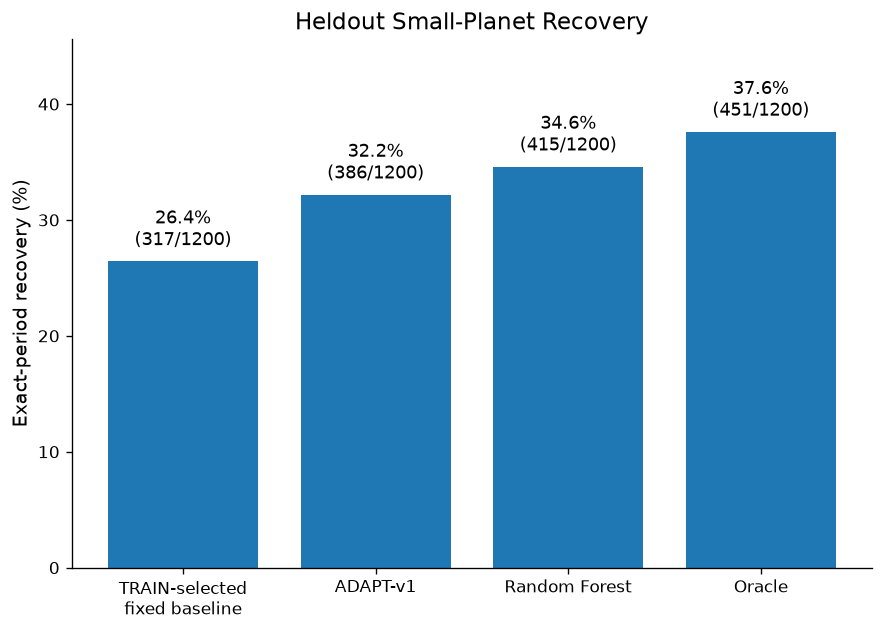

✅ Saved: figure_02_per_host_recovery


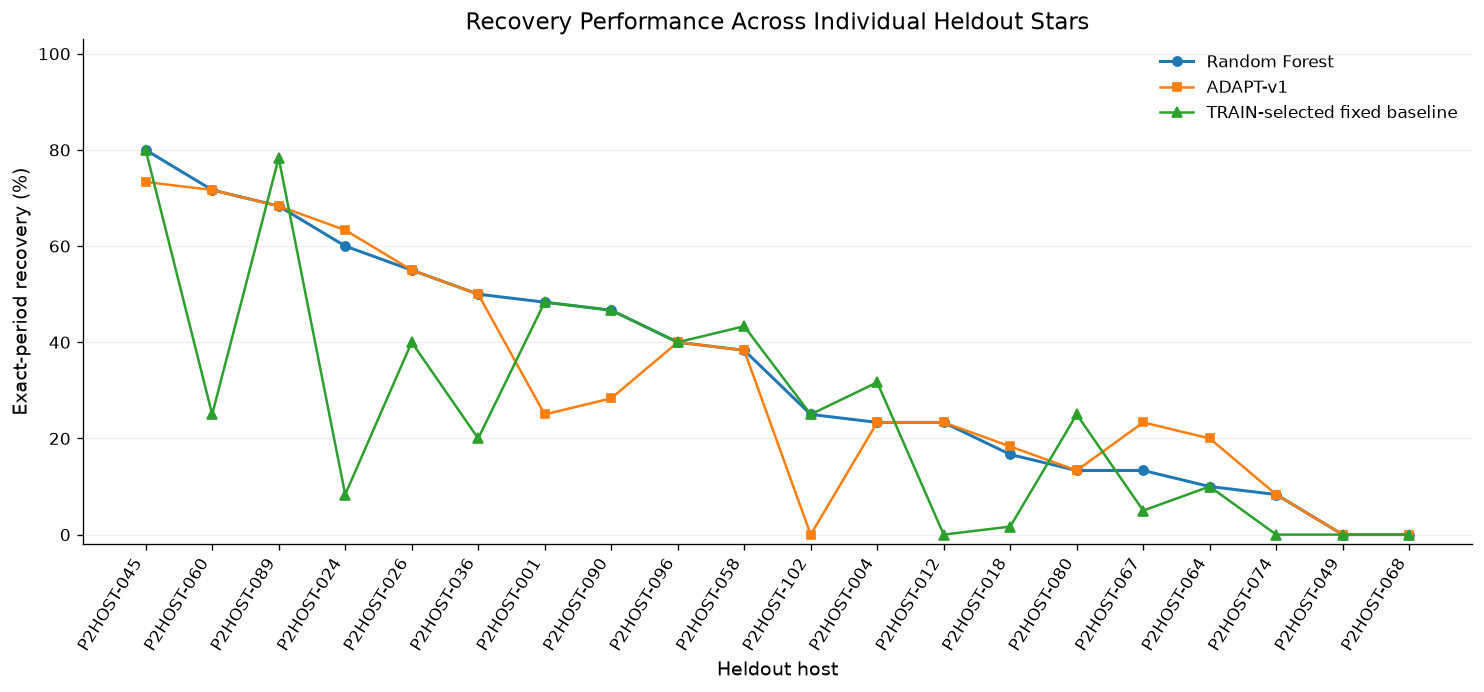

✅ Saved: figure_03_host_bootstrap


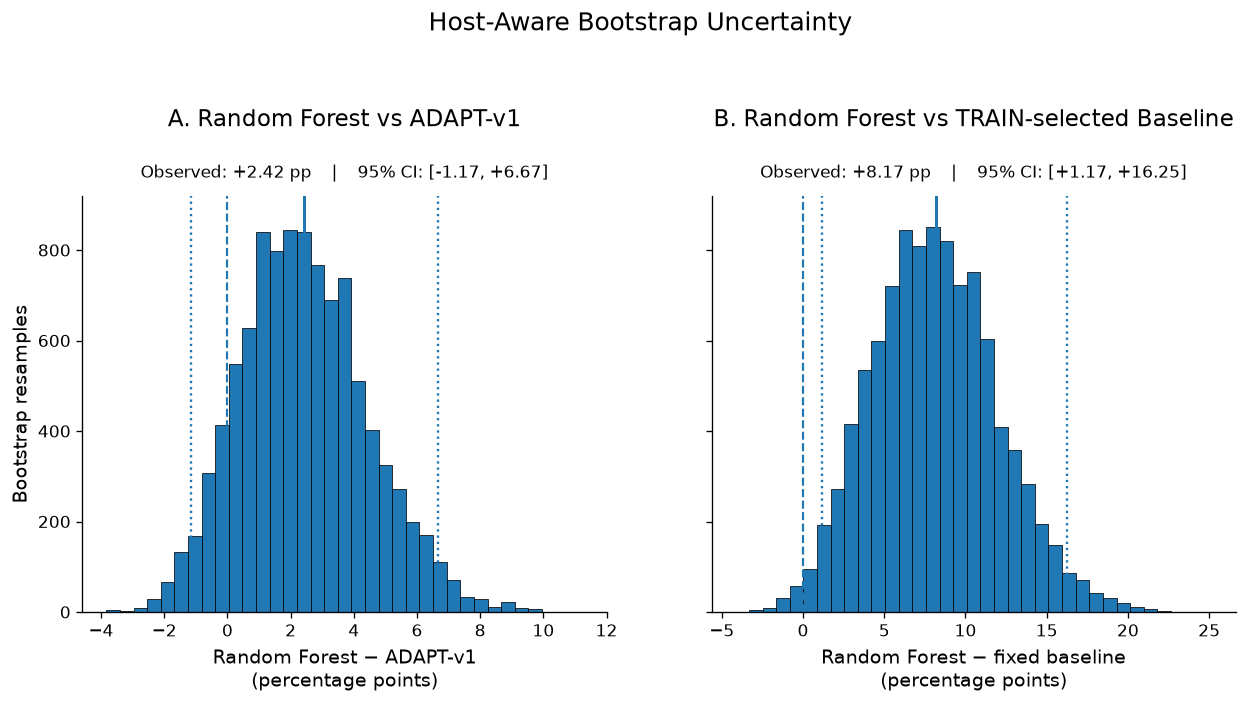

✅ Saved: figure_04_ml_vs_oracle_preprocessing


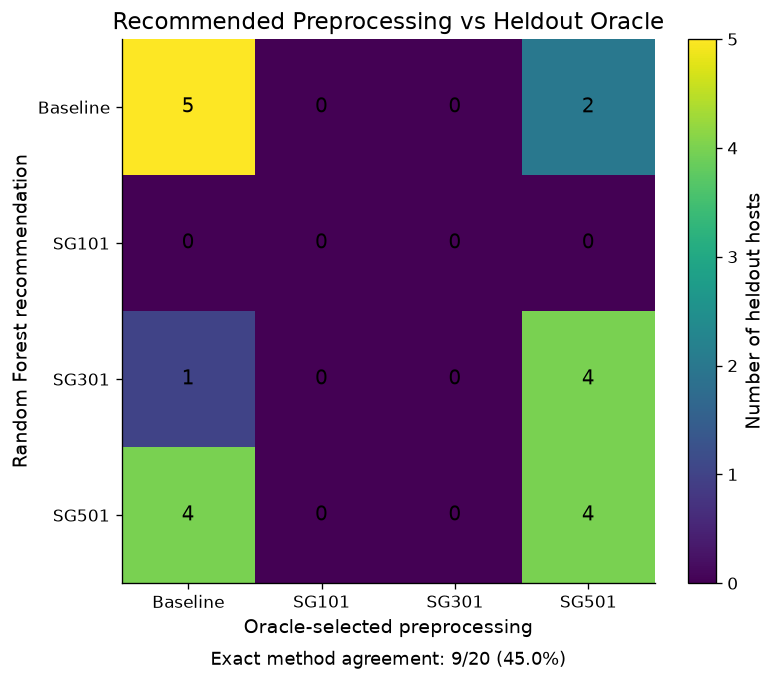


FINAL PHASE 2 FIGURES COMPLETE
Figure 1 — Heldout recovery hierarchy
Figure 2 — Host-to-host heterogeneity
Figure 3 — Host-aware bootstrap uncertainty
Figure 4 — Random Forest vs oracle preprocessing choice

ML vs oracle exact method agreement:
9/20 = 45.0%

Saved as PNG + PDF in:
c:\Users\waqar\OneDrive\Desktop\ayesha waqas project\notebooks\tess_small_planet_project\results\phase2\objective_10_final_figures


In [71]:
# ============================================================
# PHASE 2 — FINAL PUBLICATION FIGURES
# OBJECTIVE 10
#
# Produces:
#   Figure 1 — Heldout recovery comparison
#   Figure 2 — Per-host recovery
#   Figure 3 — Host-aware bootstrap uncertainty
#   Figure 4 — ML recommendation vs heldout oracle
#
# Saves:
#   300-dpi PNG
#   vector PDF
#   underlying CSV data
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. OUTPUT DIRECTORY
# ============================================================

OBJ10_RESULTS_DIR = (
    PHASE2_RESULTS_DIR
    / "objective_10_final_figures"
)

OBJ10_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Final figure directory:"
)
print(
    OBJ10_RESULTS_DIR
)


# ============================================================
# 1. GLOBAL PUBLICATION SETTINGS
# ============================================================

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def save_final_figure(
    fig,
    filename_stem,
):

    png_path = (
        OBJ10_RESULTS_DIR
        /
        f"{filename_stem}.png"
    )

    pdf_path = (
        OBJ10_RESULTS_DIR
        /
        f"{filename_stem}.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.12,
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        pad_inches=0.12,
    )

    print(
        f"✅ Saved: {filename_stem}"
    )


# ============================================================
# FIGURE 1
# HELDOUT EXACT-PERIOD RECOVERY
# ============================================================

figure1_order = [
    "TRAIN_BEST_FIXED_BASELINE",
    "ADAPT_V1",
    "ML_RANDOM_FOREST",
    "ORACLE",
]


figure1_labels = {

    "TRAIN_BEST_FIXED_BASELINE":
        "TRAIN-selected\nfixed baseline",

    "ADAPT_V1":
        "ADAPT-v1",

    "ML_RANDOM_FOREST":
        "Random Forest",

    "ORACLE":
        "Oracle",
}


figure1_df = (
    heldout_primary_comparison_df[
        heldout_primary_comparison_df[
            "policy"
        ].isin(
            figure1_order
        )
    ]
    .copy()
)


figure1_df[
    "plot_order"
] = (
    figure1_df[
        "policy"
    ].map({
        policy:
            idx
        for idx, policy
        in enumerate(
            figure1_order
        )
    })
)


figure1_df = (
    figure1_df
    .sort_values(
        "plot_order"
    )
    .reset_index(
        drop=True
    )
)


fig, ax = plt.subplots(
    figsize=(7.5, 5.4)
)


x = np.arange(
    len(
        figure1_df
    )
)


bars = ax.bar(
    x,
    figure1_df[
        "exact_recovery_fraction"
    ]
    * 100,
    width=0.78,
)


ax.set_xticks(
    x
)


ax.set_xticklabels([
    figure1_labels[
        policy
    ]
    for policy
    in figure1_df[
        "policy"
    ]
])


ax.set_ylabel(
    "Exact-period recovery (%)"
)


ax.set_title(
    "Heldout Small-Planet Recovery"
)


max_bar = float(
    (
        figure1_df[
            "exact_recovery_fraction"
        ]
        * 100
    ).max()
)


ax.set_ylim(
    0,
    max_bar + 8
)


for bar, (_, row) in zip(
    bars,
    figure1_df.iterrows(),
):

    fraction = (
        row[
            "exact_recovery_fraction"
        ]
        * 100
    )

    count = int(
        row[
            "exact_recovery_count"
        ]
    )

    ax.text(
        bar.get_x()
        +
        bar.get_width()
        / 2,

        bar.get_height()
        + 0.9,

        (
            f"{fraction:.1f}%\n"
            f"({count}/1200)"
        ),

        ha="center",
        va="bottom",
        fontsize=10.5,
    )


fig.tight_layout()


save_final_figure(
    fig,
    "figure_01_heldout_exact_recovery",
)


plt.show()


# ============================================================
# FIGURE 2
# PER-HOST RECOVERY
# ============================================================

host_plot_df = (
    per_host_policy_df
    .copy()
    .sort_values(
        "ml_exact_fraction",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


x = np.arange(
    len(
        host_plot_df
    )
)


fig, ax = plt.subplots(
    figsize=(12.5, 5.9)
)


ax.plot(
    x,
    host_plot_df[
        "ml_exact_fraction"
    ]
    * 100,
    marker="o",
    markersize=5.5,
    linewidth=1.8,
    label="Random Forest",
)


ax.plot(
    x,
    host_plot_df[
        "adapt_exact_fraction"
    ]
    * 100,
    marker="s",
    markersize=5,
    linewidth=1.5,
    label="ADAPT-v1",
)


ax.plot(
    x,
    host_plot_df[
        "best_fixed_exact_fraction"
    ]
    * 100,
    marker="^",
    markersize=5.5,
    linewidth=1.5,
    label="TRAIN-selected fixed baseline",
)


ax.set_xticks(
    x
)


ax.set_xticklabels(
    host_plot_df[
        "phase2_host_id"
    ],
    rotation=58,
    ha="right",
)


ax.set_ylabel(
    "Exact-period recovery (%)"
)


ax.set_xlabel(
    "Heldout host"
)


ax.set_title(
    "Recovery Performance Across Individual Heldout Stars"
)


ax.set_ylim(
    -2,
    103,
)


ax.legend(
    frameon=False,
    loc="upper right",
)


ax.grid(
    axis="y",
    alpha=0.18,
)


fig.tight_layout()


save_final_figure(
    fig,
    "figure_02_per_host_recovery",
)


plt.show()


# ============================================================
# FIGURE 3
# HOST-AWARE BOOTSTRAP UNCERTAINTY
#
# Cleaner version:
#   - summary text sits ABOVE histograms
#   - no text over bars
#   - observed / CI lines clearly separated
# ============================================================

values_adapt = (
    bootstrap_df[
        "ml_minus_adapt"
    ]
    * 100
)


values_fixed = (
    bootstrap_df[
        "ml_minus_best_fixed"
    ]
    * 100
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.4, 5.5),
    sharey=True,
)


# ------------------------------------------------------------
# Panel A
# Random Forest minus ADAPT-v1
# ------------------------------------------------------------

counts_a, _, _ = axes[0].hist(
    values_adapt,
    bins=35,
    edgecolor="black",
    linewidth=0.45,
)


axes[0].axvline(
    0,
    linestyle="--",
    linewidth=1.3,
    label="No difference",
)


axes[0].axvline(
    ML_MINUS_ADAPT
    * 100,
    linewidth=1.8,
    label="Observed",
)


axes[0].axvline(
    ML_ADAPT_CI[0]
    * 100,
    linestyle=":",
    linewidth=1.4,
)


axes[0].axvline(
    ML_ADAPT_CI[1]
    * 100,
    linestyle=":",
    linewidth=1.4,
)


axes[0].set_xlabel(
    "Random Forest − ADAPT-v1\n"
    "(percentage points)"
)


axes[0].set_ylabel(
    "Bootstrap resamples"
)


axes[0].set_title(
    "A. Random Forest vs ADAPT-v1",
    pad=42,
)


# annotation ABOVE plotting region
axes[0].text(
    0.5,
    1.035,
    (
        f"Observed: "
        f"{ML_MINUS_ADAPT * 100:+.2f} pp    |    "
        f"95% CI: "
        f"[{ML_ADAPT_CI[0] * 100:+.2f}, "
        f"{ML_ADAPT_CI[1] * 100:+.2f}]"
    ),
    transform=axes[0].transAxes,
    ha="center",
    va="bottom",
    fontsize=10.2,
)


axes[0].set_ylim(
    0,
    max(
        counts_a.max(),
        1,
    )
    * 1.08
)


# ------------------------------------------------------------
# Panel B
# Random Forest minus TRAIN-selected fixed baseline
# ------------------------------------------------------------

counts_b, _, _ = axes[1].hist(
    values_fixed,
    bins=35,
    edgecolor="black",
    linewidth=0.45,
)


axes[1].axvline(
    0,
    linestyle="--",
    linewidth=1.3,
    label="No difference",
)


axes[1].axvline(
    ML_MINUS_BEST_FIXED
    * 100,
    linewidth=1.8,
    label="Observed",
)


axes[1].axvline(
    ML_FIXED_CI[0]
    * 100,
    linestyle=":",
    linewidth=1.4,
)


axes[1].axvline(
    ML_FIXED_CI[1]
    * 100,
    linestyle=":",
    linewidth=1.4,
)


axes[1].set_xlabel(
    "Random Forest − fixed baseline\n"
    "(percentage points)"
)


axes[1].set_title(
    "B. Random Forest vs TRAIN-selected Baseline",
    pad=42,
)


axes[1].text(
    0.5,
    1.035,
    (
        f"Observed: "
        f"{ML_MINUS_BEST_FIXED * 100:+.2f} pp    |    "
        f"95% CI: "
        f"[{ML_FIXED_CI[0] * 100:+.2f}, "
        f"{ML_FIXED_CI[1] * 100:+.2f}]"
    ),
    transform=axes[1].transAxes,
    ha="center",
    va="bottom",
    fontsize=10.2,
)


axes[1].set_ylim(
    0,
    max(
        counts_b.max(),
        1,
    )
    * 1.08
)


fig.suptitle(
    "Host-Aware Bootstrap Uncertainty",
    fontsize=15,
    y=1.08,
)


fig.subplots_adjust(
    top=0.80,
    bottom=0.17,
    wspace=0.20,
)


save_final_figure(
    fig,
    "figure_03_host_bootstrap",
)


plt.show()


# ============================================================
# FIGURE 4
# RANDOM FOREST RECOMMENDATIONS VS HELDOUT ORACLE
# ============================================================

method_order = [
    "BASELINE",
    "SG_101",
    "SG_301",
    "SG_501",
]


method_labels = [
    "Baseline",
    "SG101",
    "SG301",
    "SG501",
]


ml_vs_oracle_df = pd.DataFrame({
    "phase2_host_id":
        list(
            ml_method_map.keys()
        ),

    "ml_method":
        list(
            ml_method_map.values()
        ),
})


oracle_methods_df = pd.DataFrame({
    "phase2_host_id":
        list(
            oracle_method_map.keys()
        ),

    "oracle_method":
        list(
            oracle_method_map.values()
        ),
})


ml_vs_oracle_df = (
    ml_vs_oracle_df
    .merge(
        oracle_methods_df,
        on="phase2_host_id",
        how="inner",
        validate="one_to_one",
    )
)


agreement_matrix = pd.crosstab(
    pd.Categorical(
        ml_vs_oracle_df[
            "ml_method"
        ],
        categories=method_order,
    ),

    pd.Categorical(
        ml_vs_oracle_df[
            "oracle_method"
        ],
        categories=method_order,
    ),

    dropna=False,
)


agreement_array = (
    agreement_matrix
    .to_numpy()
)


exact_method_agreement = int(
    (
        ml_vs_oracle_df[
            "ml_method"
        ]
        ==
        ml_vs_oracle_df[
            "oracle_method"
        ]
    ).sum()
)


agreement_fraction = (
    exact_method_agreement
    /
    len(
        ml_vs_oracle_df
    )
)


fig, ax = plt.subplots(
    figsize=(6.8, 5.8)
)


image = ax.imshow(
    agreement_array,
    aspect="auto",
)


ax.set_xticks(
    np.arange(
        len(
            method_labels
        )
    )
)


ax.set_yticks(
    np.arange(
        len(
            method_labels
        )
    )
)


ax.set_xticklabels(
    method_labels
)


ax.set_yticklabels(
    method_labels
)


ax.set_xlabel(
    "Oracle-selected preprocessing"
)


ax.set_ylabel(
    "Random Forest recommendation"
)


ax.set_title(
    "Recommended Preprocessing vs Heldout Oracle"
)


for i in range(
    agreement_array.shape[0]
):

    for j in range(
        agreement_array.shape[1]
    ):

        value = int(
            agreement_array[
                i,
                j
            ]
        )

        ax.text(
            j,
            i,
            str(value),
            ha="center",
            va="center",
            fontsize=12,
        )


fig.colorbar(
    image,
    ax=ax,
    label="Number of heldout hosts",
)


ax.text(
    0.5,
    -0.15,
    (
        f"Exact method agreement: "
        f"{exact_method_agreement}/"
        f"{len(ml_vs_oracle_df)} "
        f"({agreement_fraction * 100:.1f}%)"
    ),
    transform=ax.transAxes,
    ha="center",
    fontsize=10.5,
)


fig.tight_layout()


save_final_figure(
    fig,
    "figure_04_ml_vs_oracle_preprocessing",
)


plt.show()


# ============================================================
# 5. SAVE FIGURE DATA
# ============================================================

figure1_df.to_csv(
    OBJ10_RESULTS_DIR
    /
    "figure_01_data.csv",
    index=False,
)


host_plot_df.to_csv(
    OBJ10_RESULTS_DIR
    /
    "figure_02_data.csv",
    index=False,
)


bootstrap_df[
    [
        "bootstrap",
        "ml_minus_adapt",
        "ml_minus_best_fixed",
    ]
].to_csv(
    OBJ10_RESULTS_DIR
    /
    "figure_03_data.csv",
    index=False,
)


ml_vs_oracle_df.to_csv(
    OBJ10_RESULTS_DIR
    /
    "figure_04_data.csv",
    index=False,
)


agreement_matrix.to_csv(
    OBJ10_RESULTS_DIR
    /
    "figure_04_agreement_matrix.csv",
)


# ============================================================
# 6. FIGURE SUMMARY
# ============================================================

print()
print("=" * 80)
print(
    "FINAL PHASE 2 FIGURES COMPLETE"
)
print("=" * 80)

print(
    "Figure 1 — Heldout recovery hierarchy"
)

print(
    "Figure 2 — Host-to-host heterogeneity"
)

print(
    "Figure 3 — Host-aware bootstrap uncertainty"
)

print(
    "Figure 4 — Random Forest vs oracle preprocessing choice"
)

print()

print(
    "ML vs oracle exact method agreement:"
)

print(
    f"{exact_method_agreement}/"
    f"{len(ml_vs_oracle_df)} "
    f"= {agreement_fraction * 100:.1f}%"
)

print()

print(
    "Saved as PNG + PDF in:"
)

print(
    OBJ10_RESULTS_DIR
)

print("=" * 80)